In [4]:
%%writefile configs/cities.yaml

study_area_radius_m: 2500

cities:
  - name: Heidelberg
    country: Germany
    continent: Europe
    lon: 8.6724
    lat: 49.3988
    split: test

  - name: Berlin
    country: Germany
    continent: Europe
    lon: 13.4050
    lat: 52.5200
    split: train

  - name: Munich
    country: Germany
    continent: Europe
    lon: 11.5820
    lat: 48.1351
    split: train

  - name: Hamburg
    country: Germany
    continent: Europe
    lon: 9.9937
    lat: 53.5511
    split: train

  - name: Freiburg
    country: Germany
    continent: Europe
    lon: 7.8421
    lat: 47.9990
    split: val

  - name: Bengaluru
    country: India
    continent: Asia
    lon: 77.5946
    lat: 12.9716
    split: train

  - name: Singapore
    country: Singapore
    continent: Asia
    lon: 103.8198
    lat: 1.3521
    split: val

  - name: Nairobi
    country: Kenya
    continent: Africa
    lon: 36.8219
    lat: -1.2921
    split: test

  - name: Cairo
    country: Egypt
    continent: Africa
    lon: 31.2357
    lat: 30.0444
    split: train

  - name: New York
    country: USA
    continent: North America
    lon: -74.0060
    lat: 40.7128
    split: train

  - name: Sao Paulo
    country: Brazil
    continent: South America
    lon: -46.6333
    lat: -23.5505
    split: train

  - name: Sydney
    country: Australia
    continent: Oceania
    lon: 151.2093
    lat: -33.8688
    split: test

Overwriting configs/cities.yaml


In [5]:
import yaml

with open("configs/cities.yaml") as f:
    config = yaml.safe_load(f)

for city in config["cities"]:
    print(
        city["name"],
        "|", city["continent"],
        "|", city["split"]
    )

print("\nTotal cities:", len(config["cities"]))

Heidelberg | Europe | test
Berlin | Europe | train
Munich | Europe | train
Hamburg | Europe | train
Freiburg | Europe | val
Bengaluru | Asia | train
Singapore | Asia | val
Nairobi | Africa | test
Cairo | Africa | train
New York | North America | train
Sao Paulo | South America | train
Sydney | Oceania | test

Total cities: 12


In [6]:
from pathlib import Path

root = Path.cwd()

print("PROJECT ROOT:", root)

for folder in ["configs", "src", "data", "models", "outputs", "notebooks"]:
    path = root / folder

    print(f"\n{folder}/")

    if path.exists():
        for item in sorted(path.iterdir()):
            print("  ", item.name, "/" if item.is_dir() else "")
    else:
        print("   NOT FOUND")

PROJECT ROOT: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb

configs/
   .ipynb_checkpoints /
   cities.yaml 
   classes.yaml 
   project.yaml 

src/
   data /
   evaluation /
   inference /
   models /
   visualization /

data/
   labels /
   processed /
   raw /

models/
   fcn8s_best.pt 
   unet_best.pt 

outputs/
   data_audit /
   evaluation /
   independent_validation /
   monthly_maps /
   pilot_inference /
   statistics /
   visualizations /

notebooks/


In [7]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [8]:
import rasterio
import numpy as np

files = [
    "src/data/data/raw/sentinel1/heidelberg_2025_01.tif",
    "data/raw/Heidelberg_2025_01_UTM32.tif"
]

for filename in files:
    print("\n", filename)

    with rasterio.open(filename) as src:
        for band, name in [(1, "VV"), (2, "VH")]:
            data = src.read(band)
            valid = data[np.isfinite(data)]

            print(
                name,
                "Min:", round(float(valid.min()), 2),
                "Max:", round(float(valid.max()), 2),
                "Mean:", round(float(valid.mean()), 2),
                "Std:", round(float(valid.std()), 2)
            )


 src/data/data/raw/sentinel1/heidelberg_2025_01.tif
VV Min: -23.76 Max: 18.71 Mean: -7.23 Std: 3.83
VH Min: -36.96 Max: 10.97 Mean: -14.97 Std: 3.43

 data/raw/Heidelberg_2025_01_UTM32.tif
VV Min: -23.76 Max: 18.71 Mean: -7.23 Std: 3.84
VH Min: -39.05 Max: 10.54 Mean: -14.97 Std: 3.44


In [9]:
import rasterio
import numpy as np

files = [
    "src/data/data/raw/sentinel1/heidelberg_2025_01.tif",
    "data/raw/Heidelberg_2025_01_UTM32.tif"
]

for filename in files:
    print("\nFILE:", filename)

    with rasterio.open(filename) as src:
        print("CRS:", src.crs)
        print("Shape:", src.height, "x", src.width)
        print("Bounds:", src.bounds)
        print("NoData:", src.nodata)
        print("Transform:", src.transform)

        for band, name in [(1, "VV"), (2, "VH")]:
            data = src.read(band).astype("float32")
            valid = data[np.isfinite(data)]

            if src.nodata is not None:
                valid = valid[valid != src.nodata]

            print(f"\n{name} percentiles:")
            print(np.percentile(valid, [0, 1, 5, 25, 50, 75, 95, 99, 100]))


FILE: src/data/data/raw/sentinel1/heidelberg_2025_01.tif
CRS: EPSG:4326
Shape: 502 x 765
Bounds: BoundingBox(left=8.638109940564906, bottom=49.376258917743144, right=8.706831059800049, top=49.421354345005945)
NoData: -inf
Transform: | 0.00, 0.00, 8.64|
| 0.00,-0.00, 49.42|
| 0.00, 0.00, 1.00|

VV percentiles:
[-23.75885391 -18.17580032 -12.24963384  -9.42210364  -7.72983646
  -5.31035769  -0.40892548   4.11455545  18.7084713 ]

VH percentiles:
[-36.96103287 -25.27696346 -20.00142193 -16.74932528 -15.02171612
 -13.33778954  -9.31892962  -4.81963983  10.96930504]

FILE: data/raw/Heidelberg_2025_01_UTM32.tif
CRS: EPSG:32632
Shape: 503 x 501
Bounds: BoundingBox(left=473730.0, bottom=5469330.0, right=478740.0, top=5474360.0)
NoData: -inf
Transform: | 10.00, 0.00, 473730.00|
| 0.00,-10.00, 5474360.00|
| 0.00, 0.00, 1.00|

VV percentiles:
[-23.75828362 -18.18438122 -12.27410345  -9.42426538  -7.73531008
  -5.31388903  -0.41391323   4.19611088  18.7084713 ]

VH percentiles:
[-39.0479126  -25.

In [10]:
import rasterio
import numpy as np

filename = "data/raw/Heidelberg_2025_01_UTM32.tif"

with rasterio.open(filename) as src:
    for band, name in [(1, "VV"), (2, "VH")]:
        data = src.read(band).astype("float32")
        valid = data[np.isfinite(data) & (data != src.nodata)]

        print(f"\n{name}")
        print("Total pixels:", valid.size)
        print("Pixels above 0 dB:", np.sum(valid > 0))
        print("Pixels above 5 dB:", np.sum(valid > 5))
        print("Pixels above 10 dB:", np.sum(valid > 10))
        print("Percentage above 0 dB:", round(100 * np.mean(valid > 0), 3), "%")


VV
Total pixels: 250155
Pixels above 0 dB: 10858
Pixels above 5 dB: 1891
Pixels above 10 dB: 278
Percentage above 0 dB: 4.341 %

VH
Total pixels: 250155
Pixels above 0 dB: 405
Pixels above 5 dB: 61
Pixels above 10 dB: 2
Percentage above 0 dB: 0.162 %


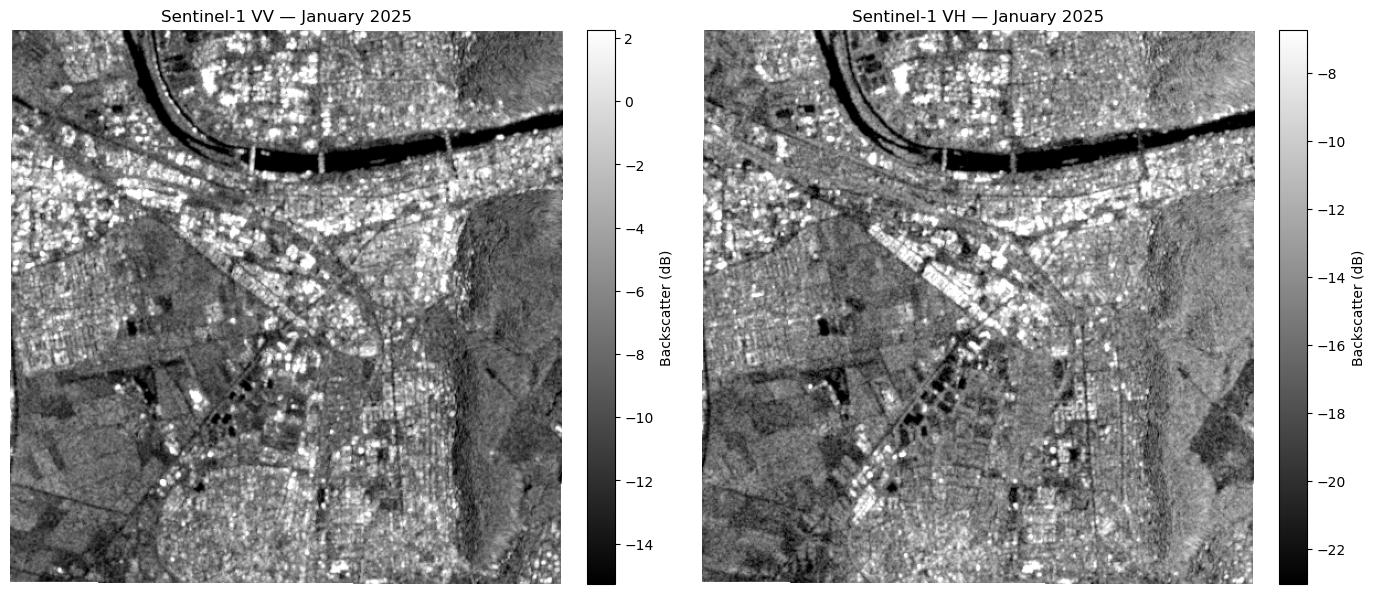

In [11]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

filename = "data/raw/Heidelberg_2025_01_UTM32.tif"

with rasterio.open(filename) as src:
    vv = src.read(1).astype("float32")
    vh = src.read(2).astype("float32")

    vv[~np.isfinite(vv)] = np.nan
    vh[~np.isfinite(vh)] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, data, title in zip(
    axes,
    [vv, vh],
    ["Sentinel-1 VV — January 2025", "Sentinel-1 VH — January 2025"]
):
    image = ax.imshow(
        data,
        cmap="gray",
        vmin=np.nanpercentile(data, 2),
        vmax=np.nanpercentile(data, 98)
    )
    ax.set_title(title)
    ax.axis("off")
    plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Backscatter (dB)")

plt.tight_layout()
plt.show()

In [12]:
from pathlib import Path
import rasterio
import numpy as np

folder = Path("src/data/data/raw/sentinel1")

files = sorted(folder.glob("heidelberg_2025_*.tif"))

print("Files found:", len(files))

for file in files:
    with rasterio.open(file) as src:
        vv = src.read(1)
        vh = src.read(2)

        print(
            file.name,
            "| Shape:", src.shape,
            "| CRS:", src.crs,
            "| VV mean:", round(float(np.nanmean(vv)), 2),
            "| VH mean:", round(float(np.nanmean(vh)), 2)
        )

Files found: 12
heidelberg_2025_01.tif | Shape: (502, 765) | CRS: EPSG:4326 | VV mean: -7.23 | VH mean: -14.97
heidelberg_2025_02.tif | Shape: (502, 765) | CRS: EPSG:4326 | VV mean: -7.7 | VH mean: -15.41
heidelberg_2025_03.tif | Shape: (502, 765) | CRS: EPSG:4326 | VV mean: -7.72 | VH mean: -15.28
heidelberg_2025_04.tif | Shape: (502, 765) | CRS: EPSG:4326 | VV mean: -8.08 | VH mean: -15.46
heidelberg_2025_05.tif | Shape: (502, 765) | CRS: EPSG:4326 | VV mean: -8.34 | VH mean: -15.84
heidelberg_2025_06.tif | Shape: (502, 765) | CRS: EPSG:4326 | VV mean: -7.73 | VH mean: -15.07
heidelberg_2025_07.tif | Shape: (502, 765) | CRS: EPSG:4326 | VV mean: -7.86 | VH mean: -15.48
heidelberg_2025_08.tif | Shape: (502, 765) | CRS: EPSG:4326 | VV mean: -7.88 | VH mean: -15.58
heidelberg_2025_09.tif | Shape: (502, 765) | CRS: EPSG:4326 | VV mean: -7.6 | VH mean: -15.55
heidelberg_2025_10.tif | Shape: (502, 765) | CRS: EPSG:4326 | VV mean: -7.68 | VH mean: -15.53
heidelberg_2025_11.tif | Shape: (502

In [13]:
from pathlib import Path
import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling

# Input and output folders
input_folder = Path("src/data/data/raw/sentinel1")
output_folder = Path("data/processed/sentinel1/Heidelberg")
output_folder.mkdir(parents=True, exist_ok=True)

# Reference: Heidelberg January UTM32
reference_file = Path("data/raw/Heidelberg_2025_01_UTM32.tif")

if not reference_file.exists():
    raise FileNotFoundError(f"Reference file not found: {reference_file}")

# Read reference grid
with rasterio.open(reference_file) as ref:
    target_crs = ref.crs
    target_transform = ref.transform
    target_width = ref.width
    target_height = ref.height
    target_profile = ref.profile.copy()

print("Target CRS:", target_crs)
print("Target shape:", (target_height, target_width))

# Reproject each monthly image
files = sorted(input_folder.glob("heidelberg_2025_*.tif"))

if len(files) != 12:
    raise ValueError(f"Expected 12 monthly files, found {len(files)}")

for file in files:
    output_file = output_folder / file.name

    with rasterio.open(file) as src:
        destination = np.full(
            (2, target_height, target_width),
            np.nan,
            dtype=np.float32
        )

        for band in range(1, 3):
            reproject(
                source=rasterio.band(src, band),
                destination=destination[band - 1],
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=src.nodata,
                dst_transform=target_transform,
                dst_crs=target_crs,
                dst_nodata=np.nan,
                resampling=Resampling.bilinear
            )

    output_profile = target_profile.copy()
    output_profile.update(
        count=2,
        dtype="float32",
        nodata=np.nan,
        compress="deflate"
    )

    with rasterio.open(output_file, "w", **output_profile) as dst:
        dst.write(destination)

    print("Saved:", output_file)

print("\nReprojection completed.")
print("Total files:", len(list(output_folder.glob("*.tif"))))

Target CRS: EPSG:32632
Target shape: (503, 501)
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_01.tif
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_02.tif
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_03.tif
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_04.tif
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_05.tif
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_06.tif
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_07.tif
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_08.tif
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_09.tif
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_10.tif
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_11.tif
Saved: data/processed/sentinel1/Heidelberg/heidelberg_2025_12.tif

Reprojection completed.
Total files: 12


In [14]:
for file in sorted(output_folder.glob("*.tif")):
    with rasterio.open(file) as src:
        vv = src.read(1)
        vh = src.read(2)

        print(
            file.name,
            "| Shape:", src.shape,
            "| CRS:", src.crs,
            "| Resolution:", src.res,
            "| VV mean:", round(float(np.nanmean(vv)), 2),
            "| VH mean:", round(float(np.nanmean(vh)), 2)
        )

heidelberg_2025_01.tif | Shape: (503, 501) | CRS: EPSG:32632 | Resolution: (10.0, 10.0) | VV mean: -7.23 | VH mean: -14.97
heidelberg_2025_02.tif | Shape: (503, 501) | CRS: EPSG:32632 | Resolution: (10.0, 10.0) | VV mean: -7.7 | VH mean: -15.41
heidelberg_2025_03.tif | Shape: (503, 501) | CRS: EPSG:32632 | Resolution: (10.0, 10.0) | VV mean: -7.72 | VH mean: -15.28
heidelberg_2025_04.tif | Shape: (503, 501) | CRS: EPSG:32632 | Resolution: (10.0, 10.0) | VV mean: -8.09 | VH mean: -15.46
heidelberg_2025_05.tif | Shape: (503, 501) | CRS: EPSG:32632 | Resolution: (10.0, 10.0) | VV mean: -8.35 | VH mean: -15.84
heidelberg_2025_06.tif | Shape: (503, 501) | CRS: EPSG:32632 | Resolution: (10.0, 10.0) | VV mean: -7.73 | VH mean: -15.07
heidelberg_2025_07.tif | Shape: (503, 501) | CRS: EPSG:32632 | Resolution: (10.0, 10.0) | VV mean: -7.86 | VH mean: -15.48
heidelberg_2025_08.tif | Shape: (503, 501) | CRS: EPSG:32632 | Resolution: (10.0, 10.0) | VV mean: -7.88 | VH mean: -15.58
heidelberg_2025_0

In [15]:
from pathlib import Path
import rasterio
import numpy as np

output_folder = Path("data/processed/sentinel1/Heidelberg")
files = sorted(output_folder.glob("*.tif"))

print("Total files:", len(files))

for file in files:
    with rasterio.open(file) as src:
        vv = src.read(1)
        vh = src.read(2)

        print(
            f"\n{file.name}"
            f"\n  Shape: {src.shape}"
            f"\n  CRS: {src.crs}"
            f"\n  Resolution: {src.res}"
            f"\n  VV mean: {np.nanmean(vv):.2f}"
            f"\n  VH mean: {np.nanmean(vh):.2f}"
            f"\n  Valid pixels: {np.count_nonzero(np.isfinite(vv))}"
        )

Total files: 12

heidelberg_2025_01.tif
  Shape: (503, 501)
  CRS: EPSG:32632
  Resolution: (10.0, 10.0)
  VV mean: -7.23
  VH mean: -14.97
  Valid pixels: 250005

heidelberg_2025_02.tif
  Shape: (503, 501)
  CRS: EPSG:32632
  Resolution: (10.0, 10.0)
  VV mean: -7.70
  VH mean: -15.41
  Valid pixels: 250005

heidelberg_2025_03.tif
  Shape: (503, 501)
  CRS: EPSG:32632
  Resolution: (10.0, 10.0)
  VV mean: -7.72
  VH mean: -15.28
  Valid pixels: 250005

heidelberg_2025_04.tif
  Shape: (503, 501)
  CRS: EPSG:32632
  Resolution: (10.0, 10.0)
  VV mean: -8.09
  VH mean: -15.46
  Valid pixels: 250005

heidelberg_2025_05.tif
  Shape: (503, 501)
  CRS: EPSG:32632
  Resolution: (10.0, 10.0)
  VV mean: -8.35
  VH mean: -15.84
  Valid pixels: 250005

heidelberg_2025_06.tif
  Shape: (503, 501)
  CRS: EPSG:32632
  Resolution: (10.0, 10.0)
  VV mean: -7.73
  VH mean: -15.07
  Valid pixels: 250005

heidelberg_2025_07.tif
  Shape: (503, 501)
  CRS: EPSG:32632
  Resolution: (10.0, 10.0)
  VV mean: -7

In [16]:
%pip install -q earthengine-api rasterio

Note: you may need to restart the kernel to use updated packages.


In [19]:
import ee

ee.Authenticate(auth_mode="notebook")

Enter verification code:  4/1AUn6Hd-w80pOqltowIGf9nO4ytRsWQuXeWuJFyOBQOxOb1e36BqSQPINjqc



Successfully saved authorization token.


In [20]:
import ee

EE_PROJECT = "lulc-sentinel1-project-512811"

try:
    ee.Initialize(project=EE_PROJECT)

    print("Earth Engine initialised successfully!")

    # Test an actual Earth Engine request
    test = (
        ee.ImageCollection("ESA/WorldCover/v200")
        .size()
        .getInfo()
    )

    print("WorldCover collection accessible.")
    print("Number of images:", test)

except Exception as e:
    print("Earth Engine connection failed:")
    print(type(e).__name__, str(e))

Earth Engine initialised successfully!
WorldCover collection accessible.
Number of images: 1


In [21]:
import ee
import rasterio
import numpy as np
import requests
import zipfile
import io

from pathlib import Path

# Paths
reference_file = Path(
    "data/processed/sentinel1/Heidelberg/heidelberg_2025_01.tif"
)

output_folder = Path("data/labels")
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "Heidelberg_WorldCover_2021.tif"

# Read Sentinel-1 reference grid
with rasterio.open(reference_file) as src:
    crs = src.crs
    transform = src.transform
    width = src.width
    height = src.height

# Load WorldCover
worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
)

# Map to six classes
labels = worldcover.remap(
    [10, 30, 40, 50, 60, 80],
    [0, 1, 2, 3, 4, 5],
    255
).rename("label").toByte()

# Correct download parameters
url = labels.getDownloadURL({
    "name": "Heidelberg_WorldCover",
    "crs": crs.to_string(),
    "crs_transform": [
        transform.a, transform.b, transform.c,
        transform.d, transform.e, transform.f
    ],
    "dimensions": f"{width}x{height}",
    "format": "GEO_TIFF"
})

# Download
response = requests.get(url, timeout=180)
response.raise_for_status()

# Save TIFF
if response.content[:2] == b"PK":
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        tif_name = next(
            n for n in archive.namelist()
            if n.lower().endswith((".tif", ".tiff"))
        )
        output_file.write_bytes(archive.read(tif_name))
else:
    output_file.write_bytes(response.content)

print("WorldCover downloaded:", output_file)

WorldCover downloaded: data/labels/Heidelberg_WorldCover_2021.tif


In [22]:
with rasterio.open(output_file) as src:
    y = src.read(1)

print("Shape:", y.shape)
print("CRS:", src.crs)

class_names = {
    0: "Tree cover",
    1: "Grassland",
    2: "Cropland",
    3: "Built-up",
    4: "Bare/sparse vegetation",
    5: "Permanent water",
    255: "Ignored"
}

values, counts = np.unique(y, return_counts=True)

for value, count in zip(values, counts):
    print(
        f"{class_names.get(int(value), 'Unknown')}: "
        f"{count:,} pixels ({count / y.size * 100:.2f}%)"
    )

Shape: (503, 501)
CRS: EPSG:32632
Tree cover: 78,772 pixels (31.26%)
Grassland: 25,249 pixels (10.02%)
Cropland: 29,768 pixels (11.81%)
Built-up: 110,962 pixels (44.03%)
Bare/sparse vegetation: 397 pixels (0.16%)
Permanent water: 6,855 pixels (2.72%)


In [23]:
import rasterio
import numpy as np

sar_file = "data/processed/sentinel1/Heidelberg/heidelberg_2025_01.tif"
label_file = "data/labels/Heidelberg_WorldCover_2021.tif"

with rasterio.open(sar_file) as sar, rasterio.open(label_file) as label:

    print("SAR shape:", sar.shape)
    print("Label shape:", label.shape)

    print("\nSAR CRS:", sar.crs)
    print("Label CRS:", label.crs)

    print("\nSAR transform:", sar.transform)
    print("Label transform:", label.transform)

    print("\nSame CRS:", sar.crs == label.crs)
    print("Same dimensions:", sar.shape == label.shape)
    print("Same transform:", sar.transform == label.transform)

    sar_valid = np.isfinite(sar.read(1)) & np.isfinite(sar.read(2))
    label_valid = label.read(1) != 255

    print("\nValid SAR pixels:", sar_valid.sum())
    print("Valid label pixels:", label_valid.sum())
    print("Pixels valid in both:", (sar_valid & label_valid).sum())

SAR shape: (503, 501)
Label shape: (503, 501)

SAR CRS: EPSG:32632
Label CRS: EPSG:32632

SAR transform: | 10.00, 0.00, 473730.00|
| 0.00,-10.00, 5474360.00|
| 0.00, 0.00, 1.00|
Label transform: | 10.00, 0.00, 473730.00|
| 0.00,-10.00, 5474360.00|
| 0.00, 0.00, 1.00|

Same CRS: True
Same dimensions: True
Same transform: True

Valid SAR pixels: 250005
Valid label pixels: 252003
Pixels valid in both: 250005


In [24]:
from pathlib import Path
import rasterio
import numpy as np
from collections import Counter

SAR_FOLDER = Path("data/processed/sentinel1/Heidelberg")
LABEL_FILE = Path("data/labels/Heidelberg_WorldCover_2021.tif")

PATCH_SIZE = 64
STRIDE = 64

output_folder = Path("data/processed/patches/Heidelberg")
output_folder.mkdir(parents=True, exist_ok=True)

X_patches = []
y_patches = []

# Read January SAR and labels
with rasterio.open(SAR_FOLDER / "heidelberg_2025_01.tif") as src:
    sar = src.read().astype(np.float32)

with rasterio.open(LABEL_FILE) as src:
    labels = src.read(1)

# Valid SAR pixels
valid_sar = np.all(np.isfinite(sar), axis=0)

# Extract patches
rows, cols = labels.shape

for row in range(0, rows - PATCH_SIZE + 1, STRIDE):
    for col in range(0, cols - PATCH_SIZE + 1, STRIDE):

        x_patch = sar[:, row:row+PATCH_SIZE, col:col+PATCH_SIZE]
        y_patch = labels[row:row+PATCH_SIZE, col:col+PATCH_SIZE]

        valid = valid_sar[
            row:row+PATCH_SIZE,
            col:col+PATCH_SIZE
        ]

        # Reject patches with insufficient valid SAR pixels
        if valid.mean() < 0.95:
            continue

        # Reject patches with too few labelled pixels
        if np.mean(y_patch != 255) < 0.50:
            continue

        X_patches.append(np.moveaxis(x_patch, 0, -1))
        y_patches.append(y_patch)

X_patches = np.asarray(X_patches, dtype=np.float32)
y_patches = np.asarray(y_patches, dtype=np.uint8)

print("Input patches:", X_patches.shape)
print("Label patches:", y_patches.shape)

# Class distribution in extracted patches
class_counts = Counter(y_patches.ravel())

print("\nPatch class distribution:")

for class_id, count in sorted(class_counts.items()):
    print(f"Class {class_id}: {count:,} pixels")

# Save patches
np.save(output_folder / "X_january.npy", X_patches)
np.save(output_folder / "y_january.npy", y_patches)

print("\nSaved patches to:", output_folder)

Input patches: (49, 64, 64, 2)
Label patches: (49, 64, 64)

Patch class distribution:
Class 0: 54,067 pixels
Class 1: 20,034 pixels
Class 2: 25,194 pixels
Class 3: 94,924 pixels
Class 4: 385 pixels
Class 5: 6,100 pixels

Saved patches to: data/processed/patches/Heidelberg


In [26]:
import ee

ee.Authenticate(auth_mode="notebook")

Enter verification code:  4/1AUn6Hd8Ovz_SZBtflJg1MeP6t_C_GXST4ImJOyJNS3w2IjogydaTgMlCAa4



Successfully saved authorization token.


In [28]:
import ee

PROJECT_ID = "lulc-sentinel1-project-512811"

ee.Initialize(project=PROJECT_ID)

print("Google Earth Engine initialized successfully!")

test = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterDate("2025-01-01", "2025-02-01")
    .filterBounds(
        ee.Geometry.Point(13.405, 52.520)
    )
)

print(
    "Berlin January 2025 scenes:",
    test.size().getInfo()
)

Google Earth Engine initialized successfully!
Berlin January 2025 scenes: 11


In [31]:
import ee
import yaml
from datetime import date

with open("configs/cities.yaml", "r") as f:
    cities_config = yaml.safe_load(f)

cities = cities_config["cities"]

START_DATE = "2025-01-01"
END_DATE = "2026-01-01"

availability = []

for city in cities:
    name = city["name"]
    lon = city["lon"]
    lat = city["lat"]

    point = ee.Geometry.Point([lon, lat])
    region = point.buffer(2500)

    for month in range(1, 13):
        start = date(2025, month, 1)

        if month == 12:
            end = date(2026, 1, 1)
        else:
            end = date(2025, month + 1, 1)

        collection = (
            ee.ImageCollection("COPERNICUS/S1_GRD")
            .filterBounds(region)
            .filterDate(start.isoformat(), end.isoformat())
            .filter(ee.Filter.eq("instrumentMode", "IW"))
            .filter(ee.Filter.listContains(
                "transmitterReceiverPolarisation", "VV"
            ))
            .filter(ee.Filter.listContains(
                "transmitterReceiverPolarisation", "VH"
            ))
        )

        count = collection.size().getInfo()

        availability.append({
            "city": name,
            "month": f"{month:02d}",
            "scenes": count
        })

        print(f"{name:12s} | {month:02d}/2025 | {count:3d} scenes")

print("\nAvailability audit completed.")

Heidelberg   | 01/2025 |   8 scenes
Heidelberg   | 02/2025 |   7 scenes
Heidelberg   | 03/2025 |   8 scenes
Heidelberg   | 04/2025 |   7 scenes
Heidelberg   | 05/2025 |  15 scenes
Heidelberg   | 06/2025 |  15 scenes
Heidelberg   | 07/2025 |  16 scenes
Heidelberg   | 08/2025 |  15 scenes
Heidelberg   | 09/2025 |  16 scenes
Heidelberg   | 10/2025 |  15 scenes
Heidelberg   | 11/2025 |  14 scenes
Heidelberg   | 12/2025 |  16 scenes
Berlin       | 01/2025 |  11 scenes
Berlin       | 02/2025 |   9 scenes
Berlin       | 03/2025 |  11 scenes
Berlin       | 04/2025 |  19 scenes
Berlin       | 05/2025 |  24 scenes
Berlin       | 06/2025 |  23 scenes
Berlin       | 07/2025 |  23 scenes
Berlin       | 08/2025 |  23 scenes
Berlin       | 09/2025 |  22 scenes
Berlin       | 10/2025 |  23 scenes
Berlin       | 11/2025 |  22 scenes
Berlin       | 12/2025 |  24 scenes
Munich       | 01/2025 |  13 scenes
Munich       | 02/2025 |  11 scenes
Munich       | 03/2025 |  14 scenes
Munich       | 04/2025 |  16

In [34]:
from pathlib import Path
import importlib.util
import sys

ROOT = Path.cwd()

print("PYTHON ENVIRONMENT")
print("=" * 55)
print("Python:", sys.executable)
print("Project directory:", ROOT)

print("\nPACKAGE AVAILABILITY")

for package in [
    "rasterio",
    "earthengine-api",
    "ee",
    "geemap",
    "numpy",
    "pandas",
    "torch",
    "streamlit"
]:
    module = "ee" if package == "earthengine-api" else package
    print(f"{package}:",
          "Installed" if importlib.util.find_spec(module) else "Missing")

print("\nPROJECT FILES")

for folder in [
    "configs",
    "data/raw/sentinel1",
    "data/processed/sentinel1",
    "data/labels",
    "models",
    "outputs/monthly_maps",
    "outputs/evaluation",
    "outputs/independent_validation"
]:
    path = ROOT / folder
    print(f"{folder}: {'Found' if path.exists() else 'Missing'}")

print("\nDATA COUNTS")

for folder in [
    "data/raw/sentinel1",
    "data/processed/sentinel1",
    "outputs/monthly_maps",
    "outputs/independent_validation/dynamic_world_mean"
]:
    path = ROOT / folder

    count = len(list(path.glob("*/*.tif"))) if path.exists() else 0

    print(f"{folder}: {count} TIFF files")

PYTHON ENVIRONMENT
Python: /opt/conda/bin/python
Project directory: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb

PACKAGE AVAILABILITY
rasterio: Installed
earthengine-api: Installed
ee: Installed
geemap: Missing
numpy: Installed
pandas: Installed
torch: Missing
streamlit: Missing

PROJECT FILES
configs: Found
data/raw/sentinel1: Found
data/processed/sentinel1: Found
data/labels: Found
models: Found
outputs/monthly_maps: Found
outputs/evaluation: Found
outputs/independent_validation: Found

DATA COUNTS
data/raw/sentinel1: 144 TIFF files
data/processed/sentinel1: 144 TIFF files
outputs/monthly_maps: 144 TIFF files
outputs/independent_validation/dynamic_world_mean: 11 TIFF files


In [36]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()

DW_DIR = (
    ROOT / "outputs" /
    "independent_validation" /
    "dynamic_world_mean"
)

EVAL_DIR = ROOT / "outputs" / "evaluation"

CITIES = ["Heidelberg", "Nairobi", "Sydney"]

print("=" * 65)
print("DYNAMIC WORLD DOWNLOAD STATUS")
print("=" * 65)

all_files = list(DW_DIR.rglob("*.tif"))

for city in CITIES:

    city_dir = DW_DIR / city

    files = (
        list(city_dir.glob("*.tif"))
        if city_dir.exists()
        else []
    )

    print(f"\n{city}: {len(files)}/12 files")

    for filepath in sorted(files):
        print("  ", filepath.name)

    existing_months = []

    for filepath in files:
        for month in range(1, 13):
            if f"2025_{month:02d}_" in filepath.name:
                existing_months.append(month)

    missing = sorted(
        set(range(1, 13)) - set(existing_months)
    )

    print("Missing months:", missing)


# Check manifest
manifest = (
    EVAL_DIR /
    "dynamic_world_mean_composite_manifest.csv"
)

print("\n" + "=" * 65)
print("MANIFEST STATUS")
print("=" * 65)

if manifest.exists():

    manifest_df = pd.read_csv(manifest)

    print("Manifest records:", len(manifest_df))

    display(manifest_df[
        ["City", "Month", "Image Records", "Valid Pixels"]
    ])

else:
    print("Manifest not found.")

print("\nTotal Dynamic World TIFF files:", len(all_files))
print("Expected:", 36)

DYNAMIC WORLD DOWNLOAD STATUS

Heidelberg: 11/12 files
   heidelberg_2025_01_dw_mean_probabilities.tif
   heidelberg_2025_02_dw_mean_probabilities.tif
   heidelberg_2025_03_dw_mean_probabilities.tif
   heidelberg_2025_04_dw_mean_probabilities.tif
   heidelberg_2025_05_dw_mean_probabilities.tif
   heidelberg_2025_06_dw_mean_probabilities.tif
   heidelberg_2025_07_dw_mean_probabilities.tif
   heidelberg_2025_08_dw_mean_probabilities.tif
   heidelberg_2025_09_dw_mean_probabilities.tif
   heidelberg_2025_10_dw_mean_probabilities.tif
   heidelberg_2025_11_dw_mean_probabilities.tif
Missing months: [12]

Nairobi: 0/12 files
Missing months: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

Sydney: 0/12 files
Missing months: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

MANIFEST STATUS
Manifest records: 11


,City,Month,Image Records,Valid Pixels
0,Heidelberg,1,3,108824
1,Heidelberg,2,2,252003
2,Heidelberg,3,6,252003
3,Heidelberg,4,10,252003
4,Heidelberg,5,7,252003
5,Heidelberg,6,11,252003
6,Heidelberg,7,3,252003
7,Heidelberg,8,8,252003
8,Heidelberg,9,2,252003
9,Heidelberg,10,3,209968



Total Dynamic World TIFF files: 11
Expected: 36


In [38]:
import ee
import rasterio
import requests
import numpy as np
import pandas as pd

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile, is_zipfile
from datetime import datetime
import os

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

DW_DIR = (
    ROOT / "outputs" /
    "independent_validation" /
    "dynamic_world_mean"
)

EVAL_DIR = ROOT / "outputs" / "evaluation"

DW_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_ID = "lulc-sentinel1-project-512811"

CITIES = [
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

YEAR = 2025

PROB_BANDS = [
    "water",
    "trees",
    "grass",
    "flooded_vegetation",
    "crops",
    "shrub_and_scrub",
    "built",
    "bare",
    "snow_and_ice"
]

MANIFEST_PATH = (
    EVAL_DIR /
    "dynamic_world_mean_composite_manifest.csv"
)

# --------------------------------------------------
# 1. Initialise Earth Engine
# --------------------------------------------------

try:
    ee.Initialize(project=PROJECT_ID)

except Exception:
    print("Earth Engine authentication is required.")
    ee.Authenticate(auth_mode="notebook")
    ee.Initialize(project=PROJECT_ID)

print("Earth Engine connected successfully.")

dw = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")

# --------------------------------------------------
# 2. Load existing manifest
# --------------------------------------------------

if MANIFEST_PATH.exists():

    old_manifest = pd.read_csv(MANIFEST_PATH)

else:

    old_manifest = pd.DataFrame()

existing_records = {}

if not old_manifest.empty:

    for _, row in old_manifest.iterrows():

        existing_records[
            (row["City"], int(row["Month"]))
        ] = row.to_dict()

records = []

# --------------------------------------------------
# 3. Download helper
# --------------------------------------------------

def save_geotiff(response, output_path):

    content = BytesIO(response.content)

    if is_zipfile(content):

        content.seek(0)

        with ZipFile(content) as archive:

            tif_files = [
                name for name in archive.namelist()
                if name.lower().endswith(".tif")
            ]

            if len(tif_files) != 1:
                raise RuntimeError(
                    f"Expected one TIFF, found {len(tif_files)}"
                )

            with archive.open(tif_files[0]) as source:
                output_path.write_bytes(source.read())

    else:

        output_path.write_bytes(response.content)


# --------------------------------------------------
# 4. Validate raster and collect statistics
# --------------------------------------------------

def inspect_raster(
    output_path,
    reference_shape,
    reference_crs,
    reference_transform
):

    with rasterio.open(output_path) as raster:

        assert raster.count == 10
        assert raster.shape == reference_shape
        assert raster.crs == reference_crs

        assert raster.transform.almost_equals(
            reference_transform
        )

        data = raster.read()

        probabilities = data[:9]
        observations = data[9]

        valid = (
            np.isfinite(probabilities).all(axis=0)
            & np.isfinite(observations)
            & (observations > 0)
        )

        valid_count = int(valid.sum())

        if valid_count == 0:
            raise RuntimeError("No valid pixels.")

        values = probabilities[:, valid]

        sums = values.sum(axis=0)

        minimum = float(values.min())
        maximum = float(values.max())

        mean_sum = float(sums.mean())
        max_error = float(np.abs(sums - 1.0).max())

        assert minimum >= -0.001
        assert maximum <= 1.001
        assert max_error <= 0.02

        pixel_counts = observations[valid]

        total_pixels = (
            reference_shape[0] * reference_shape[1]
        )

        return {
            "Valid Pixels": valid_count,
            "Valid Coverage (%)": (
                valid_count / total_pixels * 100
            ),
            "Min Pixel Observations": int(pixel_counts.min()),
            "Median Pixel Observations": float(
                np.median(pixel_counts)
            ),
            "Max Pixel Observations": int(pixel_counts.max()),
            "Mean Probability Sum": mean_sum,
            "Max Probability Sum Error": max_error,
            "Minimum Probability": minimum,
            "Maximum Probability": maximum,
            "Spatial Alignment": True
        }


# --------------------------------------------------
# 5. Resume only missing or invalid composites
# --------------------------------------------------

total_downloaded = 0
total_skipped = 0

for city, prefix in CITIES:

    print("\n" + "=" * 65)
    print("CITY:", city)
    print("=" * 65)

    city_map_dir = MAP_DIR / city

    city_dw_dir = DW_DIR / city
    city_dw_dir.mkdir(parents=True, exist_ok=True)

    # Reference grid
    reference_path = (
        city_map_dir /
        f"{prefix}_{YEAR}_01_lulc.tif"
    )

    with rasterio.open(reference_path) as src:

        reference_shape = src.shape
        reference_crs = src.crs
        reference_transform = src.transform
        bounds = src.bounds

    region = ee.Geometry.Rectangle(
        [
            bounds.left,
            bounds.bottom,
            bounds.right,
            bounds.top
        ],
        proj=reference_crs.to_string(),
        geodesic=False
    )

    # Verify all Sentinel-1 monthly grids
    for month in range(1, 13):

        s1_path = (
            city_map_dir /
            f"{prefix}_{YEAR}_{month:02d}_lulc.tif"
        )

        with rasterio.open(s1_path) as src:

            assert src.shape == reference_shape
            assert src.crs == reference_crs
            assert src.transform == reference_transform

    for month in range(1, 13):

        start = pd.Timestamp(YEAR, month, 1)
        end = start + pd.offsets.MonthBegin(1)

        start_date = start.strftime("%Y-%m-%d")
        end_date = end.strftime("%Y-%m-%d")

        output_path = (
            city_dw_dir /
            f"{prefix}_{YEAR}_{month:02d}_dw_mean_probabilities.tif"
        )

        old_record = existing_records.get(
            (city, month)
        )

        # ------------------------------------------
        # Check whether an existing raster is valid
        # ------------------------------------------

        existing_valid = False

        if output_path.exists():

            try:

                stats = inspect_raster(
                    output_path,
                    reference_shape,
                    reference_crs,
                    reference_transform
                )

                existing_valid = True

            except Exception as e:

                print(
                    f"INVALID existing file: {city} "
                    f"{month:02d} | {e}"
                )

                output_path.unlink()

        # ------------------------------------------
        # Reuse completed files
        # ------------------------------------------

        if existing_valid:

            if old_record is not None:
                image_records = int(
                    old_record["Image Records"]
                )

            else:

                monthly_collection = (
                    dw.filterBounds(region)
                    .filterDate(start_date, end_date)
                )

                image_records = monthly_collection.size().getInfo()

            total_skipped += 1

            print(
                f"SKIP: {city} {month:02d} | "
                "Existing raster verified."
            )

        # ------------------------------------------
        # Download missing files
        # ------------------------------------------

        else:

            print(
                f"DOWNLOAD: {city} "
                f"{start.strftime('%B')}"
            )

            monthly_collection = (
                dw.filterBounds(region)
                  .filterDate(start_date, end_date)
            )

            image_records = (
                monthly_collection.size().getInfo()
            )

            if image_records == 0:

                raise RuntimeError(
                    f"No Dynamic World observations: "
                    f"{city}, {month}"
                )

            probability_image = (
                monthly_collection
                .select(PROB_BANDS)
                .mean()
            )

            observation_image = (
                monthly_collection
                .select("water")
                .count()
                .rename("observation_count")
                .toFloat()
            )

            composite = probability_image.addBands(
                observation_image
            )

            transform_list = [
                reference_transform.a,
                reference_transform.b,
                reference_transform.c,
                reference_transform.d,
                reference_transform.e,
                reference_transform.f
            ]

            params = {
                "name": f"{prefix}_{YEAR}_{month:02d}_dw_mean",
                "bands": PROB_BANDS + ["observation_count"],
                "region": region,
                "crs": reference_crs.to_string(),
                "crs_transform": transform_list,
                "format": "GEO_TIFF",
                "filePerBand": False
            }

            url = composite.getDownloadURL(params)

            response = requests.get(
                url,
                timeout=(30, 240)
            )

            response.raise_for_status()

            save_geotiff(response, output_path)

            # Verify newly downloaded raster
            try:

                stats = inspect_raster(
                    output_path,
                    reference_shape,
                    reference_crs,
                    reference_transform
                )

            except Exception:

                output_path.unlink(missing_ok=True)
                raise

            total_downloaded += 1

            print(
                f"DOWNLOADED: {city} {month:02d} | "
                f"{image_records} image records"
            )

        # ------------------------------------------
        # Update manifest
        # ------------------------------------------

        record = {
            "City": city,
            "Month": month,
            "Date": start_date,
            "Image Records": image_records,
            **stats,
            "Output": str(output_path)
        }

        records.append(record)

        # Save progress after every successful month
        pd.DataFrame(records).to_csv(
            MANIFEST_PATH,
            index=False
        )

        print(
            f"Coverage: {stats['Valid Coverage (%)']:.2f}% | "
            f"Valid pixels: {stats['Valid Pixels']:,} | "
            f"Observations per pixel: "
            f"{stats['Min Pixel Observations']}-"
            f"{stats['Max Pixel Observations']}"
        )


# --------------------------------------------------
# 6. Final validation
# --------------------------------------------------

manifest_df = pd.DataFrame(records)

assert len(manifest_df) == 36

assert manifest_df.groupby("City")["Month"].nunique().eq(12).all()

assert manifest_df["Spatial Alignment"].all()

assert (
    manifest_df["Max Probability Sum Error"] <= 0.02
).all()

assert (manifest_df["Valid Pixels"] > 0).all()

manifest_df.to_csv(
    MANIFEST_PATH,
    index=False
)

print("\n" + "=" * 75)
print("DYNAMIC WORLD DOWNLOAD COMPLETED")
print("=" * 75)

print("Total composites:", len(manifest_df))
print("Existing files reused:", total_skipped)
print("New files downloaded:", total_downloaded)
print("Remaining missing files:", 36 - len(manifest_df))

display(
    manifest_df.groupby("City").agg(
        Composites=("Month", "count"),
        Mean_Coverage=("Valid Coverage (%)", "mean"),
        Mean_Image_Records=("Image Records", "mean")
    ).round(3)
)

print("\nManifest:", MANIFEST_PATH)
print("\nSUCCESS: ALL 36 COMPOSITES VERIFIED.")

Earth Engine connected successfully.

CITY: Heidelberg
SKIP: Heidelberg 01 | Existing raster verified.
Coverage: 43.18% | Valid pixels: 108,824 | Observations per pixel: 1-1
SKIP: Heidelberg 02 | Existing raster verified.
Coverage: 100.00% | Valid pixels: 252,003 | Observations per pixel: 1-2
SKIP: Heidelberg 03 | Existing raster verified.
Coverage: 100.00% | Valid pixels: 252,003 | Observations per pixel: 1-6
SKIP: Heidelberg 04 | Existing raster verified.
Coverage: 100.00% | Valid pixels: 252,003 | Observations per pixel: 3-8
SKIP: Heidelberg 05 | Existing raster verified.
Coverage: 100.00% | Valid pixels: 252,003 | Observations per pixel: 1-6
SKIP: Heidelberg 06 | Existing raster verified.
Coverage: 100.00% | Valid pixels: 252,003 | Observations per pixel: 3-7
SKIP: Heidelberg 07 | Existing raster verified.
Coverage: 100.00% | Valid pixels: 252,003 | Observations per pixel: 1-2
SKIP: Heidelberg 08 | Existing raster verified.
Coverage: 100.00% | Valid pixels: 252,003 | Observations p

AssertionError: 

In [40]:
import ee
import rasterio
import requests
import numpy as np

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile, is_zipfile

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"
DEBUG_DIR = ROOT / "outputs" / "evaluation" / "debug"

DEBUG_DIR.mkdir(parents=True, exist_ok=True)

ee.Initialize(
    project="lulc-sentinel1-project-512811"
)

CITY = "Nairobi"
PREFIX = "nairobi"
YEAR = 2025
MONTH = 1

PROB_BANDS = [
    "water", "trees", "grass",
    "flooded_vegetation", "crops",
    "shrub_and_scrub", "built",
    "bare", "snow_and_ice"
]

reference_path = (
    MAP_DIR / CITY /
    f"{PREFIX}_{YEAR}_{MONTH:02d}_lulc.tif"
)

test_path = (
    DEBUG_DIR /
    "nairobi_january_dw_exact_grid.tif"
)

# --------------------------------------------------
# 1. Read reference dimensions and bounds
# --------------------------------------------------

with rasterio.open(reference_path) as src:

    width = src.width
    height = src.height
    ref_shape = src.shape
    ref_crs = src.crs
    ref_transform = src.transform
    bounds = src.bounds

print("Reference dimensions:", width, "x", height)
print("Reference CRS:", ref_crs)
print("Reference bounds:", bounds)

# --------------------------------------------------
# 2. Define exact download region
# --------------------------------------------------

region = ee.Geometry.Rectangle(
    [
        bounds.left,
        bounds.bottom,
        bounds.right,
        bounds.top
    ],
    proj=ref_crs.to_string(),
    geodesic=False
)

# --------------------------------------------------
# 3. Create January probability composite
# --------------------------------------------------

collection = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterBounds(region)
    .filterDate("2025-01-01", "2025-02-01")
)

scene_count = collection.size().getInfo()

print("\nDynamic World scenes:", scene_count)

assert scene_count > 0

probabilities = collection.select(PROB_BANDS).mean()

observations = (
    collection.select("water")
    .count()
    .rename("observation_count")
    .toFloat()
)

composite = probabilities.addBands(observations)

# --------------------------------------------------
# 4. Download using dimensions and region
# --------------------------------------------------

download_url = composite.getDownloadURL({
    "name": "nairobi_january_exact_grid",
    "bands": PROB_BANDS + ["observation_count"],
    "region": region,
    "crs": ref_crs.to_string(),
    "dimensions": [width, height],
    "format": "GEO_TIFF",
    "filePerBand": False
})

response = requests.get(
    download_url,
    timeout=(30, 240)
)

response.raise_for_status()

# --------------------------------------------------
# 5. Save temporary GeoTIFF
# --------------------------------------------------

content = BytesIO(response.content)

if is_zipfile(content):

    content.seek(0)

    with ZipFile(content) as archive:

        tif_files = [
            name for name in archive.namelist()
            if name.lower().endswith(".tif")
        ]

        assert len(tif_files) == 1

        with archive.open(tif_files[0]) as source:
            test_path.write_bytes(source.read())

else:

    test_path.write_bytes(response.content)

# --------------------------------------------------
# 6. Verify exact spatial grid
# --------------------------------------------------

with rasterio.open(test_path) as result:

    print("\nDYNAMIC WORLD TEST RASTER")
    print("Shape:", result.shape)
    print("CRS:", result.crs)
    print("Resolution:", result.res)
    print("Transform:", result.transform)

    shape_match = result.shape == ref_shape
    crs_match = result.crs == ref_crs

    transform_match = (
        result.transform.almost_equals(ref_transform)
    )

    print("\nGRID VALIDATION")
    print("Dimensions match:", shape_match)
    print("CRS matches:", crs_match)
    print("Transform matches:", transform_match)

    assert result.count == 10
    assert shape_match, "Dimension mismatch!"
    assert crs_match, "CRS mismatch!"
    assert transform_match, "Transform mismatch!"

print("\nSUCCESS: EXACT GRID ALIGNMENT VERIFIED.")
print("Test file:", test_path)

Reference dimensions: 499 x 499
Reference CRS: EPSG:32737
Reference bounds: BoundingBox(left=255147.00215781594, bottom=9854582.02238756, right=260137.00215781594, top=9859572.02238756)

Dynamic World scenes: 6

DYNAMIC WORLD TEST RASTER
Shape: (499, 499)
CRS: EPSG:32737
Resolution: (10.0, 10.0)
Transform: | 10.00, 0.00, 255147.00|
| 0.00,-10.00, 9859572.02|
| 0.00, 0.00, 1.00|

GRID VALIDATION
Dimensions match: True
CRS matches: True
Transform matches: True

SUCCESS: EXACT GRID ALIGNMENT VERIFIED.
Test file: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/debug/nairobi_january_dw_exact_grid.tif


In [39]:
import ee
import rasterio
import requests
import numpy as np

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile, is_zipfile

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"
DEBUG_DIR = ROOT / "outputs" / "evaluation" / "debug"
DEBUG_DIR.mkdir(parents=True, exist_ok=True)

ee.Initialize(
    project="lulc-sentinel1-project-512811"
)

CITY = "Nairobi"
PREFIX = "nairobi"
MONTH = 1
YEAR = 2025

PROB_BANDS = [
    "water", "trees", "grass",
    "flooded_vegetation", "crops",
    "shrub_and_scrub", "built",
    "bare", "snow_and_ice"
]

reference_path = (
    MAP_DIR / CITY /
    f"{PREFIX}_{YEAR}_{MONTH:02d}_lulc.tif"
)

debug_path = (
    DEBUG_DIR /
    "nairobi_january_dw_debug.tif"
)

# Read reference grid
with rasterio.open(reference_path) as src:

    ref_shape = src.shape
    ref_crs = src.crs
    ref_transform = src.transform
    bounds = src.bounds

    print("SENTINEL-1 REFERENCE")
    print("Shape:", ref_shape)
    print("CRS:", ref_crs)
    print("Transform:", ref_transform)
    print("Bounds:", bounds)

# Initialize region
region = ee.Geometry.Rectangle(
    [
        bounds.left,
        bounds.bottom,
        bounds.right,
        bounds.top
    ],
    proj=ref_crs.to_string(),
    geodesic=False
)

# Filter Dynamic World
start = "2025-01-01"
end = "2025-02-01"

collection = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterBounds(region)
    .filterDate(start, end)
)

print("\nDynamic World scenes:", collection.size().getInfo())

probabilities = collection.select(PROB_BANDS).mean()

observations = (
    collection.select("water")
    .count()
    .rename("observation_count")
    .toFloat()
)

composite = probabilities.addBands(observations)

# Download using the existing method
transform_list = [
    ref_transform.a,
    ref_transform.b,
    ref_transform.c,
    ref_transform.d,
    ref_transform.e,
    ref_transform.f
]

url = composite.getDownloadURL({
    "name": "nairobi_january_debug",
    "bands": PROB_BANDS + ["observation_count"],
    "region": region,
    "crs": ref_crs.to_string(),
    "crs_transform": transform_list,
    "format": "GEO_TIFF",
    "filePerBand": False
})

response = requests.get(url, timeout=(30, 240))
response.raise_for_status()

content = BytesIO(response.content)

if is_zipfile(content):

    content.seek(0)

    with ZipFile(content) as archive:
        tif_name = next(
            name for name in archive.namelist()
            if name.lower().endswith(".tif")
        )
        debug_path.write_bytes(archive.read(tif_name))

else:
    debug_path.write_bytes(response.content)

# Inspect without asserting
with rasterio.open(debug_path) as result:

    print("\nDYNAMIC WORLD DOWNLOAD")
    print("Shape:", result.shape)
    print("CRS:", result.crs)
    print("Transform:", result.transform)
    print("Bounds:", result.bounds)
    print("Bands:", result.count)

    print("\nGRID COMPARISON")
    print("Shape matches:", result.shape == ref_shape)
    print("CRS matches:", result.crs == ref_crs)
    print(
        "Transform matches:",
        result.transform.almost_equals(ref_transform)
    )

print("\nDiagnostic file:", debug_path)
print("\nDIAGNOSTIC COMPLETED.")

SENTINEL-1 REFERENCE
Shape: (499, 499)
CRS: EPSG:32737
Transform: | 10.00, 0.00, 255147.00|
| 0.00,-10.00, 9859572.02|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=255147.00215781594, bottom=9854582.02238756, right=260137.00215781594, top=9859572.02238756)

Dynamic World scenes: 6

DYNAMIC WORLD DOWNLOAD
Shape: (500, 499)
CRS: EPSG:32737
Transform: | 10.00, 0.00, 255147.00|
| 0.00,-10.00, 9859582.02|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=255147.00215781594, bottom=9854582.02238756, right=260137.00215781594, top=9859582.02238756)
Bands: 10

GRID COMPARISON
Shape matches: False
CRS matches: True
Transform matches: False

Diagnostic file: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/debug/nairobi_january_dw_debug.tif

DIAGNOSTIC COMPLETED.


In [42]:
import ee
import rasterio
import requests

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile, is_zipfile

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"
DEBUG_DIR = ROOT / "outputs" / "evaluation" / "debug"
DEBUG_DIR.mkdir(parents=True, exist_ok=True)

ee.Initialize(project="lulc-sentinel1-project-512811")

reference_path = (
    MAP_DIR / "Nairobi" / "nairobi_2025_01_lulc.tif"
)

output_path = (
    DEBUG_DIR / "nairobi_january_dw_exact_grid.tif"
)

# 1. Read reference grid
with rasterio.open(reference_path) as src:

    width = src.width
    height = src.height
    reference_shape = src.shape
    reference_crs = src.crs
    bounds = src.bounds

print("Sentinel-1 reference:", reference_shape)

# 2. Define region
region = ee.Geometry.Rectangle(
    [
        bounds.left,
        bounds.bottom,
        bounds.right,
        bounds.top
    ],
    proj=reference_crs.to_string(),
    geodesic=False
)

# 3. Dynamic World January composite
bands = [
    "water", "trees", "grass",
    "flooded_vegetation", "crops",
    "shrub_and_scrub", "built",
    "bare", "snow_and_ice"
]

collection = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterBounds(region)
    .filterDate("2025-01-01", "2025-02-01")
)

print("Scenes:", collection.size().getInfo())

probabilities = collection.select(bands).mean()

observations = (
    collection.select("water")
    .count()
    .rename("observation_count")
    .toFloat()
)

composite = probabilities.addBands(observations)

# 4. IMPORTANT: Use dimensions and region.
# Do not include crs_transform here.

url = composite.getDownloadURL({
    "bands": bands + ["observation_count"],
    "region": region,
    "crs": reference_crs.to_string(),
    "dimensions": [width, height],
    "format": "GEO_TIFF"
})

response = requests.get(url, timeout=(30, 240))
response.raise_for_status()

# 5. Save result
content = BytesIO(response.content)

if is_zipfile(content):

    content.seek(0)

    with ZipFile(content) as archive:

        tif = next(
            n for n in archive.namelist()
            if n.lower().endswith(".tif")
        )

        output_path.write_bytes(archive.read(tif))

else:

    output_path.write_bytes(response.content)

# 6. Verify
with rasterio.open(output_path) as result:

    print("\nDYNAMIC WORLD RESULT")
    print("Shape:", result.shape)
    print("CRS:", result.crs)
    print("Transform:", result.transform)

    print("\nVALIDATION")

    print(
        "Dimensions match:",
        result.shape == reference_shape
    )

    print(
        "CRS matches:",
        result.crs == reference_crs
    )

    print("\nOutput:", output_path)

    assert result.shape == reference_shape
    assert result.crs == reference_crs

print("\nGRID TEST COMPLETED.")

Sentinel-1 reference: (499, 499)
Scenes: 6

DYNAMIC WORLD RESULT
Shape: (499, 499)
CRS: EPSG:32737
Transform: | 10.00, 0.00, 255147.00|
| 0.00,-10.00, 9859572.02|
| 0.00, 0.00, 1.00|

VALIDATION
Dimensions match: True
CRS matches: True

Output: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/debug/nairobi_january_dw_exact_grid.tif

GRID TEST COMPLETED.


In [44]:
import ee
import rasterio
import pandas as pd

from pathlib import Path

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

ee.Initialize(
    project="lulc-sentinel1-project-512811"
)

CITY = "Nairobi"
PREFIX = "nairobi"

reference_path = (
    MAP_DIR / CITY /
    f"{PREFIX}_2025_01_lulc.tif"
)

with rasterio.open(reference_path) as src:

    bounds = src.bounds
    crs = src.crs

region = ee.Geometry.Rectangle(
    [
        bounds.left,
        bounds.bottom,
        bounds.right,
        bounds.top
    ],
    proj=crs.to_string(),
    geodesic=False
)

# May 2025 Dynamic World collection
collection = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterBounds(region)
    .filterDate("2025-05-01", "2025-06-01")
)

scene_count = collection.size().getInfo()

print("=" * 65)
print("NAIROBI — MAY 2025 DATA DIAGNOSTICS")
print("=" * 65)

print("Image records:", scene_count)

# --------------------------------------------------
# 1. Check each image's valid pixel coverage
# --------------------------------------------------

image_list = collection.toList(collection.size())

scene_records = []

for index in range(scene_count):

    image = ee.Image(image_list.get(index))

    date = ee.Date(
        image.get("system:time_start")
    ).format("YYYY-MM-dd").getInfo()

    image_id = image.get(
        "system:index"
    ).getInfo()

    valid_count = (
        image.select("water")
        .reduceRegion(
            reducer=ee.Reducer.count(),
            geometry=region,
            scale=10,
            maxPixels=100000000,
            tileScale=4
        )
        .get("water")
        .getInfo()
    )

    scene_records.append({
        "Image": image_id,
        "Date": date,
        "Valid Pixels": valid_count or 0
    })

    print(
        f"{date} | "
        f"Valid pixels: {valid_count or 0:,}"
    )

scene_df = pd.DataFrame(scene_records)

# --------------------------------------------------
# 2. Check monthly observation coverage
# --------------------------------------------------

observation_count = (
    collection.select("water")
    .count()
    .unmask(0)
)

valid_mask = (
    observation_count.gt(0)
    .rename("valid")
)

coverage = valid_mask.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=region,
    scale=10,
    maxPixels=100000000,
    tileScale=4
).get("valid").getInfo()

maximum_observations = (
    observation_count.reduceRegion(
        reducer=ee.Reducer.max(),
        geometry=region,
        scale=10,
        maxPixels=100000000,
        tileScale=4
    )
    .get("water")
    .getInfo()
)

print("\n" + "=" * 65)
print("MONTHLY PIXEL COVERAGE")
print("=" * 65)

print("Pixels with observations:", coverage or 0)
print("Maximum observations per pixel:", maximum_observations or 0)

# --------------------------------------------------
# 3. Summary
# --------------------------------------------------

print("\nIndividual scene summary:")
display(scene_df)

print("\nDIAGNOSTIC COMPLETED.")

NAIROBI — MAY 2025 DATA DIAGNOSTICS
Image records: 3
2025-05-02 | Valid pixels: 0
2025-05-12 | Valid pixels: 0
2025-05-17 | Valid pixels: 0

MONTHLY PIXEL COVERAGE
Pixels with observations: 0
Maximum observations per pixel: 0

Individual scene summary:


,Image,Date,Valid Pixels
0,20250502T073619_20250502T075142_T37MBU,2025-05-02,0
1,20250512T073619_20250512T075623_T37MBU,2025-05-12,0
2,20250517T073631_20250517T075027_T37MBU,2025-05-17,0



DIAGNOSTIC COMPLETED.


In [46]:
import ee
import rasterio
import requests
import numpy as np
import pandas as pd

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile, is_zipfile

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

DW_DIR = (
    ROOT / "outputs" /
    "independent_validation" /
    "dynamic_world_mean"
)

EVAL_DIR = ROOT / "outputs" / "evaluation"

DW_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_ID = "lulc-sentinel1-project-512811"

CITIES = [
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

YEAR = 2025

PROB_BANDS = [
    "water", "trees", "grass",
    "flooded_vegetation", "crops",
    "shrub_and_scrub", "built",
    "bare", "snow_and_ice"
]

MANIFEST_PATH = (
    EVAL_DIR /
    "dynamic_world_mean_composite_manifest.csv"
)

ee.Initialize(project=PROJECT_ID)

dw = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")

print("Earth Engine connected.")

# --------------------------------------------------
# 1. Load previous manifest
# --------------------------------------------------

if MANIFEST_PATH.exists():
    old_df = pd.read_csv(MANIFEST_PATH)
else:
    old_df = pd.DataFrame()

old_lookup = {}

if not old_df.empty:
    for _, row in old_df.iterrows():
        old_lookup[(row["City"], int(row["Month"]))] = row.to_dict()

records = []
downloaded = 0
reused = 0

# --------------------------------------------------
# 2. Raster validation
# --------------------------------------------------

def inspect_raster(path, shape, crs, transform):

    with rasterio.open(path) as src:

        assert src.count == 10
        assert src.shape == shape
        assert src.crs == crs
        assert src.transform.almost_equals(transform)

        data = src.read()

        probabilities = data[:9]
        observations = data[9]

        valid = (
            np.isfinite(probabilities).all(axis=0)
            & np.isfinite(observations)
            & (observations > 0)
        )

        valid_count = int(valid.sum())

        result = {
            "Valid Pixels": valid_count,
            "Valid Coverage (%)": (
                valid_count / (src.height * src.width) * 100
            ),
            "Mean Probability Sum": np.nan,
            "Max Probability Sum Error": np.nan,
            "Min Pixel Observations": 0,
            "Median Pixel Observations": 0,
            "Max Pixel Observations": 0,
            "Spatial Alignment": True,
            "Has Valid Pixels": False
        }

        # No valid data is recorded, not treated as a crash.
        if valid_count == 0:
            result["Status"] = "NO_VALID_PIXELS"
            return result

        values = probabilities[:, valid]

        sums = values.sum(axis=0)

        assert values.min() >= -0.001
        assert values.max() <= 1.001

        max_error = float(np.abs(sums - 1).max())

        assert max_error <= 0.02

        obs = observations[valid]

        result.update({
            "Mean Probability Sum": float(sums.mean()),
            "Max Probability Sum Error": max_error,
            "Min Pixel Observations": int(obs.min()),
            "Median Pixel Observations": float(np.median(obs)),
            "Max Pixel Observations": int(obs.max()),
            "Has Valid Pixels": True,
            "Status": "VERIFIED"
        })

        return result


# --------------------------------------------------
# 3. GeoTIFF saving
# --------------------------------------------------

def save_geotiff(response, path):

    content = BytesIO(response.content)

    if is_zipfile(content):

        content.seek(0)

        with ZipFile(content) as archive:

            tif_files = [
                name for name in archive.namelist()
                if name.lower().endswith(".tif")
            ]

            if len(tif_files) != 1:
                raise RuntimeError("Unexpected TIFF archive.")

            with archive.open(tif_files[0]) as source:
                path.write_bytes(source.read())

    else:
        path.write_bytes(response.content)


# --------------------------------------------------
# 4. Process every city and month
# --------------------------------------------------

for city, prefix in CITIES:

    print("\n" + "=" * 65)
    print("CITY:", city)
    print("=" * 65)

    city_map_dir = MAP_DIR / city
    city_dw_dir = DW_DIR / city

    city_dw_dir.mkdir(parents=True, exist_ok=True)

    reference_path = (
        city_map_dir /
        f"{prefix}_{YEAR}_01_lulc.tif"
    )

    with rasterio.open(reference_path) as src:

        width = src.width
        height = src.height
        shape = src.shape
        crs = src.crs
        transform = src.transform
        bounds = src.bounds

    # Confirm Sentinel-1 monthly grids
    for month in range(1, 13):

        s1_path = (
            city_map_dir /
            f"{prefix}_{YEAR}_{month:02d}_lulc.tif"
        )

        with rasterio.open(s1_path) as src:

            assert src.shape == shape
            assert src.crs == crs
            assert src.transform == transform

    region = ee.Geometry.Rectangle(
        [
            bounds.left,
            bounds.bottom,
            bounds.right,
            bounds.top
        ],
        proj=crs.to_string(),
        geodesic=False
    )

    for month in range(1, 13):

        start = pd.Timestamp(YEAR, month, 1)
        end = start + pd.offsets.MonthBegin(1)

        start_date = start.strftime("%Y-%m-%d")
        end_date = end.strftime("%Y-%m-%d")

        output_path = (
            city_dw_dir /
            f"{prefix}_{YEAR}_{month:02d}_dw_mean_probabilities.tif"
        )

        old_record = old_lookup.get((city, month))

        # ------------------------------------------
        # Reuse existing spatially valid raster
        # ------------------------------------------

        stats = None

        if output_path.exists():

            try:

                stats = inspect_raster(
                    output_path,
                    shape,
                    crs,
                    transform
                )

                reused += 1

                print(
                    f"REUSED: {city} {month:02d} | "
                    f"{stats['Status']}"
                )

            except Exception as error:

                print(
                    f"REBUILD: {city} {month:02d} | {error}"
                )

                output_path.unlink(missing_ok=True)

        # ------------------------------------------
        # Download missing raster
        # ------------------------------------------

        if stats is None:

            collection = (
                dw.filterBounds(region)
                .filterDate(start_date, end_date)
            )

            scene_count = collection.size().getInfo()

            if scene_count == 0:

                stats = {
                    "Valid Pixels": 0,
                    "Valid Coverage (%)": 0,
                    "Mean Probability Sum": np.nan,
                    "Max Probability Sum Error": np.nan,
                    "Min Pixel Observations": 0,
                    "Median Pixel Observations": 0,
                    "Max Pixel Observations": 0,
                    "Spatial Alignment": False,
                    "Has Valid Pixels": False,
                    "Status": "NO_SCENES"
                }

                print(f"NO SCENES: {city} {month:02d}")

            else:

                print(
                    f"DOWNLOADING: {city} "
                    f"{start.strftime('%B')} "
                    f"({scene_count} scenes)"
                )

                probabilities = (
                    collection.select(PROB_BANDS).mean()
                )

                observations = (
                    collection.select("water")
                    .count()
                    .rename("observation_count")
                    .toFloat()
                    .unmask(0)
                )

                composite = probabilities.addBands(observations)

                # Exact target dimensions and region.
                # Do not add crs_transform.
                params = {
                    "name": f"{prefix}_{YEAR}_{month:02d}_dw_mean",
                    "bands": PROB_BANDS + ["observation_count"],
                    "region": region,
                    "crs": crs.to_string(),
                    "dimensions": [width, height],
                    "format": "GEO_TIFF"
                }

                url = composite.getDownloadURL(params)

                response = requests.get(
                    url,
                    timeout=(30, 240)
                )

                response.raise_for_status()

                save_geotiff(response, output_path)

                try:

                    stats = inspect_raster(
                        output_path,
                        shape,
                        crs,
                        transform
                    )

                except Exception:

                    output_path.unlink(missing_ok=True)
                    raise

                downloaded += 1

        # ------------------------------------------
        # Get image record count if file was reused
        # ------------------------------------------

        if stats is not None:

            if old_record is not None:
                scene_count = int(old_record["Image Records"])

            elif not output_path.exists():
                scene_count = 0

            else:
                scene_count = (
                    dw.filterBounds(region)
                    .filterDate(start_date, end_date)
                    .size()
                    .getInfo()
                )

        # ------------------------------------------
        # Save manifest row
        # ------------------------------------------

        record = {
            "City": city,
            "Month": month,
            "Date": start_date,
            "Image Records": scene_count,
            **stats,
            "Output": (
                str(output_path)
                if output_path.exists()
                else ""
            )
        }

        records.append(record)

        pd.DataFrame(records).to_csv(
            MANIFEST_PATH,
            index=False
        )

        print(
            f"Result: {stats['Status']} | "
            f"Coverage: {stats['Valid Coverage (%)']:.2f}%"
        )


# --------------------------------------------------
# 5. Final manifest audit
# --------------------------------------------------

manifest_df = pd.DataFrame(records)

assert len(manifest_df) == 36

assert (
    manifest_df.groupby("City")["Month"]
    .nunique()
    .eq(12)
    .all()
)

print("\n" + "=" * 70)
print("FINAL DYNAMIC WORLD DATA AUDIT")
print("=" * 70)

print("Monthly records:", len(manifest_df))
print("Existing rasters reused:", reused)
print("New rasters downloaded:", downloaded)

print("\nStatus counts:")
display(
    manifest_df["Status"].value_counts()
)

print("\nCity-wise summary:")

display(
    manifest_df.groupby("City").agg(
        Months=("Month", "count"),
        Valid_Months=("Has Valid Pixels", "sum"),
        Mean_Coverage=("Valid Coverage (%)", "mean")
    ).round(2)
)

print("\nSaved manifest:", MANIFEST_PATH)

print("\nDOWNLOAD AND AUDIT PROCESS COMPLETED.")

Earth Engine connected.

CITY: Heidelberg
REUSED: Heidelberg 01 | VERIFIED
Result: VERIFIED | Coverage: 43.18%
REUSED: Heidelberg 02 | VERIFIED
Result: VERIFIED | Coverage: 100.00%
REUSED: Heidelberg 03 | VERIFIED
Result: VERIFIED | Coverage: 100.00%
REUSED: Heidelberg 04 | VERIFIED
Result: VERIFIED | Coverage: 100.00%
REUSED: Heidelberg 05 | VERIFIED
Result: VERIFIED | Coverage: 100.00%
REUSED: Heidelberg 06 | VERIFIED
Result: VERIFIED | Coverage: 100.00%
REUSED: Heidelberg 07 | VERIFIED
Result: VERIFIED | Coverage: 100.00%
REUSED: Heidelberg 08 | VERIFIED
Result: VERIFIED | Coverage: 100.00%
REUSED: Heidelberg 09 | VERIFIED
Result: VERIFIED | Coverage: 100.00%
REUSED: Heidelberg 10 | VERIFIED
Result: VERIFIED | Coverage: 83.32%
REUSED: Heidelberg 11 | VERIFIED
Result: VERIFIED | Coverage: 36.83%
REUSED: Heidelberg 12 | VERIFIED
Result: VERIFIED | Coverage: 100.00%

CITY: Nairobi
REUSED: Nairobi 01 | VERIFIED
Result: VERIFIED | Coverage: 100.00%
REUSED: Nairobi 02 | VERIFIED
Result: V

Status
VERIFIED           35
NO_VALID_PIXELS     1
Name: count, dtype: int64


City-wise summary:


,Months,Valid_Months,Mean_Coverage
City,,,
Heidelberg,12,12,88.61
Nairobi,12,11,61.41
Sydney,12,12,100.00



Saved manifest: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/dynamic_world_mean_composite_manifest.csv

DOWNLOAD AND AUDIT PROCESS COMPLETED.


In [52]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio


# ============================================================
# 1. PROJECT CONFIGURATION
# ============================================================

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

DW_DIR = (
    ROOT
    / "outputs"
    / "independent_validation"
    / "dynamic_world_mean"
)

EVAL_DIR = ROOT / "outputs" / "evaluation"
EVAL_DIR.mkdir(parents=True, exist_ok=True)


CITIES = [
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

NUM_CLASSES = 6
NODATA = 255


# Dynamic World class index -> our six-class IDs
DW_TO_MODEL = np.array([
    5,    # Water -> Permanent water
    0,    # Trees -> Tree cover
    1,    # Grass -> Grassland
    255,  # Flooded vegetation -> excluded
    2,    # Crops -> Cropland
    255,  # Shrub and scrub -> excluded
    3,    # Built -> Built-up
    4,    # Bare -> Bare vegetation
    255   # Snow and ice -> excluded
], dtype=np.uint8)


monthly_records = []
confusion_records = []


print("=" * 75)
print("SENTINEL-1 vs DYNAMIC WORLD CROSS-SENSOR EVALUATION")
print("=" * 75)

print("\nProject directory:", ROOT)
print("Sentinel-1 maps:", MAP_DIR)
print("Dynamic World rasters:", DW_DIR)
print("Evaluation directory:", EVAL_DIR)


# ============================================================
# 2. METRIC CALCULATION
# ============================================================

def calculate_metrics(cm):

    tp = np.diag(cm).astype(float)

    actual = cm.sum(axis=1).astype(float)
    predicted = cm.sum(axis=0).astype(float)

    precision = np.divide(
        tp,
        predicted,
        out=np.full(NUM_CLASSES, np.nan),
        where=predicted > 0
    )

    recall = np.divide(
        tp,
        actual,
        out=np.full(NUM_CLASSES, np.nan),
        where=actual > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.full(NUM_CLASSES, np.nan),
        where=(precision + recall) > 0
    )

    union = actual + predicted - tp

    iou = np.divide(
        tp,
        union,
        out=np.full(NUM_CLASSES, np.nan),
        where=union > 0
    )

    total = cm.sum()

    oa = (
        tp.sum() / total * 100
        if total > 0 else np.nan
    )

    macro_f1 = (
        np.nanmean(f1) * 100
        if np.isfinite(f1).any() else np.nan
    )

    miou = (
        np.nanmean(iou) * 100
        if np.isfinite(iou).any() else np.nan
    )

    return {
        "Overall Agreement (%)": oa,
        "Macro F1 (%)": macro_f1,
        "Mean IoU (%)": miou,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou
    }


# ============================================================
# 3. LOAD MANIFEST SAFELY
# ============================================================

manifest_path = (
    EVAL_DIR / "dynamic_world_mean_composite_manifest.csv"
)

manifest_lookup = {}

if manifest_path.exists():

    manifest = pd.read_csv(manifest_path)

    print("\nManifest loaded:", len(manifest), "records")
    print("Manifest columns:", manifest.columns.tolist())

    required_columns = {
        "City",
        "Month",
        "Image Records"
    }

    if required_columns.issubset(manifest.columns):

        for _, row in manifest.iterrows():

            scene_count = pd.to_numeric(
                row["Image Records"],
                errors="coerce"
            )

            month_value = pd.to_numeric(
                row["Month"],
                errors="coerce"
            )

            if pd.notna(scene_count) and pd.notna(month_value):

                key = (
                    str(row["City"]),
                    int(month_value)
                )

                manifest_lookup[key] = int(scene_count)

    else:

        print(
            "Warning: Manifest does not contain all required columns. "
            "Scene counts will be unavailable."
        )

else:

    print(
        "\nManifest not found. "
        "Scene counts will be unavailable."
    )

print("Manifest lookup entries:", len(manifest_lookup))


# ============================================================
# 4. VERIFY INPUT DIRECTORIES
# ============================================================

if not MAP_DIR.exists():
    raise FileNotFoundError(
        f"Sentinel-1 directory not found: {MAP_DIR}"
    )

if not DW_DIR.exists():
    raise FileNotFoundError(
        f"Dynamic World directory not found: {DW_DIR}"
    )


# ============================================================
# 5. PROCESS ALL CITY-MONTH COMBINATIONS
# ============================================================

for city, prefix in CITIES:

    print("\n" + "=" * 70)
    print("CITY:", city)
    print("=" * 70)

    for month in range(1, 13):

        print(f"\nProcessing {city} - Month {month:02d}")

        # ----------------------------------------------------
        # File paths
        # ----------------------------------------------------

        s1_path = (
            MAP_DIR / city /
            f"{prefix}_2025_{month:02d}_lulc.tif"
        )

        dw_path = (
            DW_DIR / city /
            f"{prefix}_2025_{month:02d}_dw_mean_probabilities.tif"
        )

        scene_count = manifest_lookup.get(
            (city, month),
            np.nan
        )

        # ----------------------------------------------------
        # Check for missing Sentinel-1 map
        # ----------------------------------------------------

        if not s1_path.exists():

            monthly_records.append({

                "City": city,
                "Month": month,
                "Image Records": scene_count,
                "Total Raster Pixels": np.nan,
                "Sentinel-1 Valid Pixels": 0,
                "Dynamic World Valid Pixels": 0,
                "Mutually Valid Pixels": 0,
                "Compatible Six-Class Pixels": 0,
                "Unsupported DW Winner Pixels": 0,
                "Comparable Coverage vs S1 (%)": np.nan,
                "Comparable Coverage vs DW (%)": np.nan,
                "Compatible Share of Mutual Pixels (%)": np.nan,
                "Status": "MISSING_SENTINEL1_RASTER"

            })

            print("WARNING: Sentinel-1 raster missing. Skipping.")

            continue

        # ----------------------------------------------------
        # Open Sentinel-1 raster
        # ----------------------------------------------------

        with rasterio.open(s1_path) as s1:

            prediction_masked = s1.read(
                1,
                masked=True
            )

            prediction = np.asarray(
                prediction_masked.filled(NODATA)
            )

            total_pixels = prediction.size

            s1_valid = (
                (prediction >= 0)
                & (prediction < NUM_CLASSES)
            )

            s1_valid_pixels = int(s1_valid.sum())

            # ------------------------------------------------
            # Check for missing Dynamic World raster
            # ------------------------------------------------

            if not dw_path.exists():

                monthly_records.append({

                    "City": city,
                    "Month": month,
                    "Image Records": scene_count,
                    "Total Raster Pixels": total_pixels,
                    "Sentinel-1 Valid Pixels": s1_valid_pixels,
                    "Dynamic World Valid Pixels": 0,
                    "Mutually Valid Pixels": 0,
                    "Compatible Six-Class Pixels": 0,
                    "Unsupported DW Winner Pixels": 0,
                    "Comparable Coverage vs S1 (%)": 0.0,
                    "Comparable Coverage vs DW (%)": np.nan,
                    "Compatible Share of Mutual Pixels (%)": np.nan,
                    "Status": "MISSING_DYNAMIC_WORLD_RASTER"

                })

                print(
                    "WARNING: Dynamic World raster missing. "
                    "Skipping comparison."
                )

                continue

            # ------------------------------------------------
            # Open Dynamic World raster
            # ------------------------------------------------

            with rasterio.open(dw_path) as dw:

                # ============================================
                # Spatial verification
                # ============================================

                if s1.shape != dw.shape:

                    monthly_records.append({

                        "City": city,
                        "Month": month,
                        "Image Records": scene_count,
                        "Total Raster Pixels": total_pixels,
                        "Sentinel-1 Valid Pixels": s1_valid_pixels,
                        "Dynamic World Valid Pixels": np.nan,
                        "Mutually Valid Pixels": np.nan,
                        "Compatible Six-Class Pixels": np.nan,
                        "Unsupported DW Winner Pixels": np.nan,
                        "Comparable Coverage vs S1 (%)": np.nan,
                        "Comparable Coverage vs DW (%)": np.nan,
                        "Compatible Share of Mutual Pixels (%)": np.nan,
                        "Status": "SPATIAL_SHAPE_MISMATCH"

                    })

                    print("WARNING: Raster shape mismatch. Skipping.")

                    continue

                if s1.crs != dw.crs:

                    monthly_records.append({

                        "City": city,
                        "Month": month,
                        "Image Records": scene_count,
                        "Total Raster Pixels": total_pixels,
                        "Sentinel-1 Valid Pixels": s1_valid_pixels,
                        "Dynamic World Valid Pixels": np.nan,
                        "Mutually Valid Pixels": np.nan,
                        "Compatible Six-Class Pixels": np.nan,
                        "Unsupported DW Winner Pixels": np.nan,
                        "Comparable Coverage vs S1 (%)": np.nan,
                        "Comparable Coverage vs DW (%)": np.nan,
                        "Compatible Share of Mutual Pixels (%)": np.nan,
                        "Status": "CRS_MISMATCH"

                    })

                    print("WARNING: CRS mismatch. Skipping.")

                    continue

                if not s1.transform.almost_equals(dw.transform):

                    monthly_records.append({

                        "City": city,
                        "Month": month,
                        "Image Records": scene_count,
                        "Total Raster Pixels": total_pixels,
                        "Sentinel-1 Valid Pixels": s1_valid_pixels,
                        "Dynamic World Valid Pixels": np.nan,
                        "Mutually Valid Pixels": np.nan,
                        "Compatible Six-Class Pixels": np.nan,
                        "Unsupported DW Winner Pixels": np.nan,
                        "Comparable Coverage vs S1 (%)": np.nan,
                        "Comparable Coverage vs DW (%)": np.nan,
                        "Compatible Share of Mutual Pixels (%)": np.nan,
                        "Status": "AFFINE_TRANSFORM_MISMATCH"

                    })

                    print("WARNING: Affine transform mismatch. Skipping.")

                    continue

                if dw.count != 10:

                    raise ValueError(
                        f"Expected 10 Dynamic World bands, "
                        f"found {dw.count}: {city}, month {month}"
                    )

                # ============================================
                # Read Dynamic World data
                # ============================================

                probability_data = dw.read(
                    masked=True
                )

                probability_data = np.asarray(
                    probability_data.filled(np.nan),
                    dtype=np.float32
                )

                probabilities = probability_data[:9]

                observation_count = probability_data[9]

                # ============================================
                # Dynamic World valid mask
                # ============================================

                dw_valid = (

                    np.isfinite(probabilities).all(axis=0)

                    & (probabilities >= 0).all(axis=0)

                    & (probabilities <= 1).all(axis=0)

                    & np.isfinite(observation_count)

                    & (observation_count > 0)

                )

                mutual_valid = s1_valid & dw_valid

                # ============================================
                # Find winner across all nine DW classes
                # ============================================

                dw_winner = np.argmax(
                    probabilities,
                    axis=0
                )

                dw_mapped = DW_TO_MODEL[dw_winner]

                # Exclude unsupported classes
                compatible_mask = (
                    mutual_valid
                    & (dw_mapped != NODATA)
                )

                # ============================================
                # Coverage calculations
                # ============================================

                dw_valid_pixels = int(dw_valid.sum())

                mutual_pixels = int(mutual_valid.sum())

                compatible_pixels = int(
                    compatible_mask.sum()
                )

                unsupported_pixels = (
                    mutual_pixels - compatible_pixels
                )

                coverage_vs_s1 = (

                    compatible_pixels / s1_valid_pixels * 100

                    if s1_valid_pixels > 0 else np.nan

                )

                coverage_vs_dw = (

                    compatible_pixels / dw_valid_pixels * 100

                    if dw_valid_pixels > 0 else np.nan

                )

                coverage_vs_mutual = (

                    compatible_pixels / mutual_pixels * 100

                    if mutual_pixels > 0 else np.nan

                )

                # ============================================
                # Create monthly record
                # ============================================

                record = {

                    "City": city,

                    "Month": month,

                    "Image Records": scene_count,

                    "Total Raster Pixels": total_pixels,

                    "Sentinel-1 Valid Pixels": s1_valid_pixels,

                    "Dynamic World Valid Pixels": dw_valid_pixels,

                    "Mutually Valid Pixels": mutual_pixels,

                    "Compatible Six-Class Pixels": compatible_pixels,

                    "Unsupported DW Winner Pixels": unsupported_pixels,

                    "Comparable Coverage vs S1 (%)": coverage_vs_s1,

                    "Comparable Coverage vs DW (%)": coverage_vs_dw,

                    "Compatible Share of Mutual Pixels (%)": (
                        coverage_vs_mutual
                    ),

                    "Status": "NO_COMPARABLE_PIXELS"

                }

                # ============================================
                # Calculate metrics where possible
                # ============================================

                if compatible_pixels > 0:

                    pixel_obs = observation_count[
                        compatible_mask
                    ]

                    max_confidence = probabilities.max(
                        axis=0
                    )

                    mean_confidence = float(
                        max_confidence[compatible_mask].mean()
                    )

                    record.update({

                        "Mean Pixel Observations": float(
                            pixel_obs.mean()
                        ),

                        "Pixels With 1 Observation (%)": float(
                            (pixel_obs == 1).mean() * 100
                        ),

                        "Pixels With 2+ Observations (%)": float(
                            (pixel_obs >= 2).mean() * 100
                        ),

                        "Mean DW Winning Probability (%)": (
                            mean_confidence * 100
                        )

                    })

                    # ========================================
                    # Confusion matrix
                    #
                    # Rows = Dynamic World class
                    # Columns = Sentinel-1 predicted class
                    # ========================================

                    target = dw_mapped[
                        compatible_mask
                    ].astype(np.int64)

                    predicted = prediction[
                        compatible_mask
                    ].astype(np.int64)

                    cm = np.bincount(

                        target * NUM_CLASSES + predicted,

                        minlength=NUM_CLASSES ** 2

                    ).reshape(
                        NUM_CLASSES,
                        NUM_CLASSES
                    )

                    assert cm.sum() == compatible_pixels

                    metrics = calculate_metrics(cm)

                    record.update({

                        "Overall Agreement (%)": (
                            metrics["Overall Agreement (%)"]
                        ),

                        "Macro F1 (%)": (
                            metrics["Macro F1 (%)"]
                        ),

                        "Mean IoU (%)": (
                            metrics["Mean IoU (%)"]
                        ),

                        "Status": "COMPARISON_COMPLETED"

                    })

                    # ========================================
                    # Class-wise metrics
                    # ========================================

                    for class_id, class_name in enumerate(CLASS_NAMES):

                        record[
                            f"{class_name} F1 (%)"
                        ] = metrics["F1"][class_id] * 100

                        record[
                            f"{class_name} IoU (%)"
                        ] = metrics["IoU"][class_id] * 100

                        record[
                            f"{class_name} Precision (%)"
                        ] = metrics["Precision"][class_id] * 100

                        record[
                            f"{class_name} Recall (%)"
                        ] = metrics["Recall"][class_id] * 100

                    # ========================================
                    # Long-format confusion matrix
                    # ========================================

                    for actual_class in range(NUM_CLASSES):

                        for predicted_class in range(NUM_CLASSES):

                            confusion_records.append({

                                "City": city,

                                "Month": month,

                                "Dynamic World Class": (
                                    CLASS_NAMES[actual_class]
                                ),

                                "Sentinel-1 Predicted Class": (
                                    CLASS_NAMES[predicted_class]
                                ),

                                "Pixels": int(
                                    cm[actual_class, predicted_class]
                                )

                            })

                else:

                    print(
                        "WARNING: No compatible six-class pixels."
                    )

                monthly_records.append(record)

                print(
                    f"{city} | Month {month:02d} | "
                    f"Comparable pixels: {compatible_pixels:,} | "
                    f"Coverage: {coverage_vs_s1:.2f}% | "
                    f"Status: {record['Status']}"
                )


# ============================================================
# 6. CREATE OUTPUT DATAFRAMES
# ============================================================

monthly_metrics_df = pd.DataFrame(
    monthly_records
)

confusion_df = pd.DataFrame(
    confusion_records
)


# ============================================================
# 7. SAVE MONTHLY METRICS
# ============================================================

monthly_path = (
    EVAL_DIR /
    "dynamic_world_cross_sensor_monthly_metrics.csv"
)

confusion_path = (
    EVAL_DIR /
    "dynamic_world_cross_sensor_confusion_matrices.csv"
)

monthly_metrics_df.to_csv(
    monthly_path,
    index=False
)

confusion_df.to_csv(
    confusion_path,
    index=False
)


# ============================================================
# 8. CITY-WISE SUMMARY
# ============================================================

valid_months_df = monthly_metrics_df[
    monthly_metrics_df["Status"] == "COMPARISON_COMPLETED"
]

if not valid_months_df.empty:

    city_summary = (

        valid_months_df.groupby("City")

        .agg(

            Compared_Months=(
                "Month",
                "count"
            ),

            Comparable_Pixel_Month_Observations=(
                "Compatible Six-Class Pixels",
                "sum"
            ),

            Mean_Comparable_Coverage=(
                "Comparable Coverage vs S1 (%)",
                "mean"
            ),

            Mean_Overall_Agreement=(
                "Overall Agreement (%)",
                "mean"
            ),

            Mean_Macro_F1=(
                "Macro F1 (%)",
                "mean"
            ),

            Mean_mIoU=(
                "Mean IoU (%)",
                "mean"
            )

        )

        .round(3)

        .reset_index()

    )

else:

    city_summary = pd.DataFrame()


summary_path = (
    EVAL_DIR /
    "dynamic_world_cross_sensor_city_summary.csv"
)

city_summary.to_csv(
    summary_path,
    index=False
)


# ============================================================
# 9. VALIDATE RESULTS
# ============================================================

assert len(monthly_metrics_df) == 36, (
    f"Expected 36 city-month records, "
    f"found {len(monthly_metrics_df)}"
)

assert (
    monthly_metrics_df.groupby("City")["Month"]
    .nunique()
    .eq(12)
    .all()
), "Some cities do not have all 12 monthly records."


numeric_columns = [
    "Compatible Six-Class Pixels",
    "Mutually Valid Pixels",
    "Sentinel-1 Valid Pixels",
    "Dynamic World Valid Pixels"
]

check_df = monthly_metrics_df[
    numeric_columns
].dropna()

assert (
    check_df["Compatible Six-Class Pixels"]
    <= check_df["Mutually Valid Pixels"]
).all()

assert (
    check_df["Compatible Six-Class Pixels"]
    <= check_df["Sentinel-1 Valid Pixels"]
).all()

assert (
    check_df["Compatible Six-Class Pixels"]
    <= check_df["Dynamic World Valid Pixels"]
).all()


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

completed_months = int(
    (
        monthly_metrics_df["Status"]
        == "COMPARISON_COMPLETED"
    ).sum()
)

no_comparable_months = int(
    (
        monthly_metrics_df["Status"]
        == "NO_COMPARABLE_PIXELS"
    ).sum()
)

missing_dw_months = int(
    (
        monthly_metrics_df["Status"]
        == "MISSING_DYNAMIC_WORLD_RASTER"
    ).sum()
)

missing_s1_months = int(
    (
        monthly_metrics_df["Status"]
        == "MISSING_SENTINEL1_RASTER"
    ).sum()
)

mismatch_months = int(
    monthly_metrics_df["Status"].isin([
        "SPATIAL_SHAPE_MISMATCH",
        "CRS_MISMATCH",
        "AFFINE_TRANSFORM_MISMATCH"
    ]).sum()
)


print("\n" + "=" * 75)
print("FINAL CROSS-SENSOR EVALUATION SUMMARY")
print("=" * 75)

print("\nTotal city-month records:", len(monthly_metrics_df))

print("Successfully compared months:", completed_months)

print("Months with no comparable pixels:", no_comparable_months)

print("Missing Dynamic World rasters:", missing_dw_months)

print("Missing Sentinel-1 rasters:", missing_s1_months)

print("Spatial mismatch records:", mismatch_months)


print("\nCITY-WISE AGREEMENT SUMMARY")

display(city_summary)


print("\nMONTHLY METRIC SUMMARY")

display(

    monthly_metrics_df[

        [

            "City",
            "Month",
            "Compatible Six-Class Pixels",
            "Comparable Coverage vs S1 (%)",
            "Overall Agreement (%)",
            "Macro F1 (%)",
            "Mean IoU (%)",
            "Status"

        ]

    ].round(3)

)


print("\nMONTHLY DATA COVERAGE")

display(

    monthly_metrics_df[

        [

            "City",
            "Month",
            "Sentinel-1 Valid Pixels",
            "Dynamic World Valid Pixels",
            "Compatible Six-Class Pixels",
            "Pixels With 2+ Observations (%)",
            "Status"

        ]

    ].round(3)

)


print("\nSAVED OUTPUT FILES")

print(monthly_path)

print(confusion_path)

print(summary_path)


print("\n" + "=" * 75)

print("SUCCESS: CROSS-SENSOR EVALUATION FINISHED.")

print("=" * 75)

SENTINEL-1 vs DYNAMIC WORLD CROSS-SENSOR EVALUATION

Project directory: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb
Sentinel-1 maps: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/monthly_maps
Dynamic World rasters: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/independent_validation/dynamic_world_mean
Evaluation directory: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation

Manifest loaded: 16 records
Manifest columns: ['City', 'Month', 'Date', 'Image Records', 'Valid Pixels', 'Valid Coverage (%)', 'Min Pixel Observations', 'Median Pixel Observations', 'Max Pixel Observations', 'Mean Probability Sum', 'Max Probability Sum Error', 'Minimum Probability', 'Maximum Probability', 'Spatial Alignment', 'Output']
Manifest lookup entries: 16

CITY: Heidelberg

Processing Heidelberg - Month 01
Heidelberg | Month 01 | Comparable pixels: 105,070 | Coverage: 42.03% | Status: COMPARISON_COMPLETED

Processing Heidelberg - Month 02
Heidelberg | Month 02 | Compar

,City,Compared_Months,Comparable_Pixel_Month_Observations,Mean_Comparable_Coverage,Mean_Overall_Agreement,Mean_Macro_F1,Mean_mIoU
0,Heidelberg,12,2630087,87.668,45.389,27.186,15.088
1,Nairobi,11,1811914,66.418,60.768,33.711,20.972
2,Sydney,12,2922640,97.642,82.452,59.851,34.079



MONTHLY METRIC SUMMARY


,City,Month,Compatible Six-Class Pixels,Comparable Coverage vs S1 (%),Overall Agreement (%),Macro F1 (%),Mean IoU (%),Status
0,Heidelberg,1,105070,42.027,37.383,24.835,15.828,COMPARISON_COMPLETED
1,Heidelberg,2,246434,98.572,47.177,28.608,15.977,COMPARISON_COMPLETED
2,Heidelberg,3,247474,98.988,46.922,27.481,15.403,COMPARISON_COMPLETED
3,Heidelberg,4,249478,99.789,46.296,26.351,14.909,COMPARISON_COMPLETED
4,Heidelberg,5,248872,99.547,42.885,23.883,13.414,COMPARISON_COMPLETED
5,Heidelberg,6,249789,99.914,45.166,26.103,14.620,COMPARISON_COMPLETED
6,Heidelberg,7,249702,99.879,44.554,25.043,14.098,COMPARISON_COMPLETED
7,Heidelberg,8,249932,99.971,44.869,25.428,14.356,COMPARISON_COMPLETED
8,Heidelberg,9,249898,99.957,46.117,25.350,14.541,COMPARISON_COMPLETED
9,Heidelberg,10,208073,83.228,44.070,25.808,14.453,COMPARISON_COMPLETED



MONTHLY DATA COVERAGE


,City,Month,Sentinel-1 Valid Pixels,Dynamic World Valid Pixels,Compatible Six-Class Pixels,Pixels With 2+ Observations (%),Status
0,Heidelberg,1,250005,108824,105070,0.000,COMPARISON_COMPLETED
1,Heidelberg,2,250005,252003,246434,99.990,COMPARISON_COMPLETED
2,Heidelberg,3,250005,252003,247474,52.941,COMPARISON_COMPLETED
3,Heidelberg,4,250005,252003,249478,100.000,COMPARISON_COMPLETED
4,Heidelberg,5,250005,252003,248872,78.578,COMPARISON_COMPLETED
5,Heidelberg,6,250005,252003,249789,100.000,COMPARISON_COMPLETED
6,Heidelberg,7,250005,252003,249702,60.863,COMPARISON_COMPLETED
7,Heidelberg,8,250005,252003,249932,82.885,COMPARISON_COMPLETED
8,Heidelberg,9,250005,252003,249898,0.000,COMPARISON_COMPLETED
9,Heidelberg,10,250005,209968,208073,26.026,COMPARISON_COMPLETED



SAVED OUTPUT FILES
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/dynamic_world_cross_sensor_monthly_metrics.csv
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/dynamic_world_cross_sensor_confusion_matrices.csv
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/dynamic_world_cross_sensor_city_summary.csv

SUCCESS: CROSS-SENSOR EVALUATION FINISHED.


In [54]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()

manifest_path = (
    ROOT / "outputs" / "evaluation"
    / "dynamic_world_mean_composite_manifest.csv"
)

print("Current working directory:")
print(ROOT)

print("\nManifest path:")
print(manifest_path)

print("\nManifest exists:", manifest_path.exists())

if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)

    print("\nTotal rows:", len(manifest))
    print("Columns:", manifest.columns.tolist())

    print("\nStatus counts:")
    print(manifest["Status"].value_counts(dropna=False))

    print("\nRecords per city:")
    print(manifest.groupby("City").size())

    print("\nUnique city-month combinations:",
          manifest[["City", "Month"]].drop_duplicates().shape[0])

    print("\nDuplicate city-month records:")
    duplicates = manifest[
        manifest.duplicated(["City", "Month"], keep=False)
    ]
    display(duplicates)

    print("\nFull manifest:")
    display(manifest)
else:
    print("Manifest not found at this path.")

Current working directory:
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb

Manifest path:
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/dynamic_world_mean_composite_manifest.csv

Manifest exists: True

Total rows: 16
Columns: ['City', 'Month', 'Date', 'Image Records', 'Valid Pixels', 'Valid Coverage (%)', 'Min Pixel Observations', 'Median Pixel Observations', 'Max Pixel Observations', 'Mean Probability Sum', 'Max Probability Sum Error', 'Minimum Probability', 'Maximum Probability', 'Spatial Alignment', 'Output']

Status counts:


KeyError: 'Status'

In [55]:
import ee
import rasterio
import requests
import numpy as np
import pandas as pd

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile, is_zipfile

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

DW_DIR = (
    ROOT / "outputs" /
    "independent_validation" /
    "dynamic_world_mean"
)

EVAL_DIR = ROOT / "outputs" / "evaluation"

DW_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_ID = "lulc-sentinel1-project-512811"

CITIES = [
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

YEAR = 2025

PROB_BANDS = [
    "water", "trees", "grass",
    "flooded_vegetation", "crops",
    "shrub_and_scrub", "built",
    "bare", "snow_and_ice"
]

MANIFEST_PATH = (
    EVAL_DIR /
    "dynamic_world_mean_composite_manifest.csv"
)

# --------------------------------------------------
# 1. Initialize Earth Engine
# --------------------------------------------------

ee.Initialize(project=PROJECT_ID)

dw = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")

print("Earth Engine connected successfully.")

# --------------------------------------------------
# 2. Load existing manifest
# --------------------------------------------------

if MANIFEST_PATH.exists():
    old_manifest = pd.read_csv(MANIFEST_PATH)
else:
    old_manifest = pd.DataFrame()

old_lookup = {}

if not old_manifest.empty:
    for _, row in old_manifest.iterrows():
        old_lookup[(row["City"], int(row["Month"]))] = row.to_dict()

records = []
downloaded = 0
reused = 0

# --------------------------------------------------
# 3. Raster validation function
# --------------------------------------------------

def inspect_raster(
    filepath,
    expected_shape,
    expected_crs,
    expected_transform
):

    with rasterio.open(filepath) as src:

        assert src.count == 10
        assert src.shape == expected_shape
        assert src.crs == expected_crs

        assert src.transform.almost_equals(
            expected_transform
        )

        data = src.read()

        probabilities = data[:9]
        observations = data[9]

        valid = (
            np.isfinite(probabilities).all(axis=0)
            & np.isfinite(observations)
            & (observations > 0)
        )

        valid_count = int(valid.sum())

        if valid_count == 0:
            raise ValueError("No valid Dynamic World pixels.")

        values = probabilities[:, valid]

        probability_sums = values.sum(axis=0)

        max_error = float(
            np.abs(probability_sums - 1).max()
        )

        assert float(values.min()) >= -0.001
        assert float(values.max()) <= 1.001
        assert max_error <= 0.02

        obs = observations[valid]

        return {
            "Valid Pixels": valid_count,
            "Valid Coverage (%)": (
                valid_count / (src.height * src.width) * 100
            ),
            "Min Pixel Observations": int(obs.min()),
            "Median Pixel Observations": float(np.median(obs)),
            "Max Pixel Observations": int(obs.max()),
            "Mean Probability Sum": float(probability_sums.mean()),
            "Max Probability Sum Error": max_error,
            "Minimum Probability": float(values.min()),
            "Maximum Probability": float(values.max()),
            "Spatial Alignment": True
        }


# --------------------------------------------------
# 4. Save GeoTIFF response
# --------------------------------------------------

def save_geotiff(response, output_path):

    content = BytesIO(response.content)

    if is_zipfile(content):

        content.seek(0)

        with ZipFile(content) as archive:

            tif_files = [
                name for name in archive.namelist()
                if name.lower().endswith(".tif")
            ]

            if len(tif_files) != 1:
                raise RuntimeError(
                    f"Unexpected TIFF count: {len(tif_files)}"
                )

            with archive.open(tif_files[0]) as source:
                output_path.write_bytes(source.read())

    else:

        output_path.write_bytes(response.content)


# --------------------------------------------------
# 5. Resume all three cities
# --------------------------------------------------

for city, prefix in CITIES:

    print("\n" + "=" * 65)
    print("CITY:", city)
    print("=" * 65)

    city_map_dir = MAP_DIR / city
    city_dw_dir = DW_DIR / city

    city_dw_dir.mkdir(parents=True, exist_ok=True)

    # Reference grid
    reference_path = (
        city_map_dir /
        f"{prefix}_{YEAR}_01_lulc.tif"
    )

    with rasterio.open(reference_path) as src:

        width = src.width
        height = src.height
        expected_shape = src.shape
        expected_crs = src.crs
        expected_transform = src.transform
        bounds = src.bounds

    # Verify all 12 Sentinel-1 maps share this grid
    for month in range(1, 13):

        s1_path = (
            city_map_dir /
            f"{prefix}_{YEAR}_{month:02d}_lulc.tif"
        )

        with rasterio.open(s1_path) as src:

            assert src.shape == expected_shape
            assert src.crs == expected_crs
            assert src.transform == expected_transform

    region = ee.Geometry.Rectangle(
        [
            bounds.left,
            bounds.bottom,
            bounds.right,
            bounds.top
        ],
        proj=expected_crs.to_string(),
        geodesic=False
    )

    print("Reference dimensions:", expected_shape)
    print("Reference CRS:", expected_crs)

    # --------------------------------------------------
    # Monthly processing
    # --------------------------------------------------

    for month in range(1, 13):

        start = pd.Timestamp(YEAR, month, 1)
        end = start + pd.offsets.MonthBegin(1)

        start_date = start.strftime("%Y-%m-%d")
        end_date = end.strftime("%Y-%m-%d")

        output_path = (
            city_dw_dir /
            f"{prefix}_{YEAR}_{month:02d}_dw_mean_probabilities.tif"
        )

        old_record = old_lookup.get((city, month))

        valid_existing = False

        # Check existing file
        if output_path.exists():

            try:

                stats = inspect_raster(
                    output_path,
                    expected_shape,
                    expected_crs,
                    expected_transform
                )

                valid_existing = True

            except Exception as error:

                print(
                    f"REBUILD {city} {month:02d}: {error}"
                )

                output_path.unlink(missing_ok=True)

        # Reuse valid file
        if valid_existing:

            if old_record is not None:
                scene_count = int(old_record["Image Records"])
            else:
                collection = (
                    dw.filterBounds(region)
                    .filterDate(start_date, end_date)
                )
                scene_count = collection.size().getInfo()

            reused += 1

            print(f"SKIP: {city} {month:02d} — verified existing file.")

        # Download missing file
        else:

            print(f"DOWNLOAD: {city} {start.strftime('%B')}")

            collection = (
                dw.filterBounds(region)
                .filterDate(start_date, end_date)
            )

            scene_count = collection.size().getInfo()

            if scene_count == 0:
                raise RuntimeError(
                    f"No observations for {city}, month {month}"
                )

            probabilities = (
                collection.select(PROB_BANDS).mean()
            )

            observations = (
                collection.select("water")
                .count()
                .rename("observation_count")
                .toFloat()
            )

            composite = probabilities.addBands(observations)

            # IMPORTANT: dimensions + region.
            # Do not provide crs_transform.
            params = {
                "name": f"{prefix}_{YEAR}_{month:02d}_dw_mean",
                "bands": PROB_BANDS + ["observation_count"],
                "region": region,
                "crs": expected_crs.to_string(),
                "dimensions": [width, height],
                "format": "GEO_TIFF"
            }

            url = composite.getDownloadURL(params)

            response = requests.get(
                url,
                timeout=(30, 240)
            )

            response.raise_for_status()

            save_geotiff(response, output_path)

            try:

                stats = inspect_raster(
                    output_path,
                    expected_shape,
                    expected_crs,
                    expected_transform
                )

            except Exception:

                output_path.unlink(missing_ok=True)
                raise

            downloaded += 1

            print(
                f"DOWNLOADED: {city} {month:02d} | "
                f"{scene_count} observations"
            )

        # Update manifest
        record = {
            "City": city,
            "Month": month,
            "Date": start_date,
            "Image Records": scene_count,
            **stats,
            "Output": str(output_path)
        }

        records.append(record)

        pd.DataFrame(records).to_csv(
            MANIFEST_PATH,
            index=False
        )

        print(
            f"Coverage: {stats['Valid Coverage (%)']:.2f}% | "
            f"Valid pixels: {stats['Valid Pixels']:,}"
        )


# --------------------------------------------------
# 6. Final audit
# --------------------------------------------------

manifest_df = pd.DataFrame(records)

assert len(manifest_df) == 36

assert (
    manifest_df.groupby("City")["Month"]
    .nunique()
    .eq(12)
    .all()
)

assert manifest_df["Spatial Alignment"].all()

assert (
    manifest_df["Max Probability Sum Error"] <= 0.02
).all()

assert (manifest_df["Valid Pixels"] > 0).all()

manifest_df.to_csv(MANIFEST_PATH, index=False)

print("\n" + "=" * 75)
print("FINAL DYNAMIC WORLD DOWNLOAD AUDIT")
print("=" * 75)

print("Total composites:", len(manifest_df))
print("Existing files reused:", reused)
print("New files downloaded:", downloaded)
print("Missing files:", 36 - len(manifest_df))

display(
    manifest_df.groupby("City").agg(
        Composites=("Month", "count"),
        Mean_Coverage=("Valid Coverage (%)", "mean"),
        Mean_Image_Records=("Image Records", "mean")
    ).round(3)
)

print("\nManifest:", MANIFEST_PATH)
print("\nSUCCESS: ALL 36 COMPOSITES VERIFIED.")

Earth Engine connected successfully.

CITY: Heidelberg
Reference dimensions: (503, 501)
Reference CRS: EPSG:32632
SKIP: Heidelberg 01 — verified existing file.
Coverage: 43.18% | Valid pixels: 108,824
SKIP: Heidelberg 02 — verified existing file.
Coverage: 100.00% | Valid pixels: 252,003
SKIP: Heidelberg 03 — verified existing file.
Coverage: 100.00% | Valid pixels: 252,003
SKIP: Heidelberg 04 — verified existing file.
Coverage: 100.00% | Valid pixels: 252,003
SKIP: Heidelberg 05 — verified existing file.
Coverage: 100.00% | Valid pixels: 252,003
SKIP: Heidelberg 06 — verified existing file.
Coverage: 100.00% | Valid pixels: 252,003
SKIP: Heidelberg 07 — verified existing file.
Coverage: 100.00% | Valid pixels: 252,003
SKIP: Heidelberg 08 — verified existing file.
Coverage: 100.00% | Valid pixels: 252,003
SKIP: Heidelberg 09 — verified existing file.
Coverage: 100.00% | Valid pixels: 252,003
SKIP: Heidelberg 10 — verified existing file.
Coverage: 83.32% | Valid pixels: 209,968
SKIP: He

ValueError: No valid Dynamic World pixels.

In [56]:
from pathlib import Path
from datetime import date
import yaml
import ee
import geemap
import rasterio

# Configuration
with open("configs/cities.yaml", "r") as f:
    cities_config = yaml.safe_load(f)

with open("configs/project.yaml", "r") as f:
    project_config = yaml.safe_load(f)["project"]

ee.Initialize(
    project=project_config["earth_engine_project_id"]
)

OUTPUT_ROOT = Path("data/raw/sentinel1")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

START_YEAR = 2025
BANDS = ["VV", "VH"]
SCALE = 10
BUFFER = 2500

# Skip Heidelberg because its 12 monthly images already exist
cities_to_download = [
    city for city in cities_config["cities"]
    if city["name"] != "Heidelberg"
]

def download_month(city, month):

    name = city["name"]
    lon, lat = city["lon"], city["lat"]

    city_folder = OUTPUT_ROOT / name
    city_folder.mkdir(parents=True, exist_ok=True)

    output_file = city_folder / f"{name.lower().replace(' ', '_')}_2025_{month:02d}.tif"

    if output_file.exists():
        try:
            with rasterio.open(output_file) as src:
                if src.count == 2 and src.width > 0:
                    print(f"SKIP: {name} month {month:02d}")
                    return
        except Exception:
            output_file.unlink()

    start = date(2025, month, 1)

    if month == 12:
        end = date(2026, 1, 1)
    else:
        end = date(2025, month + 1, 1)

    region = ee.Geometry.Point([lon, lat]).buffer(BUFFER).bounds()

    collection = (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterBounds(region)
        .filterDate(start.isoformat(), end.isoformat())
        .filter(ee.Filter.eq("instrumentMode", "IW"))
        .filter(ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VV"
        ))
        .filter(ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VH"
        ))
        .select(BANDS)
    )

    count = collection.size().getInfo()

    if count == 0:
        print(f"NO DATA: {name} month {month:02d}")
        return

    composite = collection.median().clip(region)

    try:
        geemap.ee_export_image(
            composite,
            filename=str(output_file),
            scale=SCALE,
            region=region,
            file_per_band=False
        )

        with rasterio.open(output_file) as src:
            if src.count != 2:
                raise ValueError("Expected exactly two bands")

        print(f"SUCCESS: {name} month {month:02d} | {count} scenes")

    except Exception as e:
        if output_file.exists():
            output_file.unlink()
        print(f"FAILED: {name} month {month:02d} | {e}")


# Download remaining cities
for city in cities_to_download:
    print(f"\n{'=' * 55}")
    print("CITY:", city["name"])
    print("=" * 55)

    for month in range(1, 13):
        download_month(city, month)

print("\nDOWNLOAD PROCESS FINISHED")

ModuleNotFoundError: No module named 'geemap'

In [57]:
from pathlib import Path
from datetime import date
import shutil
import yaml
import ee
import geemap
import rasterio

# Initialize Earth Engine
with open("configs/project.yaml", "r") as f:
    project_config = yaml.safe_load(f)["project"]

ee.Initialize(
    project=project_config["earth_engine_project_id"]
)

# Paths
RAW_ROOT = Path("data/raw/sentinel1")
PROCESSED_HEIDELBERG = Path("data/processed/sentinel1/Heidelberg")

RAW_ROOT.mkdir(parents=True, exist_ok=True)

# Load cities
with open("configs/cities.yaml", "r") as f:
    cities = yaml.safe_load(f)["cities"]

# --------------------------------------------------
# 1. Recover Heidelberg's existing 12 monthly images
# --------------------------------------------------

heidelberg_folder = RAW_ROOT / "Heidelberg"
heidelberg_folder.mkdir(parents=True, exist_ok=True)

for month in range(1, 13):
    filename = f"heidelberg_2025_{month:02d}.tif"

    source = PROCESSED_HEIDELBERG / filename
    destination = heidelberg_folder / filename

    if destination.exists():
        print(f"Already available: Heidelberg {month:02d}")
        continue

    if source.exists():
        shutil.copy2(source, destination)
        print(f"Recovered: Heidelberg {month:02d}")
    else:
        print(f"WARNING: Source not found: {source}")

# --------------------------------------------------
# 2. Download missing monthly images for other cities
# --------------------------------------------------

BANDS = ["VV", "VH"]
SCALE = 10
BUFFER = 2500

def download_missing_month(city, month):

    name = city["name"]
    lon = city["lon"]
    lat = city["lat"]

    folder = RAW_ROOT / name
    folder.mkdir(parents=True, exist_ok=True)

    filename = (
        f"{name.lower().replace(' ', '_')}_2025_{month:02d}.tif"
    )

    output_file = folder / filename

    if output_file.exists():
        try:
            with rasterio.open(output_file) as src:
                if src.count == 2 and src.width > 0:
                    print(f"SKIP: {name} {month:02d}")
                    return True
        except Exception:
            output_file.unlink()

    start = date(2025, month, 1)

    if month == 12:
        end = date(2026, 1, 1)
    else:
        end = date(2025, month + 1, 1)

    region = (
        ee.Geometry.Point([lon, lat])
        .buffer(BUFFER)
        .bounds()
    )

    collection = (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterBounds(region)
        .filterDate(start.isoformat(), end.isoformat())
        .filter(ee.Filter.eq("instrumentMode", "IW"))
        .filter(ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VV"
        ))
        .filter(ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VH"
        ))
        .select(BANDS)
    )

    count = collection.size().getInfo()

    if count == 0:
        print(f"NO SCENES: {name} {month:02d}")
        return False

    try:
        composite = collection.median().clip(region)

        geemap.ee_export_image(
            composite,
            filename=str(output_file),
            scale=SCALE,
            region=region,
            file_per_band=False
        )

        with rasterio.open(output_file) as src:
            if src.count != 2:
                raise ValueError("Expected VV and VH bands")

        print(f"DOWNLOADED: {name} {month:02d} | {count} scenes")
        return True

    except Exception as e:
        if output_file.exists():
            output_file.unlink()

        print(f"FAILED: {name} {month:02d} | {e}")
        return False


# Only the 10 missing city-month combinations
missing_months = {
    "Munich": [8],
    "Hamburg": [2, 3, 7],
    "Freiburg": [1, 3],
    "Singapore": [5, 8],
    "Nairobi": [7],
    "Cairo": [9]
}

failed_downloads = []

for city in cities:
    name = city["name"]

    if name not in missing_months:
        continue

    print(f"\nProcessing {name}")

    for month in missing_months[name]:
        success = download_missing_month(city, month)

        if not success:
            failed_downloads.append((name, month))

print("\nRECOVERY COMPLETED")
print("Failed downloads:", failed_downloads)

ModuleNotFoundError: No module named 'geemap'

In [58]:
from pathlib import Path
import yaml
import rasterio

RAW_ROOT = Path("data/raw/sentinel1")

with open("configs/cities.yaml", "r") as f:
    cities = yaml.safe_load(f)["cities"]

valid_files = 0
missing_files = []
invalid_files = []

print("MONTHLY DATA AUDIT")
print("=" * 75)

for city in cities:
    name = city["name"]
    folder = RAW_ROOT / name

    city_valid = 0

    for month in range(1, 13):
        filename = (
            f"{name.lower().replace(' ', '_')}_2025_{month:02d}.tif"
        )
        path = folder / filename

        if not path.exists():
            missing_files.append(f"{name} - {month:02d}")
            continue

        try:
            with rasterio.open(path) as src:
                if src.count != 2 or src.width == 0 or src.height == 0:
                    invalid_files.append(str(path))
                    continue

                if src.crs is None:
                    invalid_files.append(f"{path} - missing CRS")
                    continue

                city_valid += 1
                valid_files += 1

        except Exception as e:
            invalid_files.append(f"{path} - {e}")

    print(f"{name:<15} {city_valid}/12 valid")

    # Inspect January's spatial grid
    january = (
        folder /
        f"{name.lower().replace(' ', '_')}_2025_01.tif"
    )

    if january.exists():
        with rasterio.open(january) as src:
            print(f"  CRS:       {src.crs}")
            print(f"  Shape:     {src.height} x {src.width}")
            print(f"  Resolution:{src.res}")
            print(f"  Bounds:    {src.bounds}")

print("\nFINAL AUDIT")
print("=" * 75)
print(f"Valid images:       {valid_files}/144")
print(f"Missing files:      {len(missing_files)}")
print(f"Invalid files:      {len(invalid_files)}")

if missing_files:
    print("\nMissing:", missing_files)

if invalid_files:
    print("\nInvalid:", invalid_files)

if valid_files == 144 and not missing_files and not invalid_files:
    print("\nSUCCESS: All 144 monthly images are valid.")
else:
    print("\nCHECK REQUIRED: Some files need attention.")

MONTHLY DATA AUDIT
Heidelberg      12/12 valid
  CRS:       EPSG:32632
  Shape:     503 x 501
  Resolution:(10.0, 10.0)
  Bounds:    BoundingBox(left=473730.0, bottom=5469330.0, right=478740.0, top=5474360.0)
Berlin          12/12 valid
  CRS:       EPSG:4326
  Shape:     502 x 819
  Resolution:(8.983152841195215e-05, 8.983152841195215e-05)
  Bounds:    BoundingBox(left=13.36827890062466, bottom=52.497455372416425, right=13.441850922394048, top=52.542550799679226)
Munich          12/12 valid
  CRS:       EPSG:4326
  Shape:     501 x 746
  Resolution:(8.983152841195215e-05, 8.983152841195215e-05)
  Bounds:    BoundingBox(left=11.548561629583745, bottom=48.11259880757221, right=11.61557594977906, top=48.1576044033066)
Hamburg         12/12 valid
  CRS:       EPSG:4326
  Shape:     502 x 838
  Resolution:(8.983152841195215e-05, 8.983152841195215e-05)
  Bounds:    BoundingBox(left=9.956118125425068, bottom=53.52854165552881, right=10.031396946234283, top=53.57363708279161)
Freiburg        

In [59]:
from pathlib import Path
import json
import numpy as np
import yaml
import rasterio

from rasterio.warp import (
    calculate_default_transform,
    reproject,
    Resampling
)

RAW_ROOT = Path("data/raw/sentinel1")
PROCESSED_ROOT = Path("data/processed/sentinel1")

with open("configs/cities.yaml", "r") as f:
    cities = yaml.safe_load(f)["cities"]


def get_utm_crs(lon, lat):
    """Return the appropriate UTM CRS for a city."""
    zone = int((lon + 180) // 6) + 1
    zone = max(1, min(zone, 60))

    epsg = (32600 + zone) if lat >= 0 else (32700 + zone)

    return rasterio.crs.CRS.from_epsg(epsg)


def create_city_grid(reference_path, dst_crs):

    with rasterio.open(reference_path) as src:

        # Preserve an existing 10 m UTM grid, such as Heidelberg's.
        if (
            src.crs == dst_crs
            and abs(src.res[0] - 10) < 0.01
            and abs(src.res[1] - 10) < 0.01
        ):
            return src.transform, src.width, src.height

        # Otherwise create a 10 m UTM reference grid.
        transform, width, height = calculate_default_transform(
            src.crs,
            dst_crs,
            src.width,
            src.height,
            *src.bounds,
            resolution=10
        )

        return transform, width, height


def reproject_monthly_image(
    input_path,
    output_path,
    dst_crs,
    dst_transform,
    dst_width,
    dst_height
):

    with rasterio.open(input_path) as src:

        destination = np.full(
            (src.count, dst_height, dst_width),
            np.nan,
            dtype=np.float32
        )

        for band in range(1, src.count + 1):

            source_data = src.read(band).astype(np.float32)

            reproject(
                source=source_data,
                destination=destination[band - 1],
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=src.nodata,
                dst_transform=dst_transform,
                dst_crs=dst_crs,
                dst_nodata=np.nan,
                resampling=Resampling.bilinear,
                init_dest_nodata=True
            )

        profile = {
            "driver": "GTiff",
            "height": dst_height,
            "width": dst_width,
            "count": 2,
            "dtype": "float32",
            "crs": dst_crs,
            "transform": dst_transform,
            "nodata": np.nan,
            "compress": "deflate",
            "predictor": 3
        }

        output_path.parent.mkdir(parents=True, exist_ok=True)

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(destination)
            dst.set_band_description(1, "VV")
            dst.set_band_description(2, "VH")

        valid_pixels = np.all(
            np.isfinite(destination),
            axis=0
        ).sum()

        total_pixels = dst_width * dst_height

        return 100 * valid_pixels / total_pixels


# --------------------------------------------------
# Process all cities and all 12 months
# --------------------------------------------------

processing_summary = []

for city in cities:

    name = city["name"]
    lon = city["lon"]
    lat = city["lat"]

    print(f"\nProcessing: {name}")
    print("-" * 55)

    dst_crs = get_utm_crs(lon, lat)

    raw_folder = RAW_ROOT / name
    output_folder = PROCESSED_ROOT / name

    january_path = (
        raw_folder /
        f"{name.lower().replace(' ', '_')}_2025_01.tif"
    )

    if not january_path.exists():
        print("January reference image missing. Skipping city.")
        continue

    dst_transform, dst_width, dst_height = create_city_grid(
        january_path,
        dst_crs
    )

    print("Target CRS:", dst_crs)
    print("Target shape:", dst_height, "x", dst_width)

    city_valid = 0

    for month in range(1, 13):

        filename = (
            f"{name.lower().replace(' ', '_')}_2025_{month:02d}.tif"
        )

        input_path = raw_folder / filename
        output_path = output_folder / filename

        if not input_path.exists():
            print(f"MISSING: {filename}")
            continue

        try:
            valid_percentage = reproject_monthly_image(
                input_path,
                output_path,
                dst_crs,
                dst_transform,
                dst_width,
                dst_height
            )

            with rasterio.open(output_path) as check:
                assert check.count == 2
                assert check.crs == dst_crs
                assert check.width == dst_width
                assert check.height == dst_height

            city_valid += 1

            print(
                f"Month {month:02d}: aligned | "
                f"Valid pixels: {valid_percentage:.2f}%"
            )

        except Exception as e:
            print(f"FAILED: {name} {month:02d} | {e}")

    # Save reference grid information for reproducibility.
    grid_info = {
        "city": name,
        "crs": str(dst_crs),
        "width": dst_width,
        "height": dst_height,
        "resolution_metres": 10,
        "transform": list(dst_transform)[:6]
    }

    output_folder.mkdir(parents=True, exist_ok=True)

    with open(output_folder / "grid_metadata.json", "w") as f:
        json.dump(grid_info, f, indent=4)

    processing_summary.append((name, city_valid))

    print(f"Completed: {city_valid}/12 months")


# --------------------------------------------------
# Final processing summary
# --------------------------------------------------

print("\nFINAL REPROJECTION SUMMARY")
print("=" * 55)

total_processed = 0

for name, count in processing_summary:
    print(f"{name:<15} {count}/12")
    total_processed += count

print("-" * 55)
print(f"Total aligned images: {total_processed}/144")


Processing: Heidelberg
-------------------------------------------------------
Target CRS: EPSG:32632
Target shape: 503 x 501
Month 01: aligned | Valid pixels: 99.21%
Month 02: aligned | Valid pixels: 99.21%
Month 03: aligned | Valid pixels: 99.21%
Month 04: aligned | Valid pixels: 99.21%
Month 05: aligned | Valid pixels: 99.21%
Month 06: aligned | Valid pixels: 99.21%
Month 07: aligned | Valid pixels: 99.21%
Month 08: aligned | Valid pixels: 99.21%
Month 09: aligned | Valid pixels: 99.21%
Month 10: aligned | Valid pixels: 99.21%
Month 11: aligned | Valid pixels: 99.21%
Month 12: aligned | Valid pixels: 99.21%
Completed: 12/12 months

Processing: Berlin
-------------------------------------------------------
Target CRS: EPSG:32633
Target shape: 513 x 510
Month 01: aligned | Valid pixels: 95.75%
Month 02: aligned | Valid pixels: 95.75%
Month 03: aligned | Valid pixels: 95.75%
Month 04: aligned | Valid pixels: 95.75%
Month 05: aligned | Valid pixels: 95.75%
Month 06: aligned | Valid pix

In [60]:
from pathlib import Path
import json
import requests
import numpy as np
import yaml
import ee
import rasterio

from affine import Affine

# --------------------------------------------------
# 1. Initialize Google Earth Engine
# --------------------------------------------------

with open("configs/project.yaml", "r") as f:
    project_config = yaml.safe_load(f)["project"]

ee.Initialize(
    project=project_config["earth_engine_project_id"]
)

# --------------------------------------------------
# 2. Paths and class mapping
# --------------------------------------------------

PROCESSED_ROOT = Path("data/processed/sentinel1")
LABEL_ROOT = Path("data/labels")

LABEL_ROOT.mkdir(parents=True, exist_ok=True)

SOURCE_CLASSES = [10, 30, 40, 50, 60, 80]
TARGET_CLASSES = [0, 1, 2, 3, 4, 5]

IGNORE_VALUE = 255

with open("configs/cities.yaml", "r") as f:
    cities = yaml.safe_load(f)["cities"]

# ESA WorldCover 2021
worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
)

# Remap original classes to our six model classes.
label_image = (
    worldcover
    .remap(
        SOURCE_CLASSES,
        TARGET_CLASSES,
        255
    )
    .rename("lulc")
    .unmask(255)
    .toUint8()
)

# --------------------------------------------------
# 3. Download labels on each city's exact UTM grid
# --------------------------------------------------

def download_city_label(city_name):

    grid_path = (
        PROCESSED_ROOT /
        city_name /
        "grid_metadata.json"
    )

    if not grid_path.exists():
        raise FileNotFoundError(
            f"Grid metadata missing: {grid_path}"
        )

    with open(grid_path, "r") as f:
        grid = json.load(f)

    expected_crs = rasterio.crs.CRS.from_string(
        grid["crs"]
    )

    width = grid["width"]
    height = grid["height"]

    transform = grid["transform"]

    output_path = (
        LABEL_ROOT /
        f"{city_name}_WorldCover_2021.tif"
    )

    # Skip an existing label only if it matches the grid.
    if output_path.exists():

        try:
            with rasterio.open(output_path) as src:

                matches = (
                    src.count == 1
                    and src.width == width
                    and src.height == height
                    and src.crs == expected_crs
                    and np.allclose(
                        tuple(src.transform)[:6],
                        transform,
                        atol=1e-6
                    )
                )

                if matches:
                    print(f"Already aligned: {city_name}")
                    return True

        except Exception:
            pass

    # Earth Engine expects:
    # [x_scale, x_shear, x_origin,
    #  y_shear, y_scale, y_origin]

    params = {
        "name": f"{city_name}_WorldCover_2021",
        "crs": grid["crs"],
        "crs_transform": transform,
        "dimensions": f"{width}x{height}",
        "format": "GEO_TIFF"
    }

    url = label_image.getDownloadURL(params)

    response = requests.get(
        url,
        timeout=180
    )

    response.raise_for_status()

    temporary_path = output_path.with_suffix(".tmp.tif")
    temporary_path.write_bytes(response.content)

    # Verify downloaded raster before keeping it.
    with rasterio.open(temporary_path) as src:

        if src.count != 1:
            raise ValueError("Expected one label band.")

        if src.width != width or src.height != height:
            raise ValueError("Label dimensions do not match.")

        if src.crs != expected_crs:
            raise ValueError("Label CRS does not match.")

        if not np.allclose(
            tuple(src.transform)[:6],
            transform,
            atol=1e-6
        ):
            raise ValueError("Label transform does not match.")

        labels = src.read(1)

    temporary_path.replace(output_path)

    unique, counts = np.unique(
        labels,
        return_counts=True
    )

    distribution = dict(
        zip(unique.tolist(), counts.tolist())
    )

    print(f"Downloaded: {city_name}")
    print("Shape:", labels.shape)
    print("Class distribution:", distribution)

    return True


# --------------------------------------------------
# 4. Process remaining 11 cities
# --------------------------------------------------

successful = []
failed = []

for city in cities:

    name = city["name"]

    if name == "Heidelberg":
        print("\nUsing existing Heidelberg label.")
        continue

    print(f"\nProcessing label: {name}")
    print("-" * 50)

    try:
        if download_city_label(name):
            successful.append(name)

    except Exception as e:
        failed.append((name, str(e)))
        print(f"FAILED: {name} | {e}")


# --------------------------------------------------
# 5. Summary
# --------------------------------------------------

print("\nWORLD COVER LABEL DOWNLOAD SUMMARY")
print("=" * 55)

print("Successfully processed:", len(successful), "/ 11")
print("Failed:", len(failed))

if failed:
    print("\nFailures:")
    for city_name, error in failed:
        print(city_name, ":", error)


Using existing Heidelberg label.

Processing label: Berlin
--------------------------------------------------
Already aligned: Berlin

Processing label: Munich
--------------------------------------------------
Already aligned: Munich

Processing label: Hamburg
--------------------------------------------------
Already aligned: Hamburg

Processing label: Freiburg
--------------------------------------------------
Already aligned: Freiburg

Processing label: Bengaluru
--------------------------------------------------
Already aligned: Bengaluru

Processing label: Singapore
--------------------------------------------------
Already aligned: Singapore

Processing label: Nairobi
--------------------------------------------------
Already aligned: Nairobi

Processing label: Cairo
--------------------------------------------------
Already aligned: Cairo

Processing label: New York
--------------------------------------------------
Already aligned: New York

Processing label: Sao Paulo
------

In [61]:
from pathlib import Path
import json
import yaml
import numpy as np
import pandas as pd
import rasterio

PROCESSED_ROOT = Path("data/processed/sentinel1")
LABEL_ROOT = Path("data/labels")
AUDIT_ROOT = Path("outputs/data_audit")

AUDIT_ROOT.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {
    0: "Tree cover",
    1: "Grassland",
    2: "Cropland",
    3: "Built-up",
    4: "Bare/sparse vegetation",
    5: "Permanent water"
}

with open("configs/cities.yaml", "r") as f:
    cities = yaml.safe_load(f)["cities"]

class_records = []
grid_issues = []
city_summary = []

split_totals = {}

for city in cities:

    name = city["name"]
    split = city.get("split", "unknown")

    city_folder = PROCESSED_ROOT / name

    label_path = (
        LABEL_ROOT /
        f"{name}_WorldCover_2021.tif"
    )

    metadata_path = city_folder / "grid_metadata.json"

    print(f"\nAuditing: {name} ({split})")

    if not label_path.exists() or not metadata_path.exists():
        grid_issues.append(f"{name}: label or grid metadata missing")
        continue

    with open(metadata_path, "r") as f:
        grid = json.load(f)

    with rasterio.open(label_path) as label_src:

        labels = label_src.read(1)

        grid_match = (
            label_src.crs == rasterio.crs.CRS.from_string(grid["crs"])
            and label_src.width == grid["width"]
            and label_src.height == grid["height"]
            and np.allclose(
                tuple(label_src.transform)[:6],
                grid["transform"],
                atol=1e-6
            )
        )

    if not grid_match:
        grid_issues.append(f"{name}: label grid mismatch")

    # Check all 12 SAR images against the city's reference grid.
    sar_valid_percentages = []

    for month in range(1, 13):

        filename = (
            f"{name.lower().replace(' ', '_')}_2025_{month:02d}.tif"
        )

        sar_path = city_folder / filename

        if not sar_path.exists():
            grid_issues.append(f"{name}: missing processed month {month}")
            continue

        with rasterio.open(sar_path) as src:

            sar_match = (
                src.crs == rasterio.crs.CRS.from_string(grid["crs"])
                and src.width == grid["width"]
                and src.height == grid["height"]
                and np.allclose(
                    tuple(src.transform)[:6],
                    grid["transform"],
                    atol=1e-6
                )
            )

            if not sar_match:
                grid_issues.append(
                    f"{name}: month {month} grid mismatch"
                )

            data = src.read([1, 2])

            valid = np.all(np.isfinite(data), axis=0)

            sar_valid_percentages.append(
                100 * valid.mean()
            )

    # Calculate class counts.
    unique, counts = np.unique(labels, return_counts=True)
    count_dict = dict(zip(unique.tolist(), counts.tolist()))

    total_pixels = labels.size
    ignored_pixels = count_dict.get(255, 0)
    labeled_pixels = sum(count_dict.get(i, 0) for i in range(6))

    for class_id, class_name in CLASS_NAMES.items():

        pixels = count_dict.get(class_id, 0)

        percentage = (
            100 * pixels / labeled_pixels
            if labeled_pixels else 0
        )

        class_records.append({
            "City": name,
            "Split": split,
            "Class_ID": class_id,
            "Class": class_name,
            "Pixels": pixels,
            "Percentage": percentage
        })

    city_summary.append({
        "City": name,
        "Split": split,
        "Grid_Match": grid_match,
        "Labeled_Pixels": labeled_pixels,
        "Ignored_Pixels": ignored_pixels,
        "Ignored_Percent": 100 * ignored_pixels / total_pixels,
        "Mean_SAR_Valid_Percent": (
            np.mean(sar_valid_percentages)
            if sar_valid_percentages else np.nan
        )
    })

    print("Label grid matches:", grid_match)
    print("Labeled pixels:", labeled_pixels)
    print("Ignored pixels:", ignored_pixels)

# --------------------------------------------------
# Create audit tables
# --------------------------------------------------

class_df = pd.DataFrame(class_records)
city_df = pd.DataFrame(city_summary)

print("\nCITY-LEVEL SUMMARY")
display(city_df)

print("\nCLASS DISTRIBUTION BY CITY")
display(
    class_df.pivot_table(
        index=["City", "Split"],
        columns="Class",
        values="Percentage",
        fill_value=0
    ).round(2)
)

# Aggregate classes by split.
split_df = (
    class_df.groupby(["Split", "Class_ID", "Class"], as_index=False)
    ["Pixels"].sum()
)

split_df["Percentage"] = (
    split_df["Pixels"] /
    split_df.groupby("Split")["Pixels"].transform("sum") * 100
)

print("\nCLASS DISTRIBUTION BY DATA SPLIT")
display(
    split_df.pivot_table(
        index="Split",
        columns="Class",
        values="Percentage",
        fill_value=0
    ).round(2)
)

# Save audit results.
class_df.to_csv(
    AUDIT_ROOT / "worldcover_class_distribution.csv",
    index=False
)

city_df.to_csv(
    AUDIT_ROOT / "city_label_grid_audit.csv",
    index=False
)

split_df.to_csv(
    AUDIT_ROOT / "split_class_distribution.csv",
    index=False
)

print("\nGRID ISSUES:", len(grid_issues))

for issue in grid_issues:
    print(issue)

print("\nAudit files saved in:", AUDIT_ROOT)


Auditing: Heidelberg (test)
Label grid matches: True
Labeled pixels: 252003
Ignored pixels: 0

Auditing: Berlin (train)
Label grid matches: True
Labeled pixels: 261630
Ignored pixels: 0

Auditing: Munich (train)
Label grid matches: True
Labeled pixels: 266772
Ignored pixels: 0

Auditing: Hamburg (train)
Label grid matches: True
Labeled pixels: 257530
Ignored pixels: 24

Auditing: Freiburg (val)
Label grid matches: True
Labeled pixels: 257556
Ignored pixels: 0

Auditing: Bengaluru (train)
Label grid matches: True
Labeled pixels: 253950
Ignored pixels: 570

Auditing: Singapore (val)
Label grid matches: True
Labeled pixels: 248990
Ignored pixels: 11

Auditing: Nairobi (test)
Label grid matches: True
Labeled pixels: 242048
Ignored pixels: 6953

Auditing: Cairo (train)
Label grid matches: True
Labeled pixels: 257274
Ignored pixels: 282

Auditing: New York (train)
Label grid matches: True
Labeled pixels: 255392
Ignored pixels: 138

Auditing: Sao Paulo (train)
Label grid matches: True
Labele

,City,Split,Grid_Match,Labeled_Pixels,Ignored_Pixels,Ignored_Percent,Mean_SAR_Valid_Percent
0,Heidelberg,test,True,252003,0,0.000000,99.207152
1,Berlin,train,True,261630,0,0.000000,95.747812
2,Munich,train,True,266772,0,0.000000,93.585159
3,Hamburg,train,True,257530,24,0.009318,97.174185
4,Freiburg,val,True,257556,0,0.000000,96.990557
5,Bengaluru,train,True,253950,570,0.223951,97.736524
6,Singapore,val,True,248990,11,0.004418,99.599600
7,Nairobi,test,True,242048,6953,2.792358,99.599600
8,Cairo,train,True,257274,282,0.109491,96.850394
9,New York,train,True,255392,138,0.054005,97.689508



CLASS DISTRIBUTION BY CITY


,Class,Bare/sparse vegetation,Built-up,Cropland,Grassland,Permanent water,Tree cover
City,Split,,,,,,
Bengaluru,train,0.73,71.69,0.88,1.22,0.20,25.28
Berlin,train,0.10,71.10,0.01,1.73,1.62,25.43
Cairo,train,0.41,86.86,0.08,0.44,8.44,3.77
Freiburg,val,0.12,46.32,0.23,5.37,0.41,47.55
Hamburg,train,0.18,63.14,0.22,0.99,19.00,16.47
Heidelberg,test,0.16,44.03,11.81,10.02,2.72,31.26
Munich,train,0.25,68.19,0.03,2.05,1.36,28.12
Nairobi,test,1.36,73.35,1.21,4.92,0.07,19.09
New York,train,0.61,48.96,0.01,0.95,41.23,8.24



CLASS DISTRIBUTION BY DATA SPLIT


Class,Bare/sparse vegetation,Built-up,Cropland,Grassland,Permanent water,Tree cover
Split,,,,,,
test,0.94,54.55,4.35,6.36,12.02,21.78
train,0.35,71.78,0.17,1.12,10.20,16.38
val,0.29,35.25,0.13,7.12,5.80,51.40



GRID ISSUES: 0

Audit files saved in: outputs/data_audit


In [62]:
from pathlib import Path
import json
import yaml
import numpy as np
import rasterio

SAR_ROOT = Path("data/processed/sentinel1")
OUTPUT_DIR = Path("outputs/data_audit")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load city configuration
with open("configs/cities.yaml", "r") as f:
    cities = yaml.safe_load(f)["cities"]

train_cities = [
    city for city in cities
    if city.get("split") == "train"
]

assert len(train_cities) == 7, (
    f"Expected 7 training cities, found {len(train_cities)}"
)

# Running statistics for VV and VH
band_sums = np.zeros(2, dtype=np.float64)
band_squared_sums = np.zeros(2, dtype=np.float64)
valid_pixel_count = 0

print("CALCULATING TRAINING-ONLY NORMALIZATION")
print("=" * 55)

for city in train_cities:

    name = city["name"]
    print(f"\nProcessing: {name}")

    for month in range(1, 13):

        filename = (
            f"{name.lower().replace(' ', '_')}_2025_{month:02d}.tif"
        )

        path = SAR_ROOT / name / filename

        with rasterio.open(path) as src:

            data = src.read([1, 2]).astype(np.float64)
            masks = src.read_masks([1, 2])

            # Both SAR bands must contain valid pixels.
            valid = (
                np.all(np.isfinite(data), axis=0)
                & np.all(masks > 0, axis=0)
            )

            if src.nodata is not None:
                valid &= np.all(data != src.nodata, axis=0)

            if not np.any(valid):
                continue

            for band in range(2):

                values = data[band][valid]

                band_sums[band] += values.sum()
                band_squared_sums[band] += np.square(values).sum()

            valid_pixel_count += int(valid.sum())

        print(f"  Month {month:02d}: processed")

# Calculate mean and standard deviation
means = band_sums / valid_pixel_count

variances = (
    band_squared_sums / valid_pixel_count
    - np.square(means)
)

stds = np.sqrt(np.maximum(variances, 0))

if np.any(stds <= 0):
    raise ValueError("Invalid standard deviation detected.")

normalization = {
    "bands": ["VV", "VH"],
    "mean": means.tolist(),
    "std": stds.tolist(),
    "valid_pixel_count": int(valid_pixel_count),
    "normalization": "z-score",
    "computed_from": "7 training cities, all 12 months"
}

# Save statistics
output_path = OUTPUT_DIR / "sar_normalization.json"

with open(output_path, "w") as f:
    json.dump(normalization, f, indent=4)

print("\nNORMALIZATION RESULTS")
print("=" * 55)
print(f"Training cities: {len(train_cities)}")
print(f"Valid pixel observations: {valid_pixel_count:,}")

print(f"VV mean: {means[0]:.4f}")
print(f"VV std:  {stds[0]:.4f}")

print(f"VH mean: {means[1]:.4f}")
print(f"VH std:  {stds[1]:.4f}")

print("\nSaved to:", output_path)

CALCULATING TRAINING-ONLY NORMALIZATION

Processing: Berlin
  Month 01: processed
  Month 02: processed
  Month 03: processed
  Month 04: processed
  Month 05: processed
  Month 06: processed
  Month 07: processed
  Month 08: processed
  Month 09: processed
  Month 10: processed
  Month 11: processed
  Month 12: processed

Processing: Munich
  Month 01: processed
  Month 02: processed
  Month 03: processed
  Month 04: processed
  Month 05: processed
  Month 06: processed
  Month 07: processed
  Month 08: processed
  Month 09: processed
  Month 10: processed
  Month 11: processed
  Month 12: processed

Processing: Hamburg
  Month 01: processed
  Month 02: processed
  Month 03: processed
  Month 04: processed
  Month 05: processed
  Month 06: processed
  Month 07: processed
  Month 08: processed
  Month 09: processed
  Month 10: processed
  Month 11: processed
  Month 12: processed

Processing: Bengaluru
  Month 01: processed
  Month 02: processed
  Month 03: processed
  Month 04: proces

In [63]:
from pathlib import Path
import json
import yaml
import numpy as np
import pandas as pd
import rasterio

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

SAR_ROOT = Path("data/processed/sentinel1")
LABEL_ROOT = Path("data/labels")

PATCH_ROOT = Path("data/processed/patches")
AUDIT_ROOT = Path("outputs/data_audit/patches")

PATCH_ROOT.mkdir(parents=True, exist_ok=True)
AUDIT_ROOT.mkdir(parents=True, exist_ok=True)

PATCH_SIZE = 64
STRIDE = 32

MIN_SAR_VALID = 0.95
MIN_LABEL_VALID = 0.90

IGNORE_INDEX = 255

CLASS_NAMES = {
    0: "Tree cover",
    1: "Grassland",
    2: "Cropland",
    3: "Built-up",
    4: "Bare vegetation",
    5: "Permanent water"
}

# Load city configuration
with open("configs/cities.yaml", "r") as f:
    cities = yaml.safe_load(f)["cities"]

# Load training-only normalization statistics
with open("outputs/data_audit/sar_normalization.json", "r") as f:
    norm = json.load(f)

MEAN = np.array(norm["mean"], dtype=np.float32)
STD = np.array(norm["std"], dtype=np.float32)

assert MEAN.shape == (2,)
assert STD.shape == (2,)

print("PATCH EXTRACTION")
print("=" * 55)
print("Patch size:", PATCH_SIZE)
print("Stride:", STRIDE)
print("VV mean/std:", MEAN[0], STD[0])
print("VH mean/std:", MEAN[1], STD[1])


# --------------------------------------------------
# 2. Extract patches from one city-month
# --------------------------------------------------

def extract_patches(city_name, split, month):

    filename = (
        f"{city_name.lower().replace(' ', '_')}_2025_{month:02d}.tif"
    )

    sar_path = SAR_ROOT / city_name / filename

    label_path = (
        LABEL_ROOT /
        f"{city_name}_WorldCover_2021.tif"
    )

    with rasterio.open(sar_path) as src:
        sar = src.read([1, 2]).astype(np.float32)

        sar_valid = (
            np.all(np.isfinite(sar), axis=0)
            & np.all(src.read_masks([1, 2]) > 0, axis=0)
        )

        if src.nodata is not None:
            sar_valid &= np.all(sar != src.nodata, axis=0)

    with rasterio.open(label_path) as src:
        labels = src.read(1)

    if sar.shape[1:] != labels.shape:
        raise ValueError(
            f"Shape mismatch for {city_name}, month {month}"
        )

    # Normalize VV and VH using training-only statistics.
    sar = (
        sar - MEAN[:, None, None]
    ) / STD[:, None, None]

    sar = np.nan_to_num(
        sar,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    X_patches = []
    y_patches = []
    coordinates = []
    valid_ratios = []

    height, width = labels.shape

    for row in range(
        0, height - PATCH_SIZE + 1, STRIDE
    ):

        for col in range(
            0, width - PATCH_SIZE + 1, STRIDE
        ):

            row_end = row + PATCH_SIZE
            col_end = col + PATCH_SIZE

            sar_mask = sar_valid[
                row:row_end,
                col:col_end
            ]

            label_patch = labels[
                row:row_end,
                col:col_end
            ].copy()

            sar_ratio = float(sar_mask.mean())

            label_mask = (
                (label_patch >= 0)
                & (label_patch <= 5)
            )

            label_ratio = float(label_mask.mean())

            # Reject patches with too much invalid data.
            if sar_ratio < MIN_SAR_VALID:
                continue

            if label_ratio < MIN_LABEL_VALID:
                continue

            # Invalid SAR pixels must not contribute to the loss.
            label_patch[~sar_mask] = IGNORE_INDEX

            input_patch = sar[
                :,
                row:row_end,
                col:col_end
            ].transpose(1, 2, 0).copy()

            # Set invalid input pixels to normalized zero.
            input_patch[~sar_mask] = 0.0

            X_patches.append(input_patch)
            y_patches.append(label_patch)

            coordinates.append((row, col))
            valid_ratios.append(sar_ratio)

    if not X_patches:
        return None

    return (
        np.stack(X_patches).astype(np.float32),
        np.stack(y_patches).astype(np.uint8),
        np.array(coordinates, dtype=np.int32),
        np.array(valid_ratios, dtype=np.float32)
    )


# --------------------------------------------------
# 3. Process every city and month
# --------------------------------------------------

manifest_records = []
class_records = []

total_patches = {
    "train": 0,
    "val": 0,
    "test": 0
}

for city in cities:

    city_name = city["name"]
    split = city["split"]

    print(f"\nProcessing {city_name} ({split})")
    print("-" * 55)

    split_folder = PATCH_ROOT / split / city_name
    split_folder.mkdir(parents=True, exist_ok=True)

    for month in range(1, 13):

        result = extract_patches(
            city_name,
            split,
            month
        )

        if result is None:
            print(f"Month {month:02d}: no qualifying patches")
            continue

        X, y, coords, valid_ratios = result

        output_path = (
            split_folder /
            f"{city_name.lower().replace(' ', '_')}_2025_{month:02d}.npz"
        )

        # Save one city-month file.
        np.savez_compressed(
            output_path,
            X=X,
            y=y,
            coordinates=coords,
            sar_valid_ratio=valid_ratios
        )

        total_patches[split] += len(X)

        # Patch-level class distribution.
        for class_id, class_name in CLASS_NAMES.items():

            pixel_count = int((y == class_id).sum())

            class_records.append({
                "City": city_name,
                "Split": split,
                "Month": month,
                "Class_ID": class_id,
                "Class": class_name,
                "Pixels": pixel_count
            })

        for index, (row, col) in enumerate(coords):

            manifest_records.append({
                "City": city_name,
                "Split": split,
                "Month": month,
                "Patch_ID": index,
                "Row": int(row),
                "Column": int(col),
                "SAR_Valid_Ratio": float(valid_ratios[index]),
                "File": str(output_path)
            })

        print(
            f"Month {month:02d}: "
            f"{len(X)} patches | "
            f"Saved: {output_path.name}"
        )


# --------------------------------------------------
# 4. Save audit reports
# --------------------------------------------------

manifest_df = pd.DataFrame(manifest_records)
class_df = pd.DataFrame(class_records)

manifest_df.to_csv(
    AUDIT_ROOT / "patch_manifest.csv",
    index=False
)

class_df.to_csv(
    AUDIT_ROOT / "patch_class_distribution.csv",
    index=False
)

# --------------------------------------------------
# 5. Final summary
# --------------------------------------------------

print("\nPATCH EXTRACTION SUMMARY")
print("=" * 55)

for split, count in total_patches.items():
    print(f"{split.upper():<15}: {count:,} patches")

print("-" * 55)
print(
    "TOTAL PATCHES:",
    f"{sum(total_patches.values()):,}"
)

print("\nPatch tensor format:")
print("X: (number_of_patches, 64, 64, 2)")
print("y: (number_of_patches, 64, 64)")

print("\nSaved patches:", PATCH_ROOT)
print("Saved audit reports:", AUDIT_ROOT)

PATCH EXTRACTION
Patch size: 64
Stride: 32
VV mean/std: -5.5103483 5.4306297
VH mean/std: -12.706986 5.2638855

Processing Heidelberg (test)
-------------------------------------------------------
Month 01: 196 patches | Saved: heidelberg_2025_01.npz
Month 02: 196 patches | Saved: heidelberg_2025_02.npz
Month 03: 196 patches | Saved: heidelberg_2025_03.npz
Month 04: 196 patches | Saved: heidelberg_2025_04.npz
Month 05: 196 patches | Saved: heidelberg_2025_05.npz
Month 06: 196 patches | Saved: heidelberg_2025_06.npz
Month 07: 196 patches | Saved: heidelberg_2025_07.npz
Month 08: 196 patches | Saved: heidelberg_2025_08.npz
Month 09: 196 patches | Saved: heidelberg_2025_09.npz
Month 10: 196 patches | Saved: heidelberg_2025_10.npz
Month 11: 196 patches | Saved: heidelberg_2025_11.npz
Month 12: 196 patches | Saved: heidelberg_2025_12.npz

Processing Berlin (train)
-------------------------------------------------------
Month 01: 179 patches | Saved: berlin_2025_01.npz
Month 02: 179 patches 

In [64]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

AUDIT_DIR = Path("outputs/data_audit/patches")

# Load patch-level class distribution
class_df = pd.read_csv(
    AUDIT_DIR / "patch_class_distribution.csv"
)

# --------------------------------------------------
# 1. Training class distribution
# --------------------------------------------------

train_df = (
    class_df[class_df["Split"] == "train"]
    .groupby(["Class_ID", "Class"], as_index=False)["Pixels"]
    .sum()
)

total_pixels = train_df["Pixels"].sum()

train_df["Percentage"] = (
    train_df["Pixels"] / total_pixels * 100
)

print("TRAINING PATCH CLASS DISTRIBUTION")
display(train_df.round(4))

# --------------------------------------------------
# 2. Calculate class weights
# --------------------------------------------------

counts = train_df.sort_values("Class_ID")["Pixels"].to_numpy(
    dtype=np.float64
)

if np.any(counts <= 0):
    raise ValueError(
        "At least one class has zero training pixels."
    )

frequencies = counts / counts.sum()

# Median-frequency based weighting with square-root smoothing.
median_frequency = np.median(frequencies)

weights = np.sqrt(
    median_frequency / frequencies
)

# Avoid excessively large weights.
weights = np.clip(weights, 0.25, 5.0)

# Normalize weights to mean 1.
weights = weights / weights.mean()

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in enumerate(weights)
}

print("\nCLASS WEIGHTS")
for class_id, weight in class_weights.items():
    print(f"Class {class_id}: {weight:.4f}")

# --------------------------------------------------
# 3. Save weights
# --------------------------------------------------

output_path = Path("outputs/data_audit/class_weights.json")

with open(output_path, "w") as f:
    json.dump(class_weights, f, indent=4)

print("\nSaved class weights:", output_path)

# --------------------------------------------------
# 4. Check patch file structure
# --------------------------------------------------

patch_files = list(
    Path("data/processed/patches/train").rglob("*.npz")
)

if not patch_files:
    raise FileNotFoundError("No training patch files found.")

sample = np.load(patch_files[0])

X = sample["X"]
y = sample["y"]

print("\nPATCH FORMAT CHECK")
print("Sample file:", patch_files[0])
print("Input shape:", X.shape)
print("Label shape:", y.shape)
print("Input dtype:", X.dtype)
print("Label dtype:", y.dtype)
print("Input finite:", np.isfinite(X).all())
print("Label values:", np.unique(y))

TRAINING PATCH CLASS DISTRIBUTION


,Class_ID,Class,Pixels,Percentage
0,0,Tree cover,9827016,15.6494
1,1,Grassland,558756,0.8898
2,2,Cropland,104352,0.1662
3,3,Built-up,45350076,72.2194
4,4,Bare vegetation,187848,0.2991
5,5,Permanent water,6766800,10.7760



CLASS WEIGHTS
Class 0: 0.2692
Class 1: 1.1290
Class 2: 2.2048
Class 3: 0.1253
Class 4: 1.9472
Class 5: 0.3244

Saved class weights: outputs/data_audit/class_weights.json

PATCH FORMAT CHECK
Sample file: data/processed/patches/train/Berlin/berlin_2025_01.npz
Input shape: (179, 64, 64, 2)
Label shape: (179, 64, 64)
Input dtype: float32
Label dtype: uint8
Input finite: True
Label values: [  0   1   2   3   4   5 255]


In [65]:
import sys
import platform
import shutil
import importlib.util
import subprocess

print("=" * 60)
print("LULC MODEL TRAINING ENVIRONMENT")
print("=" * 60)

print("\nPYTHON")
print("Version:", sys.version)
print("Platform:", platform.platform())

# --------------------------------------------------
# PyTorch
# --------------------------------------------------

print("\nPYTORCH")

if importlib.util.find_spec("torch"):

    import torch

    print("Version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print(
            "GPU memory:",
            round(
                torch.cuda.get_device_properties(0).total_memory
                / (1024 ** 3),
                2
            ),
            "GB"
        )
else:
    print("PyTorch is not installed.")

# --------------------------------------------------
# TensorFlow
# --------------------------------------------------

print("\nTENSORFLOW")

if importlib.util.find_spec("tensorflow"):

    import tensorflow as tf

    print("Version:", tf.__version__)
    print("Available GPUs:", tf.config.list_physical_devices("GPU"))

else:
    print("TensorFlow is not installed.")

# --------------------------------------------------
# RAM and CPU
# --------------------------------------------------

print("\nSYSTEM RESOURCES")

try:
    import psutil

    memory = psutil.virtual_memory()

    print("Total RAM:", round(memory.total / (1024**3), 2), "GB")
    print("Available RAM:", round(memory.available / (1024**3), 2), "GB")
    print("CPU cores:", psutil.cpu_count(logical=True))

except ImportError:
    print("Install psutil to inspect RAM.")

# --------------------------------------------------
# Disk space
# --------------------------------------------------

print("\nDISK")

disk = shutil.disk_usage(".")

print("Free space:", round(disk.free / (1024**3), 2), "GB")

print("\nENVIRONMENT CHECK COMPLETED")

LULC MODEL TRAINING ENVIRONMENT

PYTHON
Version: 3.13.11 | packaged by conda-forge | (main, Dec  6 2025, 11:24:03) [GCC 14.3.0]
Platform: Linux-6.8.0-139-generic-x86_64-with-glibc2.39

PYTORCH
PyTorch is not installed.

TENSORFLOW
TensorFlow is not installed.

SYSTEM RESOURCES
Total RAM: 96.47 GB
Available RAM: 78.83 GB
CPU cores: 96

DISK
Free space: 988.61 GB

ENVIRONMENT CHECK COMPLETED


In [66]:
%pip install torch --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.5/209.5 MB 107.0 MB/s  0:00:010:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torch]32m1/2 [torch]
Note: you may need to restart the kernel to use updated packages.


In [67]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CPU threads:", torch.get_num_threads())

# Configure CPU parallelism
torch.set_num_threads(16)

print("Configured CPU threads:", torch.get_num_threads())

# Test tensor computation
x = torch.rand(1000, 1000)
y = torch.matmul(x, x)

print("Tensor computation successful:", y.shape)

PyTorch version: 2.15.0+cpu
CUDA available: False
CPU threads: 96
Configured CPU threads: 16
Tensor computation successful: torch.Size([1000, 1000])


In [68]:
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

INPUT_CHANNELS = 2
NUM_CLASSES = 6
BASE_CHANNELS = 16
PATCH_SIZE = 64

torch.manual_seed(42)
torch.set_num_threads(16)


# --------------------------------------------------
# 2. Convolution block
# --------------------------------------------------

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        groups = min(8, out_channels)

        while out_channels % groups != 0:
            groups -= 1

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# --------------------------------------------------
# 3. Downsampling block
# --------------------------------------------------

class DownBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(
            nn.MaxPool2d(2),
            ConvBlock(in_channels, out_channels)
        )

    def forward(self, x):
        return self.block(x)


# --------------------------------------------------
# 4. Upsampling block
# --------------------------------------------------

class UpBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels
    ):

        super().__init__()

        self.conv = ConvBlock(
            in_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):

        x = F.interpolate(
            x,
            size=skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([skip, x], dim=1)

        return self.conv(x)


# --------------------------------------------------
# 5. U-Net architecture
# --------------------------------------------------

class UNet(nn.Module):

    def __init__(
        self,
        in_channels=2,
        num_classes=6,
        base_channels=16
    ):

        super().__init__()

        b = base_channels

        # Encoder
        self.enc1 = ConvBlock(in_channels, b)
        self.enc2 = DownBlock(b, b * 2)
        self.enc3 = DownBlock(b * 2, b * 4)
        self.enc4 = DownBlock(b * 4, b * 8)

        # Bottleneck
        self.bottleneck = DownBlock(b * 8, b * 16)

        # Decoder
        self.up4 = UpBlock(b * 16, b * 8, b * 8)
        self.up3 = UpBlock(b * 8, b * 4, b * 4)
        self.up2 = UpBlock(b * 4, b * 2, b * 2)
        self.up1 = UpBlock(b * 2, b, b)

        # Output segmentation layer
        self.output = nn.Conv2d(
            b,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)

        # Bottleneck
        center = self.bottleneck(e4)

        # Decoder
        d4 = self.up4(center, e4)
        d3 = self.up3(d4, e3)
        d2 = self.up2(d3, e2)
        d1 = self.up1(d2, e1)

        return self.output(d1)


# --------------------------------------------------
# 6. Initialize model
# --------------------------------------------------

device = torch.device("cpu")

unet = UNet(
    in_channels=INPUT_CHANNELS,
    num_classes=NUM_CLASSES,
    base_channels=BASE_CHANNELS
).to(device)


# --------------------------------------------------
# 7. Test model dimensions
# --------------------------------------------------

dummy_input = torch.randn(
    2,
    INPUT_CHANNELS,
    PATCH_SIZE,
    PATCH_SIZE
)

with torch.no_grad():
    output = unet(dummy_input)

print("=" * 55)
print("U-NET MODEL VERIFICATION")
print("=" * 55)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

total_parameters = sum(
    p.numel() for p in unet.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in unet.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Device:", device)

assert output.shape == (2, 6, 64, 64)

print("\nSUCCESS: U-Net architecture is working.")

U-NET MODEL VERIFICATION
Input shape: torch.Size([2, 2, 64, 64])
Output shape: torch.Size([2, 6, 64, 64])
Total parameters: 1,964,038
Trainable parameters: 1,964,038
Device: cpu

SUCCESS: U-Net architecture is working.


In [69]:
from pathlib import Path
import json
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

PATCH_ROOT = Path("data/processed/patches")

BATCH_SIZE = 16
NUM_WORKERS = 0
IGNORE_INDEX = 255

torch.manual_seed(42)
torch.set_num_threads(16)

device = torch.device("cpu")


# --------------------------------------------------
# 2. Load patches into memory
# --------------------------------------------------

def load_patch_split(split):

    folder = PATCH_ROOT / split
    files = sorted(folder.rglob("*.npz"))

    if not files:
        raise FileNotFoundError(
            f"No patch files found for {split}"
        )

    X_list = []
    y_list = []

    print(f"\nLoading {split.upper()} patches...")

    for file in files:

        with np.load(file) as data:

            X = data["X"].astype(np.float32)
            y = data["y"].astype(np.int64)

        # Convert NHWC to NCHW for PyTorch.
        X = np.transpose(X, (0, 3, 1, 2)).copy()

        if X.shape[1:] != (2, 64, 64):
            raise ValueError(f"Unexpected input shape: {X.shape}")

        if y.shape[1:] != (64, 64):
            raise ValueError(f"Unexpected label shape: {y.shape}")

        if not np.isfinite(X).all():
            raise ValueError(f"Non-finite input found in {file}")

        X_list.append(X)
        y_list.append(y)

    # Combine all city-month files.
    X_all = np.concatenate(X_list, axis=0)
    y_all = np.concatenate(y_list, axis=0)

    # Release temporary arrays.
    del X_list, y_list

    X_tensor = torch.from_numpy(X_all)
    y_tensor = torch.from_numpy(y_all)

    print("Number of patches:", len(X_tensor))
    print("Input shape:", tuple(X_tensor.shape))
    print("Label shape:", tuple(y_tensor.shape))

    return TensorDataset(X_tensor, y_tensor)


# --------------------------------------------------
# 3. Create training and validation datasets
# --------------------------------------------------

train_dataset = load_patch_split("train")
val_dataset = load_patch_split("val")


# --------------------------------------------------
# 4. Create DataLoaders
# --------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    drop_last=False
)


# --------------------------------------------------
# 5. Load class weights
# --------------------------------------------------

with open(
    "outputs/data_audit/class_weights.json", "r"
) as f:
    weights_dict = json.load(f)

weights = torch.tensor(
    [weights_dict[str(i)] for i in range(6)],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=weights,
    ignore_index=IGNORE_INDEX
)


# --------------------------------------------------
# 6. Configure optimizer
# --------------------------------------------------

optimizer = torch.optim.Adam(
    unet.parameters(),
    lr=0.001,
    weight_decay=1e-4
)


# --------------------------------------------------
# 7. Test one training batch
# --------------------------------------------------

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

unet.train()

optimizer.zero_grad()

logits = unet(images)

loss = criterion(logits, labels)

print("\nTRAINING PIPELINE VERIFICATION")
print("=" * 55)

print("Input batch:", tuple(images.shape))
print("Label batch:", tuple(labels.shape))
print("Model output:", tuple(logits.shape))
print("Weighted loss:", round(loss.item(), 5))

print("Training batches per epoch:", len(train_loader))
print("Validation batches per epoch:", len(val_loader))

print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Batch size:", BATCH_SIZE)

assert logits.shape == (BATCH_SIZE, 6, 64, 64)
assert torch.isfinite(loss)

print("\nSUCCESS: Training pipeline is ready.")


Loading TRAIN patches...
Number of patches: 15372
Input shape: (15372, 2, 64, 64)
Label shape: (15372, 64, 64)

Loading VAL patches...
Number of patches: 4500
Input shape: (4500, 2, 64, 64)
Label shape: (4500, 64, 64)

TRAINING PIPELINE VERIFICATION
Input batch: (16, 2, 64, 64)
Label batch: (16, 64, 64)
Model output: (16, 6, 64, 64)
Weighted loss: 2.17776
Training batches per epoch: 961
Validation batches per epoch: 282
Optimizer: Adam
Learning rate: 0.001
Batch size: 16

SUCCESS: Training pipeline is ready.


U-NET TRAINING

Epoch 1/10
Training loss:   0.8949
Validation loss: 1.1177
Training OA:     0.7734
Validation OA:   0.7012
Validation mIoU: 0.3064
Learning rate:   0.001000
Time:            66.4 seconds
Best model saved.

Epoch 2/10
Training loss:   0.6823
Validation loss: 1.2275
Training OA:     0.8298
Validation OA:   0.6703
Validation mIoU: 0.2823
Learning rate:   0.001000
Time:            66.0 seconds

Epoch 3/10
Training loss:   0.6355
Validation loss: 1.2501
Training OA:     0.8350
Validation OA:   0.6488
Validation mIoU: 0.3171
Learning rate:   0.001000
Time:            65.9 seconds
Best model saved.

Epoch 4/10
Training loss:   0.6054
Validation loss: 1.3642
Training OA:     0.8389
Validation OA:   0.6416
Validation mIoU: 0.2822
Learning rate:   0.001000
Time:            66.4 seconds

Epoch 5/10
Training loss:   0.5800
Validation loss: 1.5213
Training OA:     0.8416
Validation OA:   0.6125
Validation mIoU: 0.2686
Learning rate:   0.001000
Time:            65.7 seconds

Epoch 6/

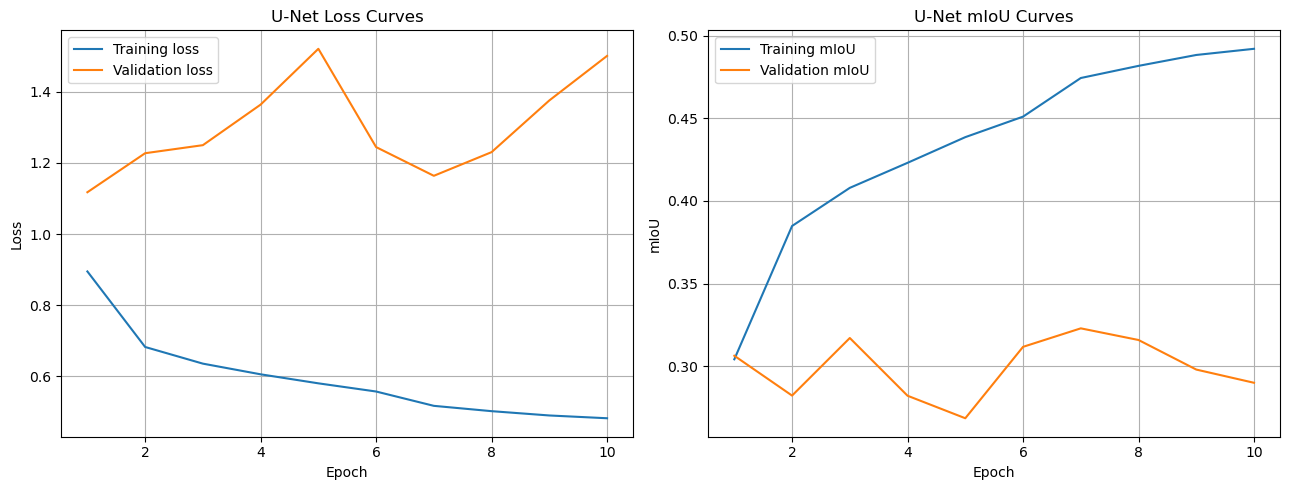


TRAINING COMPLETED
Epochs completed: 10
Best validation mIoU: 0.323
Best model: models/unet_best.pt
Training history: outputs/evaluation/unet_training_history.csv
Training curves: outputs/evaluation/unet_training_curves.png


In [70]:
from pathlib import Path
import json
import time
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

EPOCHS = 10
PATIENCE = 4
IGNORE_INDEX = 255
NUM_CLASSES = 6

MODEL_DIR = Path("models")
OUTPUT_DIR = Path("outputs/evaluation")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

torch.manual_seed(42)
torch.set_num_threads(16)

device = torch.device("cpu")

# Start with a fresh U-Net.
unet = UNet(
    in_channels=2,
    num_classes=6,
    base_channels=16
).to(device)

# Load class weights.
with open("outputs/data_audit/class_weights.json", "r") as f:
    weights_dict = json.load(f)

weights = torch.tensor(
    [weights_dict[str(i)] for i in range(6)],
    dtype=torch.float32
)

criterion = nn.CrossEntropyLoss(
    weight=weights,
    ignore_index=IGNORE_INDEX
)

optimizer = torch.optim.Adam(
    unet.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

# --------------------------------------------------
# 2. Evaluation metrics
# --------------------------------------------------

def calculate_metrics(confusion):

    confusion = confusion.astype(np.float64)

    true_positive = np.diag(confusion)

    actual = confusion.sum(axis=1)
    predicted = confusion.sum(axis=0)

    union = actual + predicted - true_positive

    iou = np.divide(
        true_positive,
        union,
        out=np.full(NUM_CLASSES, np.nan),
        where=union > 0
    )

    f1_denominator = actual + predicted

    f1 = np.divide(
        2 * true_positive,
        f1_denominator,
        out=np.full(NUM_CLASSES, np.nan),
        where=f1_denominator > 0
    )

    accuracy = (
        true_positive.sum() / confusion.sum()
        if confusion.sum() > 0 else 0.0
    )

    miou = float(np.nanmean(iou))

    return accuracy, miou, iou, f1


# --------------------------------------------------
# 3. Train and validate one epoch
# --------------------------------------------------

def run_epoch(model, loader, training):

    model.train(training)

    running_loss = 0.0
    total_samples = 0

    confusion = np.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=np.int64
    )

    context = torch.enable_grad() if training else torch.no_grad()

    with context:

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)

            loss = criterion(logits, labels)

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

            batch_size = images.size(0)

            running_loss += loss.item() * batch_size
            total_samples += batch_size

            predictions = torch.argmax(logits, dim=1)

            valid = labels != IGNORE_INDEX

            true_values = labels[valid]
            predicted_values = predictions[valid]

            encoded = (
                true_values * NUM_CLASSES + predicted_values
            )

            batch_confusion = torch.bincount(
                encoded,
                minlength=NUM_CLASSES * NUM_CLASSES
            )

            confusion += (
                batch_confusion
                .reshape(NUM_CLASSES, NUM_CLASSES)
                .cpu()
                .numpy()
            )

    average_loss = running_loss / max(total_samples, 1)

    accuracy, miou, iou, f1 = calculate_metrics(confusion)

    return average_loss, accuracy, miou, iou, f1


# --------------------------------------------------
# 4. Training loop
# --------------------------------------------------

history = []

best_miou = -1.0
epochs_without_improvement = 0

best_model_path = MODEL_DIR / "unet_best.pt"

print("=" * 65)
print("U-NET TRAINING")
print("=" * 65)

for epoch in range(1, EPOCHS + 1):

    start_time = time.time()

    train_loss, train_acc, train_miou, _, _ = run_epoch(
        unet,
        train_loader,
        training=True
    )

    val_loss, val_acc, val_miou, val_iou, val_f1 = run_epoch(
        unet,
        val_loader,
        training=False
    )

    scheduler.step(val_miou)

    epoch_time = time.time() - start_time

    current_lr = optimizer.param_groups[0]["lr"]

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_miou": train_miou,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_miou": val_miou,
        "learning_rate": current_lr
    }

    history.append(record)

    print(f"\nEpoch {epoch}/{EPOCHS}")
    print(f"Training loss:   {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Training OA:     {train_acc:.4f}")
    print(f"Validation OA:   {val_acc:.4f}")
    print(f"Validation mIoU: {val_miou:.4f}")
    print(f"Learning rate:   {current_lr:.6f}")
    print(f"Time:            {epoch_time:.1f} seconds")

    if val_miou > best_miou:

        best_miou = val_miou
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": unet.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_miou": best_miou,
                "input_channels": 2,
                "num_classes": 6,
                "base_channels": 16
            },
            best_model_path
        )

        print("Best model saved.")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping activated.")
        break


# --------------------------------------------------
# 5. Save training history
# --------------------------------------------------

history_df = pd.DataFrame(history)

history_df.to_csv(
    OUTPUT_DIR / "unet_training_history.csv",
    index=False
)

# --------------------------------------------------
# 6. Plot training curves
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation loss"
)

axes[0].set_title("U-Net Loss Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_df["epoch"],
    history_df["train_miou"],
    label="Training mIoU"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_miou"],
    label="Validation mIoU"
)

axes[1].set_title("U-Net mIoU Curves")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mIoU")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "unet_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 7. Final summary
# --------------------------------------------------

print("\nTRAINING COMPLETED")
print("=" * 65)

print("Epochs completed:", len(history))
print("Best validation mIoU:", round(best_miou, 4))
print("Best model:", best_model_path)
print("Training history:", OUTPUT_DIR / "unet_training_history.csv")
print("Training curves:", OUTPUT_DIR / "unet_training_curves.png")

In [71]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

INPUT_CHANNELS = 2
NUM_CLASSES = 6
BASE_CHANNELS = 16
PATCH_SIZE = 64

torch.manual_seed(42)
torch.set_num_threads(16)


# --------------------------------------------------
# 2. Convolution block
# --------------------------------------------------

class FCNConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels, num_convs=2):

        super().__init__()

        layers = []

        for i in range(num_convs):

            input_ch = in_channels if i == 0 else out_channels

            layers.extend([
                nn.Conv2d(
                    input_ch,
                    out_channels,
                    kernel_size=3,
                    padding=1,
                    bias=False
                ),
                nn.GroupNorm(8, out_channels),
                nn.ReLU(inplace=True)
            ])

        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


# --------------------------------------------------
# 3. FCN-8s architecture
# --------------------------------------------------

class FCN8s(nn.Module):

    def __init__(self, in_channels=2, num_classes=6, base=16):

        super().__init__()

        # Encoder
        self.block1 = FCNConvBlock(in_channels, base, 2)
        self.block2 = FCNConvBlock(base, base * 2, 2)
        self.block3 = FCNConvBlock(base * 2, base * 4, 3)
        self.block4 = FCNConvBlock(base * 4, base * 8, 3)
        self.block5 = FCNConvBlock(base * 8, base * 8, 3)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Classification scores at different resolutions
        self.score_pool3 = nn.Conv2d(
            base * 4, num_classes, kernel_size=1
        )

        self.score_pool4 = nn.Conv2d(
            base * 8, num_classes, kernel_size=1
        )

        self.score_pool5 = nn.Sequential(
            nn.Conv2d(
                base * 8, base * 8, kernel_size=3, padding=1
            ),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.1),
            nn.Conv2d(
                base * 8, num_classes, kernel_size=1
            )
        )

    def forward(self, x):

        original_size = x.shape[2:]

        # Encoder
        x = self.block1(x)
        x = self.pool(x)

        x = self.block2(x)
        x = self.pool(x)

        pool3 = self.block3(x)
        x = self.pool(pool3)

        pool4 = self.block4(x)
        x = self.pool(pool4)

        pool5 = self.block5(x)
        x = self.pool(pool5)

        # FCN-32 score
        score5 = self.score_pool5(pool5)

        # Upsample and fuse pool4 features
        score5_up = F.interpolate(
            score5,
            size=pool4.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        score4 = self.score_pool4(pool4)
        fuse4 = score5_up + score4

        # Upsample and fuse pool3 features
        fuse4_up = F.interpolate(
            fuse4,
            size=pool3.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        score3 = self.score_pool3(pool3)
        fuse3 = fuse4_up + score3

        # Final upsampling to original resolution
        output = F.interpolate(
            fuse3,
            size=original_size,
            mode="bilinear",
            align_corners=False
        )

        return output


# --------------------------------------------------
# 4. Initialize FCN-8s
# --------------------------------------------------

device = torch.device("cpu")

fcn = FCN8s(
    in_channels=INPUT_CHANNELS,
    num_classes=NUM_CLASSES,
    base=BASE_CHANNELS
).to(device)


# --------------------------------------------------
# 5. Test architecture
# --------------------------------------------------

dummy_input = torch.randn(
    2, INPUT_CHANNELS, PATCH_SIZE, PATCH_SIZE
)

with torch.no_grad():
    output = fcn(dummy_input)

total_parameters = sum(
    p.numel() for p in fcn.parameters()
)

print("=" * 55)
print("FCN-8s MODEL VERIFICATION")
print("=" * 55)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Total parameters:", f"{total_parameters:,}")
print("Device:", device)

assert output.shape == (2, 6, 64, 64)

print("\nSUCCESS: FCN-8s architecture is working.")

FCN-8s MODEL VERIFICATION
Input shape: torch.Size([2, 2, 64, 64])
Output shape: torch.Size([2, 6, 64, 64])
Total parameters: 1,071,218
Device: cpu

SUCCESS: FCN-8s architecture is working.


FCN-8s TRAINING

Epoch 1/10
Training loss:   0.8060
Validation loss: 1.0753
Training OA:     0.8050
Validation OA:   0.6937
Validation mIoU: 0.3238
Learning rate:   0.001000
Time:            37.0 seconds
Best FCN model saved.

Epoch 2/10
Training loss:   0.6359
Validation loss: 1.1904
Training OA:     0.8303
Validation OA:   0.6316
Validation mIoU: 0.3091
Learning rate:   0.001000
Time:            36.7 seconds

Epoch 3/10
Training loss:   0.5544
Validation loss: 1.2093
Training OA:     0.8424
Validation OA:   0.6586
Validation mIoU: 0.3258
Learning rate:   0.001000
Time:            36.9 seconds
Best FCN model saved.

Epoch 4/10
Training loss:   0.5004
Validation loss: 1.0511
Training OA:     0.8490
Validation OA:   0.6925
Validation mIoU: 0.3419
Learning rate:   0.001000
Time:            37.7 seconds
Best FCN model saved.

Epoch 5/10
Training loss:   0.4465
Validation loss: 1.2491
Training OA:     0.8581
Validation OA:   0.6781
Validation mIoU: 0.3337
Learning rate:   0.001000
Time:   

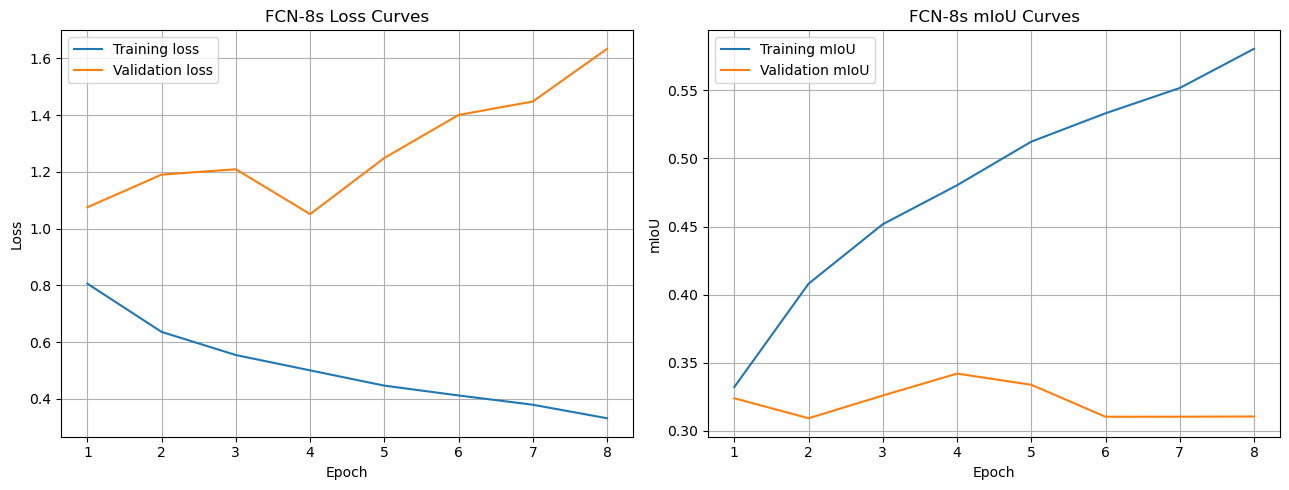


FCN-8s TRAINING COMPLETED
Epochs completed: 8
Best validation mIoU: 0.3419
Best model: models/fcn8s_best.pt
Training history: outputs/evaluation/fcn8s_training_history.csv
Training curves: outputs/evaluation/fcn8s_training_curves.png


In [72]:
from pathlib import Path
import json
import time
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

EPOCHS = 10
PATIENCE = 4
NUM_CLASSES = 6
IGNORE_INDEX = 255

MODEL_DIR = Path("models")
OUTPUT_DIR = Path("outputs/evaluation")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

torch.manual_seed(42)
torch.set_num_threads(16)

device = torch.device("cpu")

# Initialize a fresh FCN-8s model
fcn = FCN8s(
    in_channels=2,
    num_classes=6,
    base=16
).to(device)

# Load the same class weights used for U-Net
with open("outputs/data_audit/class_weights.json", "r") as f:
    weights_dict = json.load(f)

class_weights_tensor = torch.tensor(
    [weights_dict[str(i)] for i in range(6)],
    dtype=torch.float32
)

criterion_fcn = nn.CrossEntropyLoss(
    weight=class_weights_tensor,
    ignore_index=IGNORE_INDEX
)

optimizer_fcn = torch.optim.Adam(
    fcn.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler_fcn = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_fcn,
    mode="max",
    factor=0.5,
    patience=2
)

# --------------------------------------------------
# 2. Metrics
# --------------------------------------------------

def fcn_metrics(confusion):

    confusion = confusion.astype(np.float64)

    tp = np.diag(confusion)
    actual = confusion.sum(axis=1)
    predicted = confusion.sum(axis=0)

    union = actual + predicted - tp

    iou = np.divide(
        tp,
        union,
        out=np.full(NUM_CLASSES, np.nan),
        where=union > 0
    )

    f1 = np.divide(
        2 * tp,
        actual + predicted,
        out=np.full(NUM_CLASSES, np.nan),
        where=(actual + predicted) > 0
    )

    oa = tp.sum() / confusion.sum()

    miou = float(np.nanmean(iou))

    return oa, miou, iou, f1


# --------------------------------------------------
# 3. Train or validate one epoch
# --------------------------------------------------

def run_fcn_epoch(model, loader, training):

    model.train(training)

    running_loss = 0.0
    total_samples = 0

    confusion = np.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=np.int64
    )

    context = (
        torch.enable_grad()
        if training
        else torch.no_grad()
    )

    with context:

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer_fcn.zero_grad(set_to_none=True)

            logits = model(images)

            loss = criterion_fcn(logits, labels)

            if training:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer_fcn.step()

            batch_size = images.size(0)

            running_loss += loss.item() * batch_size
            total_samples += batch_size

            predictions = logits.argmax(dim=1)

            valid = labels != IGNORE_INDEX

            true_values = labels[valid]
            predicted_values = predictions[valid]

            encoded = (
                true_values * NUM_CLASSES + predicted_values
            )

            batch_confusion = torch.bincount(
                encoded,
                minlength=NUM_CLASSES ** 2
            )

            confusion += (
                batch_confusion
                .reshape(NUM_CLASSES, NUM_CLASSES)
                .cpu()
                .numpy()
            )

    average_loss = running_loss / max(total_samples, 1)

    oa, miou, iou, f1 = fcn_metrics(confusion)

    return average_loss, oa, miou, iou, f1


# --------------------------------------------------
# 4. Training loop
# --------------------------------------------------

history_fcn = []

best_fcn_miou = -1.0
epochs_without_improvement = 0

best_fcn_path = MODEL_DIR / "fcn8s_best.pt"

print("=" * 60)
print("FCN-8s TRAINING")
print("=" * 60)

for epoch in range(1, EPOCHS + 1):

    start_time = time.time()

    train_loss, train_oa, train_miou, _, _ = run_fcn_epoch(
        fcn,
        train_loader,
        training=True
    )

    val_loss, val_oa, val_miou, val_iou, val_f1 = run_fcn_epoch(
        fcn,
        val_loader,
        training=False
    )

    scheduler_fcn.step(val_miou)

    epoch_time = time.time() - start_time

    current_lr = optimizer_fcn.param_groups[0]["lr"]

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_oa,
        "train_miou": train_miou,
        "val_loss": val_loss,
        "val_accuracy": val_oa,
        "val_miou": val_miou,
        "learning_rate": current_lr
    }

    history_fcn.append(record)

    print(f"\nEpoch {epoch}/{EPOCHS}")
    print(f"Training loss:   {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Training OA:     {train_oa:.4f}")
    print(f"Validation OA:   {val_oa:.4f}")
    print(f"Validation mIoU: {val_miou:.4f}")
    print(f"Learning rate:   {current_lr:.6f}")
    print(f"Time:            {epoch_time:.1f} seconds")

    if val_miou > best_fcn_miou:

        best_fcn_miou = val_miou
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": fcn.state_dict(),
                "optimizer_state_dict": optimizer_fcn.state_dict(),
                "best_val_miou": best_fcn_miou,
                "input_channels": 2,
                "num_classes": 6,
                "base_channels": 16
            },
            best_fcn_path
        )

        print("Best FCN model saved.")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping activated.")
        break


# --------------------------------------------------
# 5. Save training history
# --------------------------------------------------

history_fcn_df = pd.DataFrame(history_fcn)

history_fcn_df.to_csv(
    OUTPUT_DIR / "fcn8s_training_history.csv",
    index=False
)


# --------------------------------------------------
# 6. Plot training curves
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    history_fcn_df["epoch"],
    history_fcn_df["train_loss"],
    label="Training loss"
)

axes[0].plot(
    history_fcn_df["epoch"],
    history_fcn_df["val_loss"],
    label="Validation loss"
)

axes[0].set_title("FCN-8s Loss Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_fcn_df["epoch"],
    history_fcn_df["train_miou"],
    label="Training mIoU"
)

axes[1].plot(
    history_fcn_df["epoch"],
    history_fcn_df["val_miou"],
    label="Validation mIoU"
)

axes[1].set_title("FCN-8s mIoU Curves")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mIoU")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "fcn8s_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# 7. Final summary
# --------------------------------------------------

print("\nFCN-8s TRAINING COMPLETED")
print("=" * 60)

print("Epochs completed:", len(history_fcn))
print("Best validation mIoU:", round(best_fcn_miou, 4))
print("Best model:", best_fcn_path)

print(
    "Training history:",
    OUTPUT_DIR / "fcn8s_training_history.csv"
)

print(
    "Training curves:",
    OUTPUT_DIR / "fcn8s_training_curves.png"
)


Evaluating U-Net...
Overall Accuracy: 0.6893
mIoU: 0.3230

Evaluating FCN-8s...
Overall Accuracy: 0.6925
mIoU: 0.3419

MODEL COMPARISON


,Model,Best Epoch,Overall Accuracy,Mean IoU,Mean F1,Parameters
0,U-Net,7,0.6893,0.3230,0.4257,1964038
1,FCN-8s,4,0.6925,0.3419,0.4464,1071218



CLASS-WISE MODEL COMPARISON


Model,FCN-8s,U-Net
Class,,
Bare vegetation,0.0066,0.0027
Built-up,0.4916,0.4975
Cropland,0.0008,0.0025
Grassland,0.3089,0.2329
Permanent water,0.6533,0.6036
Tree cover,0.5905,0.5985


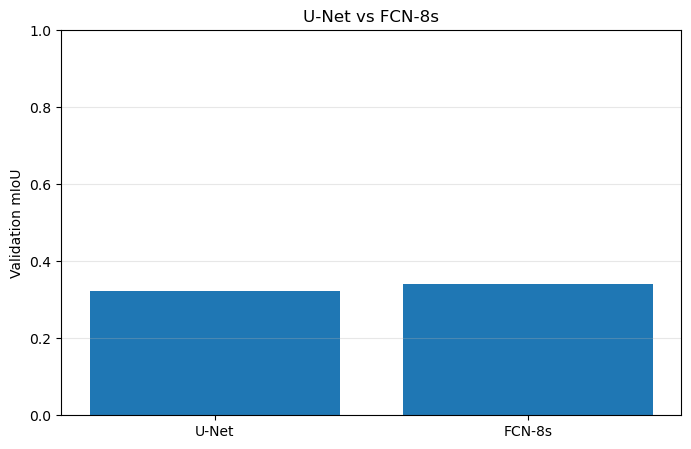


Comparison saved in: outputs/evaluation


In [73]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

MODEL_DIR = Path("models")
OUTPUT_DIR = Path("outputs/evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NUM_CLASSES = 6
IGNORE_INDEX = 255

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

device = torch.device("cpu")


# --------------------------------------------------
# 1. Load the best saved models
# --------------------------------------------------

unet_checkpoint = torch.load(
    MODEL_DIR / "unet_best.pt",
    map_location=device,
    weights_only=False
)

fcn_checkpoint = torch.load(
    MODEL_DIR / "fcn8s_best.pt",
    map_location=device,
    weights_only=False
)

best_unet = UNet(
    in_channels=2,
    num_classes=6,
    base_channels=16
).to(device)

best_fcn = FCN8s(
    in_channels=2,
    num_classes=6,
    base=16
).to(device)

best_unet.load_state_dict(
    unet_checkpoint["model_state_dict"]
)

best_fcn.load_state_dict(
    fcn_checkpoint["model_state_dict"]
)

best_unet.eval()
best_fcn.eval()

models = {
    "U-Net": best_unet,
    "FCN-8s": best_fcn
}


# --------------------------------------------------
# 2. Evaluate a model
# --------------------------------------------------

def evaluate_model(model, loader):

    confusion = np.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=np.int64
    )

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            predictions = logits.argmax(dim=1)

            valid = labels != IGNORE_INDEX

            true = labels[valid]
            pred = predictions[valid]

            encoded = true * NUM_CLASSES + pred

            counts = torch.bincount(
                encoded,
                minlength=NUM_CLASSES ** 2
            )

            confusion += counts.reshape(
                NUM_CLASSES, NUM_CLASSES
            ).cpu().numpy()

    tp = np.diag(confusion).astype(float)
    actual = confusion.sum(axis=1).astype(float)
    predicted = confusion.sum(axis=0).astype(float)

    union = actual + predicted - tp

    iou = np.divide(
        tp,
        union,
        out=np.full(NUM_CLASSES, np.nan),
        where=union > 0
    )

    f1 = np.divide(
        2 * tp,
        actual + predicted,
        out=np.full(NUM_CLASSES, np.nan),
        where=(actual + predicted) > 0
    )

    oa = tp.sum() / confusion.sum()
    miou = np.nanmean(iou)

    mean_f1 = np.nanmean(f1)

    return {
        "confusion": confusion,
        "oa": oa,
        "miou": miou,
        "mean_f1": mean_f1,
        "iou": iou,
        "f1": f1
    }


# --------------------------------------------------
# 3. Evaluate both models on validation data
# --------------------------------------------------

results = {}

for model_name, model in models.items():

    print(f"\nEvaluating {model_name}...")

    results[model_name] = evaluate_model(
        model,
        val_loader
    )

    print(
        "Overall Accuracy:",
        f"{results[model_name]['oa']:.4f}"
    )

    print(
        "mIoU:",
        f"{results[model_name]['miou']:.4f}"
    )


# --------------------------------------------------
# 4. Overall comparison
# --------------------------------------------------

comparison_df = pd.DataFrame([
    {
        "Model": name,
        "Best Epoch": (
            unet_checkpoint["epoch"]
            if name == "U-Net"
            else fcn_checkpoint["epoch"]
        ),
        "Overall Accuracy": result["oa"],
        "Mean IoU": result["miou"],
        "Mean F1": result["mean_f1"],
        "Parameters": (
            sum(p.numel() for p in best_unet.parameters())
            if name == "U-Net"
            else sum(p.numel() for p in best_fcn.parameters())
        )
    }
    for name, result in results.items()
])

print("\nMODEL COMPARISON")
display(comparison_df.round(4))

comparison_df.to_csv(
    OUTPUT_DIR / "model_comparison_validation.csv",
    index=False
)


# --------------------------------------------------
# 5. Class-wise comparison
# --------------------------------------------------

class_records = []

for model_name, result in results.items():

    for index, class_name in enumerate(CLASS_NAMES):

        class_records.append({
            "Model": model_name,
            "Class": class_name,
            "IoU": result["iou"][index],
            "F1": result["f1"][index]
        })

class_df = pd.DataFrame(class_records)

print("\nCLASS-WISE MODEL COMPARISON")
display(
    class_df.pivot(
        index="Class",
        columns="Model",
        values="IoU"
    ).round(4)
)

class_df.to_csv(
    OUTPUT_DIR / "classwise_model_comparison.csv",
    index=False
)


# --------------------------------------------------
# 6. Plot mIoU comparison
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Mean IoU"]
)

plt.ylabel("Validation mIoU")
plt.title("U-Net vs FCN-8s")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    OUTPUT_DIR / "model_comparison_validation.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nComparison saved in:", OUTPUT_DIR)

In [77]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# Load the test patches
X_test, y_test = load_patch_split("test")

# Convert inputs to tensors
if not torch.is_tensor(X_test):
    X_test = torch.from_numpy(np.asarray(X_test))

if not torch.is_tensor(y_test):
    y_test = torch.from_numpy(np.asarray(y_test))

# Convert input from NHWC to NCHW if necessary
if X_test.ndim == 4 and X_test.shape[-1] == 2:
    X_test = X_test.permute(0, 3, 1, 2)

X_test = X_test.float()
y_test = y_test.long()

# Create test dataset and loader
test_dataset = TensorDataset(X_test, y_test)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Test dataset prepared successfully")
print("Input shape:", X_test.shape)
print("Label shape:", y_test.shape)
print("Number of test patches:", len(test_dataset))
print("Number of batches:", len(test_loader))


Loading TEST patches...
Number of patches: 6672
Input shape: (6672, 2, 64, 64)
Label shape: (6672, 64, 64)


ValueError: too many values to unpack (expected 2)

In [76]:
import torch
from torch.utils.data import DataLoader

# Load test dataset
test_dataset = load_patch_split("test")

# Create DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

# Inspect one batch
X_batch, y_batch = next(iter(test_loader))

print("=" * 55)
print("TEST DATASET PREPARED SUCCESSFULLY")
print("=" * 55)

print("Total test patches:", len(test_dataset))
print("Input batch shape:", X_batch.shape)
print("Label batch shape:", y_batch.shape)
print("Number of batches:", len(test_loader))
print("Input data type:", X_batch.dtype)
print("Label data type:", y_batch.dtype)
print("Device:", X_batch.device)

print("=" * 55)


Loading TEST patches...
Number of patches: 6672
Input shape: (6672, 2, 64, 64)
Label shape: (6672, 64, 64)
TEST DATASET PREPARED SUCCESSFULLY
Total test patches: 6672
Input batch shape: torch.Size([16, 2, 64, 64])
Label batch shape: torch.Size([16, 64, 64])
Number of batches: 417
Input data type: torch.float32
Label data type: torch.int64
Device: cpu


In [78]:
test_data = load_patch_split("test")

print("Return type:", type(test_data))

if isinstance(test_data, (tuple, list)):
    print("Number of returned items:", len(test_data))

    for i, item in enumerate(test_data):
        print(f"\nItem {i}:")
        print("Type:", type(item))

        if hasattr(item, "shape"):
            print("Shape:", item.shape)
        elif isinstance(item, dict):
            print("Keys:", item.keys())
        else:
            print("Value:", str(item)[:300])

elif isinstance(test_data, dict):
    print("Keys:", test_data.keys())


Loading TEST patches...
Number of patches: 6672
Input shape: (6672, 2, 64, 64)
Label shape: (6672, 64, 64)
Return type: <class 'torch.utils.data.dataset.TensorDataset'>


In [79]:
from torch.utils.data import DataLoader

# Extract tensors from the existing TensorDataset
X_test, y_test = test_data.tensors

# Create test DataLoader
test_loader = DataLoader(
    test_data,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Test DataLoader created successfully")
print("Input shape:", X_test.shape)
print("Label shape:", y_test.shape)
print("Number of test patches:", len(test_data))
print("Number of batches:", len(test_loader))

Test DataLoader created successfully
Input shape: torch.Size([6672, 2, 64, 64])
Label shape: torch.Size([6672, 64, 64])
Number of test patches: 6672
Number of batches: 417


Selected model: FCN-8s
Checkpoint epoch: 4

FINAL TEST RESULTS
------------------------------
Overall Accuracy: 0.6446
Mean IoU:         0.2965
Mean F1 Score:    0.4004
Valid test pixels: 27082788


,Class,IoU,F1 Score,Reference Pixels,Predicted Pixels
0,Tree cover,0.3570,0.5262,5650416,7806108
1,Grassland,0.1951,0.3265,1675632,2288410
2,Cropland,0.0154,0.0304,1250892,104186
3,Built-up,0.6144,0.7612,15238356,12357887
4,Bare vegetation,0.0088,0.0174,279012,103376
5,Permanent water,0.5880,0.7405,2988480,4422821


,Model,Test Overall Accuracy,Test Mean IoU,Test Mean F1,Test Pixels,Checkpoint Epoch
0,FCN-8s,0.6446,0.2965,0.4004,27082788,4


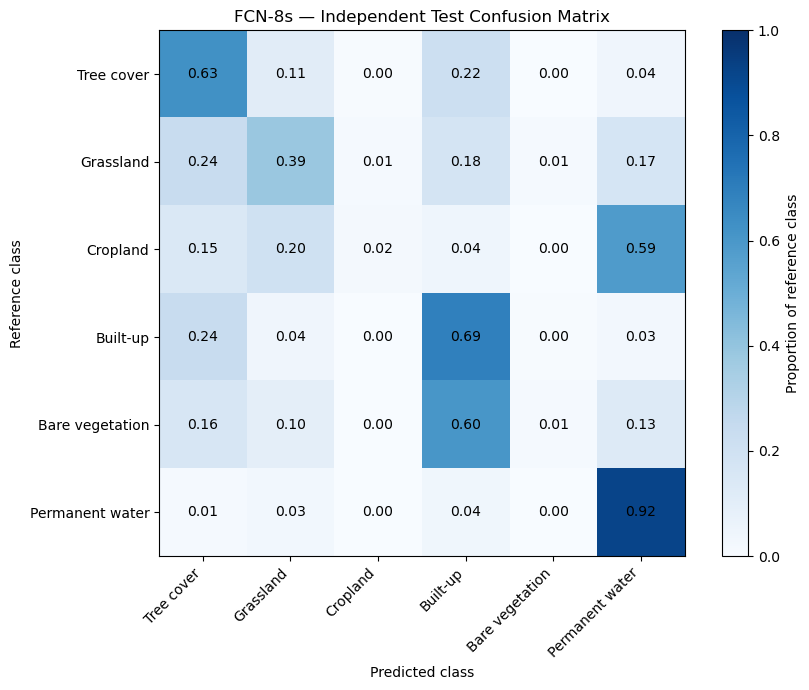


Test evaluation files saved in: outputs/evaluation


In [80]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("outputs/evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

NUM_CLASSES = 6
IGNORE_INDEX = 255
device = torch.device("cpu")

# --------------------------------------------------
# 1. Load the selected FCN-8s checkpoint
# --------------------------------------------------

checkpoint = torch.load(
    "models/fcn8s_best.pt",
    map_location=device,
    weights_only=False
)

final_model = FCN8s(
    in_channels=2,
    num_classes=6,
    base=16
).to(device)

final_model.load_state_dict(checkpoint["model_state_dict"])
final_model.eval()

print("Selected model: FCN-8s")
print("Checkpoint epoch:", checkpoint["epoch"])

# --------------------------------------------------
# 2. Evaluate on the independent test set
# --------------------------------------------------

confusion = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64
)

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        logits = final_model(images)
        predictions = logits.argmax(dim=1)

        valid = labels != IGNORE_INDEX

        true = labels[valid]
        pred = predictions[valid]

        encoded = true * NUM_CLASSES + pred

        counts = torch.bincount(
            encoded,
            minlength=NUM_CLASSES ** 2
        )

        confusion += counts.reshape(
            NUM_CLASSES, NUM_CLASSES
        ).cpu().numpy()

# --------------------------------------------------
# 3. Calculate evaluation metrics
# --------------------------------------------------

tp = np.diag(confusion).astype(float)
actual = confusion.sum(axis=1).astype(float)
predicted = confusion.sum(axis=0).astype(float)

union = actual + predicted - tp

iou = np.divide(
    tp,
    union,
    out=np.full(NUM_CLASSES, np.nan),
    where=union > 0
)

f1 = np.divide(
    2 * tp,
    actual + predicted,
    out=np.full(NUM_CLASSES, np.nan),
    where=(actual + predicted) > 0
)

oa = tp.sum() / confusion.sum()
miou = np.nanmean(iou)
mean_f1 = np.nanmean(f1)

print("\nFINAL TEST RESULTS")
print("------------------------------")
print(f"Overall Accuracy: {oa:.4f}")
print(f"Mean IoU:         {miou:.4f}")
print(f"Mean F1 Score:    {mean_f1:.4f}")
print("Valid test pixels:", int(confusion.sum()))

# --------------------------------------------------
# 4. Class-wise metrics
# --------------------------------------------------

class_metrics = pd.DataFrame({
    "Class": CLASS_NAMES,
    "IoU": iou,
    "F1 Score": f1,
    "Reference Pixels": actual.astype(int),
    "Predicted Pixels": predicted.astype(int)
})

display(class_metrics.round(4))

class_metrics.to_csv(
    OUTPUT_DIR / "fcn8s_test_class_metrics.csv",
    index=False
)

# --------------------------------------------------
# 5. Save overall test metrics
# --------------------------------------------------

overall_metrics = pd.DataFrame([{
    "Model": "FCN-8s",
    "Test Overall Accuracy": oa,
    "Test Mean IoU": miou,
    "Test Mean F1": mean_f1,
    "Test Pixels": int(confusion.sum()),
    "Checkpoint Epoch": checkpoint["epoch"]
}])

display(overall_metrics.round(4))

overall_metrics.to_csv(
    OUTPUT_DIR / "fcn8s_test_overall_metrics.csv",
    index=False
)

pd.DataFrame(
    confusion,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    OUTPUT_DIR / "fcn8s_test_confusion_matrix.csv"
)

# --------------------------------------------------
# 6. Plot confusion matrix
# --------------------------------------------------

row_totals = confusion.sum(axis=1, keepdims=True)

normalized_confusion = np.divide(
    confusion,
    row_totals,
    out=np.zeros_like(confusion, dtype=float),
    where=row_totals > 0
)

plt.figure(figsize=(9, 7))

plt.imshow(normalized_confusion, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Proportion of reference class")

plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)

plt.xlabel("Predicted class")
plt.ylabel("Reference class")
plt.title("FCN-8s — Independent Test Confusion Matrix")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(
            j, i,
            f"{normalized_confusion[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "fcn8s_test_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nTest evaluation files saved in:", OUTPUT_DIR)

In [81]:
from pathlib import Path
import numpy as np

TEST_DIR = Path("data/processed/patches/test")

test_files = sorted(TEST_DIR.glob("*/*.npz"))

print("Total test files:", len(test_files))

# Count files for each city
city_counts = {}

for file in test_files:
    city = file.parent.name
    city_counts[city] = city_counts.get(city, 0) + 1

print("\nTest files by city:")
for city, count in city_counts.items():
    print(f"{city}: {count} files")

# Inspect one file from each city
print("\nNPZ structure:")

for city in city_counts:
    city_file = next(
        file for file in test_files
        if file.parent.name == city
    )

    print(f"\nCity: {city}")
    print("File:", city_file.name)

    with np.load(city_file) as data:
        print("Array names:", data.files)

        for key in data.files:
            print(
                key,
                "| Shape:", data[key].shape,
                "| Data type:", data[key].dtype
            )

Total test files: 36

Test files by city:
Heidelberg: 12 files
Nairobi: 12 files
Sydney: 12 files

NPZ structure:

City: Heidelberg
File: heidelberg_2025_01.npz
Array names: ['X', 'y', 'coordinates', 'sar_valid_ratio']
X | Shape: (196, 64, 64, 2) | Data type: float32
y | Shape: (196, 64, 64) | Data type: uint8
coordinates | Shape: (196, 2) | Data type: int32
sar_valid_ratio | Shape: (196,) | Data type: float32

City: Nairobi
File: nairobi_2025_01.npz
Array names: ['X', 'y', 'coordinates', 'sar_valid_ratio']
X | Shape: (182, 64, 64, 2) | Data type: float32
y | Shape: (182, 64, 64) | Data type: uint8
coordinates | Shape: (182, 2) | Data type: int32
sar_valid_ratio | Shape: (182,) | Data type: float32

City: Sydney
File: sydney_2025_01.npz
Array names: ['X', 'y', 'coordinates', 'sar_valid_ratio']
X | Shape: (178, 64, 64, 2) | Data type: float32
y | Shape: (178, 64, 64) | Data type: uint8
coordinates | Shape: (178, 2) | Data type: int32
sar_valid_ratio | Shape: (178,) | Data type: float32


In [82]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("outputs/evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

NUM_CLASSES = 6
IGNORE_INDEX = 255
BATCH_SIZE = 16
device = torch.device("cpu")

# --------------------------------------------------
# 1. Load the final selected model
# --------------------------------------------------

checkpoint = torch.load(
    "models/fcn8s_best.pt",
    map_location=device,
    weights_only=False
)

final_model = FCN8s(
    in_channels=2,
    num_classes=NUM_CLASSES,
    base=16
).to(device)

final_model.load_state_dict(checkpoint["model_state_dict"])
final_model.eval()

print("FCN-8s loaded. Best checkpoint epoch:", checkpoint["epoch"])


# --------------------------------------------------
# 2. Metric calculation
# --------------------------------------------------

def calculate_metrics(confusion):

    tp = np.diag(confusion).astype(float)
    actual = confusion.sum(axis=1).astype(float)
    predicted = confusion.sum(axis=0).astype(float)

    union = actual + predicted - tp

    iou = np.divide(
        tp,
        union,
        out=np.full(NUM_CLASSES, np.nan),
        where=union > 0
    )

    f1 = np.divide(
        2 * tp,
        actual + predicted,
        out=np.full(NUM_CLASSES, np.nan),
        where=(actual + predicted) > 0
    )

    oa = tp.sum() / confusion.sum() if confusion.sum() else np.nan

    return {
        "oa": oa,
        "miou": np.nanmean(iou),
        "mean_f1": np.nanmean(f1),
        "iou": iou,
        "f1": f1,
        "valid_pixels": int(confusion.sum())
    }


# --------------------------------------------------
# 3. Predict one monthly NPZ file
# --------------------------------------------------

def evaluate_npz_file(file_path):

    confusion = np.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=np.int64
    )

    with np.load(file_path) as data:

        X = data["X"]
        y = data["y"]

    # NHWC -> NCHW
    X_tensor = torch.from_numpy(X).permute(0, 3, 1, 2).float()
    y_tensor = torch.from_numpy(y).long()

    with torch.inference_mode():

        for start in range(0, len(X_tensor), BATCH_SIZE):

            images = X_tensor[start:start + BATCH_SIZE].to(device)
            labels = y_tensor[start:start + BATCH_SIZE].to(device)

            predictions = final_model(images).argmax(dim=1)

            valid = labels != IGNORE_INDEX

            true = labels[valid]
            pred = predictions[valid]

            encoded = true * NUM_CLASSES + pred

            counts = torch.bincount(
                encoded,
                minlength=NUM_CLASSES ** 2
            )

            confusion += counts.reshape(
                NUM_CLASSES, NUM_CLASSES
            ).cpu().numpy()

    return confusion


# --------------------------------------------------
# 4. Evaluate all cities and months
# --------------------------------------------------

TEST_DIR = Path("data/processed/patches/test")
test_files = sorted(TEST_DIR.glob("*/*.npz"))

city_confusions = {}
monthly_records = []

for file_path in test_files:

    city = file_path.parent.name
    month = file_path.stem.split("_")[-1]

    print(f"Evaluating {city} - {month}...")

    month_confusion = evaluate_npz_file(file_path)

    if city not in city_confusions:
        city_confusions[city] = np.zeros(
            (NUM_CLASSES, NUM_CLASSES),
            dtype=np.int64
        )

    city_confusions[city] += month_confusion

    metrics = calculate_metrics(month_confusion)

    monthly_records.append({
        "City": city,
        "Month": month,
        "Overall Accuracy": metrics["oa"],
        "Mean IoU": metrics["miou"],
        "Mean F1": metrics["mean_f1"],
        "Valid Pixels": metrics["valid_pixels"]
    })


# --------------------------------------------------
# 5. Calculate city-wise metrics
# --------------------------------------------------

city_records = []
class_records = []

for city, confusion in city_confusions.items():

    metrics = calculate_metrics(confusion)

    city_records.append({
        "City": city,
        "Overall Accuracy": metrics["oa"],
        "Mean IoU": metrics["miou"],
        "Mean F1": metrics["mean_f1"],
        "Valid Pixels": metrics["valid_pixels"]
    })

    for i, class_name in enumerate(CLASS_NAMES):

        class_records.append({
            "City": city,
            "Class": class_name,
            "IoU": metrics["iou"][i],
            "F1 Score": metrics["f1"][i]
        })


# --------------------------------------------------
# 6. Display and save results
# --------------------------------------------------

city_df = pd.DataFrame(city_records)
monthly_df = pd.DataFrame(monthly_records)
class_df = pd.DataFrame(class_records)

print("\nCITY-WISE FINAL TEST RESULTS")
display(city_df.round(4))

print("\nCLASS-WISE CITY PERFORMANCE")
display(
    class_df.pivot(
        index="Class",
        columns="City",
        values="IoU"
    ).round(4)
)

city_df.to_csv(
    OUTPUT_DIR / "fcn8s_city_wise_test_metrics.csv",
    index=False
)

monthly_df.to_csv(
    OUTPUT_DIR / "fcn8s_monthly_test_metrics.csv",
    index=False
)

class_df.to_csv(
    OUTPUT_DIR / "fcn8s_city_class_metrics.csv",
    index=False
)

for city, confusion in city_confusions.items():

    pd.DataFrame(
        confusion,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    ).to_csv(
        OUTPUT_DIR / f"{city.lower()}_test_confusion_matrix.csv"
    )

print("\nAll city-wise and monthly evaluation files saved in:")
print(OUTPUT_DIR)

FCN-8s loaded. Best checkpoint epoch: 4
Evaluating Heidelberg - 01...
Evaluating Heidelberg - 02...
Evaluating Heidelberg - 03...
Evaluating Heidelberg - 04...
Evaluating Heidelberg - 05...
Evaluating Heidelberg - 06...
Evaluating Heidelberg - 07...
Evaluating Heidelberg - 08...
Evaluating Heidelberg - 09...
Evaluating Heidelberg - 10...
Evaluating Heidelberg - 11...
Evaluating Heidelberg - 12...
Evaluating Nairobi - 01...
Evaluating Nairobi - 02...
Evaluating Nairobi - 03...
Evaluating Nairobi - 04...
Evaluating Nairobi - 05...
Evaluating Nairobi - 06...
Evaluating Nairobi - 07...
Evaluating Nairobi - 08...
Evaluating Nairobi - 09...
Evaluating Nairobi - 10...
Evaluating Nairobi - 11...
Evaluating Nairobi - 12...
Evaluating Sydney - 01...
Evaluating Sydney - 02...
Evaluating Sydney - 03...
Evaluating Sydney - 04...
Evaluating Sydney - 05...
Evaluating Sydney - 06...
Evaluating Sydney - 07...
Evaluating Sydney - 08...
Evaluating Sydney - 09...
Evaluating Sydney - 10...
Evaluating Sydne

,City,Overall Accuracy,Mean IoU,Mean F1,Valid Pixels
0,Heidelberg,0.5126,0.2081,0.3062,9609456
1,Nairobi,0.6423,0.2093,0.2949,8778372
2,Sydney,0.7929,0.3584,0.4430,8694960



CLASS-WISE CITY PERFORMANCE


City,Heidelberg,Nairobi,Sydney
Class,,,
Bare vegetation,0.0303,0.0055,0.0057
Built-up,0.5377,0.5976,0.7125
Cropland,0.0154,0.0163,0.0000
Grassland,0.1469,0.2792,0.2462
Permanent water,0.1357,0.0175,0.8552
Tree cover,0.3825,0.3397,0.3310



All city-wise and monthly evaluation files saved in:
outputs/evaluation


Heidelberg: selected patch 33; reference classes: [0 1 2 3 4 5]
Nairobi: selected patch 105; reference classes: [0 1 2 3 4 5]
Sydney: selected patch 7; reference classes: [0 1 3 4 5]


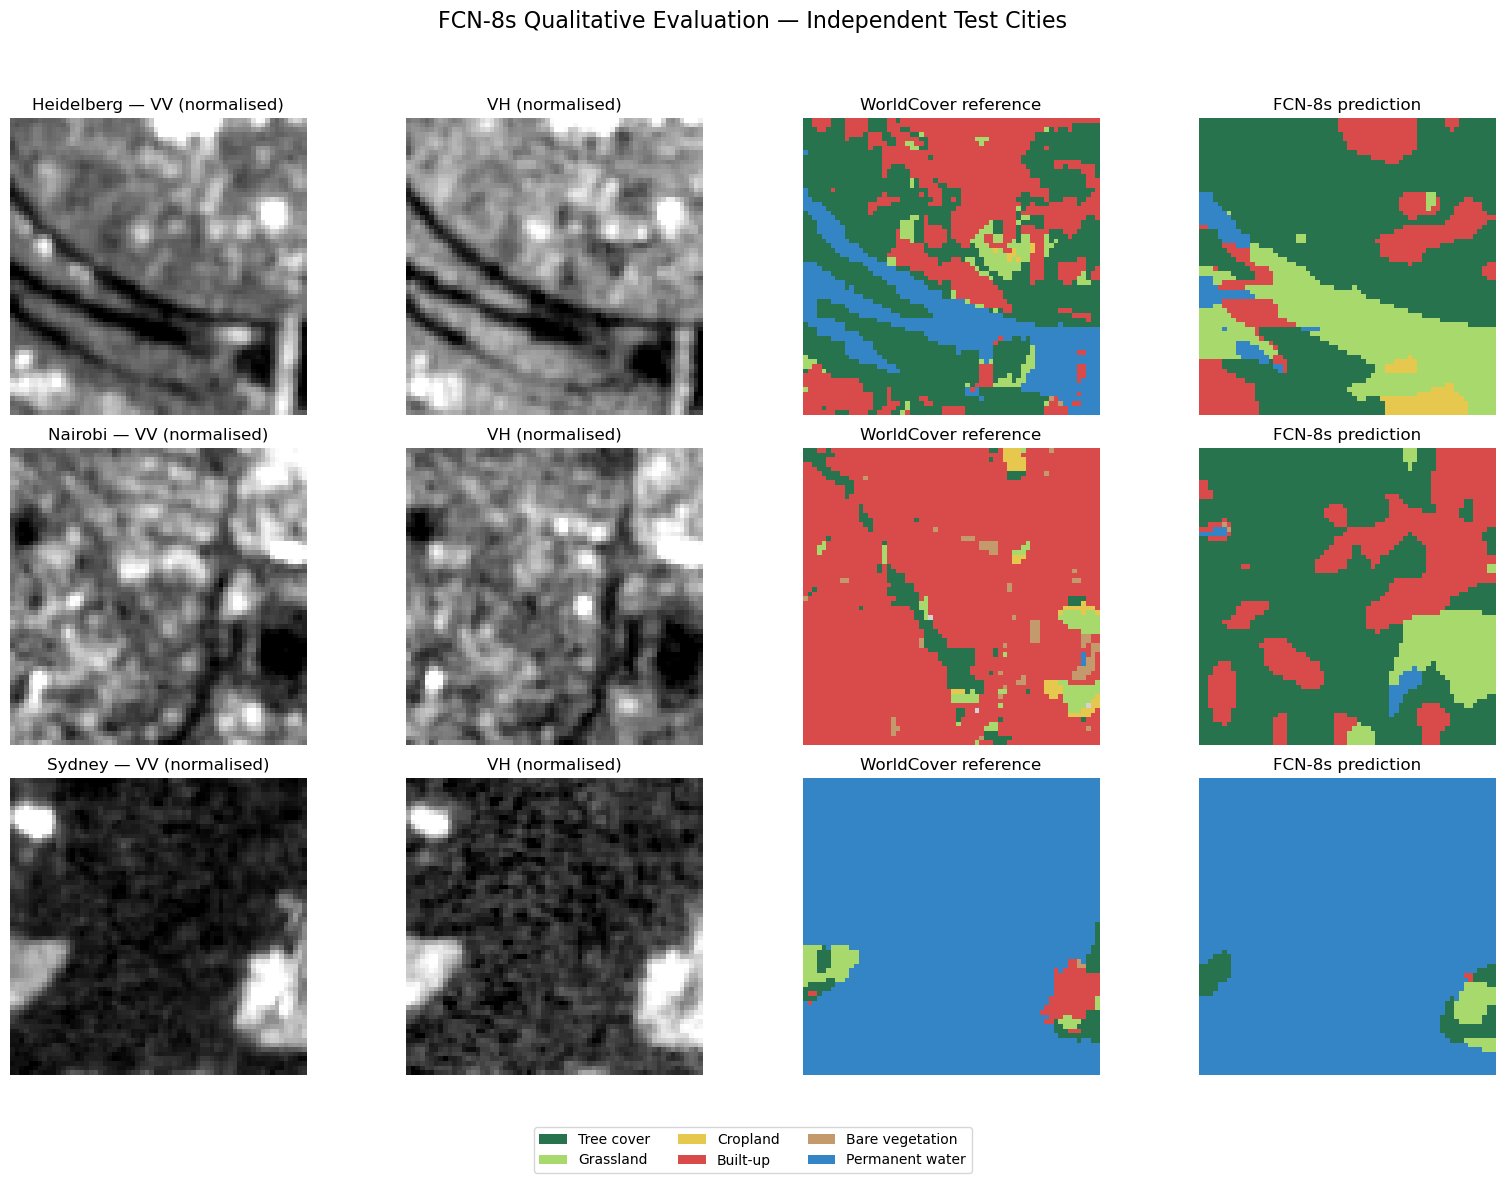

Saved qualitative comparison.


In [83]:
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

OUTPUT_DIR = Path("outputs/evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

# Consistent colours for the six classes
CLASS_COLORS = [
    "#26734D",  # Tree cover
    "#A8D96C",  # Grassland
    "#E6C84F",  # Cropland
    "#D94A4A",  # Built-up
    "#C49A6C",  # Bare vegetation
    "#3485C5"   # Permanent water
]

class_cmap = ListedColormap(CLASS_COLORS)
class_cmap.set_bad(color="lightgray")

device = torch.device("cpu")

# --------------------------------------------------
# 1. Load FCN-8s
# --------------------------------------------------

checkpoint = torch.load(
    "models/fcn8s_best.pt",
    map_location=device,
    weights_only=False
)

final_model = FCN8s(
    in_channels=2,
    num_classes=6,
    base=16
).to(device)

final_model.load_state_dict(checkpoint["model_state_dict"])
final_model.eval()

# --------------------------------------------------
# 2. Select a representative patch per city
# --------------------------------------------------

test_dir = Path("data/processed/patches/test")

cities = ["Heidelberg", "Nairobi", "Sydney"]

fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(16, 12)
)

for row, city in enumerate(cities):

    file_path = (
        test_dir /
        city /
        f"{city.lower()}_2025_01.npz"
    )

    with np.load(file_path) as data:
        X = data["X"]
        y = data["y"]

    # Select a patch with high valid-label coverage
    # and a good variety of represented classes.
    best_index = None
    best_score = -1

    for i in range(len(y)):

        valid = y[i] != 255
        valid_ratio = valid.mean()

        if valid_ratio < 0.90:
            continue

        unique_classes = np.unique(y[i][valid])
        class_count = len(unique_classes)

        score = class_count * 1000 + valid_ratio

        if score > best_score:
            best_score = score
            best_index = i

    if best_index is None:
        raise ValueError(f"No suitable patch found for {city}")

    image = X[best_index]
    reference = y[best_index]

    # Predict
    image_tensor = (
        torch.from_numpy(image)
        .permute(2, 0, 1)
        .unsqueeze(0)
        .float()
        .to(device)
    )

    with torch.inference_mode():
        prediction = (
            final_model(image_tensor)
            .argmax(dim=1)
            .squeeze(0)
            .cpu()
            .numpy()
        )

    # SAR VV
    ax = axes[row, 0]
    vv = image[:, :, 0]
    vmin, vmax = np.percentile(vv, [2, 98])
    ax.imshow(vv, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(f"{city} — VV (normalised)")

    # SAR VH
    ax = axes[row, 1]
    vh = image[:, :, 1]
    vmin, vmax = np.percentile(vh, [2, 98])
    ax.imshow(vh, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title("VH (normalised)")

    # Reference labels
    ax = axes[row, 2]
    ref_masked = np.ma.masked_where(
        reference == 255,
        reference
    )
    ax.imshow(
        ref_masked,
        cmap=class_cmap,
        vmin=0,
        vmax=5,
        interpolation="nearest"
    )
    ax.set_title("WorldCover reference")

    # Predicted labels
    ax = axes[row, 3]
    ax.imshow(
        prediction,
        cmap=class_cmap,
        vmin=0,
        vmax=5,
        interpolation="nearest"
    )
    ax.set_title("FCN-8s prediction")

    for col in range(4):
        axes[row, col].axis("off")

    print(
        f"{city}: selected patch {best_index}; "
        f"reference classes: {np.unique(reference[reference != 255])}"
    )

# --------------------------------------------------
# 3. Add class legend
# --------------------------------------------------

legend_items = [
    Patch(facecolor=CLASS_COLORS[i], label=CLASS_NAMES[i])
    for i in range(6)
]

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.005)
)

fig.suptitle(
    "FCN-8s Qualitative Evaluation — Independent Test Cities",
    fontsize=16
)

plt.tight_layout(rect=[0, 0.08, 1, 0.95])

plt.savefig(
    OUTPUT_DIR / "test_city_qualitative_examples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved qualitative comparison.")

In [84]:
from pathlib import Path
import json
import rasterio
import numpy as np

SAR_DIR = Path("data/processed/sentinel1")
NORM_FILE = Path("outputs/data_audit/sar_normalization.json")

CITIES = ["Heidelberg", "Nairobi", "Sydney"]

# --------------------------------------------------
# 1. Load training normalization statistics
# --------------------------------------------------

with open(NORM_FILE, "r") as f:
    normalization = json.load(f)

print("NORMALIZATION PARAMETERS")
print(normalization)

# --------------------------------------------------
# 2. Verify all 12 monthly rasters per city
# --------------------------------------------------

for city in CITIES:

    city_dir = SAR_DIR / city
    raster_files = sorted(city_dir.glob("*.tif"))

    print(f"\n{'=' * 50}")
    print(f"CITY: {city}")
    print("Monthly raster count:", len(raster_files))

    if len(raster_files) != 12:
        print("WARNING: Expected 12 monthly files!")
        continue

    reference_profile = None

    for raster_path in raster_files:

        with rasterio.open(raster_path) as src:

            profile = (
                src.width,
                src.height,
                src.crs,
                src.transform,
                src.count
            )

            if reference_profile is None:
                reference_profile = profile

            grid_match = profile == reference_profile

            vv = src.read(1)
            vh = src.read(2)

            valid = np.isfinite(vv) & np.isfinite(vh)

            print(
                raster_path.name,
                "| Shape:", (src.height, src.width),
                "| Bands:", src.count,
                "| CRS:", src.crs,
                "| Valid:", f"{valid.mean() * 100:.2f}%",
                "| Grid match:", grid_match
            )

print("\nRaster verification complete.")

NORMALIZATION PARAMETERS
{'bands': ['VV', 'VH'], 'mean': [-5.510348436994698, -12.706986411941466], 'std': [5.4306299347431, 5.263885534137586], 'valid_pixel_count': 20969400, 'normalization': 'z-score', 'computed_from': '7 training cities, all 12 months'}

CITY: Heidelberg
Monthly raster count: 12
heidelberg_2025_01.tif | Shape: (503, 501) | Bands: 2 | CRS: EPSG:32632 | Valid: 99.21% | Grid match: True
heidelberg_2025_02.tif | Shape: (503, 501) | Bands: 2 | CRS: EPSG:32632 | Valid: 99.21% | Grid match: True
heidelberg_2025_03.tif | Shape: (503, 501) | Bands: 2 | CRS: EPSG:32632 | Valid: 99.21% | Grid match: True
heidelberg_2025_04.tif | Shape: (503, 501) | Bands: 2 | CRS: EPSG:32632 | Valid: 99.21% | Grid match: True
heidelberg_2025_05.tif | Shape: (503, 501) | Bands: 2 | CRS: EPSG:32632 | Valid: 99.21% | Grid match: True
heidelberg_2025_06.tif | Shape: (503, 501) | Bands: 2 | CRS: EPSG:32632 | Valid: 99.21% | Grid match: True
heidelberg_2025_07.tif | Shape: (503, 501) | Bands: 2 | CR

In [85]:
from pathlib import Path
import rasterio
import numpy as np

SAR_DIR = Path("data/processed/sentinel1")
CITIES = ["Heidelberg", "Nairobi", "Sydney"]

for city in CITIES:

    raster_path = sorted(
        (SAR_DIR / city).glob("*.tif")
    )[0]

    print(f"\n{'=' * 50}")
    print("CITY:", city)
    print("FILE:", raster_path.name)

    with rasterio.open(raster_path) as src:

        print("NoData values:", src.nodatavals)
        print("Mask flags:", src.mask_flag_enums)
        print("Dataset mask valid pixels:",
              f"{np.mean(src.dataset_mask() > 0) * 100:.2f}%")

        for band in [1, 2]:

            values = src.read(band)
            mask = src.read_masks(band) > 0

            print(f"\nBand {band}")
            print("Minimum:", np.nanmin(values))
            print("Maximum:", np.nanmax(values))
            print("Mean:", np.nanmean(values))
            print("Masked valid pixels:", f"{mask.mean() * 100:.2f}%")
            print("Non-finite pixels:", np.sum(~np.isfinite(values)))


CITY: Heidelberg
FILE: heidelberg_2025_01.tif
NoData values: (nan, nan)
Mask flags: ([<MaskFlags.nodata: 8>], [<MaskFlags.nodata: 8>])
Dataset mask valid pixels: 99.21%

Band 1
Minimum: -22.623692
Maximum: 18.198492
Mean: -7.228635
Masked valid pixels: 99.21%
Non-finite pixels: 1998

Band 2
Minimum: -35.44462
Maximum: 9.975954
Mean: -14.970521
Masked valid pixels: 99.21%
Non-finite pixels: 1998

CITY: Nairobi
FILE: nairobi_2025_01.tif
NoData values: (nan, nan)
Mask flags: ([<MaskFlags.nodata: 8>], [<MaskFlags.nodata: 8>])
Dataset mask valid pixels: 99.60%

Band 1
Minimum: -20.481878
Maximum: 37.438873
Mean: -7.239063
Masked valid pixels: 99.60%
Non-finite pixels: 997

Band 2
Minimum: -27.74702
Maximum: 20.68813
Mean: -13.610728
Masked valid pixels: 99.60%
Non-finite pixels: 997

CITY: Sydney
FILE: sydney_2025_01.tif
NoData values: (nan, nan)
Mask flags: ([<MaskFlags.nodata: 8>], [<MaskFlags.nodata: 8>])
Dataset mask valid pixels: 96.28%

Band 1
Minimum: -26.772861
Maximum: 23.778967
M

Training normalization loaded.
Mean: [ -5.5103483 -12.706986 ]
Std: [5.4306297 5.2638855]
FCN-8s loaded. Best epoch: 4

Input: heidelberg_2025_01.tif
Raster shape: (503, 501)
Valid pixels: 99.21%
Total windows: 225

JANUARY 2025 — PREDICTED CLASS DISTRIBUTION
-------------------------------------------------------
Tree cover          :   39.11% (97,788 pixels)
Grassland           :   15.96% (39,891 pixels)
Cropland            :    0.58% (1,460 pixels)
Built-up            :   37.26% (93,141 pixels)
Bare vegetation     :    0.28% (706 pixels)
Permanent water     :    6.81% (17,019 pixels)


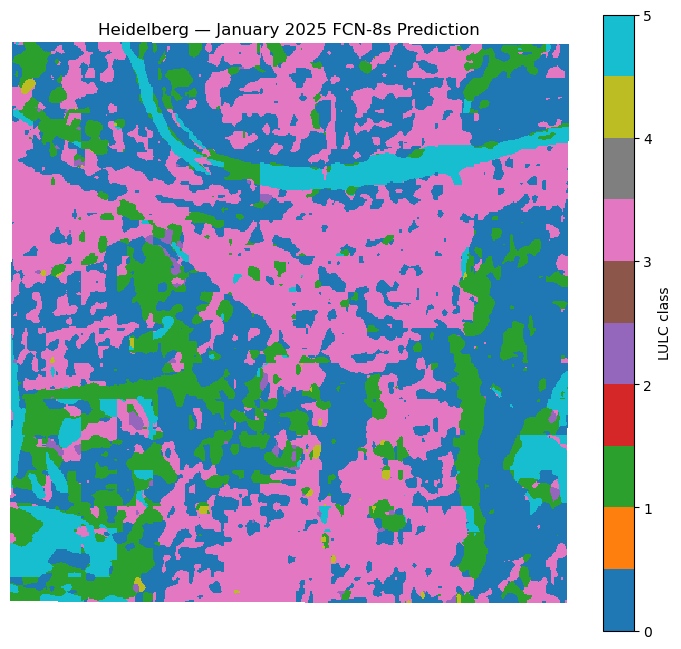


OUTPUT VERIFICATION
Saved file: outputs/monthly_maps/Heidelberg/heidelberg_2025_01_lulc.tif
Shape: (503, 501)
CRS: EPSG:32632
Transform: | 10.00, 0.00, 473730.00|
| 0.00,-10.00, 5474360.00|
| 0.00, 0.00, 1.00|
NoData: 255.0
Data type: uint8

January pilot inference completed.


In [86]:
from pathlib import Path
import json
import numpy as np
import rasterio
import torch
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

SAR_DIR = Path("data/processed/sentinel1")
OUTPUT_DIR = Path("outputs/monthly_maps/Heidelberg")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NORM_FILE = Path("outputs/data_audit/sar_normalization.json")
MODEL_FILE = Path("models/fcn8s_best.pt")

PATCH_SIZE = 64
STRIDE = 32
BATCH_SIZE = 16
NUM_CLASSES = 6
NODATA_VALUE = 255

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

device = torch.device("cpu")

# --------------------------------------------------
# 2. Load normalization statistics
# --------------------------------------------------

with open(NORM_FILE, "r") as f:
    normalization = json.load(f)

mean = np.asarray(
    normalization["mean"],
    dtype=np.float32
).reshape(1, 1, 2)

std = np.asarray(
    normalization["std"],
    dtype=np.float32
).reshape(1, 1, 2)

print("Training normalization loaded.")
print("Mean:", mean.ravel())
print("Std:", std.ravel())

# --------------------------------------------------
# 3. Load trained FCN-8s
# --------------------------------------------------

checkpoint = torch.load(
    MODEL_FILE,
    map_location=device,
    weights_only=False
)

model = FCN8s(
    in_channels=2,
    num_classes=NUM_CLASSES,
    base=16
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("FCN-8s loaded. Best epoch:", checkpoint["epoch"])

# --------------------------------------------------
# 4. Helper: create overlapping window positions
# --------------------------------------------------

def get_window_starts(length, patch_size=64, stride=32):

    if length < patch_size:
        raise ValueError(
            f"Raster dimension {length} is smaller than patch size."
        )

    starts = list(
        range(0, length - patch_size + 1, stride)
    )

    final_start = length - patch_size

    if starts[-1] != final_start:
        starts.append(final_start)

    return starts

# --------------------------------------------------
# 5. Sliding-window prediction
# --------------------------------------------------

def predict_raster(input_path, output_path):

    with rasterio.open(input_path) as src:

        # Read VV and VH
        sar = src.read([1, 2])
        sar = np.moveaxis(sar, 0, -1)

        height, width, _ = sar.shape

        # Validity mask from both raster bands
        valid_mask = (
            (src.read_masks(1) > 0) &
            (src.read_masks(2) > 0) &
            np.isfinite(sar).all(axis=2)
        )

        # Normalize using training statistics
        normalized = (sar - mean) / std

        # Invalid values become zero in normalized space
        normalized[~valid_mask] = 0.0

        normalized = normalized.astype(np.float32)

        # Save original geospatial profile
        profile = src.profile.copy()

        # Window locations
        row_starts = get_window_starts(
            height,
            PATCH_SIZE,
            STRIDE
        )

        col_starts = get_window_starts(
            width,
            PATCH_SIZE,
            STRIDE
        )

        window_positions = [
            (row, col)
            for row in row_starts
            for col in col_starts
        ]

        print("\nInput:", input_path.name)
        print("Raster shape:", (height, width))
        print("Valid pixels:", f"{valid_mask.mean() * 100:.2f}%")
        print("Total windows:", len(window_positions))

        # Accumulate model logits from overlapping windows
        logit_sum = np.zeros(
            (NUM_CLASSES, height, width),
            dtype=np.float32
        )

        vote_count = np.zeros(
            (height, width),
            dtype=np.uint16
        )

        # Process windows in batches
        with torch.inference_mode():

            for start in range(
                0,
                len(window_positions),
                BATCH_SIZE
            ):

                batch_positions = window_positions[
                    start:start + BATCH_SIZE
                ]

                batch_patches = []

                for row, col in batch_positions:

                    patch = normalized[
                        row:row + PATCH_SIZE,
                        col:col + PATCH_SIZE,
                        :
                    ]

                    # HWC -> CHW
                    patch = np.moveaxis(patch, -1, 0)

                    batch_patches.append(patch)

                batch = torch.from_numpy(
                    np.stack(batch_patches)
                ).float().to(device)

                logits = model(batch).cpu().numpy()

                # Add predictions to the corresponding raster areas
                for index, (row, col) in enumerate(batch_positions):

                    logit_sum[
                        :,
                        row:row + PATCH_SIZE,
                        col:col + PATCH_SIZE
                    ] += logits[index]

                    vote_count[
                        row:row + PATCH_SIZE,
                        col:col + PATCH_SIZE
                    ] += 1

        # Verify complete window coverage
        if np.any(vote_count == 0):
            raise RuntimeError("Some raster pixels received no predictions.")

        # Average logits across overlapping predictions
        averaged_logits = (
            logit_sum /
            vote_count[np.newaxis, :, :]
        )

        # Final class prediction
        prediction = np.argmax(
            averaged_logits,
            axis=0
        ).astype(np.uint8)

        # Restore NoData pixels
        prediction[~valid_mask] = NODATA_VALUE

        # Update GeoTIFF profile
        profile.update(
            driver="GTiff",
            count=1,
            dtype="uint8",
            nodata=NODATA_VALUE,
            compress="deflate",
            BIGTIFF="IF_SAFER"
        )

        # Save georeferenced prediction
        with rasterio.open(output_path, "w", **profile) as dst:

            dst.write(prediction, 1)

            dst.set_band_description(
                1,
                "Predicted LULC class"
            )

            dst.update_tags(
                model="FCN-8s",
                input_bands="Sentinel-1 VV,VH",
                year="2025",
                patch_size=str(PATCH_SIZE),
                stride=str(STRIDE),
                normalization="training_set_z_score",
                class_mapping=(
                    "0=Tree;1=Grass;2=Crop;"
                    "3=Built;4=Bare;5=Water;255=NoData"
                )
            )

    return prediction, valid_mask


# --------------------------------------------------
# 6. Run January 2025 pilot inference
# --------------------------------------------------

input_path = (
    SAR_DIR /
    "Heidelberg" /
    "heidelberg_2025_01.tif"
)

output_path = (
    OUTPUT_DIR /
    "heidelberg_2025_01_lulc.tif"
)

prediction, valid_mask = predict_raster(
    input_path,
    output_path
)

# --------------------------------------------------
# 7. Calculate predicted class percentages
# --------------------------------------------------

valid_predictions = prediction[valid_mask]

print("\nJANUARY 2025 — PREDICTED CLASS DISTRIBUTION")
print("-" * 55)

for class_id, class_name in enumerate(CLASS_NAMES):

    count = np.sum(valid_predictions == class_id)

    percentage = (
        count / len(valid_predictions) * 100
    )

    print(
        f"{class_name:20s}: "
        f"{percentage:7.2f}% "
        f"({count:,} pixels)"
    )

# --------------------------------------------------
# 8. Visualise prediction
# --------------------------------------------------

plt.figure(figsize=(9, 8))

masked_prediction = np.ma.masked_where(
    prediction == NODATA_VALUE,
    prediction
)

plt.imshow(
    masked_prediction,
    cmap="tab10",
    vmin=0,
    vmax=5,
    interpolation="nearest"
)

plt.colorbar(
    ticks=range(NUM_CLASSES),
    label="LULC class"
)

plt.title("Heidelberg — January 2025 FCN-8s Prediction")
plt.axis("off")
plt.show()

# --------------------------------------------------
# 9. Verify saved GeoTIFF
# --------------------------------------------------

with rasterio.open(output_path) as result:

    print("\nOUTPUT VERIFICATION")
    print("Saved file:", output_path)
    print("Shape:", (result.height, result.width))
    print("CRS:", result.crs)
    print("Transform:", result.transform)
    print("NoData:", result.nodata)
    print("Data type:", result.dtypes[0])

print("\nJanuary pilot inference completed.")

In [87]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

SAR_DIR = Path("data/processed/sentinel1")
OUTPUT_ROOT = Path("outputs/monthly_maps")
STATS_DIR = Path("outputs/statistics")

STATS_DIR.mkdir(parents=True, exist_ok=True)

CITIES = ["Heidelberg", "Nairobi", "Sydney"]

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

NUM_CLASSES = 6

monthly_records = []
class_area_records = []

# --------------------------------------------------
# Process every city and month
# --------------------------------------------------

for city in CITIES:

    print(f"\n{'=' * 60}")
    print(f"PROCESSING CITY: {city}")
    print(f"{'=' * 60}")

    city_input_dir = SAR_DIR / city
    city_output_dir = OUTPUT_ROOT / city

    city_output_dir.mkdir(parents=True, exist_ok=True)

    input_files = sorted(city_input_dir.glob("*.tif"))

    if len(input_files) != 12:
        raise ValueError(
            f"{city}: Expected 12 monthly rasters, "
            f"found {len(input_files)}"
        )

    for input_path in input_files:

        output_path = (
            city_output_dir /
            f"{input_path.stem}_lulc.tif"
        )

        print(f"\nPredicting: {input_path.name}")

        # Generate prediction
        prediction, valid_mask = predict_raster(
            input_path,
            output_path
        )

        valid_predictions = prediction[valid_mask]

        valid_pixel_count = len(valid_predictions)

        # Pixel area from projected raster transform
        with rasterio.open(input_path) as src:

            pixel_area_m2 = abs(
                src.transform.a * src.transform.e
                - src.transform.b * src.transform.d
            )

        valid_area_ha = (
            valid_pixel_count * pixel_area_m2 / 10000
        )

        month = input_path.stem.split("_")[-1]

        # Calculate class statistics
        counts = np.bincount(
            valid_predictions,
            minlength=NUM_CLASSES
        )

        for class_id, class_name in enumerate(CLASS_NAMES):

            count = int(counts[class_id])

            percentage = (
                count / valid_pixel_count * 100
                if valid_pixel_count else 0
            )

            area_ha = count * pixel_area_m2 / 10000

            class_area_records.append({
                "City": city,
                "Month": month,
                "Class": class_name,
                "Pixel_Count": count,
                "Area_Hectares": area_ha,
                "Percentage": percentage
            })

        monthly_records.append({
            "City": city,
            "Month": month,
            "Valid_Pixels": valid_pixel_count,
            "Valid_Coverage_Percent": valid_mask.mean() * 100,
            "Total_Valid_Area_Hectares": valid_area_ha,
            "Prediction_File": str(output_path)
        })

        print("Saved:", output_path)
        print(f"Valid coverage: {valid_mask.mean() * 100:.2f}%")

# --------------------------------------------------
# Save monthly and class-wise statistics
# --------------------------------------------------

monthly_df = pd.DataFrame(monthly_records)
class_area_df = pd.DataFrame(class_area_records)

monthly_df.to_csv(
    STATS_DIR / "monthly_prediction_summary.csv",
    index=False
)

class_area_df.to_csv(
    STATS_DIR / "monthly_class_area_statistics.csv",
    index=False
)

# --------------------------------------------------
# Verification
# --------------------------------------------------

print("\n" + "=" * 60)
print("MONTHLY PREDICTION SUMMARY")
print("=" * 60)

print("Total monthly maps:", len(monthly_records))

display(
    monthly_df.groupby("City").agg(
        Monthly_Maps=("Month", "count"),
        Average_Valid_Coverage=("Valid_Coverage_Percent", "mean")
    ).round(2)
)

print("\nCLASS AREA STATISTICS")
display(class_area_df.head(12).round(3))

print("\nAll monthly prediction maps and statistics saved.")


PROCESSING CITY: Heidelberg

Predicting: heidelberg_2025_01.tif

Input: heidelberg_2025_01.tif
Raster shape: (503, 501)
Valid pixels: 99.21%
Total windows: 225
Saved: outputs/monthly_maps/Heidelberg/heidelberg_2025_01_lulc.tif
Valid coverage: 99.21%

Predicting: heidelberg_2025_02.tif

Input: heidelberg_2025_02.tif
Raster shape: (503, 501)
Valid pixels: 99.21%
Total windows: 225
Saved: outputs/monthly_maps/Heidelberg/heidelberg_2025_02_lulc.tif
Valid coverage: 99.21%

Predicting: heidelberg_2025_03.tif

Input: heidelberg_2025_03.tif
Raster shape: (503, 501)
Valid pixels: 99.21%
Total windows: 225
Saved: outputs/monthly_maps/Heidelberg/heidelberg_2025_03_lulc.tif
Valid coverage: 99.21%

Predicting: heidelberg_2025_04.tif

Input: heidelberg_2025_04.tif
Raster shape: (503, 501)
Valid pixels: 99.21%
Total windows: 225
Saved: outputs/monthly_maps/Heidelberg/heidelberg_2025_04_lulc.tif
Valid coverage: 99.21%

Predicting: heidelberg_2025_05.tif

Input: heidelberg_2025_05.tif
Raster shape: (5

,Monthly_Maps,Average_Valid_Coverage
City,,
Heidelberg,12,99.21
Nairobi,12,99.60
Sydney,12,96.28



CLASS AREA STATISTICS


,City,Month,Class,Pixel_Count,Area_Hectares,Percentage
0,Heidelberg,01,Tree cover,97788,977.88,39.114
1,Heidelberg,01,Grassland,39891,398.91,15.956
2,Heidelberg,01,Cropland,1460,14.60,0.584
3,Heidelberg,01,Built-up,93141,931.41,37.256
4,Heidelberg,01,Bare vegetation,706,7.06,0.282
5,Heidelberg,01,Permanent water,17019,170.19,6.807
6,Heidelberg,02,Tree cover,86118,861.18,34.447
7,Heidelberg,02,Grassland,35231,352.31,14.092
8,Heidelberg,02,Cropland,708,7.08,0.283
9,Heidelberg,02,Built-up,89998,899.98,35.998



All monthly prediction maps and statistics saved.



Processing changes for Heidelberg...
Common valid pixels: 250,005
Pixel area (ha): 0.01
January-to-December comparison completed.

Processing changes for Nairobi...
Common valid pixels: 248,004
Pixel area (ha): 0.01
January-to-December comparison completed.

Processing changes for Sydney...
Common valid pixels: 249,435
Pixel area (ha): 0.01
January-to-December comparison completed.

JANUARY TO DECEMBER — NET CLASS CHANGE


City,Heidelberg,Nairobi,Sydney
Class,,,
Bare vegetation,-0.132,-0.098,0.002
Built-up,-3.568,-2.387,0.926
Cropland,-0.378,-0.044,0.009
Grassland,-2.138,2.068,-0.273
Permanent water,5.974,0.533,-0.018
Tree cover,0.242,-0.073,-0.646



MONTH-TO-MONTH PIXEL CHANGE


,City,From_Month,To_Month,Changed_Pixels,Unchanged_Pixels,Changed_Pixel_Percentage
0,Heidelberg,01,02,53672,196333,21.468
1,Heidelberg,02,03,41579,208426,16.631
2,Heidelberg,03,04,41315,208690,16.526
3,Heidelberg,04,05,44238,205767,17.695
4,Heidelberg,05,06,39621,210384,15.848
5,Heidelberg,06,07,31313,218692,12.525
6,Heidelberg,07,08,26016,223989,10.406
7,Heidelberg,08,09,37712,212293,15.084
8,Heidelberg,09,10,41629,208376,16.651
9,Heidelberg,10,11,44202,205803,17.680


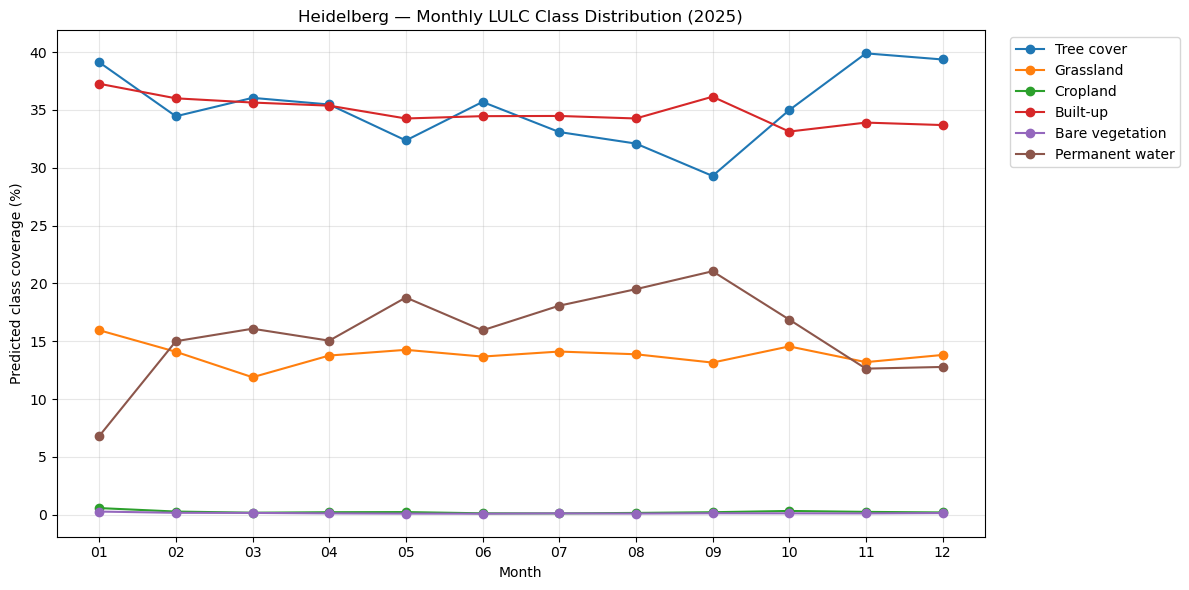

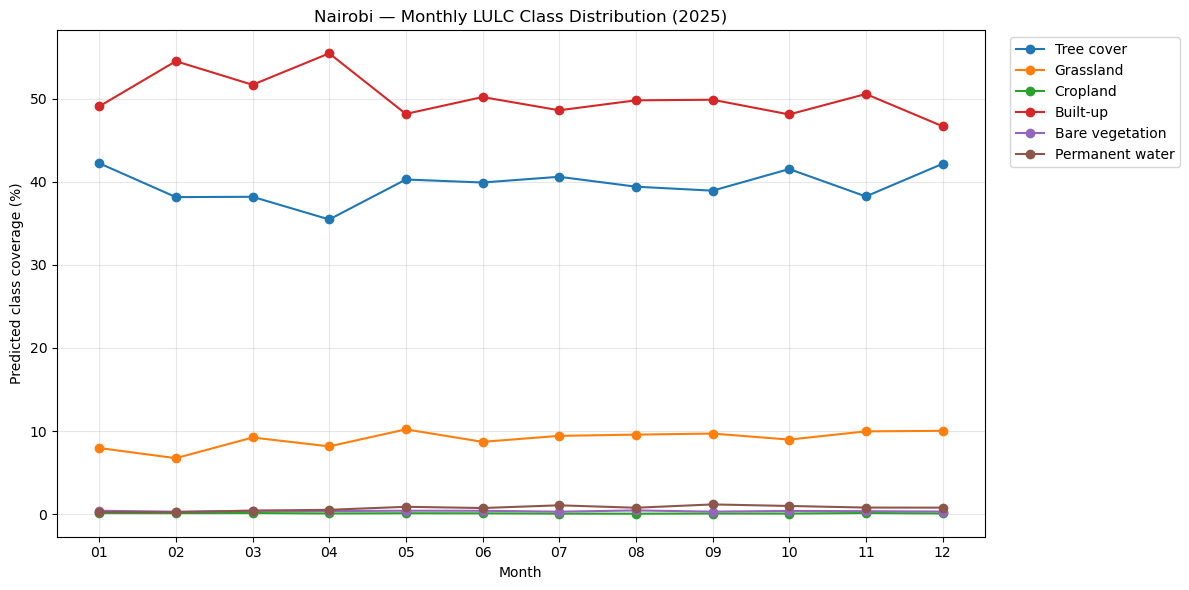

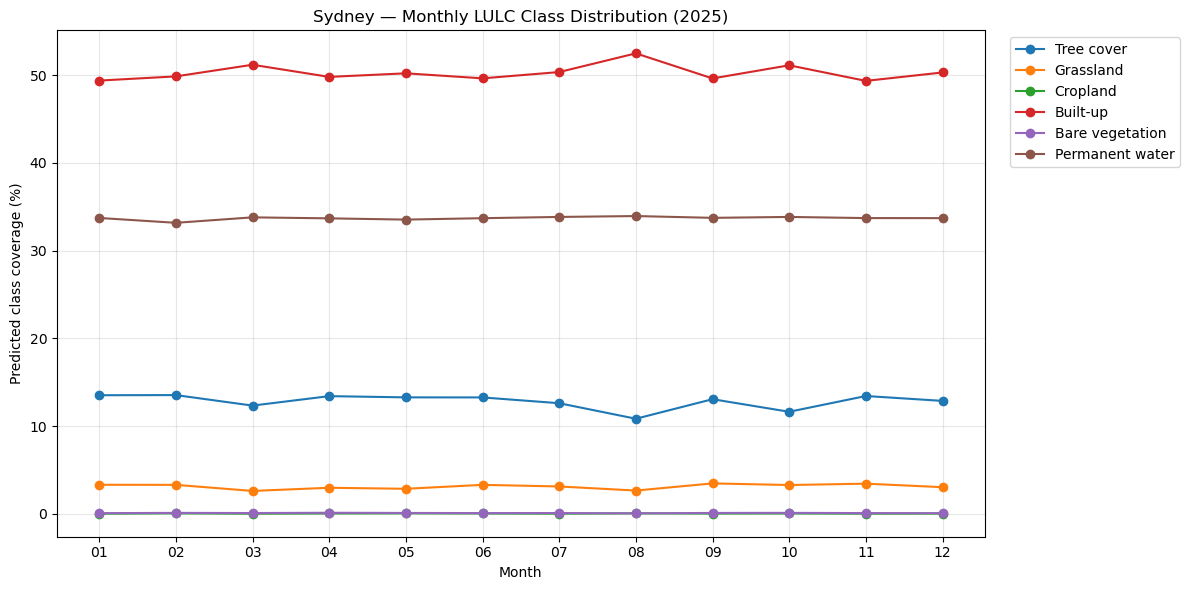


All monthly and annual change statistics saved.


In [88]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

MAP_DIR = Path("outputs/monthly_maps")
STATS_DIR = Path("outputs/statistics")

STATS_DIR.mkdir(parents=True, exist_ok=True)

CITIES = ["Heidelberg", "Nairobi", "Sydney"]

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

NUM_CLASSES = 6

monthly_records = []
change_records = []
annual_records = []
transition_records = []

# --------------------------------------------------
# 1. Process each city
# --------------------------------------------------

for city in CITIES:

    print(f"\nProcessing changes for {city}...")

    city_dir = MAP_DIR / city

    map_files = sorted(city_dir.glob("*_lulc.tif"))

    if len(map_files) != 12:
        raise ValueError(
            f"{city}: Expected 12 maps, found {len(map_files)}"
        )

    monthly_maps = []
    monthly_masks = []

    reference_profile = None
    pixel_area_ha = None

    # Load maps and verify alignment
    for map_file in map_files:

        with rasterio.open(map_file) as src:

            prediction = src.read(1)

            valid = (
                (src.read_masks(1) > 0) &
                (prediction != 255) &
                (prediction < NUM_CLASSES)
            )

            profile = (
                src.width,
                src.height,
                src.crs,
                src.transform
            )

            if reference_profile is None:
                reference_profile = profile

                pixel_area_ha = abs(
                    src.transform.a * src.transform.e
                    - src.transform.b * src.transform.d
                ) / 10000

            elif profile != reference_profile:
                raise ValueError(
                    f"Raster alignment mismatch in {city}: "
                    f"{map_file.name}"
                )

            monthly_maps.append(prediction)
            monthly_masks.append(valid)

    # --------------------------------------------------
    # 2. Create common valid-pixel mask
    # --------------------------------------------------

    common_mask = np.logical_and.reduce(monthly_masks)

    common_pixel_count = int(common_mask.sum())

    if common_pixel_count == 0:
        raise ValueError(f"No common valid pixels in {city}")

    print("Common valid pixels:", f"{common_pixel_count:,}")
    print("Pixel area (ha):", pixel_area_ha)

    # --------------------------------------------------
    # 3. Calculate monthly class percentages
    # --------------------------------------------------

    city_percentages = []

    for month_index, (map_file, prediction) in enumerate(
        zip(map_files, monthly_maps)
    ):

        month = f"{month_index + 1:02d}"

        values = prediction[common_mask]

        counts = np.bincount(
            values.astype(np.int64),
            minlength=NUM_CLASSES
        )

        percentages = counts / common_pixel_count * 100

        city_percentages.append(percentages)

        for class_id, class_name in enumerate(CLASS_NAMES):

            monthly_records.append({
                "City": city,
                "Month": month,
                "Class": class_name,
                "Pixel_Count": int(counts[class_id]),
                "Area_Hectares": (
                    counts[class_id] * pixel_area_ha
                ),
                "Percentage": percentages[class_id]
            })

    city_percentages = np.asarray(city_percentages)

    # --------------------------------------------------
    # 4. Month-to-month percentage-point changes
    # --------------------------------------------------

    for month_index in range(1, 12):

        previous = city_percentages[month_index - 1]
        current = city_percentages[month_index]

        difference = current - previous

        for class_id, class_name in enumerate(CLASS_NAMES):

            change_records.append({
                "City": city,
                "From_Month": f"{month_index:02d}",
                "To_Month": f"{month_index + 1:02d}",
                "Class": class_name,
                "Previous_Percentage": previous[class_id],
                "Current_Percentage": current[class_id],
                "Change_Percentage_Points": difference[class_id]
            })

        # Actual pixel-level prediction transitions
        previous_map = monthly_maps[month_index - 1][common_mask]
        current_map = monthly_maps[month_index][common_mask]

        changed = previous_map != current_map

        changed_count = int(changed.sum())

        transition_records.append({
            "City": city,
            "From_Month": f"{month_index:02d}",
            "To_Month": f"{month_index + 1:02d}",
            "Changed_Pixels": changed_count,
            "Unchanged_Pixels": int(common_pixel_count - changed_count),
            "Changed_Pixel_Percentage": (
                changed_count / common_pixel_count * 100
            )
        })

    # --------------------------------------------------
    # 5. January-to-December total change
    # --------------------------------------------------

    jan = city_percentages[0]
    dec = city_percentages[-1]

    for class_id, class_name in enumerate(CLASS_NAMES):

        annual_records.append({
            "City": city,
            "Class": class_name,
            "January_Percentage": jan[class_id],
            "December_Percentage": dec[class_id],
            "Net_Change_Percentage_Points": (
                dec[class_id] - jan[class_id]
            ),
            "Net_Area_Change_Hectares": (
                (dec[class_id] - jan[class_id])
                / 100 * common_pixel_count * pixel_area_ha
            )
        })

    print("January-to-December comparison completed.")

# --------------------------------------------------
# 6. Save all tables
# --------------------------------------------------

monthly_df = pd.DataFrame(monthly_records)
change_df = pd.DataFrame(change_records)
annual_df = pd.DataFrame(annual_records)
transition_df = pd.DataFrame(transition_records)

monthly_df.to_csv(
    STATS_DIR / "common_mask_monthly_class_percentages.csv",
    index=False
)

change_df.to_csv(
    STATS_DIR / "month_to_month_class_change_pp.csv",
    index=False
)

annual_df.to_csv(
    STATS_DIR / "january_december_class_change.csv",
    index=False
)

transition_df.to_csv(
    STATS_DIR / "month_to_month_pixel_transitions.csv",
    index=False
)

# --------------------------------------------------
# 7. Display January-to-December changes
# --------------------------------------------------

print("\nJANUARY TO DECEMBER — NET CLASS CHANGE")
display(
    annual_df.pivot(
        index="Class",
        columns="City",
        values="Net_Change_Percentage_Points"
    ).round(3)
)

print("\nMONTH-TO-MONTH PIXEL CHANGE")
display(transition_df.round(3))

# --------------------------------------------------
# 8. Create monthly class percentage charts
# --------------------------------------------------

for city in CITIES:

    city_data = monthly_df[
        monthly_df["City"] == city
    ]

    pivot = city_data.pivot(
        index="Month",
        columns="Class",
        values="Percentage"
    )

    pivot = pivot.reindex(
        [f"{i:02d}" for i in range(1, 13)]
    )

    plt.figure(figsize=(12, 6))

    for class_name in CLASS_NAMES:
        plt.plot(
            pivot.index,
            pivot[class_name],
            marker="o",
            label=class_name
        )

    plt.title(
        f"{city} — Monthly LULC Class Distribution (2025)"
    )
    plt.xlabel("Month")
    plt.ylabel("Predicted class coverage (%)")
    plt.xticks(rotation=0)
    plt.grid(alpha=0.3)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()

    plt.savefig(
        STATS_DIR / f"{city.lower()}_monthly_lulc_trends.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

print("\nAll monthly and annual change statistics saved.")


Creating monthly visualisation: Heidelberg


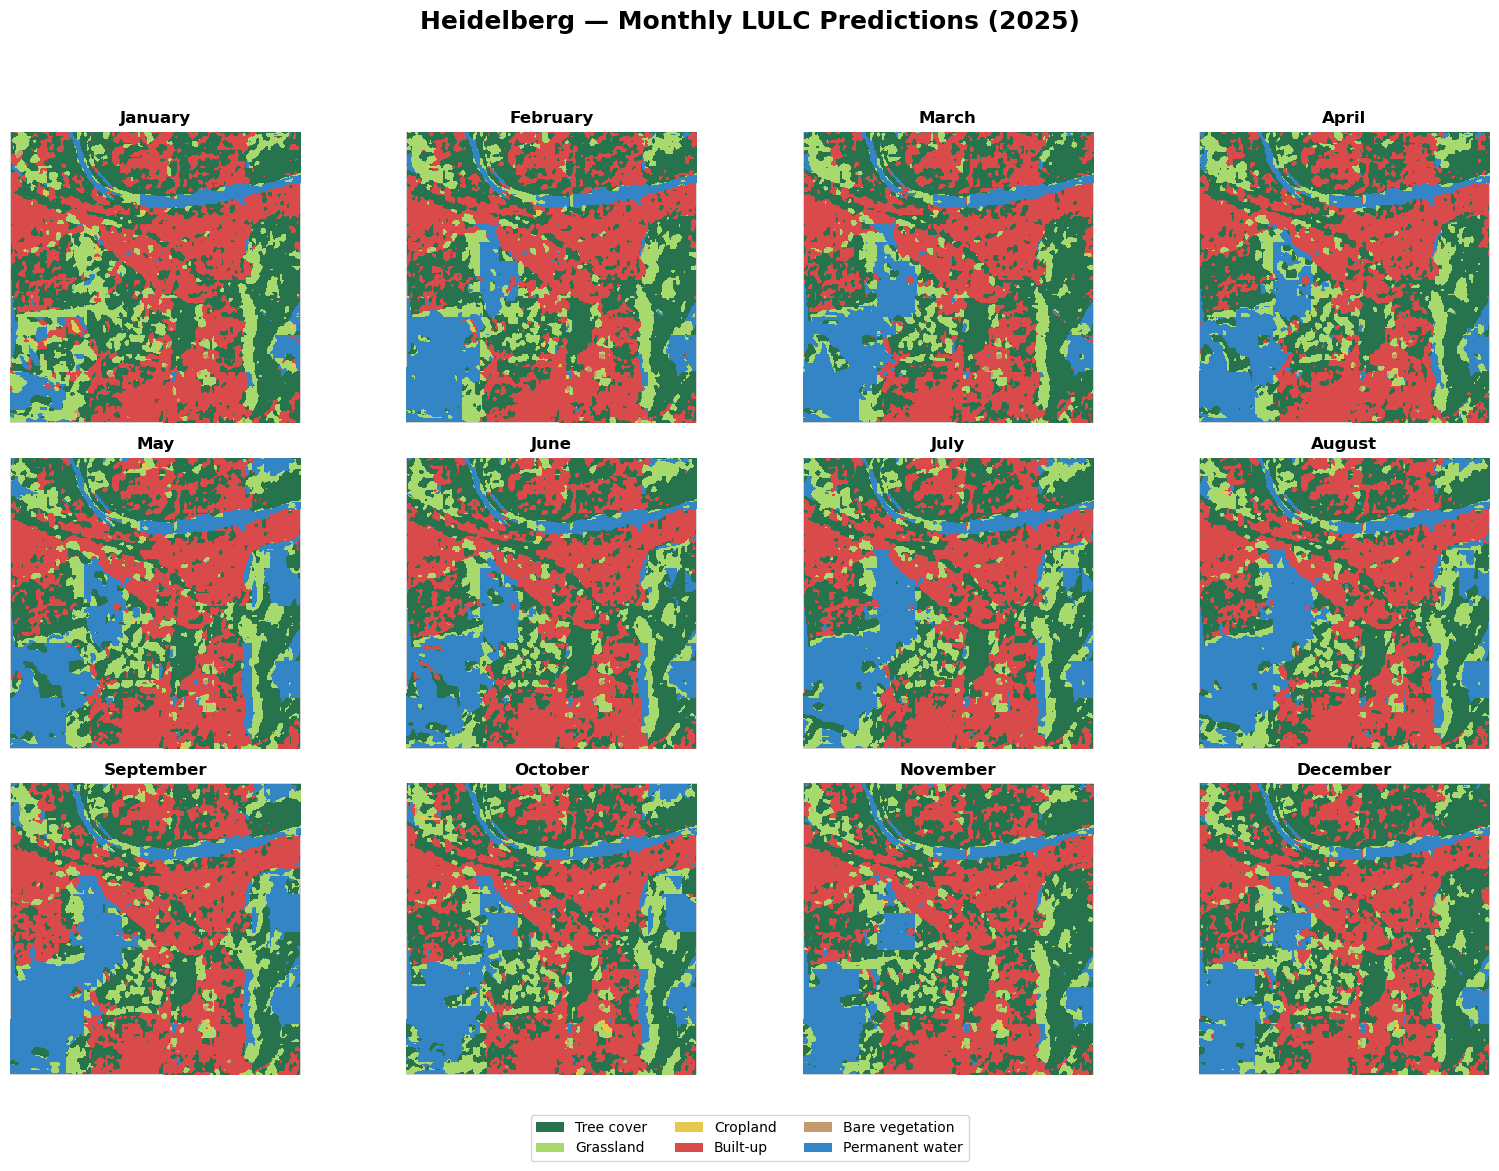

Saved: outputs/visualizations/monthly_maps/heidelberg_12_month_lulc_maps.png

Creating monthly visualisation: Nairobi


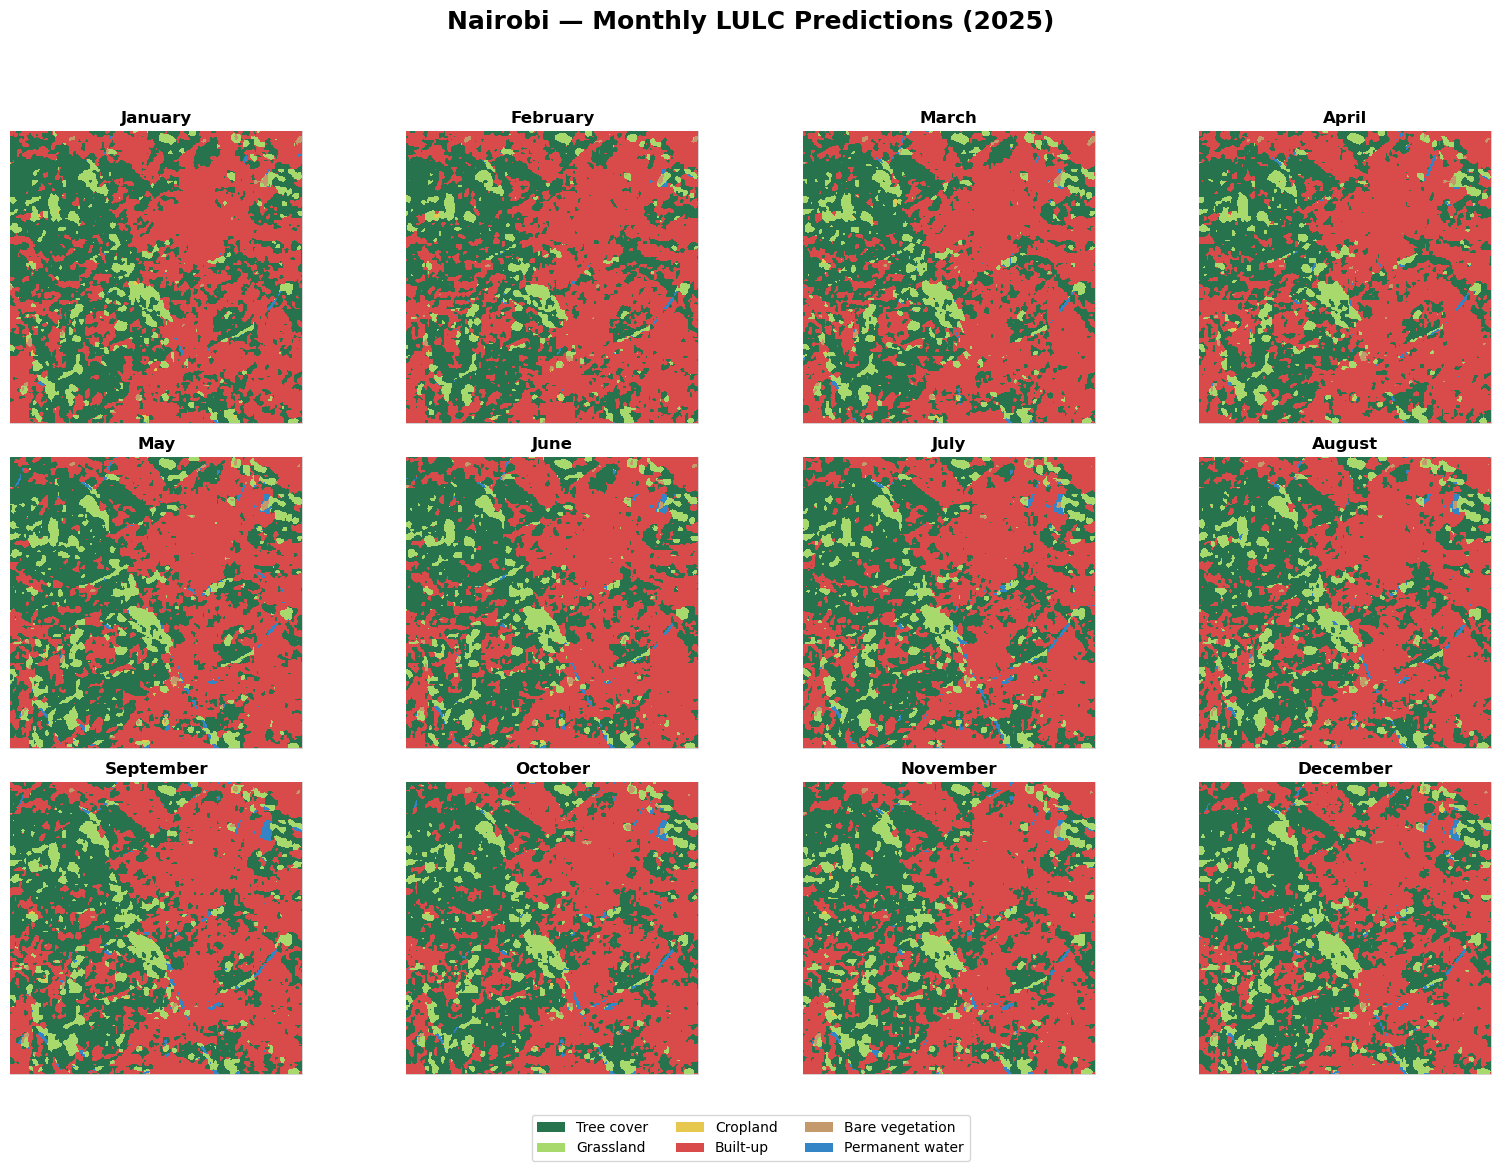

Saved: outputs/visualizations/monthly_maps/nairobi_12_month_lulc_maps.png

Creating monthly visualisation: Sydney


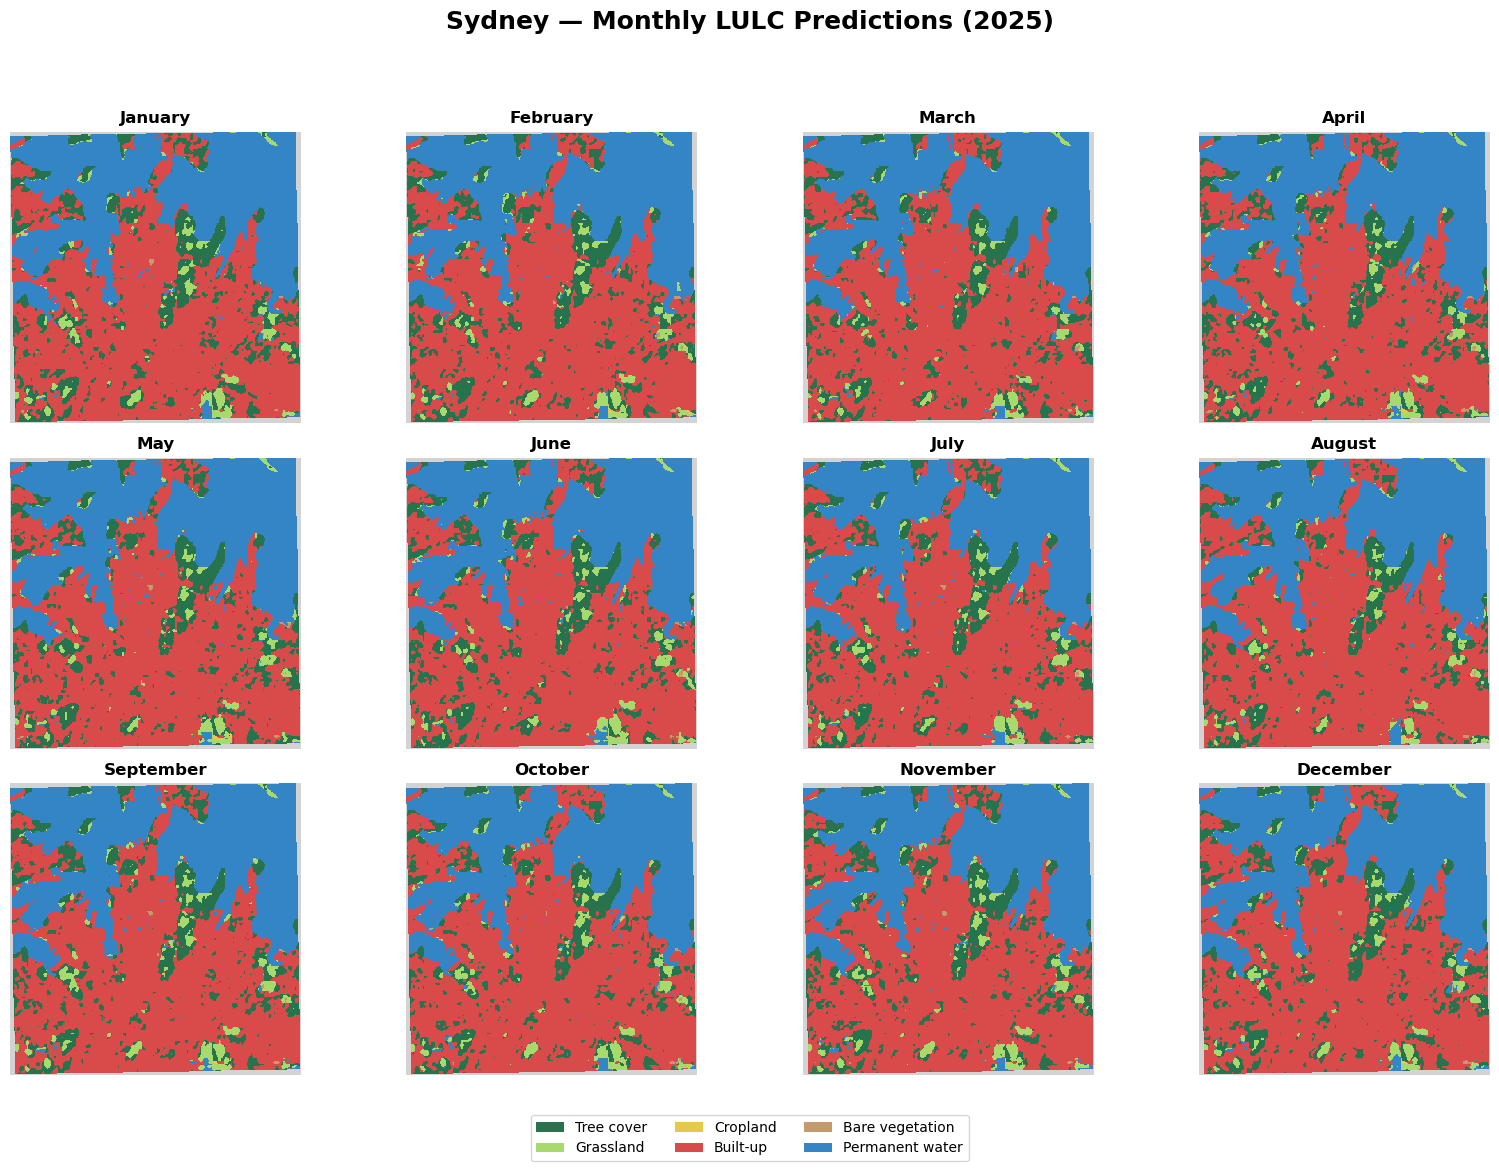

Saved: outputs/visualizations/monthly_maps/sydney_12_month_lulc_maps.png

All three 12-month visualisations created.


In [89]:
from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

MAP_DIR = Path("outputs/monthly_maps")
OUTPUT_DIR = Path("outputs/visualizations/monthly_maps")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CITIES = ["Heidelberg", "Nairobi", "Sydney"]

MONTH_NAMES = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

CLASS_COLORS = [
    "#26734D",
    "#A8D96C",
    "#E6C84F",
    "#D94A4A",
    "#C49A6C",
    "#3485C5"
]

NODATA_VALUE = 255

class_cmap = ListedColormap(CLASS_COLORS)
class_cmap.set_bad("lightgray")

class_norm = BoundaryNorm(
    np.arange(-0.5, 6.5, 1),
    class_cmap.N
)

legend_items = [
    Patch(
        facecolor=CLASS_COLORS[i],
        label=CLASS_NAMES[i]
    )
    for i in range(6)
]

# --------------------------------------------------
# 2. Generate 12-month map for every city
# --------------------------------------------------

for city in CITIES:

    print(f"\nCreating monthly visualisation: {city}")

    city_dir = MAP_DIR / city

    map_files = sorted(
        city_dir.glob("*_lulc.tif")
    )

    if len(map_files) != 12:
        raise ValueError(
            f"{city}: Expected 12 maps, found {len(map_files)}"
        )

    fig, axes = plt.subplots(
        3, 4,
        figsize=(16, 12)
    )

    for month_index, map_file in enumerate(map_files):

        row = month_index // 4
        col = month_index % 4

        ax = axes[row, col]

        with rasterio.open(map_file) as src:

            prediction = src.read(1)

            valid = (
                (src.read_masks(1) > 0) &
                (prediction != NODATA_VALUE)
            )

            masked_map = np.ma.masked_where(
                ~valid,
                prediction
            )

            ax.imshow(
                masked_map,
                cmap=class_cmap,
                norm=class_norm,
                interpolation="nearest"
            )

        ax.set_title(
            MONTH_NAMES[month_index],
            fontsize=12,
            fontweight="bold"
        )

        ax.axis("off")

    # --------------------------------------------------
    # 3. Add shared legend and title
    # --------------------------------------------------

    fig.suptitle(
        f"{city} — Monthly LULC Predictions (2025)",
        fontsize=18,
        fontweight="bold",
        y=0.98
    )

    fig.legend(
        handles=legend_items,
        loc="lower center",
        ncol=3,
        fontsize=10,
        bbox_to_anchor=(0.5, 0.015)
    )

    plt.tight_layout(
        rect=[0, 0.08, 1, 0.94]
    )

    output_file = (
        OUTPUT_DIR /
        f"{city.lower()}_12_month_lulc_maps.png"
    )

    plt.savefig(
        output_file,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_file)

print("\nAll three 12-month visualisations created.")

In [90]:
from pathlib import Path

# Project directory
PROJECT_ROOT = Path.cwd()

# Expected city folders
EXPECTED_CITIES = [
    "Berlin",
    "Munich",
    "Hamburg",
    "Bengaluru",
    "New_York",
    "Sao_Paulo",
    "Cairo",
    "Freiburg",
    "Singapore",
    "Heidelberg",
    "Nairobi",
    "Sydney"
]

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "sentinel1"
CHECKPOINT = PROJECT_ROOT / "models" / "fcn8s_best.pt"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "monthly_maps"

print("=" * 65)
print("SENTINEL-1 PROJECT DATA AUDIT")
print("=" * 65)

print("\nProject directory:", PROJECT_ROOT)
print("Processed data directory exists:", PROCESSED_DIR.exists())
print("FCN checkpoint exists:", CHECKPOINT.exists())
print("Monthly output directory exists:", OUTPUT_DIR.exists())
print("Prediction function available:", callable(globals().get("predict_raster")))

print("\n" + "=" * 65)
print("CITY-WISE MONTHLY IMAGE VERIFICATION")
print("=" * 65)

audit_results = []

for city in EXPECTED_CITIES:

    city_dir = PROCESSED_DIR / city

    if not city_dir.exists():
        print(f"\n{city}: CITY FOLDER NOT FOUND")
        audit_results.append({
            "City": city,
            "Folder Found": False,
            "TIFF Count": 0,
            "Expected Months": 12,
            "Missing Months": "All"
        })
        continue

    tif_files = sorted(
        list(city_dir.glob("*.tif")) +
        list(city_dir.glob("*.tiff"))
    )

    missing_months = []

    for month in range(1, 13):
        month_tag = f"2025_{month:02d}"

        found = any(
            month_tag in file.name
            for file in tif_files
        )

        if not found:
            missing_months.append(f"{month:02d}")

    print(f"\nCity: {city}")
    print("TIFF files found:", len(tif_files))
    print("Missing months:", missing_months if missing_months else "None")

    if tif_files:
        print("Example file:", tif_files[0].name)

    audit_results.append({
        "City": city,
        "Folder Found": True,
        "TIFF Count": len(tif_files),
        "Expected Months": 12,
        "Missing Months": (
            ", ".join(missing_months)
            if missing_months else "None"
        )
    })

import pandas as pd

audit_df = pd.DataFrame(audit_results)

print("\n" + "=" * 65)
print("FINAL AUDIT SUMMARY")
print("=" * 65)

display(audit_df)

print("\nTotal city folders:", audit_df["Folder Found"].sum())
print("Total TIFF files:", audit_df["TIFF Count"].sum())
print("Cities with all 12 months:", (
    audit_df["Missing Months"] == "None"
).sum())

SENTINEL-1 PROJECT DATA AUDIT

Project directory: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb
Processed data directory exists: True
FCN checkpoint exists: True
Monthly output directory exists: True
Prediction function available: True

CITY-WISE MONTHLY IMAGE VERIFICATION

City: Berlin
TIFF files found: 12
Missing months: None
Example file: berlin_2025_01.tif

City: Munich
TIFF files found: 12
Missing months: None
Example file: munich_2025_01.tif

City: Hamburg
TIFF files found: 12
Missing months: None
Example file: hamburg_2025_01.tif

City: Bengaluru
TIFF files found: 12
Missing months: None
Example file: bengaluru_2025_01.tif

New_York: CITY FOLDER NOT FOUND

Sao_Paulo: CITY FOLDER NOT FOUND

City: Cairo
TIFF files found: 12
Missing months: None
Example file: cairo_2025_01.tif

City: Freiburg
TIFF files found: 12
Missing months: None
Example file: freiburg_2025_01.tif

City: Singapore
TIFF files found: 12
Missing months: None
Example file: singapore_2025_01.tif

City: Heidelberg


,City,Folder Found,TIFF Count,Expected Months,Missing Months
0,Berlin,True,12,12,None
1,Munich,True,12,12,None
2,Hamburg,True,12,12,None
3,Bengaluru,True,12,12,None
4,New_York,False,0,12,All
5,Sao_Paulo,False,0,12,All
6,Cairo,True,12,12,None
7,Freiburg,True,12,12,None
8,Singapore,True,12,12,None
9,Heidelberg,True,12,12,None



Total city folders: 10
Total TIFF files: 120
Cities with all 12 months: 10


In [91]:
from pathlib import Path

# Project directory
PROJECT_ROOT = Path.cwd()

# Expected city folders
EXPECTED_CITIES = [
    "Berlin",
    "Munich",
    "Hamburg",
    "Bengaluru",
    "New_York",
    "Sao_Paulo",
    "Cairo",
    "Freiburg",
    "Singapore",
    "Heidelberg",
    "Nairobi",
    "Sydney"
]

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "sentinel1"
CHECKPOINT = PROJECT_ROOT / "models" / "fcn8s_best.pt"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "monthly_maps"

print("=" * 65)
print("SENTINEL-1 PROJECT DATA AUDIT")
print("=" * 65)

print("\nProject directory:", PROJECT_ROOT)
print("Processed data directory exists:", PROCESSED_DIR.exists())
print("FCN checkpoint exists:", CHECKPOINT.exists())
print("Monthly output directory exists:", OUTPUT_DIR.exists())
print("Prediction function available:", callable(globals().get("predict_raster")))

print("\n" + "=" * 65)
print("CITY-WISE MONTHLY IMAGE VERIFICATION")
print("=" * 65)

audit_results = []

for city in EXPECTED_CITIES:

    city_dir = PROCESSED_DIR / city

    if not city_dir.exists():
        print(f"\n{city}: CITY FOLDER NOT FOUND")
        audit_results.append({
            "City": city,
            "Folder Found": False,
            "TIFF Count": 0,
            "Expected Months": 12,
            "Missing Months": "All"
        })
        continue

    tif_files = sorted(
        list(city_dir.glob("*.tif")) +
        list(city_dir.glob("*.tiff"))
    )

    missing_months = []

    for month in range(1, 13):
        month_tag = f"2025_{month:02d}"

        found = any(
            month_tag in file.name
            for file in tif_files
        )

        if not found:
            missing_months.append(f"{month:02d}")

    print(f"\nCity: {city}")
    print("TIFF files found:", len(tif_files))
    print("Missing months:", missing_months if missing_months else "None")

    if tif_files:
        print("Example file:", tif_files[0].name)

    audit_results.append({
        "City": city,
        "Folder Found": True,
        "TIFF Count": len(tif_files),
        "Expected Months": 12,
        "Missing Months": (
            ", ".join(missing_months)
            if missing_months else "None"
        )
    })

import pandas as pd

audit_df = pd.DataFrame(audit_results)

print("\n" + "=" * 65)
print("FINAL AUDIT SUMMARY")
print("=" * 65)

display(audit_df)

print("\nTotal city folders:", audit_df["Folder Found"].sum())
print("Total TIFF files:", audit_df["TIFF Count"].sum())
print("Cities with all 12 months:", (
    audit_df["Missing Months"] == "None"
).sum())

SENTINEL-1 PROJECT DATA AUDIT

Project directory: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb
Processed data directory exists: True
FCN checkpoint exists: True
Monthly output directory exists: True
Prediction function available: True

CITY-WISE MONTHLY IMAGE VERIFICATION

City: Berlin
TIFF files found: 12
Missing months: None
Example file: berlin_2025_01.tif

City: Munich
TIFF files found: 12
Missing months: None
Example file: munich_2025_01.tif

City: Hamburg
TIFF files found: 12
Missing months: None
Example file: hamburg_2025_01.tif

City: Bengaluru
TIFF files found: 12
Missing months: None
Example file: bengaluru_2025_01.tif

New_York: CITY FOLDER NOT FOUND

Sao_Paulo: CITY FOLDER NOT FOUND

City: Cairo
TIFF files found: 12
Missing months: None
Example file: cairo_2025_01.tif

City: Freiburg
TIFF files found: 12
Missing months: None
Example file: freiburg_2025_01.tif

City: Singapore
TIFF files found: 12
Missing months: None
Example file: singapore_2025_01.tif

City: Heidelberg


,City,Folder Found,TIFF Count,Expected Months,Missing Months
0,Berlin,True,12,12,None
1,Munich,True,12,12,None
2,Hamburg,True,12,12,None
3,Bengaluru,True,12,12,None
4,New_York,False,0,12,All
5,Sao_Paulo,False,0,12,All
6,Cairo,True,12,12,None
7,Freiburg,True,12,12,None
8,Singapore,True,12,12,None
9,Heidelberg,True,12,12,None



Total city folders: 10
Total TIFF files: 120
Cities with all 12 months: 10


In [92]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

SEARCH_DIRS = {
    "RAW Sentinel-1": PROJECT_ROOT / "data" / "raw" / "sentinel1",
    "PROCESSED Sentinel-1": PROJECT_ROOT / "data" / "processed" / "sentinel1",
}

print("=" * 70)
print("SEARCHING FOR NEW YORK AND SAO PAULO DATA")
print("=" * 70)

for label, base_dir in SEARCH_DIRS.items():

    print(f"\n\n{label}")
    print("-" * 70)

    if not base_dir.exists():
        print("Directory not found:", base_dir)
        continue

    folders = sorted(
        p.name for p in base_dir.iterdir() if p.is_dir()
    )

    print("Available city folders:")
    for folder in folders:
        print("  -", folder)

    print("\nPossible New York / Sao Paulo matches:")

    matches = [
        p for p in base_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in [".tif", ".tiff"]
        and any(
            word in p.name.lower()
            for word in ["new", "york", "sao", "paulo"]
        )
    ]

    if matches:
        for file in matches[:30]:
            print("  -", file.relative_to(PROJECT_ROOT))
        if len(matches) > 30:
            print(f"  ... and {len(matches) - 30} more files")
    else:
        print("No matching TIFF files found.")

SEARCHING FOR NEW YORK AND SAO PAULO DATA


RAW Sentinel-1
----------------------------------------------------------------------
Available city folders:
  - Bengaluru
  - Berlin
  - Cairo
  - Freiburg
  - Hamburg
  - Heidelberg
  - Munich
  - Nairobi
  - New York
  - Sao Paulo
  - Singapore
  - Sydney

Possible New York / Sao Paulo matches:
  - data/raw/sentinel1/New York/new_york_2025_01.tif
  - data/raw/sentinel1/New York/new_york_2025_02.tif
  - data/raw/sentinel1/New York/new_york_2025_03.tif
  - data/raw/sentinel1/New York/new_york_2025_04.tif
  - data/raw/sentinel1/New York/new_york_2025_05.tif
  - data/raw/sentinel1/New York/new_york_2025_06.tif
  - data/raw/sentinel1/New York/new_york_2025_07.tif
  - data/raw/sentinel1/New York/new_york_2025_08.tif
  - data/raw/sentinel1/New York/new_york_2025_09.tif
  - data/raw/sentinel1/New York/new_york_2025_10.tif
  - data/raw/sentinel1/New York/new_york_2025_11.tif
  - data/raw/sentinel1/New York/new_york_2025_12.tif
  - data/raw/sentine

In [93]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "sentinel1"

CITIES = [
    "Berlin", "Munich", "Hamburg", "Bengaluru",
    "New York", "Sao Paulo", "Cairo", "Freiburg",
    "Singapore", "Heidelberg", "Nairobi", "Sydney"
]

audit_records = []
city_summary = []

for city in CITIES:

    city_folder = PROCESSED_DIR / city
    prefix = city.lower().replace(" ", "_")

    city_records = []
    grid_signatures = set()

    for month in range(1, 13):

        filename = f"{prefix}_2025_{month:02d}.tif"
        filepath = city_folder / filename

        record = {
            "City": city,
            "Month": month,
            "File": filename,
            "Exists": filepath.exists(),
            "Readable": False,
            "Bands": None,
            "Height": None,
            "Width": None,
            "CRS": None,
            "Resolution": None,
            "NoData": None,
            "Valid Coverage (%)": None,
            "Error": None
        }

        if not filepath.exists():
            record["Error"] = "File missing"
            audit_records.append(record)
            continue

        try:
            with rasterio.open(filepath) as src:

                data = src.read()

                valid_mask = (
                    (src.dataset_mask() > 0)
                    & np.all(np.isfinite(data), axis=0)
                )

                valid_percentage = (
                    valid_mask.sum() / valid_mask.size
                ) * 100

                record.update({
                    "Readable": True,
                    "Bands": src.count,
                    "Height": src.height,
                    "Width": src.width,
                    "CRS": str(src.crs),
                    "Resolution": str(src.res),
                    "NoData": src.nodata,
                    "Valid Coverage (%)": round(
                        valid_percentage, 3
                    )
                })

                grid_signature = (
                    src.height,
                    src.width,
                    src.count,
                    str(src.crs),
                    str(src.transform)
                )

                grid_signatures.add(grid_signature)

        except Exception as exc:
            record["Error"] = str(exc)

        audit_records.append(record)
        city_records.append(record)

    valid_records = [
        r for r in audit_records
        if r["City"] == city and r["Readable"]
    ]

    missing_count = sum(
        not r["Exists"] for r in [
            x for x in audit_records if x["City"] == city
        ]
    )

    errors = sum(
        not r["Readable"] for r in [
            x for x in audit_records if x["City"] == city
        ]
    )

    coverages = [
        r["Valid Coverage (%)"]
        for r in valid_records
        if r["Valid Coverage (%)"] is not None
    ]

    city_summary.append({
        "City": city,
        "Files Readable": len(valid_records),
        "Missing Files": missing_count,
        "Read Errors": errors,
        "Two Bands": all(
            r["Bands"] == 2 for r in valid_records
        ) and len(valid_records) == 12,
        "Consistent Monthly Grid": len(grid_signatures) == 1,
        "Minimum Valid Coverage (%)": (
            min(coverages) if coverages else None
        ),
        "Maximum Valid Coverage (%)": (
            max(coverages) if coverages else None
        )
    })

# Create audit dataframes
file_audit_df = pd.DataFrame(audit_records)
city_audit_df = pd.DataFrame(city_summary)

# Save audit reports
AUDIT_DIR = PROJECT_ROOT / "outputs" / "data_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

file_audit_df.to_csv(
    AUDIT_DIR / "processed_sentinel1_file_audit.csv",
    index=False
)

city_audit_df.to_csv(
    AUDIT_DIR / "processed_sentinel1_city_audit.csv",
    index=False
)

print("=" * 70)
print("PROCESSED SENTINEL-1 RASTER QUALITY AUDIT")
print("=" * 70)

display(city_audit_df)

print("\nTotal raster files checked:", len(file_audit_df))
print("Readable raster files:", file_audit_df["Readable"].sum())
print("Missing raster files:", (~file_audit_df["Exists"]).sum())
print("Raster read errors:", file_audit_df["Error"].notna().sum())

print("\nDetailed file audit:")
display(file_audit_df.head(15))

print("\nAudit reports saved in:", AUDIT_DIR)

PROCESSED SENTINEL-1 RASTER QUALITY AUDIT


,City,Files Readable,Missing Files,Read Errors,Two Bands,Consistent Monthly Grid,Minimum Valid Coverage (%),Maximum Valid Coverage (%)
0,Berlin,12,0,0,True,True,95.748,95.748
1,Munich,12,0,0,True,True,93.585,93.585
2,Hamburg,12,0,0,True,True,97.174,97.174
3,Bengaluru,12,0,0,True,True,97.737,97.737
4,New York,12,0,0,True,True,97.690,97.690
5,Sao Paulo,12,0,0,True,True,97.515,97.515
6,Cairo,12,0,0,True,True,96.850,96.850
7,Freiburg,12,0,0,True,True,96.991,96.991
8,Singapore,12,0,0,True,True,99.600,99.600
9,Heidelberg,12,0,0,True,True,99.207,99.207



Total raster files checked: 144
Readable raster files: 144
Missing raster files: 0
Raster read errors: 0

Detailed file audit:


,City,Month,File,Exists,Readable,Bands,Height,Width,CRS,Resolution,NoData,Valid Coverage (%),Error
0,Berlin,1,berlin_2025_01.tif,True,True,2,513,510,EPSG:32633,"(10.0, 10.0)",NaN,95.748,None
1,Berlin,2,berlin_2025_02.tif,True,True,2,513,510,EPSG:32633,"(10.0, 10.0)",NaN,95.748,None
2,Berlin,3,berlin_2025_03.tif,True,True,2,513,510,EPSG:32633,"(10.0, 10.0)",NaN,95.748,None
3,Berlin,4,berlin_2025_04.tif,True,True,2,513,510,EPSG:32633,"(10.0, 10.0)",NaN,95.748,None
4,Berlin,5,berlin_2025_05.tif,True,True,2,513,510,EPSG:32633,"(10.0, 10.0)",NaN,95.748,None
5,Berlin,6,berlin_2025_06.tif,True,True,2,513,510,EPSG:32633,"(10.0, 10.0)",NaN,95.748,None
6,Berlin,7,berlin_2025_07.tif,True,True,2,513,510,EPSG:32633,"(10.0, 10.0)",NaN,95.748,None
7,Berlin,8,berlin_2025_08.tif,True,True,2,513,510,EPSG:32633,"(10.0, 10.0)",NaN,95.748,None
8,Berlin,9,berlin_2025_09.tif,True,True,2,513,510,EPSG:32633,"(10.0, 10.0)",NaN,95.748,None
9,Berlin,10,berlin_2025_10.tif,True,True,2,513,510,EPSG:32633,"(10.0, 10.0)",NaN,95.748,None



Audit reports saved in: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/data_audit


In [94]:
%pip install rasterio

Note: you may need to restart the kernel to use updated packages.


In [95]:
from pathlib import Path
import torch
import json

PROJECT_ROOT = Path.cwd()

CHECKPOINT_PATH = PROJECT_ROOT / "models" / "fcn8s_best.pt"

NORMALIZATION_PATH = (
    PROJECT_ROOT / "outputs" /
    "data_audit" / "sar_normalization.json"
)

print("=" * 65)
print("FCN-8s MODEL CHECKPOINT INSPECTION")
print("=" * 65)

# 1. Check model checkpoint
print("\nCheckpoint exists:", CHECKPOINT_PATH.exists())

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(CHECKPOINT_PATH)

print(
    "Checkpoint size:",
    round(CHECKPOINT_PATH.stat().st_size / (1024 ** 2), 2),
    "MB"
)

# 2. Load saved checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print("Checkpoint keys:", list(checkpoint.keys()))

    state_dict = checkpoint.get("model_state_dict")

    if state_dict is None:
        raise KeyError(
            "model_state_dict not found. "
            "We need to inspect the checkpoint structure."
        )

    print("Training epoch:", checkpoint.get("epoch", "Not recorded"))

    print("\nModel parameter tensors:")

    for index, (name, tensor) in enumerate(state_dict.items()):

        print(name, tuple(tensor.shape))

        if index >= 19:
            print("...remaining tensors omitted")
            break

    print("\nTotal parameter tensors:", len(state_dict))

else:
    raise TypeError("Unexpected checkpoint format.")

# 3. Check model architecture in current notebook
print("\n" + "=" * 65)
print("NOTEBOOK MODEL FUNCTIONS")
print("=" * 65)

print("FCN8s class available:", callable(globals().get("FCN8s")))
print("UNet class available:", callable(globals().get("UNet")))
print("predict_raster available:", callable(globals().get("predict_raster")))

# 4. Check normalization statistics
print("\n" + "=" * 65)
print("TRAINING NORMALIZATION CHECK")
print("=" * 65)

print("Normalization file exists:", NORMALIZATION_PATH.exists())

if NORMALIZATION_PATH.exists():

    with open(NORMALIZATION_PATH, "r") as f:
        normalization = json.load(f)

    print(json.dumps(normalization, indent=4))

else:
    print("Normalization file not found.")

print("\nTorch version:", torch.__version__)
print("Inference device: CPU")

FCN-8s MODEL CHECKPOINT INSPECTION

Checkpoint exists: True
Checkpoint size: 12.31 MB

Checkpoint type: <class 'dict'>
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_miou', 'input_channels', 'num_classes', 'base_channels']
Training epoch: 4

Model parameter tensors:
block1.block.0.weight (16, 2, 3, 3)
block1.block.1.weight (16,)
block1.block.1.bias (16,)
block1.block.3.weight (16, 16, 3, 3)
block1.block.4.weight (16,)
block1.block.4.bias (16,)
block2.block.0.weight (32, 16, 3, 3)
block2.block.1.weight (32,)
block2.block.1.bias (32,)
block2.block.3.weight (32, 32, 3, 3)
block2.block.4.weight (32,)
block2.block.4.bias (32,)
block3.block.0.weight (64, 32, 3, 3)
block3.block.1.weight (64,)
block3.block.1.bias (64,)
block3.block.3.weight (64, 64, 3, 3)
block3.block.4.weight (64,)
block3.block.4.bias (64,)
block3.block.6.weight (64, 64, 3, 3)
block3.block.7.weight (64,)
...remaining tensors omitted

Total parameter tensors: 47

NOTEBOOK MODEL FUNCTIONS
FCN8s

In [96]:
%pip install torch --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.


In [97]:
import torch
from pathlib import Path

PROJECT_ROOT = Path.cwd()
CHECKPOINT_PATH = PROJECT_ROOT / "models" / "fcn8s_best.pt"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("=" * 75)
print("COMPLETE FCN-8s CHECKPOINT ARCHITECTURE INSPECTION")
print("=" * 75)

print("\nTraining metadata:")

for key in checkpoint:
    if key != "model_state_dict" and key != "optimizer_state_dict":
        print(f"{key}: {checkpoint[key]}")

print("\n" + "=" * 75)
print("ALL MODEL LAYERS AND PARAMETER SHAPES")
print("=" * 75)

state_dict = checkpoint["model_state_dict"]

for name, tensor in state_dict.items():
    print(f"{name:45s} {tuple(tensor.shape)}")

total_parameters = sum(
    tensor.numel()
    for tensor in state_dict.values()
)

print("\nTotal stored parameter elements:", total_parameters)

print("\n" + "=" * 75)
print("CHECKPOINT INSPECTION COMPLETED")
print("=" * 75)

COMPLETE FCN-8s CHECKPOINT ARCHITECTURE INSPECTION

Training metadata:
epoch: 4
best_val_miou: 0.3419418781861354
input_channels: 2
num_classes: 6
base_channels: 16

ALL MODEL LAYERS AND PARAMETER SHAPES
block1.block.0.weight                         (16, 2, 3, 3)
block1.block.1.weight                         (16,)
block1.block.1.bias                           (16,)
block1.block.3.weight                         (16, 16, 3, 3)
block1.block.4.weight                         (16,)
block1.block.4.bias                           (16,)
block2.block.0.weight                         (32, 16, 3, 3)
block2.block.1.weight                         (32,)
block2.block.1.bias                           (32,)
block2.block.3.weight                         (32, 32, 3, 3)
block2.block.4.weight                         (32,)
block2.block.4.bias                           (32,)
block3.block.0.weight                         (64, 32, 3, 3)
block3.block.1.weight                         (64,)
block3.block.1.bias     

In [98]:
from pathlib import Path
import json

ROOT = Path.cwd()

SEARCH_DIRS = [
    ROOT / "src",
    ROOT / "notebooks",
    ROOT / "models",
    ROOT / "configs"
]

KEYWORDS = [
    "class FCN8s",
    "class ConvBlock",
    "score_pool5",
    "class FCN"
]

print("=" * 70)
print("SEARCHING FOR ORIGINAL FCN-8s MODEL IMPLEMENTATION")
print("=" * 70)

found = []

for folder in SEARCH_DIRS:

    if not folder.exists():
        continue

    for filepath in folder.rglob("*"):

        if filepath.suffix == ".py":

            try:
                source = filepath.read_text(
                    encoding="utf-8",
                    errors="ignore"
                )
            except Exception:
                continue

            if any(keyword in source for keyword in KEYWORDS):
                found.append((filepath, source))

        elif filepath.suffix == ".ipynb":

            try:
                notebook = json.loads(
                    filepath.read_text(encoding="utf-8")
                )

                source = "\n".join(
                    "".join(cell.get("source", []))
                    for cell in notebook.get("cells", [])
                    if cell.get("cell_type") == "code"
                )

            except Exception:
                continue

            if any(keyword in source for keyword in KEYWORDS):
                found.append((filepath, source))


if found:

    for filepath, source in found:

        print("\nFOUND MODEL CODE:")
        print(filepath.relative_to(ROOT))

        lines = source.splitlines()

        matching_lines = [
            i for i, line in enumerate(lines)
            if any(keyword in line for keyword in KEYWORDS)
        ]

        shown_ranges = set()

        for index in matching_lines:

            start = max(0, index - 5)
            end = min(len(lines), index + 90)

            if any(
                start < previous_end and end > previous_start
                for previous_start, previous_end in shown_ranges
            ):
                continue

            shown_ranges.add((start, end))

            print("\n--- Relevant source code ---")

            for line_number in range(start, end):
                print(f"{line_number + 1:4}: {lines[line_number]}")

else:

    print("\nNo original model implementation found.")
    print("We will inspect the architecture from the checkpoint.")

print("\n" + "=" * 70)
print("MODEL SOURCE SEARCH COMPLETED")
print("=" * 70)

SEARCHING FOR ORIGINAL FCN-8s MODEL IMPLEMENTATION

No original model implementation found.
We will inspect the architecture from the checkpoint.

MODEL SOURCE SEARCH COMPLETED


In [99]:
from pathlib import Path

ROOT = Path.cwd()

KEYWORDS = [
    "score_pool3",
    "score_pool4",
    "score_pool5",
    "class FCN8s",
    "class ConvBlock"
]

EXCLUDE = {
    "data",
    "outputs",
    ".git",
    "__pycache__",
    ".venv",
    "venv"
}

print("=" * 70)
print("FULL PROJECT MODEL SOURCE SEARCH")
print("=" * 70)

extensions = {".py", ".ipynb", ".txt", ".md"}

matches = []

for filepath in ROOT.rglob("*"):

    if not filepath.is_file():
        continue

    if filepath.suffix.lower() not in extensions:
        continue

    if any(part in EXCLUDE for part in filepath.parts):
        continue

    try:
        content = filepath.read_text(
            encoding="utf-8",
            errors="ignore"
        )
    except Exception:
        continue

    found_keywords = [
        keyword for keyword in KEYWORDS
        if keyword in content
    ]

    if found_keywords:
        matches.append((filepath, found_keywords, content))

if matches:

    for filepath, keywords, content in matches:

        print("\nFILE:", filepath.relative_to(ROOT))
        print("Matching terms:", keywords)

        lines = content.splitlines()

        for i, line in enumerate(lines):

            if any(keyword in line for keyword in KEYWORDS):

                start = max(0, i - 3)
                end = min(len(lines), i + 35)

                print("\nRelevant code:")

                for j in range(start, end):
                    print(f"{j + 1:4}: {lines[j]}")

                break

else:
    print("\nNo original model source found in project files.")

print("\n" + "=" * 70)
print("SEARCH FINISHED")
print("=" * 70)

FULL PROJECT MODEL SOURCE SEARCH

FILE: Data.ipynb
Matching terms: ['score_pool3', 'score_pool4', 'score_pool5', 'class FCN8s', 'class ConvBlock']

Relevant code:
10948:     "# 2. Convolution block\n",
10949:     "# --------------------------------------------------\n",
10950:     "\n",
10951:     "class ConvBlock(nn.Module):\n",
10952:     "\n",
10953:     "    def __init__(self, in_channels, out_channels):\n",
10954:     "\n",
10955:     "        super().__init__()\n",
10956:     "\n",
10957:     "        groups = min(8, out_channels)\n",
10958:     "\n",
10959:     "        while out_channels % groups != 0:\n",
10960:     "            groups -= 1\n",
10961:     "\n",
10962:     "        self.block = nn.Sequential(\n",
10963:     "            nn.Conv2d(\n",
10964:     "                in_channels,\n",
10965:     "                out_channels,\n",
10966:     "                kernel_size=3,\n",
10967:     "                padding=1,\n",
10968:     "                bias=False\n",
10969:

In [100]:
import json
from pathlib import Path

ROOT = Path.cwd()
NOTEBOOK_PATH = ROOT / "Data.ipynb"

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(NOTEBOOK_PATH)

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("=" * 75)
print("ORIGINAL MODEL IMPLEMENTATION FROM DATA.IPYNB")
print("=" * 75)

found_cells = []

for index, cell in enumerate(notebook.get("cells", [])):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if (
        "class ConvBlock" in source
        or "class FCN8s" in source
        or "class FCN" in source
        or "score_pool5" in source
    ):
        found_cells.append((index, source))

if not found_cells:
    print("No model definition cells found.")

else:
    for index, source in found_cells:

        print(f"\n\n{'=' * 75}")
        print(f"NOTEBOOK CELL INDEX: {index}")
        print("=" * 75)

        print(source)

print("\n" + "=" * 75)
print("EXTRACTION COMPLETED")
print("=" * 75)

ORIGINAL MODEL IMPLEMENTATION FROM DATA.IPYNB


NOTEBOOK CELL INDEX: 48
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

INPUT_CHANNELS = 2
NUM_CLASSES = 6
BASE_CHANNELS = 16
PATCH_SIZE = 64

torch.manual_seed(42)
torch.set_num_threads(16)


# --------------------------------------------------
# 2. Convolution block
# --------------------------------------------------

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        groups = min(8, out_channels)

        while out_channels % groups != 0:
            groups -= 1

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.GroupNorm(

In [101]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

PROJECT_ROOT = Path.cwd()

CHECKPOINT_PATH = (
    PROJECT_ROOT / "models" / "fcn8s_best.pt"
)

INPUT_CHANNELS = 2
NUM_CLASSES = 6
BASE_CHANNELS = 16
PATCH_SIZE = 64

device = torch.device("cpu")

torch.set_num_threads(8)


# --------------------------------------------------
# 2. Original FCN convolution block
# --------------------------------------------------

class FCNConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels, num_convs=2):

        super().__init__()

        layers = []

        for i in range(num_convs):

            input_ch = in_channels if i == 0 else out_channels

            layers.extend([
                nn.Conv2d(
                    input_ch,
                    out_channels,
                    kernel_size=3,
                    padding=1,
                    bias=False
                ),
                nn.GroupNorm(8, out_channels),
                nn.ReLU(inplace=True)
            ])

        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


# --------------------------------------------------
# 3. Original FCN-8s architecture
# --------------------------------------------------

class FCN8s(nn.Module):

    def __init__(self, in_channels=2, num_classes=6, base=16):

        super().__init__()

        # Encoder
        self.block1 = FCNConvBlock(in_channels, base, 2)
        self.block2 = FCNConvBlock(base, base * 2, 2)
        self.block3 = FCNConvBlock(base * 2, base * 4, 3)
        self.block4 = FCNConvBlock(base * 4, base * 8, 3)
        self.block5 = FCNConvBlock(base * 8, base * 8, 3)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Classification scores
        self.score_pool3 = nn.Conv2d(
            base * 4, num_classes, kernel_size=1
        )

        self.score_pool4 = nn.Conv2d(
            base * 8, num_classes, kernel_size=1
        )

        self.score_pool5 = nn.Sequential(
            nn.Conv2d(
                base * 8, base * 8,
                kernel_size=3, padding=1
            ),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.1),
            nn.Conv2d(
                base * 8, num_classes, kernel_size=1
            )
        )

    def forward(self, x):

        original_size = x.shape[2:]

        # Encoder
        x = self.block1(x)
        x = self.pool(x)

        x = self.block2(x)
        x = self.pool(x)

        pool3 = self.block3(x)
        x = self.pool(pool3)

        pool4 = self.block4(x)
        x = self.pool(pool4)

        pool5 = self.block5(x)
        x = self.pool(pool5)

        # FCN-32 score
        score5 = self.score_pool5(pool5)

        # Fuse pool4
        score5_up = F.interpolate(
            score5,
            size=pool4.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        score4 = self.score_pool4(pool4)
        fuse4 = score5_up + score4

        # Fuse pool3
        fuse4_up = F.interpolate(
            fuse4,
            size=pool3.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        score3 = self.score_pool3(pool3)
        fuse3 = fuse4_up + score3

        # Restore original resolution
        output = F.interpolate(
            fuse3,
            size=original_size,
            mode="bilinear",
            align_corners=False
        )

        return output


# --------------------------------------------------
# 4. Initialise the original model
# --------------------------------------------------

fcn = FCN8s(
    in_channels=INPUT_CHANNELS,
    num_classes=NUM_CLASSES,
    base=BASE_CHANNELS
).to(device)


# --------------------------------------------------
# 5. Load original trained checkpoint
# --------------------------------------------------

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(CHECKPOINT_PATH)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

assert checkpoint["input_channels"] == INPUT_CHANNELS
assert checkpoint["num_classes"] == NUM_CLASSES
assert checkpoint["base_channels"] == BASE_CHANNELS

load_result = fcn.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

fcn.eval()


# --------------------------------------------------
# 6. Verify architecture and loaded weights
# --------------------------------------------------

total_parameters = sum(
    p.numel() for p in fcn.parameters()
)

dummy_input = torch.randn(
    2,
    INPUT_CHANNELS,
    PATCH_SIZE,
    PATCH_SIZE
)

with torch.inference_mode():
    dummy_output = fcn(dummy_input)

print("=" * 65)
print("FCN-8s MODEL RESTORATION REPORT")
print("=" * 65)

print("Checkpoint loaded successfully")
print("Strict weight loading: PASSED")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

print("\nTraining epoch:", checkpoint["epoch"])
print("Best validation mIoU:", checkpoint["best_val_miou"])

print("\nInput shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(dummy_output.shape))

print("Total parameters:", f"{total_parameters:,}")
print("Model device:", next(fcn.parameters()).device)

assert len(load_result.missing_keys) == 0
assert len(load_result.unexpected_keys) == 0
assert total_parameters == 1_071_218
assert dummy_output.shape == (2, 6, 64, 64)
assert torch.isfinite(dummy_output).all()

print("\nSUCCESS: Original trained FCN-8s restored.")

FCN-8s MODEL RESTORATION REPORT
Checkpoint loaded successfully
Strict weight loading: PASSED
Missing keys: []
Unexpected keys: []

Training epoch: 4
Best validation mIoU: 0.3419418781861354

Input shape: (2, 2, 64, 64)
Output shape: (2, 6, 64, 64)
Total parameters: 1,071,218
Model device: cpu

SUCCESS: Original trained FCN-8s restored.


In [102]:
import json
from pathlib import Path

ROOT = Path.cwd()
NOTEBOOK_PATH = ROOT / "Data.ipynb"

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("=" * 70)
print("SEARCHING FOR ORIGINAL RASTER INFERENCE FUNCTION")
print("=" * 70)

found = False

for index, cell in enumerate(notebook.get("cells", [])):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if "def predict_raster" in source:

        print(f"\nOriginal prediction function found in cell {index}")
        print("=" * 70)
        print(source)

        found = True

if not found:
    print("\nOriginal predict_raster function not found.")

print("\n" + "=" * 70)
print("INFERENCE SOURCE SEARCH COMPLETED")
print("=" * 70)

SEARCHING FOR ORIGINAL RASTER INFERENCE FUNCTION

Original prediction function found in cell 64
from pathlib import Path
import json
import numpy as np
import rasterio
import torch
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

SAR_DIR = Path("data/processed/sentinel1")
OUTPUT_DIR = Path("outputs/monthly_maps/Heidelberg")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NORM_FILE = Path("outputs/data_audit/sar_normalization.json")
MODEL_FILE = Path("models/fcn8s_best.pt")

PATCH_SIZE = 64
STRIDE = 32
BATCH_SIZE = 16
NUM_CLASSES = 6
NODATA_VALUE = 255

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

device = torch.device("cpu")

# --------------------------------------------------
# 2. Load normalization statistics
# --------------------------------------------------

with open(NORM_FILE, "r") as 

In [103]:
import json
import numpy as np
import rasterio
import torch

from pathlib import Path

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

ROOT = Path.cwd()

SAR_DIR = ROOT / "data" / "processed" / "sentinel1"

PILOT_DIR = (
    ROOT / "outputs" / "pilot_inference" / "Berlin"
)
PILOT_DIR.mkdir(parents=True, exist_ok=True)

NORM_FILE = (
    ROOT / "outputs" / "data_audit" / "sar_normalization.json"
)

PATCH_SIZE = 64
STRIDE = 32
BATCH_SIZE = 16
NUM_CLASSES = 6
NODATA_VALUE = 255

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

# Use the restored original trained model
model = fcn
model.eval()

device = torch.device("cpu")

# --------------------------------------------------
# 2. Load original training normalization
# --------------------------------------------------

with open(NORM_FILE, "r") as file:
    normalization = json.load(file)

mean = np.asarray(
    normalization["mean"],
    dtype=np.float32
).reshape(1, 1, 2)

std = np.asarray(
    normalization["std"],
    dtype=np.float32
).reshape(1, 1, 2)

assert np.all(std > 0)
assert len(mean.ravel()) == 2

print("Training normalization loaded.")
print("VV/VH mean:", mean.ravel())
print("VV/VH std:", std.ravel())

# --------------------------------------------------
# 3. Overlapping window positions
# --------------------------------------------------

def get_window_starts(length, patch_size=64, stride=32):

    if length < patch_size:
        raise ValueError(
            f"Raster dimension {length} is smaller than patch size."
        )

    starts = list(
        range(0, length - patch_size + 1, stride)
    )

    final_start = length - patch_size

    if starts[-1] != final_start:
        starts.append(final_start)

    return starts

# --------------------------------------------------
# 4. Original raster prediction function
# --------------------------------------------------

def predict_raster(input_path, output_path):

    input_path = Path(input_path)
    output_path = Path(output_path)

    with rasterio.open(input_path) as src:

        if src.count != 2:
            raise ValueError(
                f"Expected 2 bands, found {src.count}"
            )

        sar = src.read([1, 2])
        sar = np.moveaxis(sar, 0, -1)

        height, width, _ = sar.shape

        valid_mask = (
            (src.read_masks(1) > 0)
            & (src.read_masks(2) > 0)
            & np.isfinite(sar).all(axis=2)
        )

        normalized = (sar - mean) / std
        normalized[~valid_mask] = 0.0

        normalized = normalized.astype(np.float32)

        profile = src.profile.copy()

        row_starts = get_window_starts(
            height, PATCH_SIZE, STRIDE
        )

        col_starts = get_window_starts(
            width, PATCH_SIZE, STRIDE
        )

        window_positions = [
            (row, col)
            for row in row_starts
            for col in col_starts
        ]

        print("\nInput:", input_path.name)
        print("Raster dimensions:", (height, width))
        print(
            "Valid SAR coverage:",
            round(valid_mask.mean() * 100, 3),
            "%"
        )
        print("Prediction windows:", len(window_positions))

        logit_sum = np.zeros(
            (NUM_CLASSES, height, width),
            dtype=np.float32
        )

        vote_count = np.zeros(
            (height, width),
            dtype=np.uint16
        )

        with torch.inference_mode():

            for start in range(
                0, len(window_positions), BATCH_SIZE
            ):

                batch_positions = window_positions[
                    start:start + BATCH_SIZE
                ]

                batch_patches = []

                for row, col in batch_positions:

                    patch = normalized[
                        row:row + PATCH_SIZE,
                        col:col + PATCH_SIZE,
                        :
                    ]

                    patch = np.moveaxis(patch, -1, 0)
                    batch_patches.append(patch)

                batch = torch.from_numpy(
                    np.stack(batch_patches)
                ).float().to(device)

                logits = model(batch).cpu().numpy()

                for index, (row, col) in enumerate(batch_positions):

                    logit_sum[
                        :,
                        row:row + PATCH_SIZE,
                        col:col + PATCH_SIZE
                    ] += logits[index]

                    vote_count[
                        row:row + PATCH_SIZE,
                        col:col + PATCH_SIZE
                    ] += 1

        if np.any(vote_count == 0):
            raise RuntimeError(
                "Some pixels received no predictions."
            )

        averaged_logits = (
            logit_sum / vote_count[np.newaxis, :, :]
        )

        prediction = np.argmax(
            averaged_logits,
            axis=0
        ).astype(np.uint8)

        prediction[~valid_mask] = NODATA_VALUE

        profile.update(
            driver="GTiff",
            count=1,
            dtype="uint8",
            nodata=NODATA_VALUE,
            compress="deflate",
            BIGTIFF="IF_SAFER"
        )

        output_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        with rasterio.open(output_path, "w", **profile) as dst:

            dst.write(prediction, 1)

            dst.set_band_description(
                1,
                "Predicted LULC class"
            )

            dst.update_tags(
                model="FCN-8s-inspired",
                input_bands="Sentinel-1 VV,VH",
                year="2025",
                patch_size=str(PATCH_SIZE),
                stride=str(STRIDE),
                normalization="training_set_z_score",
                class_mapping=(
                    "0=Tree;1=Grass;2=Crop;"
                    "3=Built;4=Bare;5=Water;255=NoData"
                )
            )

    return prediction, valid_mask


# --------------------------------------------------
# 5. Berlin January pilot
# --------------------------------------------------

input_path = (
    SAR_DIR / "Berlin" / "berlin_2025_01.tif"
)

output_path = (
    PILOT_DIR / "berlin_2025_01_lulc_pilot.tif"
)

if not input_path.exists():
    raise FileNotFoundError(input_path)

prediction, valid_mask = predict_raster(
    input_path,
    output_path
)

# --------------------------------------------------
# 6. Class distribution
# --------------------------------------------------

valid_predictions = prediction[valid_mask]

print("\nBERLIN — JANUARY 2025 CLASS DISTRIBUTION")
print("=" * 60)

for class_id, class_name in enumerate(CLASS_NAMES):

    count = np.sum(valid_predictions == class_id)

    percentage = (
        count / len(valid_predictions) * 100
    )

    print(
        f"{class_id} | {class_name:20s} | "
        f"{percentage:7.3f}% | {count:,} pixels"
    )

# --------------------------------------------------
# 7. Verify output GeoTIFF
# --------------------------------------------------

with rasterio.open(output_path) as result:

    saved_prediction = result.read(1)

    assert result.count == 1
    assert result.dtypes[0] == "uint8"
    assert result.nodata == NODATA_VALUE
    assert result.crs is not None
    assert saved_prediction.shape == prediction.shape

    unique_classes = np.unique(saved_prediction)

    allowed_classes = set(range(6)) | {NODATA_VALUE}

    assert set(unique_classes).issubset(allowed_classes)

    print("\nOUTPUT QUALITY CHECK")
    print("=" * 60)

    print("Output file:", output_path)
    print("Dimensions:", result.height, "×", result.width)
    print("CRS:", result.crs)
    print("Resolution:", result.res)
    print("NoData:", result.nodata)
    print("Unique class values:", unique_classes)

print("\nSUCCESS: Berlin January pilot completed.")

Training normalization loaded.
VV/VH mean: [ -5.5103483 -12.706986 ]
VV/VH std: [5.4306297 5.2638855]

Input: berlin_2025_01.tif
Raster dimensions: (513, 510)
Valid SAR coverage: 95.748 %
Prediction windows: 240

BERLIN — JANUARY 2025 CLASS DISTRIBUTION
0 | Tree cover           |  28.445% | 71,255 pixels
1 | Grassland            |   2.586% | 6,477 pixels
2 | Cropland             |   0.012% | 29 pixels
3 | Built-up             |  66.968% | 167,757 pixels
4 | Bare vegetation      |   0.018% | 45 pixels
5 | Permanent water      |   1.973% | 4,942 pixels

OUTPUT QUALITY CHECK
Output file: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/pilot_inference/Berlin/berlin_2025_01_lulc_pilot.tif
Dimensions: 513 × 510
CRS: EPSG:32633
Resolution: (10.0, 10.0)
NoData: 255.0
Unique class values: [  0   1   2   3   4   5 255]

SUCCESS: Berlin January pilot completed.


In [104]:
import numpy as np
import pandas as pd
import rasterio

from pathlib import Path

ROOT = Path.cwd()

SAR_DIR = ROOT / "data" / "processed" / "sentinel1"

OUTPUT_DIR = (
    ROOT / "outputs" / "monthly_maps" / "Berlin"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

city_audit = []
class_statistics = []

print("=" * 70)
print("BERLIN — FULL YEAR 2025 LULC PREDICTION")
print("=" * 70)

for month in range(1, 13):

    month_tag = f"{month:02d}"

    input_path = (
        SAR_DIR / "Berlin" /
        f"berlin_2025_{month_tag}.tif"
    )

    output_path = (
        OUTPUT_DIR /
        f"berlin_2025_{month_tag}_lulc.tif"
    )

    print(f"\nProcessing month {month_tag}/12")

    if not input_path.exists():
        raise FileNotFoundError(input_path)

    # Generate prediction if it does not already exist
    if not output_path.exists():

        prediction, valid_mask = predict_raster(
            input_path,
            output_path
        )

    else:

        print("Existing output found. Verifying it without overwriting.")

        with rasterio.open(input_path) as src:
            source_valid_mask = (
                (src.read_masks(1) > 0) &
                (src.read_masks(2) > 0) &
                np.isfinite(
                    np.moveaxis(src.read([1, 2]), 0, -1)
                ).all(axis=2)
            )

        with rasterio.open(output_path) as result:
            prediction = result.read(1)

        valid_mask = source_valid_mask

    # Verify the input and output spatial properties
    with rasterio.open(input_path) as src, \
         rasterio.open(output_path) as result:

        assert result.count == 1
        assert result.dtypes[0] == "uint8"
        assert result.nodata == 255
        assert result.crs == src.crs
        assert result.transform == src.transform
        assert result.shape == src.shape

        saved_prediction = result.read(1)

        assert np.array_equal(
            saved_prediction == 255,
            ~valid_mask
        )

        valid_predictions = saved_prediction[valid_mask]

        assert len(valid_predictions) > 0
        assert np.isin(
            valid_predictions, range(6)
        ).all()

        pixel_area_m2 = abs(
            src.transform.a * src.transform.e
            - src.transform.b * src.transform.d
        )

        pixel_area_ha = pixel_area_m2 / 10000

        coverage = valid_mask.mean() * 100

        counts = np.bincount(
            valid_predictions,
            minlength=6
        )

        print("Output verified.")
        print("Valid coverage:", round(coverage, 3), "%")
        print("CRS:", result.crs)

        city_audit.append({
            "City": "Berlin",
            "Month": month,
            "Input File": input_path.name,
            "Output File": output_path.name,
            "Height": result.height,
            "Width": result.width,
            "CRS": str(result.crs),
            "Resolution": str(result.res),
            "Valid Coverage (%)": coverage,
            "Valid Pixels": len(valid_predictions),
            "Pixel Area (ha)": pixel_area_ha
        })

        for class_id, class_name in enumerate(CLASS_NAMES):

            count = int(counts[class_id])

            percentage = (
                count / len(valid_predictions) * 100
            )

            area_ha = count * pixel_area_ha

            class_statistics.append({
                "City": "Berlin",
                "Month": month,
                "Class ID": class_id,
                "Class": class_name,
                "Pixels": count,
                "Percentage": percentage,
                "Area (ha)": area_ha
            })

# Save monthly audit
audit_df = pd.DataFrame(city_audit)

stats_df = pd.DataFrame(class_statistics)

AUDIT_DIR = ROOT / "outputs" / "data_audit"
STAT_DIR = ROOT / "outputs" / "statistics"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
STAT_DIR.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(
    AUDIT_DIR / "berlin_monthly_inference_audit.csv",
    index=False
)

stats_df.to_csv(
    STAT_DIR / "berlin_monthly_class_statistics.csv",
    index=False
)

print("\n" + "=" * 70)
print("BERLIN YEARLY INFERENCE SUMMARY")
print("=" * 70)

print("Monthly maps verified:", len(audit_df))
print("Expected monthly maps: 12")
print("Total class-statistic records:", len(stats_df))

display(audit_df)

print("\nMonthly class statistics:")
display(stats_df.head(18))

print("\nAll reports saved successfully.")

BERLIN — FULL YEAR 2025 LULC PREDICTION

Processing month 01/12
Existing output found. Verifying it without overwriting.
Output verified.
Valid coverage: 95.748 %
CRS: EPSG:32633

Processing month 02/12
Existing output found. Verifying it without overwriting.
Output verified.
Valid coverage: 95.748 %
CRS: EPSG:32633

Processing month 03/12
Existing output found. Verifying it without overwriting.
Output verified.
Valid coverage: 95.748 %
CRS: EPSG:32633

Processing month 04/12
Existing output found. Verifying it without overwriting.
Output verified.
Valid coverage: 95.748 %
CRS: EPSG:32633

Processing month 05/12
Existing output found. Verifying it without overwriting.
Output verified.
Valid coverage: 95.748 %
CRS: EPSG:32633

Processing month 06/12
Existing output found. Verifying it without overwriting.
Output verified.
Valid coverage: 95.748 %
CRS: EPSG:32633

Processing month 07/12
Existing output found. Verifying it without overwriting.
Output verified.
Valid coverage: 95.748 %
CRS

,City,Month,Input File,Output File,Height,Width,CRS,Resolution,Valid Coverage (%),Valid Pixels,Pixel Area (ha)
0,Berlin,1,berlin_2025_01.tif,berlin_2025_01_lulc.tif,513,510,EPSG:32633,"(10.0, 10.0)",95.747812,250505,0.01
1,Berlin,2,berlin_2025_02.tif,berlin_2025_02_lulc.tif,513,510,EPSG:32633,"(10.0, 10.0)",95.747812,250505,0.01
2,Berlin,3,berlin_2025_03.tif,berlin_2025_03_lulc.tif,513,510,EPSG:32633,"(10.0, 10.0)",95.747812,250505,0.01
3,Berlin,4,berlin_2025_04.tif,berlin_2025_04_lulc.tif,513,510,EPSG:32633,"(10.0, 10.0)",95.747812,250505,0.01
4,Berlin,5,berlin_2025_05.tif,berlin_2025_05_lulc.tif,513,510,EPSG:32633,"(10.0, 10.0)",95.747812,250505,0.01
5,Berlin,6,berlin_2025_06.tif,berlin_2025_06_lulc.tif,513,510,EPSG:32633,"(10.0, 10.0)",95.747812,250505,0.01
6,Berlin,7,berlin_2025_07.tif,berlin_2025_07_lulc.tif,513,510,EPSG:32633,"(10.0, 10.0)",95.747812,250505,0.01
7,Berlin,8,berlin_2025_08.tif,berlin_2025_08_lulc.tif,513,510,EPSG:32633,"(10.0, 10.0)",95.747812,250505,0.01
8,Berlin,9,berlin_2025_09.tif,berlin_2025_09_lulc.tif,513,510,EPSG:32633,"(10.0, 10.0)",95.747812,250505,0.01
9,Berlin,10,berlin_2025_10.tif,berlin_2025_10_lulc.tif,513,510,EPSG:32633,"(10.0, 10.0)",95.747812,250505,0.01



Monthly class statistics:


,City,Month,Class ID,Class,Pixels,Percentage,Area (ha)
0,Berlin,1,0,Tree cover,71255,28.444542,712.55
1,Berlin,1,1,Grassland,6477,2.585577,64.77
2,Berlin,1,2,Cropland,29,0.011577,0.29
3,Berlin,1,3,Built-up,167757,66.967526,1677.57
4,Berlin,1,4,Bare vegetation,45,0.017964,0.45
5,Berlin,1,5,Permanent water,4942,1.972815,49.42
6,Berlin,2,0,Tree cover,69256,27.646554,692.56
7,Berlin,2,1,Grassland,7902,3.154428,79.02
8,Berlin,2,2,Cropland,1,0.000399,0.01
9,Berlin,2,3,Built-up,167951,67.044969,1679.51



All reports saved successfully.


In [105]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

ROOT = Path.cwd()

PILOT = (
    ROOT / "outputs" / "pilot_inference" /
    "Berlin" / "berlin_2025_01_lulc_pilot.tif"
)

FULL = (
    ROOT / "outputs" / "monthly_maps" /
    "Berlin" / "berlin_2025_01_lulc.tif"
)

AUDIT = (
    ROOT / "outputs" / "data_audit" /
    "berlin_monthly_inference_audit.csv"
)

STATS = (
    ROOT / "outputs" / "statistics" /
    "berlin_monthly_class_statistics.csv"
)

print("=" * 65)
print("BERLIN REPRODUCIBILITY AND OUTPUT VALIDATION")
print("=" * 65)

# 1. Compare pilot and full January prediction

with rasterio.open(PILOT) as src1, rasterio.open(FULL) as src2:

    pilot_map = src1.read(1)
    full_map = src2.read(1)

    assert pilot_map.shape == full_map.shape
    assert src1.crs == src2.crs
    assert src1.transform == src2.transform

    identical = np.array_equal(pilot_map, full_map)

    print("\nJanuary pilot/full prediction identical:", identical)

    print(
        "Different pixels:",
        int(np.count_nonzero(pilot_map != full_map))
    )

    assert identical, (
        "Predictions differ. Investigate before proceeding."
    )

# 2. Validate monthly audit

audit_df = pd.read_csv(AUDIT)

assert len(audit_df) == 12
assert audit_df["Month"].nunique() == 12
assert audit_df["Valid Coverage (%)"].between(0, 100).all()

print("\nMonthly audit records:", len(audit_df))
print("All 12 months recorded: PASSED")

# 3. Validate class statistics

stats_df = pd.read_csv(STATS)

assert len(stats_df) == 72
assert stats_df["Month"].nunique() == 12

records_per_month = stats_df.groupby("Month").size()

assert (records_per_month == 6).all()

percentage_sums = stats_df.groupby("Month")["Percentage"].sum()

print("\nClass-statistic records:", len(stats_df))
print("\nMonthly class percentage totals:")
display(percentage_sums.to_frame("Total percentage"))

assert np.allclose(
    percentage_sums.values,
    100.0,
    atol=0.01
)

print("\nAll 12 monthly class distributions sum to 100%.")

print("\n" + "=" * 65)
print("BERLIN VALIDATION COMPLETED SUCCESSFULLY")
print("=" * 65)

BERLIN REPRODUCIBILITY AND OUTPUT VALIDATION

January pilot/full prediction identical: True
Different pixels: 0

Monthly audit records: 12
All 12 months recorded: PASSED

Class-statistic records: 72

Monthly class percentage totals:


,Total percentage
Month,
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,100.0
7,100.0
8,100.0
9,100.0



All 12 monthly class distributions sum to 100%.

BERLIN VALIDATION COMPLETED SUCCESSFULLY


In [106]:
import numpy as np
import pandas as pd
import rasterio

from pathlib import Path

# Project paths
ROOT = Path.cwd()

SAR_DIR = ROOT / "data" / "processed" / "sentinel1"

CITY = "Munich"
PREFIX = "munich"

OUTPUT_DIR = ROOT / "outputs" / "monthly_maps" / CITY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

city_audit = []
class_statistics = []

print("=" * 70)
print("MUNICH — FULL YEAR 2025 LULC PREDICTION")
print("=" * 70)

for month in range(1, 13):

    month_tag = f"{month:02d}"

    input_path = (
        SAR_DIR / CITY /
        f"{PREFIX}_2025_{month_tag}.tif"
    )

    output_path = (
        OUTPUT_DIR /
        f"{PREFIX}_2025_{month_tag}_lulc.tif"
    )

    print(f"\nProcessing {CITY} — {month_tag}/12")

    if not input_path.exists():
        raise FileNotFoundError(input_path)

    # Generate map only when it does not already exist
    if not output_path.exists():

        prediction, valid_mask = predict_raster(
            input_path,
            output_path
        )

    else:
        print("Existing map found. Verifying without overwriting.")

        with rasterio.open(input_path) as src:
            source_data = src.read([1, 2])

            valid_mask = (
                (src.read_masks(1) > 0)
                & (src.read_masks(2) > 0)
                & np.isfinite(
                    np.moveaxis(source_data, 0, -1)
                ).all(axis=2)
            )

        with rasterio.open(output_path) as result:
            prediction = result.read(1)

    # Verify spatial and data integrity
    with rasterio.open(input_path) as src, \
         rasterio.open(output_path) as result:

        assert result.count == 1
        assert result.dtypes[0] == "uint8"
        assert result.nodata == 255
        assert result.crs == src.crs
        assert result.transform == src.transform
        assert result.shape == src.shape

        saved_prediction = result.read(1)

        assert np.array_equal(
            saved_prediction == 255,
            ~valid_mask
        )

        valid_predictions = saved_prediction[valid_mask]

        assert len(valid_predictions) > 0

        assert np.isin(
            valid_predictions,
            range(6)
        ).all()

        # Calculate pixel area using affine transformation
        pixel_area_m2 = abs(
            src.transform.a * src.transform.e
            - src.transform.b * src.transform.d
        )

        pixel_area_ha = pixel_area_m2 / 10000

        coverage = valid_mask.mean() * 100

        counts = np.bincount(
            valid_predictions,
            minlength=6
        )

        print("Output verified.")
        print("Valid coverage:", round(coverage, 3), "%")
        print("CRS:", result.crs)

        city_audit.append({
            "City": CITY,
            "Month": month,
            "Height": result.height,
            "Width": result.width,
            "CRS": str(result.crs),
            "Resolution": str(result.res),
            "Valid Coverage (%)": coverage,
            "Valid Pixels": len(valid_predictions)
        })

        for class_id, class_name in enumerate(CLASS_NAMES):

            count = int(counts[class_id])

            percentage = (
                count / len(valid_predictions) * 100
            )

            area_ha = count * pixel_area_ha

            class_statistics.append({
                "City": CITY,
                "Month": month,
                "Class ID": class_id,
                "Class": class_name,
                "Pixels": count,
                "Percentage": percentage,
                "Area (ha)": area_ha
            })

# Save audit and statistics
audit_df = pd.DataFrame(city_audit)
stats_df = pd.DataFrame(class_statistics)

AUDIT_DIR = ROOT / "outputs" / "data_audit"
STAT_DIR = ROOT / "outputs" / "statistics"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
STAT_DIR.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(
    AUDIT_DIR / "munich_monthly_inference_audit.csv",
    index=False
)

stats_df.to_csv(
    STAT_DIR / "munich_monthly_class_statistics.csv",
    index=False
)

# Final validation
assert len(audit_df) == 12
assert len(stats_df) == 72

monthly_percentage_totals = (
    stats_df.groupby("Month")["Percentage"].sum()
)

assert np.allclose(
    monthly_percentage_totals.values,
    100.0,
    atol=0.01
)

print("\n" + "=" * 70)
print("MUNICH INFERENCE SUMMARY")
print("=" * 70)

print("Monthly maps verified:", len(audit_df))
print("Class-statistic records:", len(stats_df))
print("Missing months:", 12 - len(audit_df))

display(audit_df)

print("\nMonthly class percentages:")
display(monthly_percentage_totals.to_frame("Total percentage"))

print("\nMUNICH PROCESSING COMPLETED SUCCESSFULLY.")

MUNICH — FULL YEAR 2025 LULC PREDICTION

Processing Munich — 01/12
Existing map found. Verifying without overwriting.
Output verified.
Valid coverage: 93.585 %
CRS: EPSG:32632

Processing Munich — 02/12
Existing map found. Verifying without overwriting.
Output verified.
Valid coverage: 93.585 %
CRS: EPSG:32632

Processing Munich — 03/12
Existing map found. Verifying without overwriting.
Output verified.
Valid coverage: 93.585 %
CRS: EPSG:32632

Processing Munich — 04/12
Existing map found. Verifying without overwriting.
Output verified.
Valid coverage: 93.585 %
CRS: EPSG:32632

Processing Munich — 05/12
Existing map found. Verifying without overwriting.
Output verified.
Valid coverage: 93.585 %
CRS: EPSG:32632

Processing Munich — 06/12
Existing map found. Verifying without overwriting.
Output verified.
Valid coverage: 93.585 %
CRS: EPSG:32632

Processing Munich — 07/12
Existing map found. Verifying without overwriting.
Output verified.
Valid coverage: 93.585 %
CRS: EPSG:32632

Process

,City,Month,Height,Width,CRS,Resolution,Valid Coverage (%),Valid Pixels
0,Munich,1,517,516,EPSG:32632,"(10.0, 10.0)",93.585159,249659
1,Munich,2,517,516,EPSG:32632,"(10.0, 10.0)",93.585159,249659
2,Munich,3,517,516,EPSG:32632,"(10.0, 10.0)",93.585159,249659
3,Munich,4,517,516,EPSG:32632,"(10.0, 10.0)",93.585159,249659
4,Munich,5,517,516,EPSG:32632,"(10.0, 10.0)",93.585159,249659
5,Munich,6,517,516,EPSG:32632,"(10.0, 10.0)",93.585159,249659
6,Munich,7,517,516,EPSG:32632,"(10.0, 10.0)",93.585159,249659
7,Munich,8,517,516,EPSG:32632,"(10.0, 10.0)",93.585159,249659
8,Munich,9,517,516,EPSG:32632,"(10.0, 10.0)",93.585159,249659
9,Munich,10,517,516,EPSG:32632,"(10.0, 10.0)",93.585159,249659



Monthly class percentages:


,Total percentage
Month,
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,100.0
7,100.0
8,100.0
9,100.0



MUNICH PROCESSING COMPLETED SUCCESSFULLY.


In [107]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

ROOT = Path.cwd()

SAR_DIR = ROOT / "data" / "processed" / "sentinel1"

CITY = "Hamburg"
PREFIX = "hamburg"

OUTPUT_DIR = ROOT / "outputs" / "monthly_maps" / CITY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

city_audit = []
class_statistics = []

print("=" * 70)
print("HAMBURG — FULL YEAR 2025 LULC PREDICTION")
print("=" * 70)

for month in range(1, 13):

    month_tag = f"{month:02d}"

    input_path = (
        SAR_DIR / CITY /
        f"{PREFIX}_2025_{month_tag}.tif"
    )

    output_path = (
        OUTPUT_DIR /
        f"{PREFIX}_2025_{month_tag}_lulc.tif"
    )

    print(f"\nProcessing Hamburg — {month_tag}/12")

    if not input_path.exists():
        raise FileNotFoundError(input_path)

    if not output_path.exists():

        prediction, valid_mask = predict_raster(
            input_path,
            output_path
        )

    else:
        print("Existing output found. Verifying without overwriting.")

        with rasterio.open(input_path) as src:

            source_data = src.read([1, 2])

            valid_mask = (
                (src.read_masks(1) > 0)
                & (src.read_masks(2) > 0)
                & np.isfinite(
                    np.moveaxis(source_data, 0, -1)
                ).all(axis=2)
            )

        with rasterio.open(output_path) as result:
            prediction = result.read(1)

    with rasterio.open(input_path) as src, \
         rasterio.open(output_path) as result:

        assert result.count == 1
        assert result.dtypes[0] == "uint8"
        assert result.nodata == 255
        assert result.crs == src.crs
        assert result.transform == src.transform
        assert result.shape == src.shape

        saved_prediction = result.read(1)

        assert np.array_equal(
            saved_prediction == 255,
            ~valid_mask
        )

        valid_predictions = saved_prediction[valid_mask]

        assert len(valid_predictions) > 0
        assert np.isin(valid_predictions, range(6)).all()

        pixel_area_m2 = abs(
            src.transform.a * src.transform.e
            - src.transform.b * src.transform.d
        )

        pixel_area_ha = pixel_area_m2 / 10000
        coverage = valid_mask.mean() * 100

        counts = np.bincount(
            valid_predictions,
            minlength=6
        )

        print("Output verified.")
        print("Valid coverage:", round(coverage, 3), "%")
        print("CRS:", result.crs)

        city_audit.append({
            "City": CITY,
            "Month": month,
            "Height": result.height,
            "Width": result.width,
            "CRS": str(result.crs),
            "Resolution": str(result.res),
            "Valid Coverage (%)": coverage,
            "Valid Pixels": len(valid_predictions)
        })

        for class_id, class_name in enumerate(CLASS_NAMES):

            count = int(counts[class_id])

            class_statistics.append({
                "City": CITY,
                "Month": month,
                "Class ID": class_id,
                "Class": class_name,
                "Pixels": count,
                "Percentage": count / len(valid_predictions) * 100,
                "Area (ha)": count * pixel_area_ha
            })

# Save results
audit_df = pd.DataFrame(city_audit)
stats_df = pd.DataFrame(class_statistics)

AUDIT_DIR = ROOT / "outputs" / "data_audit"
STAT_DIR = ROOT / "outputs" / "statistics"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
STAT_DIR.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(
    AUDIT_DIR / "hamburg_monthly_inference_audit.csv",
    index=False
)

stats_df.to_csv(
    STAT_DIR / "hamburg_monthly_class_statistics.csv",
    index=False
)

# Final checks
assert len(audit_df) == 12
assert len(stats_df) == 72

percentage_totals = stats_df.groupby("Month")["Percentage"].sum()

assert np.allclose(
    percentage_totals.values,
    100.0,
    atol=0.01
)

print("\n" + "=" * 70)
print("HAMBURG INFERENCE SUMMARY")
print("=" * 70)

print("Monthly maps verified:", len(audit_df))
print("Class-statistic records:", len(stats_df))
print("Missing months:", 12 - len(audit_df))

display(audit_df)

print("\nMonthly percentage totals:")
display(percentage_totals.to_frame("Total percentage"))

print("\nHAMBURG PROCESSING COMPLETED SUCCESSFULLY.")

HAMBURG — FULL YEAR 2025 LULC PREDICTION

Processing Hamburg — 01/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.174 %
CRS: EPSG:32632

Processing Hamburg — 02/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.174 %
CRS: EPSG:32632

Processing Hamburg — 03/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.174 %
CRS: EPSG:32632

Processing Hamburg — 04/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.174 %
CRS: EPSG:32632

Processing Hamburg — 05/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.174 %
CRS: EPSG:32632

Processing Hamburg — 06/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.174 %
CRS: EPSG:32632

Processing Hamburg — 07/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.1

,City,Month,Height,Width,CRS,Resolution,Valid Coverage (%),Valid Pixels
0,Hamburg,1,509,506,EPSG:32632,"(10.0, 10.0)",97.174185,250276
1,Hamburg,2,509,506,EPSG:32632,"(10.0, 10.0)",97.174185,250276
2,Hamburg,3,509,506,EPSG:32632,"(10.0, 10.0)",97.174185,250276
3,Hamburg,4,509,506,EPSG:32632,"(10.0, 10.0)",97.174185,250276
4,Hamburg,5,509,506,EPSG:32632,"(10.0, 10.0)",97.174185,250276
5,Hamburg,6,509,506,EPSG:32632,"(10.0, 10.0)",97.174185,250276
6,Hamburg,7,509,506,EPSG:32632,"(10.0, 10.0)",97.174185,250276
7,Hamburg,8,509,506,EPSG:32632,"(10.0, 10.0)",97.174185,250276
8,Hamburg,9,509,506,EPSG:32632,"(10.0, 10.0)",97.174185,250276
9,Hamburg,10,509,506,EPSG:32632,"(10.0, 10.0)",97.174185,250276



Monthly percentage totals:


,Total percentage
Month,
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,100.0
7,100.0
8,100.0
9,100.0



HAMBURG PROCESSING COMPLETED SUCCESSFULLY.


In [108]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

ROOT = Path.cwd()

SAR_DIR = ROOT / "data" / "processed" / "sentinel1"

CITY = "Bengaluru"
PREFIX = "bengaluru"

OUTPUT_DIR = ROOT / "outputs" / "monthly_maps" / CITY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

city_audit = []
class_statistics = []

print("=" * 70)
print("BENGALURU — FULL YEAR 2025 LULC PREDICTION")
print("=" * 70)

for month in range(1, 13):

    month_tag = f"{month:02d}"

    input_path = (
        SAR_DIR / CITY /
        f"{PREFIX}_2025_{month_tag}.tif"
    )

    output_path = (
        OUTPUT_DIR /
        f"{PREFIX}_2025_{month_tag}_lulc.tif"
    )

    print(f"\nProcessing Bengaluru — {month_tag}/12")

    if not input_path.exists():
        raise FileNotFoundError(input_path)

    if not output_path.exists():

        prediction, valid_mask = predict_raster(
            input_path,
            output_path
        )

    else:

        print("Existing output found. Verifying without overwriting.")

        with rasterio.open(input_path) as src:
            source_data = src.read([1, 2])

            valid_mask = (
                (src.read_masks(1) > 0)
                & (src.read_masks(2) > 0)
                & np.isfinite(
                    np.moveaxis(source_data, 0, -1)
                ).all(axis=2)
            )

        with rasterio.open(output_path) as result:
            prediction = result.read(1)

    with rasterio.open(input_path) as src, \
         rasterio.open(output_path) as result:

        assert result.count == 1
        assert result.dtypes[0] == "uint8"
        assert result.nodata == 255
        assert result.crs == src.crs
        assert result.transform == src.transform
        assert result.shape == src.shape

        saved_prediction = result.read(1)

        assert np.array_equal(
            saved_prediction == 255,
            ~valid_mask
        )

        valid_predictions = saved_prediction[valid_mask]

        assert len(valid_predictions) > 0
        assert np.isin(valid_predictions, range(6)).all()

        pixel_area_m2 = abs(
            src.transform.a * src.transform.e
            - src.transform.b * src.transform.d
        )

        pixel_area_ha = pixel_area_m2 / 10000
        coverage = valid_mask.mean() * 100

        counts = np.bincount(
            valid_predictions,
            minlength=6
        )

        print("Output verified.")
        print("Valid coverage:", round(coverage, 3), "%")
        print("CRS:", result.crs)

        city_audit.append({
            "City": CITY,
            "Month": month,
            "Height": result.height,
            "Width": result.width,
            "CRS": str(result.crs),
            "Resolution": str(result.res),
            "Valid Coverage (%)": coverage,
            "Valid Pixels": len(valid_predictions)
        })

        for class_id, class_name in enumerate(CLASS_NAMES):

            count = int(counts[class_id])

            class_statistics.append({
                "City": CITY,
                "Month": month,
                "Class ID": class_id,
                "Class": class_name,
                "Pixels": count,
                "Percentage": count / len(valid_predictions) * 100,
                "Area (ha)": count * pixel_area_ha
            })

# Save reports
audit_df = pd.DataFrame(city_audit)
stats_df = pd.DataFrame(class_statistics)

AUDIT_DIR = ROOT / "outputs" / "data_audit"
STAT_DIR = ROOT / "outputs" / "statistics"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
STAT_DIR.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(
    AUDIT_DIR / "bengaluru_monthly_inference_audit.csv",
    index=False
)

stats_df.to_csv(
    STAT_DIR / "bengaluru_monthly_class_statistics.csv",
    index=False
)

# Final validation
assert len(audit_df) == 12
assert len(stats_df) == 72

percentage_totals = (
    stats_df.groupby("Month")["Percentage"].sum()
)

assert np.allclose(
    percentage_totals.values,
    100.0,
    atol=0.01
)

print("\n" + "=" * 70)
print("BENGALURU INFERENCE SUMMARY")
print("=" * 70)

print("Monthly maps verified:", len(audit_df))
print("Class-statistic records:", len(stats_df))
print("Missing months:", 12 - len(audit_df))

display(audit_df)

print("\nMonthly percentage totals:")
display(percentage_totals.to_frame("Total percentage"))

print("\nBENGALURU PROCESSING COMPLETED SUCCESSFULLY.")

BENGALURU — FULL YEAR 2025 LULC PREDICTION

Processing Bengaluru — 01/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.737 %
CRS: EPSG:32643

Processing Bengaluru — 02/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.737 %
CRS: EPSG:32643

Processing Bengaluru — 03/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.737 %
CRS: EPSG:32643

Processing Bengaluru — 04/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.737 %
CRS: EPSG:32643

Processing Bengaluru — 05/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.737 %
CRS: EPSG:32643

Processing Bengaluru — 06/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.737 %
CRS: EPSG:32643

Processing Bengaluru — 07/12
Existing output found. Verifying without overwriting.
Output verified.
Vali

,City,Month,Height,Width,CRS,Resolution,Valid Coverage (%),Valid Pixels
0,Bengaluru,1,505,504,EPSG:32643,"(10.0, 10.0)",97.736524,248759
1,Bengaluru,2,505,504,EPSG:32643,"(10.0, 10.0)",97.736524,248759
2,Bengaluru,3,505,504,EPSG:32643,"(10.0, 10.0)",97.736524,248759
3,Bengaluru,4,505,504,EPSG:32643,"(10.0, 10.0)",97.736524,248759
4,Bengaluru,5,505,504,EPSG:32643,"(10.0, 10.0)",97.736524,248759
5,Bengaluru,6,505,504,EPSG:32643,"(10.0, 10.0)",97.736524,248759
6,Bengaluru,7,505,504,EPSG:32643,"(10.0, 10.0)",97.736524,248759
7,Bengaluru,8,505,504,EPSG:32643,"(10.0, 10.0)",97.736524,248759
8,Bengaluru,9,505,504,EPSG:32643,"(10.0, 10.0)",97.736524,248759
9,Bengaluru,10,505,504,EPSG:32643,"(10.0, 10.0)",97.736524,248759



Monthly percentage totals:


,Total percentage
Month,
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,100.0
7,100.0
8,100.0
9,100.0



BENGALURU PROCESSING COMPLETED SUCCESSFULLY.


In [109]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

ROOT = Path.cwd()

SAR_DIR = ROOT / "data" / "processed" / "sentinel1"

CITY = "New York"
PREFIX = "new_york"

OUTPUT_DIR = ROOT / "outputs" / "monthly_maps" / CITY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

city_audit = []
class_statistics = []

print("=" * 70)
print("NEW YORK — FULL YEAR 2025 LULC PREDICTION")
print("=" * 70)

for month in range(1, 13):

    month_tag = f"{month:02d}"

    input_path = (
        SAR_DIR / CITY /
        f"{PREFIX}_2025_{month_tag}.tif"
    )

    output_path = (
        OUTPUT_DIR /
        f"{PREFIX}_2025_{month_tag}_lulc.tif"
    )

    print(f"\nProcessing New York — {month_tag}/12")

    if not input_path.exists():
        raise FileNotFoundError(input_path)

    if not output_path.exists():

        prediction, valid_mask = predict_raster(
            input_path,
            output_path
        )

    else:

        print("Existing output found. Verifying without overwriting.")

        with rasterio.open(input_path) as src:

            source_data = src.read([1, 2])

            valid_mask = (
                (src.read_masks(1) > 0)
                & (src.read_masks(2) > 0)
                & np.isfinite(
                    np.moveaxis(source_data, 0, -1)
                ).all(axis=2)
            )

        with rasterio.open(output_path) as result:
            prediction = result.read(1)

    with rasterio.open(input_path) as src, \
         rasterio.open(output_path) as result:

        assert result.count == 1
        assert result.dtypes[0] == "uint8"
        assert result.nodata == 255
        assert result.crs == src.crs
        assert result.transform == src.transform
        assert result.shape == src.shape

        saved_prediction = result.read(1)

        assert np.array_equal(
            saved_prediction == 255,
            ~valid_mask
        )

        valid_predictions = saved_prediction[valid_mask]

        assert len(valid_predictions) > 0
        assert np.isin(valid_predictions, range(6)).all()

        pixel_area_m2 = abs(
            src.transform.a * src.transform.e
            - src.transform.b * src.transform.d
        )

        pixel_area_ha = pixel_area_m2 / 10000
        coverage = valid_mask.mean() * 100

        counts = np.bincount(
            valid_predictions,
            minlength=6
        )

        print("Output verified.")
        print("Valid coverage:", round(coverage, 3), "%")
        print("CRS:", result.crs)

        city_audit.append({
            "City": CITY,
            "Month": month,
            "Height": result.height,
            "Width": result.width,
            "CRS": str(result.crs),
            "Resolution": str(result.res),
            "Valid Coverage (%)": coverage,
            "Valid Pixels": len(valid_predictions)
        })

        for class_id, class_name in enumerate(CLASS_NAMES):

            count = int(counts[class_id])

            class_statistics.append({
                "City": CITY,
                "Month": month,
                "Class ID": class_id,
                "Class": class_name,
                "Pixels": count,
                "Percentage": count / len(valid_predictions) * 100,
                "Area (ha)": count * pixel_area_ha
            })

# Save audit and class statistics
audit_df = pd.DataFrame(city_audit)
stats_df = pd.DataFrame(class_statistics)

AUDIT_DIR = ROOT / "outputs" / "data_audit"
STAT_DIR = ROOT / "outputs" / "statistics"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
STAT_DIR.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(
    AUDIT_DIR / "new_york_monthly_inference_audit.csv",
    index=False
)

stats_df.to_csv(
    STAT_DIR / "new_york_monthly_class_statistics.csv",
    index=False
)

# Final validation
assert len(audit_df) == 12
assert len(stats_df) == 72

percentage_totals = (
    stats_df.groupby("Month")["Percentage"].sum()
)

assert np.allclose(
    percentage_totals.values,
    100.0,
    atol=0.01
)

print("\n" + "=" * 70)
print("NEW YORK INFERENCE SUMMARY")
print("=" * 70)

print("Monthly maps verified:", len(audit_df))
print("Class-statistic records:", len(stats_df))
print("Missing months:", 12 - len(audit_df))

display(audit_df)

print("\nMonthly percentage totals:")
display(percentage_totals.to_frame("Total percentage"))

print("\nNEW YORK PROCESSING COMPLETED SUCCESSFULLY.")

NEW YORK — FULL YEAR 2025 LULC PREDICTION

Processing New York — 01/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.69 %
CRS: EPSG:32618

Processing New York — 02/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.69 %
CRS: EPSG:32618

Processing New York — 03/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.69 %
CRS: EPSG:32618

Processing New York — 04/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.69 %
CRS: EPSG:32618

Processing New York — 05/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.69 %
CRS: EPSG:32618

Processing New York — 06/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.69 %
CRS: EPSG:32618

Processing New York — 07/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97

,City,Month,Height,Width,CRS,Resolution,Valid Coverage (%),Valid Pixels
0,New York,1,506,505,EPSG:32618,"(10.0, 10.0)",97.689508,249626
1,New York,2,506,505,EPSG:32618,"(10.0, 10.0)",97.689508,249626
2,New York,3,506,505,EPSG:32618,"(10.0, 10.0)",97.689508,249626
3,New York,4,506,505,EPSG:32618,"(10.0, 10.0)",97.689508,249626
4,New York,5,506,505,EPSG:32618,"(10.0, 10.0)",97.689508,249626
5,New York,6,506,505,EPSG:32618,"(10.0, 10.0)",97.689508,249626
6,New York,7,506,505,EPSG:32618,"(10.0, 10.0)",97.689508,249626
7,New York,8,506,505,EPSG:32618,"(10.0, 10.0)",97.689508,249626
8,New York,9,506,505,EPSG:32618,"(10.0, 10.0)",97.689508,249626
9,New York,10,506,505,EPSG:32618,"(10.0, 10.0)",97.689508,249626



Monthly percentage totals:


,Total percentage
Month,
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,100.0
7,100.0
8,100.0
9,100.0



NEW YORK PROCESSING COMPLETED SUCCESSFULLY.


In [110]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

ROOT = Path.cwd()

SAR_DIR = ROOT / "data" / "processed" / "sentinel1"

CITY = "Sao Paulo"
PREFIX = "sao_paulo"

OUTPUT_DIR = ROOT / "outputs" / "monthly_maps" / CITY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

city_audit = []
class_statistics = []

print("=" * 70)
print("SAO PAULO — FULL YEAR 2025 LULC PREDICTION")
print("=" * 70)

for month in range(1, 13):

    month_tag = f"{month:02d}"

    input_path = (
        SAR_DIR / CITY /
        f"{PREFIX}_2025_{month_tag}.tif"
    )

    output_path = (
        OUTPUT_DIR /
        f"{PREFIX}_2025_{month_tag}_lulc.tif"
    )

    print(f"\nProcessing Sao Paulo — {month_tag}/12")

    if not input_path.exists():
        raise FileNotFoundError(input_path)

    if not output_path.exists():

        prediction, valid_mask = predict_raster(
            input_path,
            output_path
        )

    else:

        print("Existing output found. Verifying without overwriting.")

        with rasterio.open(input_path) as src:
            source_data = src.read([1, 2])

            valid_mask = (
                (src.read_masks(1) > 0)
                & (src.read_masks(2) > 0)
                & np.isfinite(
                    np.moveaxis(source_data, 0, -1)
                ).all(axis=2)
            )

        with rasterio.open(output_path) as result:
            prediction = result.read(1)

    with rasterio.open(input_path) as src, \
         rasterio.open(output_path) as result:

        assert result.count == 1
        assert result.dtypes[0] == "uint8"
        assert result.nodata == 255
        assert result.crs == src.crs
        assert result.transform == src.transform
        assert result.shape == src.shape

        saved_prediction = result.read(1)

        assert np.array_equal(
            saved_prediction == 255,
            ~valid_mask
        )

        valid_predictions = saved_prediction[valid_mask]

        assert len(valid_predictions) > 0
        assert np.isin(valid_predictions, range(6)).all()

        pixel_area_m2 = abs(
            src.transform.a * src.transform.e
            - src.transform.b * src.transform.d
        )

        pixel_area_ha = pixel_area_m2 / 10000
        coverage = valid_mask.mean() * 100

        counts = np.bincount(
            valid_predictions,
            minlength=6
        )

        print("Output verified.")
        print("Valid coverage:", round(coverage, 3), "%")
        print("CRS:", result.crs)

        city_audit.append({
            "City": CITY,
            "Month": month,
            "Height": result.height,
            "Width": result.width,
            "CRS": str(result.crs),
            "Resolution": str(result.res),
            "Valid Coverage (%)": coverage,
            "Valid Pixels": len(valid_predictions)
        })

        for class_id, class_name in enumerate(CLASS_NAMES):

            count = int(counts[class_id])

            class_statistics.append({
                "City": CITY,
                "Month": month,
                "Class ID": class_id,
                "Class": class_name,
                "Pixels": count,
                "Percentage": count / len(valid_predictions) * 100,
                "Area (ha)": count * pixel_area_ha
            })

# Save reports
audit_df = pd.DataFrame(city_audit)
stats_df = pd.DataFrame(class_statistics)

AUDIT_DIR = ROOT / "outputs" / "data_audit"
STAT_DIR = ROOT / "outputs" / "statistics"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
STAT_DIR.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(
    AUDIT_DIR / "sao_paulo_monthly_inference_audit.csv",
    index=False
)

stats_df.to_csv(
    STAT_DIR / "sao_paulo_monthly_class_statistics.csv",
    index=False
)

# Final validation
assert len(audit_df) == 12
assert len(stats_df) == 72

percentage_totals = (
    stats_df.groupby("Month")["Percentage"].sum()
)

assert np.allclose(
    percentage_totals.values,
    100.0,
    atol=0.01
)

print("\n" + "=" * 70)
print("SAO PAULO INFERENCE SUMMARY")
print("=" * 70)

print("Monthly maps verified:", len(audit_df))
print("Class-statistic records:", len(stats_df))
print("Missing months:", 12 - len(audit_df))

display(audit_df)

print("\nMonthly percentage totals:")
display(percentage_totals.to_frame("Total percentage"))

print("\nSAO PAULO PROCESSING COMPLETED SUCCESSFULLY.")

SAO PAULO — FULL YEAR 2025 LULC PREDICTION

Processing Sao Paulo — 01/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.515 %
CRS: EPSG:32723

Processing Sao Paulo — 02/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.515 %
CRS: EPSG:32723

Processing Sao Paulo — 03/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.515 %
CRS: EPSG:32723

Processing Sao Paulo — 04/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.515 %
CRS: EPSG:32723

Processing Sao Paulo — 05/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.515 %
CRS: EPSG:32723

Processing Sao Paulo — 06/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 97.515 %
CRS: EPSG:32723

Processing Sao Paulo — 07/12
Existing output found. Verifying without overwriting.
Output verified.
Vali

,City,Month,Height,Width,CRS,Resolution,Valid Coverage (%),Valid Pixels
0,Sao Paulo,1,506,505,EPSG:32723,"(10.0, 10.0)",97.51536,249181
1,Sao Paulo,2,506,505,EPSG:32723,"(10.0, 10.0)",97.51536,249181
2,Sao Paulo,3,506,505,EPSG:32723,"(10.0, 10.0)",97.51536,249181
3,Sao Paulo,4,506,505,EPSG:32723,"(10.0, 10.0)",97.51536,249181
4,Sao Paulo,5,506,505,EPSG:32723,"(10.0, 10.0)",97.51536,249181
5,Sao Paulo,6,506,505,EPSG:32723,"(10.0, 10.0)",97.51536,249181
6,Sao Paulo,7,506,505,EPSG:32723,"(10.0, 10.0)",97.51536,249181
7,Sao Paulo,8,506,505,EPSG:32723,"(10.0, 10.0)",97.51536,249181
8,Sao Paulo,9,506,505,EPSG:32723,"(10.0, 10.0)",97.51536,249181
9,Sao Paulo,10,506,505,EPSG:32723,"(10.0, 10.0)",97.51536,249181



Monthly percentage totals:


,Total percentage
Month,
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,100.0
7,100.0
8,100.0
9,100.0



SAO PAULO PROCESSING COMPLETED SUCCESSFULLY.


In [111]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

ROOT = Path.cwd()

SAR_DIR = ROOT / "data" / "processed" / "sentinel1"

CITY = "Cairo"
PREFIX = "cairo"

OUTPUT_DIR = ROOT / "outputs" / "monthly_maps" / CITY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

city_audit = []
class_statistics = []

print("=" * 70)
print("CAIRO — FULL YEAR 2025 LULC PREDICTION")
print("=" * 70)

for month in range(1, 13):

    month_tag = f"{month:02d}"

    input_path = (
        SAR_DIR / CITY /
        f"{PREFIX}_2025_{month_tag}.tif"
    )

    output_path = (
        OUTPUT_DIR /
        f"{PREFIX}_2025_{month_tag}_lulc.tif"
    )

    print(f"\nProcessing Cairo — {month_tag}/12")

    if not input_path.exists():
        raise FileNotFoundError(input_path)

    if not output_path.exists():

        prediction, valid_mask = predict_raster(
            input_path,
            output_path
        )

    else:

        print("Existing output found. Verifying without overwriting.")

        with rasterio.open(input_path) as src:
            source_data = src.read([1, 2])

            valid_mask = (
                (src.read_masks(1) > 0)
                & (src.read_masks(2) > 0)
                & np.isfinite(
                    np.moveaxis(source_data, 0, -1)
                ).all(axis=2)
            )

        with rasterio.open(output_path) as result:
            prediction = result.read(1)

    with rasterio.open(input_path) as src, \
         rasterio.open(output_path) as result:

        assert result.count == 1
        assert result.dtypes[0] == "uint8"
        assert result.nodata == 255
        assert result.crs == src.crs
        assert result.transform == src.transform
        assert result.shape == src.shape

        saved_prediction = result.read(1)

        assert np.array_equal(
            saved_prediction == 255,
            ~valid_mask
        )

        valid_predictions = saved_prediction[valid_mask]

        assert len(valid_predictions) > 0
        assert np.isin(valid_predictions, range(6)).all()

        pixel_area_m2 = abs(
            src.transform.a * src.transform.e
            - src.transform.b * src.transform.d
        )

        pixel_area_ha = pixel_area_m2 / 10000
        coverage = valid_mask.mean() * 100

        counts = np.bincount(
            valid_predictions,
            minlength=6
        )

        print("Output verified.")
        print("Valid coverage:", round(coverage, 3), "%")
        print("CRS:", result.crs)

        city_audit.append({
            "City": CITY,
            "Month": month,
            "Height": result.height,
            "Width": result.width,
            "CRS": str(result.crs),
            "Resolution": str(result.res),
            "Valid Coverage (%)": coverage,
            "Valid Pixels": len(valid_predictions)
        })

        for class_id, class_name in enumerate(CLASS_NAMES):

            count = int(counts[class_id])

            class_statistics.append({
                "City": CITY,
                "Month": month,
                "Class ID": class_id,
                "Class": class_name,
                "Pixels": count,
                "Percentage": count / len(valid_predictions) * 100,
                "Area (ha)": count * pixel_area_ha
            })

# Save reports
audit_df = pd.DataFrame(city_audit)
stats_df = pd.DataFrame(class_statistics)

AUDIT_DIR = ROOT / "outputs" / "data_audit"
STAT_DIR = ROOT / "outputs" / "statistics"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
STAT_DIR.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(
    AUDIT_DIR / "cairo_monthly_inference_audit.csv",
    index=False
)

stats_df.to_csv(
    STAT_DIR / "cairo_monthly_class_statistics.csv",
    index=False
)

# Final validation
assert len(audit_df) == 12
assert len(stats_df) == 72

percentage_totals = (
    stats_df.groupby("Month")["Percentage"].sum()
)

assert np.allclose(
    percentage_totals.values,
    100.0,
    atol=0.01
)

print("\n" + "=" * 70)
print("CAIRO INFERENCE SUMMARY")
print("=" * 70)

print("Monthly maps verified:", len(audit_df))
print("Class-statistic records:", len(stats_df))
print("Missing months:", 12 - len(audit_df))

display(audit_df)

print("\nMonthly percentage totals:")
display(percentage_totals.to_frame("Total percentage"))

print("\nCAIRO PROCESSING COMPLETED SUCCESSFULLY.")

CAIRO — FULL YEAR 2025 LULC PREDICTION

Processing Cairo — 01/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.85 %
CRS: EPSG:32636

Processing Cairo — 02/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.85 %
CRS: EPSG:32636

Processing Cairo — 03/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.85 %
CRS: EPSG:32636

Processing Cairo — 04/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.85 %
CRS: EPSG:32636

Processing Cairo — 05/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.85 %
CRS: EPSG:32636

Processing Cairo — 06/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.85 %
CRS: EPSG:32636

Processing Cairo — 07/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.85 %
CRS: EPSG:32636

P

,City,Month,Height,Width,CRS,Resolution,Valid Coverage (%),Valid Pixels
0,Cairo,1,508,507,EPSG:32636,"(10.0, 10.0)",96.850394,249444
1,Cairo,2,508,507,EPSG:32636,"(10.0, 10.0)",96.850394,249444
2,Cairo,3,508,507,EPSG:32636,"(10.0, 10.0)",96.850394,249444
3,Cairo,4,508,507,EPSG:32636,"(10.0, 10.0)",96.850394,249444
4,Cairo,5,508,507,EPSG:32636,"(10.0, 10.0)",96.850394,249444
5,Cairo,6,508,507,EPSG:32636,"(10.0, 10.0)",96.850394,249444
6,Cairo,7,508,507,EPSG:32636,"(10.0, 10.0)",96.850394,249444
7,Cairo,8,508,507,EPSG:32636,"(10.0, 10.0)",96.850394,249444
8,Cairo,9,508,507,EPSG:32636,"(10.0, 10.0)",96.850394,249444
9,Cairo,10,508,507,EPSG:32636,"(10.0, 10.0)",96.850394,249444



Monthly percentage totals:


,Total percentage
Month,
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,100.0
7,100.0
8,100.0
9,100.0



CAIRO PROCESSING COMPLETED SUCCESSFULLY.


In [112]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

ROOT = Path.cwd()

SAR_DIR = ROOT / "data" / "processed" / "sentinel1"

CITY = "Freiburg"
PREFIX = "freiburg"

OUTPUT_DIR = ROOT / "outputs" / "monthly_maps" / CITY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

city_audit = []
class_statistics = []

print("=" * 70)
print("FREIBURG — FULL YEAR 2025 LULC PREDICTION")
print("=" * 70)

for month in range(1, 13):

    month_tag = f"{month:02d}"

    input_path = (
        SAR_DIR / CITY /
        f"{PREFIX}_2025_{month_tag}.tif"
    )

    output_path = (
        OUTPUT_DIR /
        f"{PREFIX}_2025_{month_tag}_lulc.tif"
    )

    print(f"\nProcessing Freiburg — {month_tag}/12")

    if not input_path.exists():
        raise FileNotFoundError(input_path)

    if not output_path.exists():

        prediction, valid_mask = predict_raster(
            input_path,
            output_path
        )

    else:
        print("Existing output found. Verifying without overwriting.")

        with rasterio.open(input_path) as src:
            source_data = src.read([1, 2])

            valid_mask = (
                (src.read_masks(1) > 0)
                & (src.read_masks(2) > 0)
                & np.isfinite(
                    np.moveaxis(source_data, 0, -1)
                ).all(axis=2)
            )

        with rasterio.open(output_path) as result:
            prediction = result.read(1)

    with rasterio.open(input_path) as src, \
         rasterio.open(output_path) as result:

        assert result.count == 1
        assert result.dtypes[0] == "uint8"
        assert result.nodata == 255
        assert result.crs == src.crs
        assert result.transform == src.transform
        assert result.shape == src.shape

        saved_prediction = result.read(1)

        assert np.array_equal(
            saved_prediction == 255,
            ~valid_mask
        )

        valid_predictions = saved_prediction[valid_mask]

        assert len(valid_predictions) > 0
        assert np.isin(valid_predictions, range(6)).all()

        pixel_area_m2 = abs(
            src.transform.a * src.transform.e
            - src.transform.b * src.transform.d
        )

        pixel_area_ha = pixel_area_m2 / 10000
        coverage = valid_mask.mean() * 100

        counts = np.bincount(
            valid_predictions,
            minlength=6
        )

        print("Output verified.")
        print("Valid coverage:", round(coverage, 3), "%")
        print("CRS:", result.crs)

        city_audit.append({
            "City": CITY,
            "Month": month,
            "Height": result.height,
            "Width": result.width,
            "CRS": str(result.crs),
            "Resolution": str(result.res),
            "Valid Coverage (%)": coverage,
            "Valid Pixels": len(valid_predictions)
        })

        for class_id, class_name in enumerate(CLASS_NAMES):

            count = int(counts[class_id])

            class_statistics.append({
                "City": CITY,
                "Month": month,
                "Class ID": class_id,
                "Class": class_name,
                "Pixels": count,
                "Percentage": count / len(valid_predictions) * 100,
                "Area (ha)": count * pixel_area_ha
            })

# Save reports
audit_df = pd.DataFrame(city_audit)
stats_df = pd.DataFrame(class_statistics)

AUDIT_DIR = ROOT / "outputs" / "data_audit"
STAT_DIR = ROOT / "outputs" / "statistics"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
STAT_DIR.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(
    AUDIT_DIR / "freiburg_monthly_inference_audit.csv",
    index=False
)

stats_df.to_csv(
    STAT_DIR / "freiburg_monthly_class_statistics.csv",
    index=False
)

# Final validation
assert len(audit_df) == 12
assert len(stats_df) == 72

percentage_totals = (
    stats_df.groupby("Month")["Percentage"].sum()
)

assert np.allclose(
    percentage_totals.values,
    100.0,
    atol=0.01
)

print("\n" + "=" * 70)
print("FREIBURG INFERENCE SUMMARY")
print("=" * 70)

print("Monthly maps verified:", len(audit_df))
print("Class-statistic records:", len(stats_df))
print("Missing months:", 12 - len(audit_df))

display(audit_df)

print("\nMonthly percentage totals:")
display(percentage_totals.to_frame("Total percentage"))

print("\nFREIBURG PROCESSING COMPLETED SUCCESSFULLY.")

FREIBURG — FULL YEAR 2025 LULC PREDICTION

Processing Freiburg — 01/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.991 %
CRS: EPSG:32632

Processing Freiburg — 02/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.991 %
CRS: EPSG:32632

Processing Freiburg — 03/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.991 %
CRS: EPSG:32632

Processing Freiburg — 04/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.991 %
CRS: EPSG:32632

Processing Freiburg — 05/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.991 %
CRS: EPSG:32632

Processing Freiburg — 06/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 96.991 %
CRS: EPSG:32632

Processing Freiburg — 07/12
Existing output found. Verifying without overwriting.
Output verified.
Valid covera

,City,Month,Height,Width,CRS,Resolution,Valid Coverage (%),Valid Pixels
0,Freiburg,1,508,507,EPSG:32632,"(10.0, 10.0)",96.990557,249805
1,Freiburg,2,508,507,EPSG:32632,"(10.0, 10.0)",96.990557,249805
2,Freiburg,3,508,507,EPSG:32632,"(10.0, 10.0)",96.990557,249805
3,Freiburg,4,508,507,EPSG:32632,"(10.0, 10.0)",96.990557,249805
4,Freiburg,5,508,507,EPSG:32632,"(10.0, 10.0)",96.990557,249805
5,Freiburg,6,508,507,EPSG:32632,"(10.0, 10.0)",96.990557,249805
6,Freiburg,7,508,507,EPSG:32632,"(10.0, 10.0)",96.990557,249805
7,Freiburg,8,508,507,EPSG:32632,"(10.0, 10.0)",96.990557,249805
8,Freiburg,9,508,507,EPSG:32632,"(10.0, 10.0)",96.990557,249805
9,Freiburg,10,508,507,EPSG:32632,"(10.0, 10.0)",96.990557,249805



Monthly percentage totals:


,Total percentage
Month,
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,100.0
7,100.0
8,100.0
9,100.0



FREIBURG PROCESSING COMPLETED SUCCESSFULLY.


In [113]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

ROOT = Path.cwd()

SAR_DIR = ROOT / "data" / "processed" / "sentinel1"

CITY = "Singapore"
PREFIX = "singapore"

OUTPUT_DIR = ROOT / "outputs" / "monthly_maps" / CITY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

city_audit = []
class_statistics = []

print("=" * 70)
print("SINGAPORE — FULL YEAR 2025 LULC PREDICTION")
print("=" * 70)

for month in range(1, 13):

    month_tag = f"{month:02d}"

    input_path = (
        SAR_DIR / CITY /
        f"{PREFIX}_2025_{month_tag}.tif"
    )

    output_path = (
        OUTPUT_DIR /
        f"{PREFIX}_2025_{month_tag}_lulc.tif"
    )

    print(f"\nProcessing Singapore — {month_tag}/12")

    if not input_path.exists():
        raise FileNotFoundError(input_path)

    if not output_path.exists():

        prediction, valid_mask = predict_raster(
            input_path,
            output_path
        )

    else:

        print("Existing output found. Verifying without overwriting.")

        with rasterio.open(input_path) as src:

            source_data = src.read([1, 2])

            valid_mask = (
                (src.read_masks(1) > 0)
                & (src.read_masks(2) > 0)
                & np.isfinite(
                    np.moveaxis(source_data, 0, -1)
                ).all(axis=2)
            )

        with rasterio.open(output_path) as result:
            prediction = result.read(1)

    with rasterio.open(input_path) as src, \
         rasterio.open(output_path) as result:

        assert result.count == 1
        assert result.dtypes[0] == "uint8"
        assert result.nodata == 255
        assert result.crs == src.crs
        assert result.transform == src.transform
        assert result.shape == src.shape

        saved_prediction = result.read(1)

        assert np.array_equal(
            saved_prediction == 255,
            ~valid_mask
        )

        valid_predictions = saved_prediction[valid_mask]

        assert len(valid_predictions) > 0
        assert np.isin(valid_predictions, range(6)).all()

        pixel_area_m2 = abs(
            src.transform.a * src.transform.e
            - src.transform.b * src.transform.d
        )

        pixel_area_ha = pixel_area_m2 / 10000
        coverage = valid_mask.mean() * 100

        counts = np.bincount(
            valid_predictions,
            minlength=6
        )

        print("Output verified.")
        print("Valid coverage:", round(coverage, 3), "%")
        print("CRS:", result.crs)

        city_audit.append({
            "City": CITY,
            "Month": month,
            "Height": result.height,
            "Width": result.width,
            "CRS": str(result.crs),
            "Resolution": str(result.res),
            "Valid Coverage (%)": coverage,
            "Valid Pixels": len(valid_predictions)
        })

        for class_id, class_name in enumerate(CLASS_NAMES):

            count = int(counts[class_id])

            class_statistics.append({
                "City": CITY,
                "Month": month,
                "Class ID": class_id,
                "Class": class_name,
                "Pixels": count,
                "Percentage": (
                    count / len(valid_predictions) * 100
                ),
                "Area (ha)": count * pixel_area_ha
            })

# Save reports
audit_df = pd.DataFrame(city_audit)
stats_df = pd.DataFrame(class_statistics)

AUDIT_DIR = ROOT / "outputs" / "data_audit"
STAT_DIR = ROOT / "outputs" / "statistics"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
STAT_DIR.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(
    AUDIT_DIR / "singapore_monthly_inference_audit.csv",
    index=False
)

stats_df.to_csv(
    STAT_DIR / "singapore_monthly_class_statistics.csv",
    index=False
)

# Final validation
assert len(audit_df) == 12
assert len(stats_df) == 72

percentage_totals = (
    stats_df.groupby("Month")["Percentage"].sum()
)

assert np.allclose(
    percentage_totals.values,
    100.0,
    atol=0.01
)

print("\n" + "=" * 70)
print("SINGAPORE INFERENCE SUMMARY")
print("=" * 70)

print("Monthly maps verified:", len(audit_df))
print("Class-statistic records:", len(stats_df))
print("Missing months:", 12 - len(audit_df))

display(audit_df)

print("\nMonthly percentage totals:")
display(percentage_totals.to_frame("Total percentage"))

print("\nSINGAPORE PROCESSING COMPLETED SUCCESSFULLY.")

SINGAPORE — FULL YEAR 2025 LULC PREDICTION

Processing Singapore — 01/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 99.6 %
CRS: EPSG:32648

Processing Singapore — 02/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 99.6 %
CRS: EPSG:32648

Processing Singapore — 03/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 99.6 %
CRS: EPSG:32648

Processing Singapore — 04/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 99.6 %
CRS: EPSG:32648

Processing Singapore — 05/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 99.6 %
CRS: EPSG:32648

Processing Singapore — 06/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 99.6 %
CRS: EPSG:32648

Processing Singapore — 07/12
Existing output found. Verifying without overwriting.
Output verified.
Valid coverage: 

,City,Month,Height,Width,CRS,Resolution,Valid Coverage (%),Valid Pixels
0,Singapore,1,499,499,EPSG:32648,"(10.0, 10.0)",99.5996,248004
1,Singapore,2,499,499,EPSG:32648,"(10.0, 10.0)",99.5996,248004
2,Singapore,3,499,499,EPSG:32648,"(10.0, 10.0)",99.5996,248004
3,Singapore,4,499,499,EPSG:32648,"(10.0, 10.0)",99.5996,248004
4,Singapore,5,499,499,EPSG:32648,"(10.0, 10.0)",99.5996,248004
5,Singapore,6,499,499,EPSG:32648,"(10.0, 10.0)",99.5996,248004
6,Singapore,7,499,499,EPSG:32648,"(10.0, 10.0)",99.5996,248004
7,Singapore,8,499,499,EPSG:32648,"(10.0, 10.0)",99.5996,248004
8,Singapore,9,499,499,EPSG:32648,"(10.0, 10.0)",99.5996,248004
9,Singapore,10,499,499,EPSG:32648,"(10.0, 10.0)",99.5996,248004



Monthly percentage totals:


,Total percentage
Month,
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,100.0
7,100.0
8,100.0
9,100.0



SINGAPORE PROCESSING COMPLETED SUCCESSFULLY.


In [114]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

ROOT = Path.cwd()

SAR_DIR = ROOT / "data" / "processed" / "sentinel1"
MAP_DIR = ROOT / "outputs" / "monthly_maps"

AUDIT_DIR = ROOT / "outputs" / "data_audit"
STAT_DIR = ROOT / "outputs" / "statistics"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
STAT_DIR.mkdir(parents=True, exist_ok=True)

CITIES = [
    ("Berlin", "berlin", "Training"),
    ("Munich", "munich", "Training"),
    ("Hamburg", "hamburg", "Training"),
    ("Bengaluru", "bengaluru", "Training"),
    ("New York", "new_york", "Training"),
    ("Sao Paulo", "sao_paulo", "Training"),
    ("Cairo", "cairo", "Training"),
    ("Freiburg", "freiburg", "Validation"),
    ("Singapore", "singapore", "Validation"),
    ("Heidelberg", "heidelberg", "Testing"),
    ("Nairobi", "nairobi", "Testing"),
    ("Sydney", "sydney", "Testing")
]

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

map_audit = []
class_statistics = []

print("=" * 75)
print("CONSOLIDATED 12-CITY LULC OUTPUT AUDIT")
print("=" * 75)

for city, prefix, split in CITIES:

    print(f"\nAuditing {city}...")

    input_dir = SAR_DIR / city
    output_dir = MAP_DIR / city

    city_grids = set()
    verified_months = 0

    for month in range(1, 13):

        tag = f"{month:02d}"

        input_path = (
            input_dir / f"{prefix}_2025_{tag}.tif"
        )

        output_path = (
            output_dir / f"{prefix}_2025_{tag}_lulc.tif"
        )

        if not input_path.exists():
            raise FileNotFoundError(input_path)

        if not output_path.exists():
            raise FileNotFoundError(output_path)

        with rasterio.open(input_path) as src, \
             rasterio.open(output_path) as pred:

            assert src.count == 2, (
                f"{city} month {month}: expected VV/VH bands."
            )

            assert pred.count == 1
            assert pred.dtypes[0] == "uint8"
            assert pred.nodata == 255

            assert pred.shape == src.shape, (
                f"{city} month {month}: dimension mismatch."
            )

            assert pred.crs == src.crs, (
                f"{city} month {month}: CRS mismatch."
            )

            assert pred.transform == src.transform, (
                f"{city} month {month}: transform mismatch."
            )

            source_data = src.read([1, 2])

            valid_mask = (
                (src.read_masks(1) > 0)
                & (src.read_masks(2) > 0)
                & np.isfinite(
                    np.moveaxis(source_data, 0, -1)
                ).all(axis=2)
            )

            prediction = pred.read(1)

            nodata_matches = np.array_equal(
                prediction == 255,
                ~valid_mask
            )

            assert nodata_matches, (
                f"{city} month {month}: NoData mismatch."
            )

            valid_predictions = prediction[valid_mask]

            assert len(valid_predictions) > 0

            unique_values = np.unique(valid_predictions)

            assert np.isin(unique_values, range(6)).all(), (
                f"{city} month {month}: invalid class IDs."
            )

            coverage = valid_mask.mean() * 100

            pixel_area_m2 = abs(
                src.transform.a * src.transform.e
                - src.transform.b * src.transform.d
            )

            pixel_area_ha = pixel_area_m2 / 10000

            # Spatial grid signature
            grid_signature = (
                src.height,
                src.width,
                str(src.crs),
                src.transform
            )

            city_grids.add(grid_signature)

            # Class distribution
            counts = np.bincount(
                valid_predictions,
                minlength=6
            )

            for class_id, class_name in enumerate(CLASS_NAMES):

                count = int(counts[class_id])

                percentage = (
                    count / len(valid_predictions) * 100
                )

                area_ha = count * pixel_area_ha

                class_statistics.append({
                    "City": city,
                    "Split": split,
                    "Month": month,
                    "Class ID": class_id,
                    "Class": class_name,
                    "Pixels": count,
                    "Percentage": percentage,
                    "Area (ha)": area_ha,
                    "Valid Pixels": len(valid_predictions)
                })

            map_audit.append({
                "City": city,
                "Split": split,
                "Month": month,
                "Input": input_path.name,
                "Prediction": output_path.name,
                "Height": pred.height,
                "Width": pred.width,
                "CRS": str(pred.crs),
                "Resolution": str(pred.res),
                "Valid Coverage (%)": coverage,
                "Valid Pixels": len(valid_predictions),
                "NoData Correct": nodata_matches,
                "Valid Classes": True,
                "Spatial Match": True
            })

            verified_months += 1

    print(
        f"{city}: {verified_months}/12 maps verified | "
        f"Grid configurations: {len(city_grids)}"
    )

    assert verified_months == 12
    assert len(city_grids) == 1, (
        f"{city}: monthly source grids are inconsistent."
    )

# --------------------------------------------------
# Consolidate audit and statistics
# --------------------------------------------------

audit_df = pd.DataFrame(map_audit)
stats_df = pd.DataFrame(class_statistics)

# Save consolidated reports
audit_path = AUDIT_DIR / "all_cities_monthly_map_audit.csv"
stats_path = STAT_DIR / "all_cities_monthly_class_statistics.csv"

audit_df.to_csv(audit_path, index=False)
stats_df.to_csv(stats_path, index=False)

# --------------------------------------------------
# Final validation
# --------------------------------------------------

assert len(audit_df) == 144
assert len(stats_df) == 864

assert audit_df["NoData Correct"].all()
assert audit_df["Valid Classes"].all()
assert audit_df["Spatial Match"].all()

monthly_totals = (
    stats_df.groupby(["City", "Month"])["Percentage"].sum()
)

assert np.allclose(
    monthly_totals.values,
    100.0,
    atol=0.01
)

summary_df = (
    audit_df.groupby(["City", "Split"])
    .agg(
        Verified_Months=("Month", "count"),
        Mean_Valid_Coverage=("Valid Coverage (%)", "mean"),
        CRS=("CRS", "first")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("FINAL CONSOLIDATED AUDIT SUMMARY")
print("=" * 75)

print("Cities:", audit_df["City"].nunique())
print("Monthly maps verified:", len(audit_df))
print("Class-statistic records:", len(stats_df))
print("NoData errors:", (~audit_df["NoData Correct"]).sum())
print("Invalid class errors:", (~audit_df["Valid Classes"]).sum())
print("Spatial mismatch errors:", (~audit_df["Spatial Match"]).sum())

print("\nCity-wise summary:")

display(summary_df)

print("\nSaved reports:")
print(audit_path)
print(stats_path)

print("\nSUCCESS: CONSOLIDATED AUDIT COMPLETED.")

CONSOLIDATED 12-CITY LULC OUTPUT AUDIT

Auditing Berlin...
Berlin: 12/12 maps verified | Grid configurations: 1

Auditing Munich...
Munich: 12/12 maps verified | Grid configurations: 1

Auditing Hamburg...
Hamburg: 12/12 maps verified | Grid configurations: 1

Auditing Bengaluru...
Bengaluru: 12/12 maps verified | Grid configurations: 1

Auditing New York...
New York: 12/12 maps verified | Grid configurations: 1

Auditing Sao Paulo...
Sao Paulo: 12/12 maps verified | Grid configurations: 1

Auditing Cairo...
Cairo: 12/12 maps verified | Grid configurations: 1

Auditing Freiburg...
Freiburg: 12/12 maps verified | Grid configurations: 1

Auditing Singapore...
Singapore: 12/12 maps verified | Grid configurations: 1

Auditing Heidelberg...
Heidelberg: 12/12 maps verified | Grid configurations: 1

Auditing Nairobi...
Nairobi: 12/12 maps verified | Grid configurations: 1

Auditing Sydney...
Sydney: 12/12 maps verified | Grid configurations: 1

FINAL CONSOLIDATED AUDIT SUMMARY
Cities: 12
Mont

,City,Split,Verified_Months,Mean_Valid_Coverage,CRS
0,Bengaluru,Training,12,97.736524,EPSG:32643
1,Berlin,Training,12,95.747812,EPSG:32633
2,Cairo,Training,12,96.850394,EPSG:32636
3,Freiburg,Validation,12,96.990557,EPSG:32632
4,Hamburg,Training,12,97.174185,EPSG:32632
5,Heidelberg,Testing,12,99.207152,EPSG:32632
6,Munich,Training,12,93.585159,EPSG:32632
7,Nairobi,Testing,12,99.599600,EPSG:32737
8,New York,Training,12,97.689508,EPSG:32618
9,Sao Paulo,Training,12,97.515360,EPSG:32723



Saved reports:
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/data_audit/all_cities_monthly_map_audit.csv
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/statistics/all_cities_monthly_class_statistics.csv

SUCCESS: CONSOLIDATED AUDIT COMPLETED.


In [115]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"
STAT_DIR = ROOT / "outputs" / "statistics"

STAT_DIR.mkdir(parents=True, exist_ok=True)

CITIES = [
    ("Berlin", "berlin"),
    ("Munich", "munich"),
    ("Hamburg", "hamburg"),
    ("Bengaluru", "bengaluru"),
    ("New York", "new_york"),
    ("Sao Paulo", "sao_paulo"),
    ("Cairo", "cairo"),
    ("Freiburg", "freiburg"),
    ("Singapore", "singapore"),
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

NUM_CLASSES = 6
NODATA = 255

monthly_records = []
transition_records = []
transition_matrix_records = []
net_change_records = []
city_mask_records = []

print("=" * 75)
print("12-CITY MONTHLY LULC CHANGE ANALYSIS")
print("=" * 75)

for city, prefix in CITIES:

    print(f"\nProcessing {city}...")

    city_dir = MAP_DIR / city

    monthly_maps = []
    reference_profile = None

    # --------------------------------------------------
    # 1. Load all 12 predictions and check alignment
    # --------------------------------------------------

    for month in range(1, 13):

        filepath = (
            city_dir /
            f"{prefix}_2025_{month:02d}_lulc.tif"
        )

        if not filepath.exists():
            raise FileNotFoundError(filepath)

        with rasterio.open(filepath) as src:

            prediction = src.read(1)

            if reference_profile is None:

                reference_profile = {
                    "shape": prediction.shape,
                    "crs": src.crs,
                    "transform": src.transform
                }

            else:

                assert prediction.shape == reference_profile["shape"]
                assert src.crs == reference_profile["crs"]
                assert src.transform == reference_profile["transform"]

            assert np.isin(
                np.unique(prediction),
                list(range(NUM_CLASSES)) + [NODATA]
            ).all()

            monthly_maps.append(prediction)

    # --------------------------------------------------
    # 2. Create common valid-pixel mask
    # --------------------------------------------------

    common_mask = np.logical_and.reduce([
        arr != NODATA for arr in monthly_maps
    ])

    common_pixels = int(common_mask.sum())
    total_pixels = int(common_mask.size)

    if common_pixels == 0:
        raise RuntimeError(
            f"No common valid pixels found for {city}"
        )

    common_coverage = common_pixels / total_pixels * 100

    with rasterio.open(
        city_dir / f"{prefix}_2025_01_lulc.tif"
    ) as src:

        transform = src.transform

        pixel_area_m2 = abs(
            transform.a * transform.e
            - transform.b * transform.d
        )

    pixel_area_ha = pixel_area_m2 / 10000
    total_common_area_ha = common_pixels * pixel_area_ha

    city_mask_records.append({
        "City": city,
        "Common Valid Pixels": common_pixels,
        "Total Raster Pixels": total_pixels,
        "Common Valid Coverage (%)": common_coverage,
        "Pixel Area (ha)": pixel_area_ha,
        "Common Valid Area (ha)": total_common_area_ha
    })

    print("Common valid pixels:", common_pixels)
    print("Common valid coverage:", round(common_coverage, 3), "%")

    # --------------------------------------------------
    # 3. Monthly statistics using common mask
    # --------------------------------------------------

    monthly_percentages = []

    for month, prediction in enumerate(monthly_maps, start=1):

        valid_predictions = prediction[common_mask]

        counts = np.bincount(
            valid_predictions,
            minlength=NUM_CLASSES
        )

        percentages = (
            counts / common_pixels * 100
        )

        monthly_percentages.append(percentages)

        assert np.isclose(
            percentages.sum(),
            100.0,
            atol=0.01
        )

        for class_id, class_name in enumerate(CLASS_NAMES):

            monthly_records.append({
                "City": city,
                "Month": month,
                "Class ID": class_id,
                "Class": class_name,
                "Pixels": int(counts[class_id]),
                "Percentage": float(percentages[class_id]),
                "Area (ha)": float(
                    counts[class_id] * pixel_area_ha
                ),
                "Common Valid Pixels": common_pixels
            })

    monthly_percentages = np.asarray(monthly_percentages)

    # --------------------------------------------------
    # 4. Month-to-month transition analysis
    # --------------------------------------------------

    for month in range(1, 12):

        previous = monthly_maps[month - 1][common_mask]
        current = monthly_maps[month][common_mask]

        changed = previous != current

        changed_pixels = int(changed.sum())
        unchanged_pixels = common_pixels - changed_pixels

        changed_percentage = (
            changed_pixels / common_pixels * 100
        )

        transition_records.append({
            "City": city,
            "From Month": month,
            "To Month": month + 1,
            "Common Valid Pixels": common_pixels,
            "Changed Pixels": changed_pixels,
            "Unchanged Pixels": unchanged_pixels,
            "Changed Percentage (%)": changed_percentage
        })

        # Complete 6 x 6 transition matrix
        matrix = np.bincount(
            previous.astype(np.int64) * NUM_CLASSES
            + current.astype(np.int64),
            minlength=NUM_CLASSES ** 2
        ).reshape(NUM_CLASSES, NUM_CLASSES)

        for from_class in range(NUM_CLASSES):

            for to_class in range(NUM_CLASSES):

                transition_matrix_records.append({
                    "City": city,
                    "From Month": month,
                    "To Month": month + 1,
                    "From Class ID": from_class,
                    "From Class": CLASS_NAMES[from_class],
                    "To Class ID": to_class,
                    "To Class": CLASS_NAMES[to_class],
                    "Pixels": int(matrix[from_class, to_class])
                })

        assert matrix.sum() == common_pixels
        assert matrix.sum() == (
            changed_pixels + unchanged_pixels
        )

    # --------------------------------------------------
    # 5. January to December net class changes
    # --------------------------------------------------

    january = monthly_percentages[0]
    december = monthly_percentages[-1]

    for class_id, class_name in enumerate(CLASS_NAMES):

        net_change_records.append({
            "City": city,
            "Class ID": class_id,
            "Class": class_name,
            "January Percentage": january[class_id],
            "December Percentage": december[class_id],
            "Net Change (percentage points)": (
                december[class_id] - january[class_id]
            ),
            "January Area (ha)": (
                january[class_id] / 100
                * total_common_area_ha
            ),
            "December Area (ha)": (
                december[class_id] / 100
                * total_common_area_ha
            )
        })

    print("Monthly statistics:", 12 * NUM_CLASSES)
    print("Monthly transitions:", 11)
    print("Transition matrices:", 11)
    print("January–December comparison: completed")


# --------------------------------------------------
# 6. Create consolidated dataframes
# --------------------------------------------------

monthly_df = pd.DataFrame(monthly_records)
transitions_df = pd.DataFrame(transition_records)
matrix_df = pd.DataFrame(transition_matrix_records)
net_change_df = pd.DataFrame(net_change_records)
mask_df = pd.DataFrame(city_mask_records)

# --------------------------------------------------
# 7. Validate all results
# --------------------------------------------------

assert len(monthly_df) == 12 * 12 * 6
assert len(transitions_df) == 12 * 11
assert len(matrix_df) == 12 * 11 * 36
assert len(net_change_df) == 12 * 6

monthly_totals = (
    monthly_df.groupby(["City", "Month"])["Percentage"].sum()
)

assert np.allclose(
    monthly_totals.values,
    100.0,
    atol=0.01
)

assert (
    transitions_df["Changed Pixels"]
    + transitions_df["Unchanged Pixels"]
    == transitions_df["Common Valid Pixels"]
).all()

assert (
    matrix_df.groupby(["City", "From Month"])["Pixels"].sum()
    .eq(
        matrix_df.groupby(["City", "From Month"])
        ["Pixels"].sum().values
    )
).all()

# --------------------------------------------------
# 8. Save final analysis reports
# --------------------------------------------------

outputs = {
    "common_mask_monthly_class_percentages.csv": monthly_df,
    "month_to_month_pixel_transitions_all_cities.csv": transitions_df,
    "class_transition_matrices_all_cities.csv": matrix_df,
    "january_december_class_change_all_cities.csv": net_change_df,
    "common_mask_coverage_all_cities.csv": mask_df
}

for filename, dataframe in outputs.items():

    filepath = STAT_DIR / filename

    dataframe.to_csv(
        filepath,
        index=False
    )

    print("Saved:", filepath)

# --------------------------------------------------
# 9. Final summary
# --------------------------------------------------

print("\n" + "=" * 75)
print("FINAL 12-CITY CHANGE ANALYSIS SUMMARY")
print("=" * 75)

print("Cities analysed:", len(CITIES))
print("Monthly class-statistic rows:", len(monthly_df))
print("Month-to-month comparisons:", len(transitions_df))
print("Class transition records:", len(matrix_df))
print("January–December class comparisons:", len(net_change_df))

print("\nChanged-pixel percentage summary:")
display(
    transitions_df.groupby("City")["Changed Percentage (%)"]
    .agg(["min", "mean", "max"])
    .round(3)
)

print("\nJanuary–December net change:")
display(net_change_df.head(18))

print("\nSUCCESS: 12-CITY CHANGE ANALYSIS COMPLETED.")

12-CITY MONTHLY LULC CHANGE ANALYSIS

Processing Berlin...
Common valid pixels: 250505
Common valid coverage: 95.748 %
Monthly statistics: 72
Monthly transitions: 11
Transition matrices: 11
January–December comparison: completed

Processing Munich...
Common valid pixels: 249659
Common valid coverage: 93.585 %
Monthly statistics: 72
Monthly transitions: 11
Transition matrices: 11
January–December comparison: completed

Processing Hamburg...
Common valid pixels: 250276
Common valid coverage: 97.174 %
Monthly statistics: 72
Monthly transitions: 11
Transition matrices: 11
January–December comparison: completed

Processing Bengaluru...
Common valid pixels: 248759
Common valid coverage: 97.737 %
Monthly statistics: 72
Monthly transitions: 11
Transition matrices: 11
January–December comparison: completed

Processing New York...
Common valid pixels: 249626
Common valid coverage: 97.69 %
Monthly statistics: 72
Monthly transitions: 11
Transition matrices: 11
January–December comparison: complete

,min,mean,max
City,,,
Bengaluru,9.582,11.521,12.738
Berlin,6.218,8.144,11.066
Cairo,4.447,4.920,5.881
Freiburg,11.554,13.958,19.530
Hamburg,6.784,8.306,9.733
Heidelberg,10.406,15.672,21.468
Munich,5.628,7.511,11.410
Nairobi,13.424,15.330,18.662
New York,4.649,5.928,10.426



January–December net change:


,City,Class ID,Class,January Percentage,December Percentage,Net Change (percentage points),January Area (ha),December Area (ha)
0,Berlin,0,Tree cover,28.444542,29.448115,1.003573,712.55,737.69
1,Berlin,1,Grassland,2.585577,3.018303,0.432726,64.77,75.61
2,Berlin,2,Cropland,0.011577,0.002395,-0.009181,0.29,0.06
3,Berlin,3,Built-up,66.967526,65.261372,-1.706154,1677.57,1634.83
4,Berlin,4,Bare vegetation,0.017964,0.010778,-0.007185,0.45,0.27
5,Berlin,5,Permanent water,1.972815,2.259037,0.286222,49.42,56.59
6,Munich,0,Tree cover,28.436387,32.487112,4.050725,709.94,811.07
7,Munich,1,Grassland,3.227202,3.237216,0.010014,80.57,80.82
8,Munich,2,Cropland,0.011616,0.012016,0.000401,0.29,0.30
9,Munich,3,Built-up,65.597074,61.952904,-3.644171,1637.69,1546.71



SUCCESS: 12-CITY CHANGE ANALYSIS COMPLETED.


Transition-matrix integrity checks passed.

Generating 12-city monthly map mosaics...
Saved: berlin_12_month_lulc_maps.png
Saved: munich_12_month_lulc_maps.png
Saved: hamburg_12_month_lulc_maps.png
Saved: bengaluru_12_month_lulc_maps.png
Saved: new_york_12_month_lulc_maps.png
Saved: sao_paulo_12_month_lulc_maps.png
Saved: cairo_12_month_lulc_maps.png
Saved: freiburg_12_month_lulc_maps.png
Saved: singapore_12_month_lulc_maps.png
Saved: heidelberg_12_month_lulc_maps.png
Saved: nairobi_12_month_lulc_maps.png
Saved: sydney_12_month_lulc_maps.png


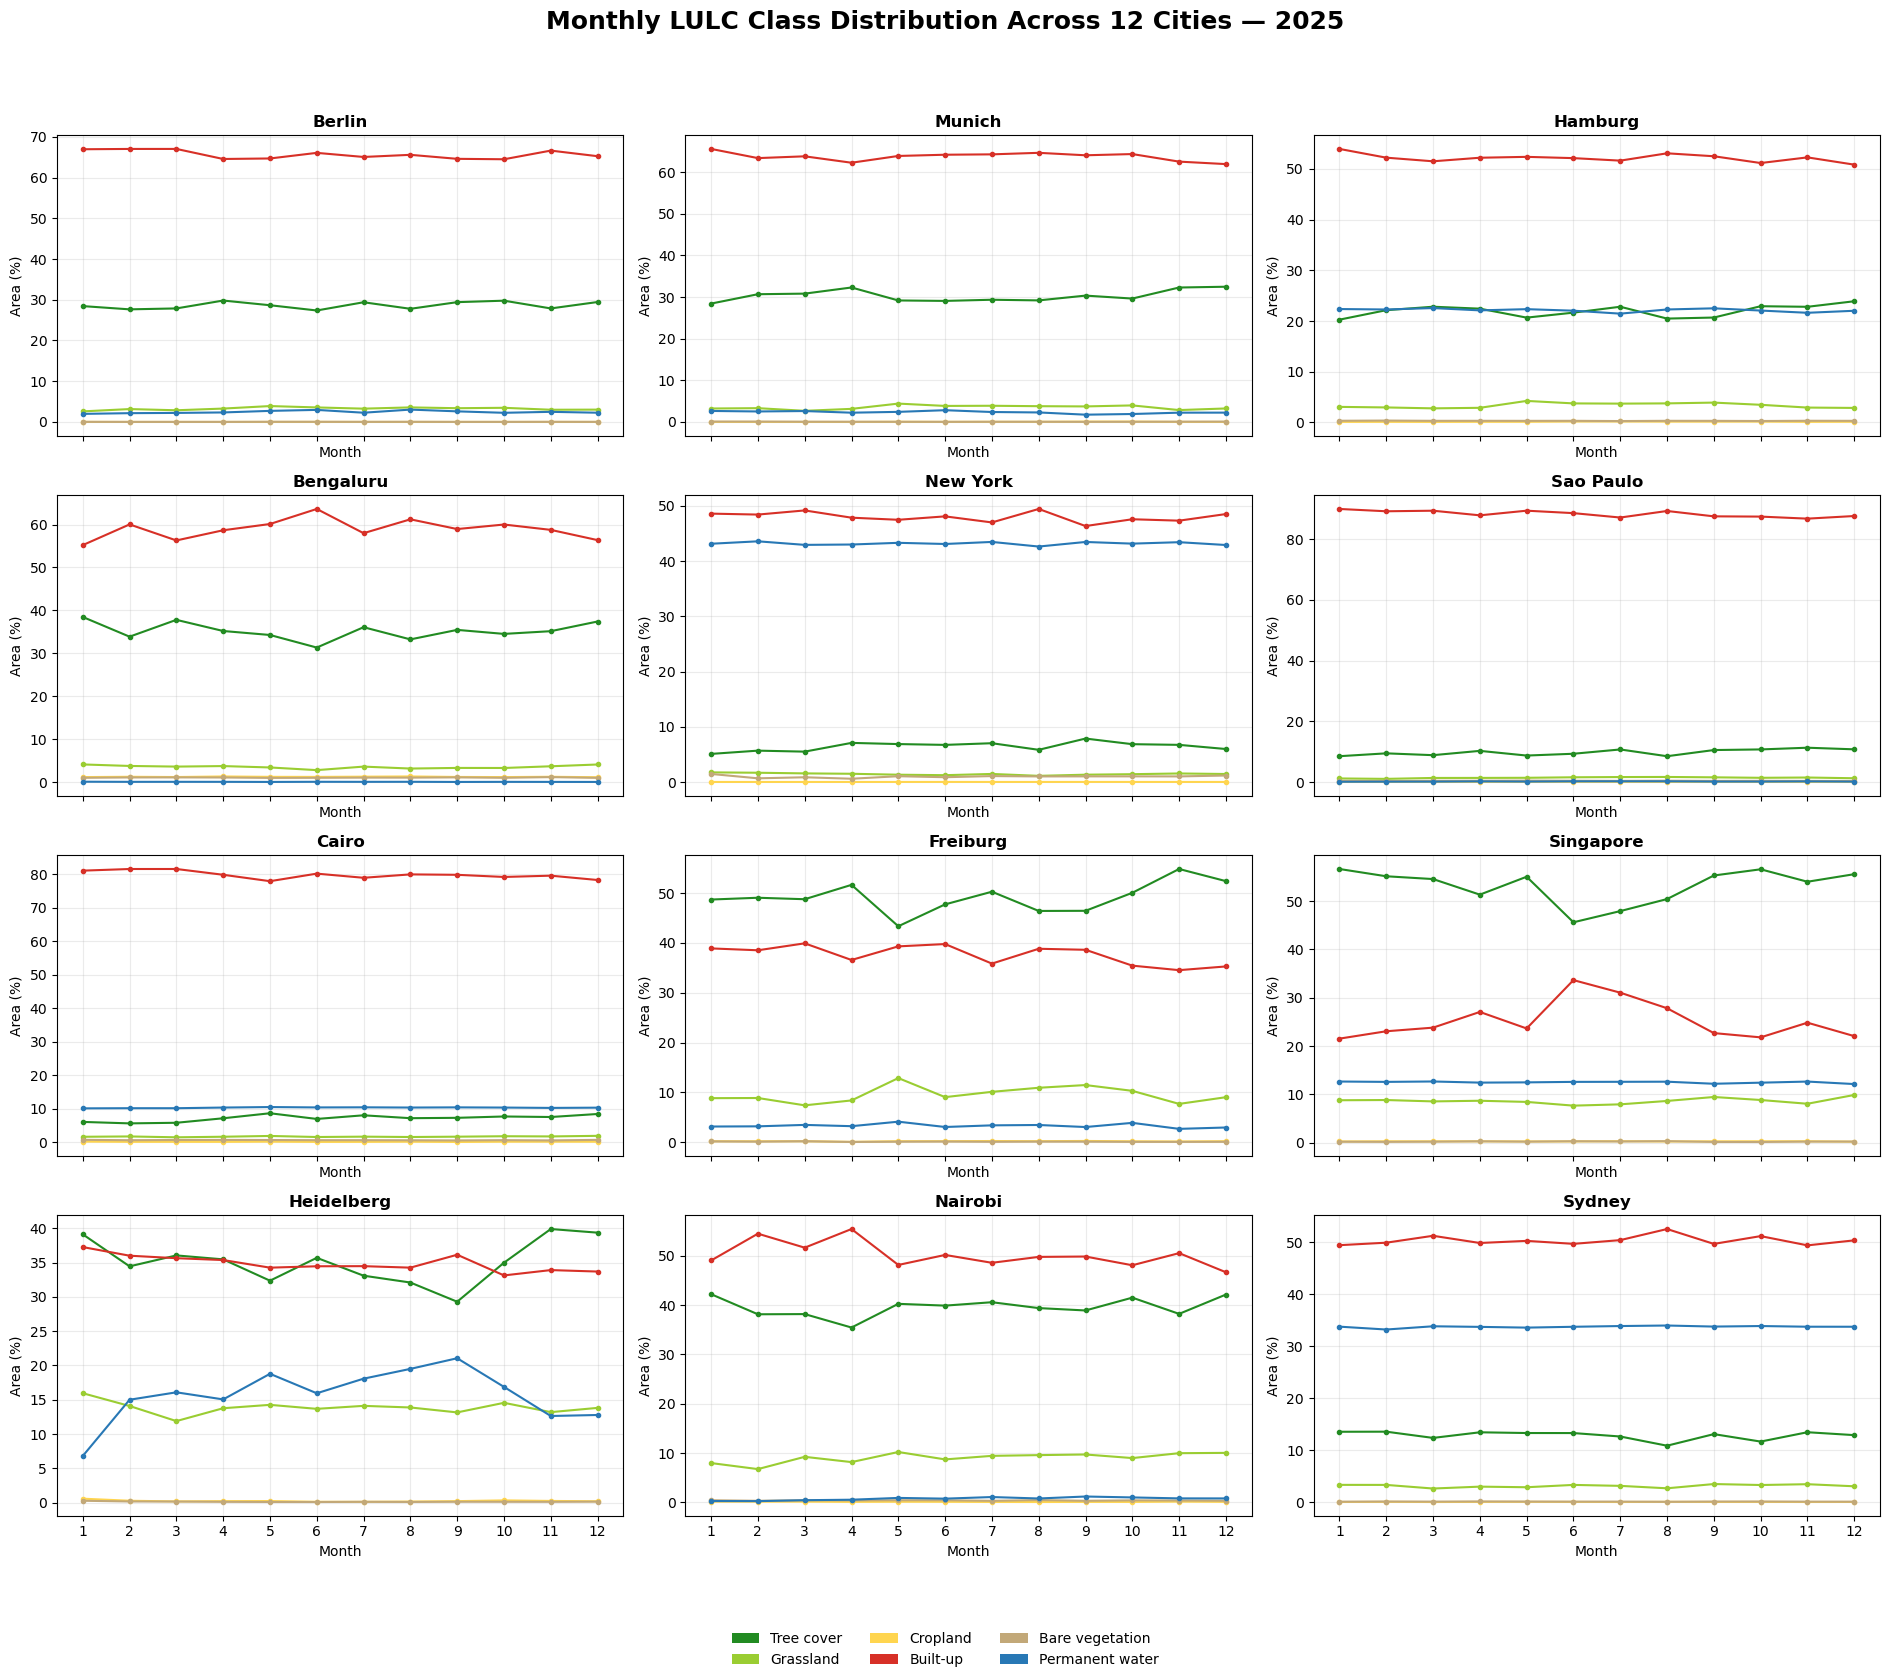

Saved: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/visualizations/all_12_cities_monthly_class_trends.png


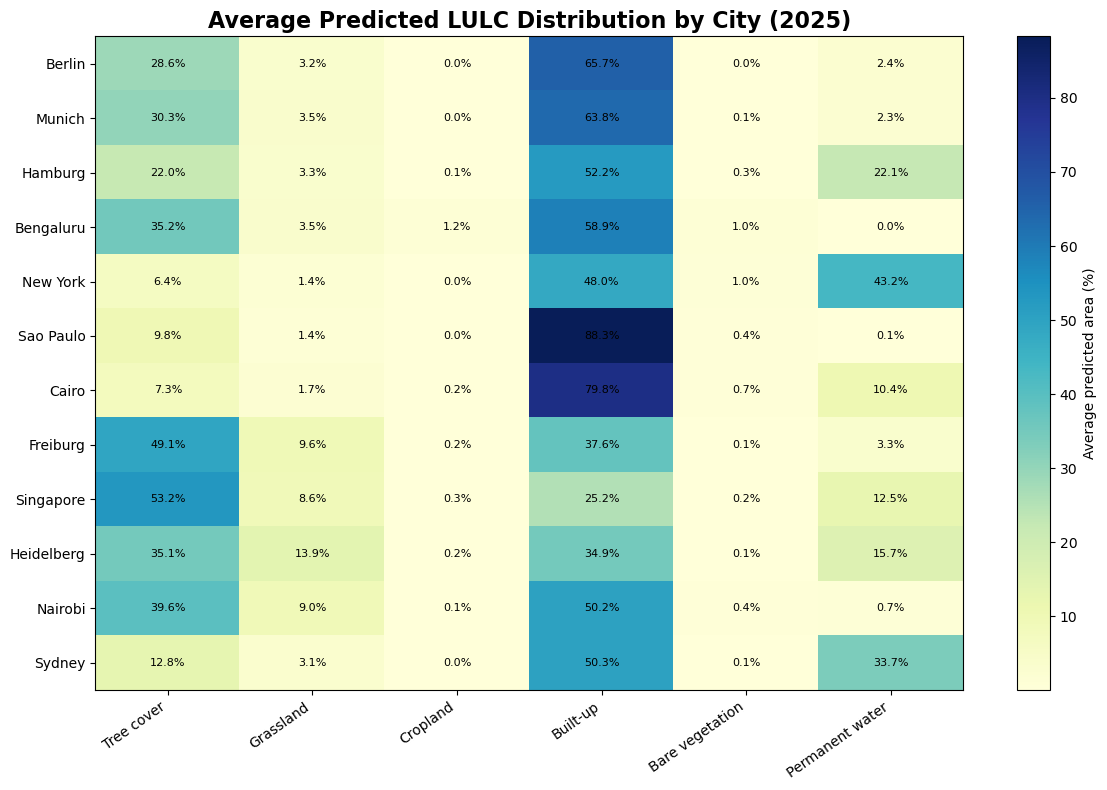

Saved: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/visualizations/city_class_distribution_heatmap.png

VISUALISATION SUMMARY
City monthly mosaics: 12
Combined temporal chart: True
City-class heatmap: True

SUCCESS: ALL 12-CITY VISUALISATIONS GENERATED.


In [116]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"
STAT_DIR = ROOT / "outputs" / "statistics"

FIG_DIR = ROOT / "outputs" / "visualizations"

MAP_FIG_DIR = FIG_DIR / "all_city_monthly_maps"
MAP_FIG_DIR.mkdir(parents=True, exist_ok=True)

FIG_DIR.mkdir(parents=True, exist_ok=True)

CITIES = [
    ("Berlin", "berlin"),
    ("Munich", "munich"),
    ("Hamburg", "hamburg"),
    ("Bengaluru", "bengaluru"),
    ("New York", "new_york"),
    ("Sao Paulo", "sao_paulo"),
    ("Cairo", "cairo"),
    ("Freiburg", "freiburg"),
    ("Singapore", "singapore"),
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

CLASS_COLORS = [
    "#228B22",
    "#9ACD32",
    "#FFD54F",
    "#D73027",
    "#C2A878",
    "#2878B5"
]

cmap = ListedColormap(CLASS_COLORS)
norm = BoundaryNorm(
    np.arange(-0.5, 6.5, 1),
    cmap.N
)

# --------------------------------------------------
# 1. Load and independently validate transition reports
# --------------------------------------------------

transition_df = pd.read_csv(
    STAT_DIR / "month_to_month_pixel_transitions_all_cities.csv"
)

matrix_df = pd.read_csv(
    STAT_DIR / "class_transition_matrices_all_cities.csv"
)

mask_df = pd.read_csv(
    STAT_DIR / "common_mask_coverage_all_cities.csv"
)

assert len(transition_df) == 132
assert len(matrix_df) == 4752

expected_pixels = mask_df.set_index(
    "City"
)["Common Valid Pixels"]

matrix_totals = (
    matrix_df.groupby(["City", "From Month"])["Pixels"]
    .sum()
)

for (city, month), total in matrix_totals.items():
    assert total == expected_pixels.loc[city]

diagonal_df = matrix_df[
    matrix_df["From Class ID"]
    == matrix_df["To Class ID"]
]

unchanged_by_matrix = (
    diagonal_df.groupby(["City", "From Month"])["Pixels"]
    .sum()
)

for _, row in transition_df.iterrows():

    key = (row["City"], row["From Month"])

    expected_changed = (
        row["Common Valid Pixels"]
        - unchanged_by_matrix.loc[key]
    )

    assert expected_changed == row["Changed Pixels"]

print("Transition-matrix integrity checks passed.")

# --------------------------------------------------
# 2. Generate 12-month map mosaics for every city
# --------------------------------------------------

print("\nGenerating 12-city monthly map mosaics...")

legend_handles = [
    Patch(
        facecolor=CLASS_COLORS[i],
        label=CLASS_NAMES[i]
    )
    for i in range(6)
]

for city, prefix in CITIES:

    city_dir = MAP_DIR / city

    fig, axes = plt.subplots(
        3, 4,
        figsize=(17, 12)
    )

    fig.suptitle(
        f"{city} — Monthly LULC Predictions (2025)",
        fontsize=18,
        fontweight="bold"
    )

    for month, ax in enumerate(axes.flat, start=1):

        filepath = (
            city_dir /
            f"{prefix}_2025_{month:02d}_lulc.tif"
        )

        with rasterio.open(filepath) as src:
            prediction = src.read(1)

        display_map = np.ma.masked_equal(
            prediction,
            255
        )

        ax.imshow(
            display_map,
            cmap=cmap,
            norm=norm,
            interpolation="nearest"
        )

        ax.set_title(
            pd.Timestamp(
                year=2025,
                month=month,
                day=1
            ).strftime("%B"),
            fontsize=11
        )

        ax.axis("off")

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=10
    )

    fig.tight_layout(
        rect=[0, 0.08, 1, 0.94]
    )

    output_path = (
        MAP_FIG_DIR /
        f"{prefix}_12_month_lulc_maps.png"
    )

    fig.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.close(fig)

    print("Saved:", output_path.name)


# --------------------------------------------------
# 3. Combined monthly class-distribution chart
# --------------------------------------------------

monthly_df = pd.read_csv(
    STAT_DIR / "common_mask_monthly_class_percentages.csv"
)

fig, axes = plt.subplots(
    4, 3,
    figsize=(19, 17),
    sharex=True
)

fig.suptitle(
    "Monthly LULC Class Distribution Across 12 Cities — 2025",
    fontsize=18,
    fontweight="bold"
)

for city, ax in zip(
    [city for city, _ in CITIES],
    axes.flat
):

    city_data = monthly_df[
        monthly_df["City"] == city
    ]

    for class_id, class_name in enumerate(CLASS_NAMES):

        class_data = city_data[
            city_data["Class ID"] == class_id
        ].sort_values("Month")

        ax.plot(
            class_data["Month"],
            class_data["Percentage"],
            marker="o",
            linewidth=1.5,
            markersize=3,
            color=CLASS_COLORS[class_id],
            label=class_name
        )

    ax.set_title(city, fontweight="bold")
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Month")
    ax.set_ylabel("Area (%)")
    ax.grid(alpha=0.25)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=3,
    frameon=False
)

fig.tight_layout(
    rect=[0, 0.06, 1, 0.95]
)

trend_path = (
    FIG_DIR /
    "all_12_cities_monthly_class_trends.png"
)

fig.savefig(
    trend_path,
    dpi=220,
    bbox_inches="tight"
)

plt.show()

print("Saved:", trend_path)


# --------------------------------------------------
# 4. City-by-class mean distribution heatmap
# --------------------------------------------------

mean_distribution = (
    monthly_df.groupby(
        ["City", "Class"]
    )["Percentage"]
    .mean()
    .unstack()
)

mean_distribution = mean_distribution.reindex(
    [city for city, _ in CITIES]
)[CLASS_NAMES]

fig, ax = plt.subplots(
    figsize=(12, 8)
)

image = ax.imshow(
    mean_distribution.values,
    aspect="auto",
    cmap="YlGnBu"
)

ax.set_xticks(range(len(CLASS_NAMES)))
ax.set_xticklabels(
    CLASS_NAMES,
    rotation=35,
    ha="right"
)

ax.set_yticks(range(len(mean_distribution.index)))
ax.set_yticklabels(mean_distribution.index)

ax.set_title(
    "Average Predicted LULC Distribution by City (2025)",
    fontsize=16,
    fontweight="bold"
)

for i in range(len(mean_distribution.index)):
    for j in range(len(CLASS_NAMES)):

        value = mean_distribution.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.1f}%",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(
    image,
    ax=ax,
    label="Average predicted area (%)"
)

fig.tight_layout()

heatmap_path = (
    FIG_DIR /
    "city_class_distribution_heatmap.png"
)

fig.savefig(
    heatmap_path,
    dpi=220,
    bbox_inches="tight"
)

plt.show()

print("Saved:", heatmap_path)


# --------------------------------------------------
# 5. Final output check
# --------------------------------------------------

mosaic_files = list(
    MAP_FIG_DIR.glob("*_12_month_lulc_maps.png")
)

assert len(mosaic_files) == 12

assert trend_path.exists()
assert heatmap_path.exists()

print("\n" + "=" * 70)
print("VISUALISATION SUMMARY")
print("=" * 70)

print("City monthly mosaics:", len(mosaic_files))
print("Combined temporal chart:", trend_path.exists())
print("City-class heatmap:", heatmap_path.exists())

print("\nSUCCESS: ALL 12-CITY VISUALISATIONS GENERATED.")

In [117]:
import ee
import rasterio

from pathlib import Path
from rasterio.warp import transform_bounds

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

EE_PROJECT = "lulc-sentinel1-project-512811"

TEST_CITIES = [
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

print("=" * 65)
print("DYNAMIC WORLD ACCESS AND DATA AVAILABILITY CHECK")
print("=" * 65)

# 1. Initialize Earth Engine
try:
    ee.Initialize(project=EE_PROJECT)
    print("\nEarth Engine initialized successfully.")

except Exception as e:
    print("\nEarth Engine initialization failed.")
    print(type(e).__name__, str(e)[:1000])
    raise

# 2. Load Dynamic World collection
dw = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")

# 3. Check availability for each held-out test city
for city, prefix in TEST_CITIES:

    raster_path = (
        MAP_DIR / city /
        f"{prefix}_2025_01_lulc.tif"
    )

    with rasterio.open(raster_path) as src:

        west, south, east, north = transform_bounds(
            src.crs,
            "EPSG:4326",
            *src.bounds,
            densify_pts=21
        )

    region = ee.Geometry.Rectangle(
        [west, south, east, north],
        proj="EPSG:4326",
        geodesic=False
    )

    collection = (
        dw.filterBounds(region)
          .filterDate("2025-01-01", "2026-01-01")
    )

    image_count = collection.size().getInfo()

    print(f"\n{city}")
    print("Dynamic World images in 2025:", image_count)

    if image_count == 0:
        print("WARNING: No Dynamic World images found.")
    else:
        print("Availability: Confirmed")

print("\nDYNAMIC WORLD AVAILABILITY CHECK COMPLETED.")

DYNAMIC WORLD ACCESS AND DATA AVAILABILITY CHECK

Earth Engine initialized successfully.

Heidelberg
Dynamic World images in 2025: 61
Availability: Confirmed

Nairobi
Dynamic World images in 2025: 49
Availability: Confirmed

Sydney
Dynamic World images in 2025: 89
Availability: Confirmed

DYNAMIC WORLD AVAILABILITY CHECK COMPLETED.


In [118]:
%pip install -q earthengine-api

import ee

print("Earth Engine package installed successfully.")
print("Version:", ee.__version__)

Note: you may need to restart the kernel to use updated packages.
Earth Engine package installed successfully.
Version: 1.7.51


In [119]:
import ee

ee.Authenticate(auth_mode="notebook")

Enter verification code:  4/1AUn6Hd_1SfOFr1cm78drRYqty7QR_r6yYxkhRZvTqQmqdA3fWfqANaKb39c



Successfully saved authorization token.


In [120]:
import ee

EE_PROJECT = "lulc-sentinel1-project-512811"

ee.Initialize(project=EE_PROJECT)

print("Earth Engine authenticated and initialised!")

print(
    ee.String("Connection successful").getInfo()
)

Earth Engine authenticated and initialised!
Connection successful


In [121]:
import ee
import rasterio
import pandas as pd

from pathlib import Path
from rasterio.warp import transform_bounds

ROOT = Path.cwd()
MAP_DIR = ROOT / "outputs" / "monthly_maps"

EE_PROJECT = "lulc-sentinel1-project-512811"

TEST_CITIES = [
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

ee.Initialize(project=EE_PROJECT)

dw = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")

availability_records = []

print("=" * 65)
print("DYNAMIC WORLD — 2025 IMAGE AVAILABILITY")
print("=" * 65)

for city, prefix in TEST_CITIES:

    raster_path = (
        MAP_DIR / city /
        f"{prefix}_2025_01_lulc.tif"
    )

    with rasterio.open(raster_path) as src:

        west, south, east, north = transform_bounds(
            src.crs,
            "EPSG:4326",
            *src.bounds,
            densify_pts=21
        )

    region = ee.Geometry.Rectangle(
        [west, south, east, north],
        proj="EPSG:4326",
        geodesic=False
    )

    collection = (
        dw.filterBounds(region)
          .filterDate("2025-01-01", "2026-01-01")
    )

    image_count = collection.size().getInfo()

    record = {
        "City": city,
        "Dynamic World Images (2025)": image_count,
        "Availability": (
            "Available" if image_count > 0
            else "Unavailable"
        )
    }

    availability_records.append(record)

    print(f"\n{city}: {image_count} images")

availability_df = pd.DataFrame(availability_records)

display(availability_df)

output_path = (
    ROOT / "outputs" / "evaluation"
    / "dynamic_world_availability.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

availability_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("\nAVAILABILITY CHECK COMPLETED.")

DYNAMIC WORLD — 2025 IMAGE AVAILABILITY

Heidelberg: 61 images

Nairobi: 49 images

Sydney: 89 images


,City,Dynamic World Images (2025),Availability
0,Heidelberg,61,Available
1,Nairobi,49,Available
2,Sydney,89,Available



Saved: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/dynamic_world_availability.csv

AVAILABILITY CHECK COMPLETED.


In [122]:
import ee
import pandas as pd
from pathlib import Path
import rasterio

ROOT = Path.cwd()
MAP_DIR = ROOT / "outputs" / "monthly_maps"
STAT_DIR = ROOT / "outputs" / "evaluation"

STAT_DIR.mkdir(parents=True, exist_ok=True)

EE_PROJECT = "lulc-sentinel1-project-512811"

TEST_CITIES = [
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

ee.Initialize(project=EE_PROJECT)

dw = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")

monthly_records = []

print("=" * 70)
print("DYNAMIC WORLD MONTHLY OBSERVATION AVAILABILITY")
print("=" * 70)

for city, prefix in TEST_CITIES:

    raster_path = (
        MAP_DIR / city /
        f"{prefix}_2025_01_lulc.tif"
    )

    with rasterio.open(raster_path) as src:
        west, south, east, north = src.bounds
        projection = src.crs.to_string()

    region = ee.Geometry.Rectangle(
        [west, south, east, north],
        proj=projection,
        geodesic=False
    )

    collection = (
        dw.filterBounds(region)
          .filterDate("2025-01-01", "2026-01-01")
    )

    # Attach calendar month to each image
    collection_with_month = collection.map(
        lambda image: image.set(
            "month",
            ee.Date(image.get("system:time_start")).get("month")
        )
    )

    # Retrieve all monthly counts in one request per city
    histogram = (
        collection_with_month
        .aggregate_histogram("month")
        .getInfo()
    )

    print(f"\n{city}")

    for month in range(1, 13):

        count = int(histogram.get(str(month), 0))

        monthly_records.append({
            "City": city,
            "Month": month,
            "Month Name": pd.Timestamp(
                year=2025,
                month=month,
                day=1
            ).strftime("%B"),
            "Dynamic World Observations": count
        })

        print(
            f"{month:02d} — "
            f"{pd.Timestamp(2025, month, 1).strftime('%B')}: "
            f"{count} images"
        )

# Create monthly availability report
monthly_availability_df = pd.DataFrame(monthly_records)

# Verify annual totals against previous check
expected_totals = {
    "Heidelberg": 61,
    "Nairobi": 49,
    "Sydney": 89
}

for city, expected in expected_totals.items():

    actual = monthly_availability_df.loc[
        monthly_availability_df["City"] == city,
        "Dynamic World Observations"
    ].sum()

    assert actual == expected, (
        f"{city}: annual count mismatch. "
        f"Expected {expected}, found {actual}"
    )

# Save report
output_path = (
    STAT_DIR /
    "dynamic_world_monthly_availability.csv"
)

monthly_availability_df.to_csv(
    output_path,
    index=False
)

print("\n" + "=" * 70)
print("MONTHLY AVAILABILITY SUMMARY")
print("=" * 70)

display(
    monthly_availability_df.pivot(
        index="Month Name",
        columns="City",
        values="Dynamic World Observations"
    )
)

print("\nMissing months:")

missing = monthly_availability_df[
    monthly_availability_df["Dynamic World Observations"] == 0
]

display(missing)

print("\nSaved:", output_path)
print("\nMONTHLY AVAILABILITY CHECK COMPLETED.")

DYNAMIC WORLD MONTHLY OBSERVATION AVAILABILITY

Heidelberg
01 — January: 3 images
02 — February: 2 images
03 — March: 6 images
04 — April: 10 images
05 — May: 7 images
06 — June: 11 images
07 — July: 3 images
08 — August: 8 images
09 — September: 2 images
10 — October: 3 images
11 — November: 1 images
12 — December: 5 images

Nairobi
01 — January: 6 images
02 — February: 6 images
03 — March: 3 images
04 — April: 7 images
05 — May: 3 images
06 — June: 1 images
07 — July: 2 images
08 — August: 3 images
09 — September: 6 images
10 — October: 2 images
11 — November: 5 images
12 — December: 5 images

Sydney
01 — January: 7 images
02 — February: 10 images
03 — March: 3 images
04 — April: 8 images
05 — May: 6 images
06 — June: 9 images
07 — July: 11 images
08 — August: 9 images
09 — September: 10 images
10 — October: 4 images
11 — November: 6 images
12 — December: 6 images

MONTHLY AVAILABILITY SUMMARY


City,Heidelberg,Nairobi,Sydney
Month Name,,,
April,10,7,8
August,8,3,9
December,5,5,6
February,2,6,10
January,3,6,7
July,3,2,11
June,11,1,9
March,6,3,3
May,7,3,6



Missing months:


,City,Month,Month Name,Dynamic World Observations



Saved: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/dynamic_world_monthly_availability.csv

MONTHLY AVAILABILITY CHECK COMPLETED.


In [123]:
import ee
import pandas as pd
import rasterio

from pathlib import Path
from rasterio.warp import transform_bounds

ROOT = Path.cwd()

raster_path = (
    ROOT / "outputs" / "monthly_maps" /
    "Sydney" / "sydney_2025_01_lulc.tif"
)

ee.Initialize(
    project="lulc-sentinel1-project-512811"
)

with rasterio.open(raster_path) as src:

    west, south, east, north = transform_bounds(
        src.crs,
        "EPSG:4326",
        *src.bounds,
        densify_pts=21
    )

region = ee.Geometry.Rectangle(
    [west, south, east, north],
    proj="EPSG:4326",
    geodesic=False
)

dw = ee.ImageCollection(
    "GOOGLE/DYNAMICWORLD/V1"
)

collection = (
    dw.filterBounds(region)
      .filterDate("2025-01-01", "2026-01-01")
)

collection = collection.map(
    lambda image: image.set(
        "month",
        ee.Date(
            image.get("system:time_start")
        ).get("month")
    )
)

histogram = collection.aggregate_histogram(
    "month"
).getInfo()

sydney_counts = []

print("SYDNEY — DYNAMIC WORLD MONTHLY OBSERVATIONS")
print("=" * 55)

for month in range(1, 13):

    count = int(histogram.get(str(month), 0))

    sydney_counts.append(count)

    print(
        f"{pd.Timestamp(2025, month, 1).strftime('%B')}: "
        f"{count}"
    )

print("\nTotal observations:", sum(sydney_counts))

assert sum(sydney_counts) == 89, (
    "Annual observation count does not match the earlier audit."
)

print("\nSydney monthly availability verified.")

SYDNEY — DYNAMIC WORLD MONTHLY OBSERVATIONS
January: 7
February: 10
March: 3
April: 8
May: 6
June: 9
July: 11
August: 9
September: 10
October: 4
November: 6
December: 6

Total observations: 89

Sydney monthly availability verified.


In [124]:
import ee
import rasterio
import requests
import numpy as np

from pathlib import Path
from zipfile import ZipFile, is_zipfile
from io import BytesIO

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

DW_DIR = (
    ROOT / "outputs" /
    "independent_validation" /
    "dynamic_world"
)

DW_DIR.mkdir(parents=True, exist_ok=True)

ee.Initialize(
    project="lulc-sentinel1-project-512811"
)

CITY = "Heidelberg"
PREFIX = "heidelberg"
MONTH = 1
YEAR = 2025

PROB_BANDS = [
    "water",
    "trees",
    "grass",
    "flooded_vegetation",
    "crops",
    "shrub_and_scrub",
    "built",
    "bare",
    "snow_and_ice"
]

input_path = (
    MAP_DIR / CITY /
    f"{PREFIX}_{YEAR}_{MONTH:02d}_lulc.tif"
)

output_path = (
    DW_DIR /
    f"{PREFIX}_{YEAR}_{MONTH:02d}_dw_probabilities.tif"
)

print("=" * 70)
print("DYNAMIC WORLD — HEIDELBERG JANUARY 2025")
print("=" * 70)

# --------------------------------------------------
# 1. Read exact Sentinel-1 spatial reference
# --------------------------------------------------

with rasterio.open(input_path) as src:

    reference_shape = src.shape
    reference_crs = src.crs
    reference_transform = src.transform
    reference_bounds = src.bounds

    print("Reference dimensions:", reference_shape)
    print("Reference CRS:", reference_crs)
    print("Reference resolution:", src.res)

# --------------------------------------------------
# 2. Build region in the source projected CRS
# --------------------------------------------------

region = ee.Geometry.Rectangle(
    [
        reference_bounds.left,
        reference_bounds.bottom,
        reference_bounds.right,
        reference_bounds.top
    ],
    proj=reference_crs.to_string(),
    geodesic=False
)

# --------------------------------------------------
# 3. Filter Dynamic World observations
# --------------------------------------------------

dw = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterBounds(region)
    .filterDate(
        f"{YEAR}-{MONTH:02d}-01",
        f"{YEAR}-{MONTH+1:02d}-01"
        if MONTH < 12
        else f"{YEAR+1}-01-01"
    )
)

observation_count = dw.size().getInfo()

print("\nJanuary Dynamic World observations:", observation_count)

assert observation_count > 0

# --------------------------------------------------
# 4. Create monthly probability composite
# --------------------------------------------------

probability_composite = (
    dw.select(PROB_BANDS)
    .median()
)

pixel_observations = (
    dw.select("water")
    .count()
    .rename("observation_count")
    .toFloat()
)

composite = (
    probability_composite
    .addBands(pixel_observations)
)

# --------------------------------------------------
# 5. Request GeoTIFF in exact Sentinel-1 grid
# --------------------------------------------------

transform_list = [
    reference_transform.a,
    reference_transform.b,
    reference_transform.c,
    reference_transform.d,
    reference_transform.e,
    reference_transform.f
]

download_params = {
    "name": "heidelberg_dw_january_2025",
    "bands": PROB_BANDS + ["observation_count"],
    "region": region,
    "crs": reference_crs.to_string(),
    "crs_transform": transform_list,
    "format": "GEO_TIFF",
    "filePerBand": False
}

download_url = composite.getDownloadURL(
    download_params
)

response = requests.get(
    download_url,
    timeout=180
)

response.raise_for_status()

# --------------------------------------------------
# 6. Save downloaded GeoTIFF
# --------------------------------------------------

content = BytesIO(response.content)

if is_zipfile(content):

    content.seek(0)

    with ZipFile(content) as archive:

        tif_files = [
            name for name in archive.namelist()
            if name.lower().endswith(".tif")
        ]

        assert len(tif_files) == 1

        with archive.open(tif_files[0]) as source:
            output_path.write_bytes(source.read())

else:

    output_path.write_bytes(response.content)

assert output_path.exists()
assert output_path.stat().st_size > 0

# --------------------------------------------------
# 7. Verify spatial alignment and raster content
# --------------------------------------------------

with rasterio.open(output_path) as dw_raster:

    assert dw_raster.count == 10

    assert dw_raster.shape == reference_shape, (
        f"Dimension mismatch: {dw_raster.shape}"
    )

    assert dw_raster.crs == reference_crs

    assert dw_raster.transform.almost_equals(
        reference_transform
    )

    data = dw_raster.read()

    probabilities = data[:9]
    observation_counts = data[9]

    valid_pixels = np.isfinite(
        probabilities
    ).all(axis=0) & (observation_counts > 0)

    valid_count = int(valid_pixels.sum())

    print("\nDownloaded raster dimensions:", dw_raster.shape)
    print("Number of bands:", dw_raster.count)
    print("Valid Dynamic World pixels:", valid_count)

    if valid_count > 0:

        probability_sums = probabilities[:, valid_pixels].sum(axis=0)

        print(
            "Mean probability sum:",
            float(probability_sums.mean())
        )

        print(
            "Pixel observations — minimum:",
            int(observation_counts[valid_pixels].min())
        )

        print(
            "Pixel observations — maximum:",
            int(observation_counts[valid_pixels].max())
        )

        assert np.allclose(
            probability_sums,
            1.0,
            atol=0.02
        ), "Unexpected probability sums."

    else:

        raise RuntimeError(
            "No valid Dynamic World pixels in downloaded raster."
        )

    assert valid_count > 0

    print("\nSpatial alignment: PASSED")

print("\nSaved:", output_path)
print("\nSUCCESS: DYNAMIC WORLD PILOT COMPOSITE CREATED.")

DYNAMIC WORLD — HEIDELBERG JANUARY 2025
Reference dimensions: (503, 501)
Reference CRS: EPSG:32632
Reference resolution: (10.0, 10.0)

January Dynamic World observations: 3

Downloaded raster dimensions: (503, 501)
Number of bands: 10
Valid Dynamic World pixels: 108824
Mean probability sum: 0.9999587805471692
Pixel observations — minimum: 1
Pixel observations — maximum: 1

Spatial alignment: PASSED

Saved: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/independent_validation/dynamic_world/heidelberg_2025_01_dw_probabilities.tif

SUCCESS: DYNAMIC WORLD PILOT COMPOSITE CREATED.


In [129]:
import ee
import rasterio
import requests
import numpy as np
import pandas as pd

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile, is_zipfile

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

DW_DIR = (
    ROOT / "outputs" /
    "independent_validation" /
    "dynamic_world_mean"
)

EVAL_DIR = ROOT / "outputs" / "evaluation"

DW_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

EE_PROJECT = "lulc-sentinel1-project-512811"

TEST_CITIES = [
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

PROB_BANDS = [
    "water",
    "trees",
    "grass",
    "flooded_vegetation",
    "crops",
    "shrub_and_scrub",
    "built",
    "bare",
    "snow_and_ice"
]

YEAR = 2025

ee.Initialize(project=EE_PROJECT)

dw = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")

manifest_records = []

manifest_path = (
    EVAL_DIR /
    "dynamic_world_mean_composite_manifest.csv"
)

print("=" * 75)
print("DYNAMIC WORLD — 36 MONTHLY MEAN PROBABILITY COMPOSITES")
print("=" * 75)

for city, prefix in TEST_CITIES:

    print(f"\n{'=' * 65}")
    print("CITY:", city)
    print("=" * 65)

    city_map_dir = MAP_DIR / city

    city_dw_dir = DW_DIR / city
    city_dw_dir.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------
    # 1. Establish reference grid
    # --------------------------------------------------

    reference_path = (
        city_map_dir /
        f"{prefix}_{YEAR}_01_lulc.tif"
    )

    with rasterio.open(reference_path) as src:

        reference_shape = src.shape
        reference_crs = src.crs
        reference_transform = src.transform
        reference_bounds = src.bounds

    # Confirm that all 12 Sentinel-1 maps use the same grid
    for month in range(1, 13):

        s1_path = (
            city_map_dir /
            f"{prefix}_{YEAR}_{month:02d}_lulc.tif"
        )

        with rasterio.open(s1_path) as src:

            assert src.shape == reference_shape
            assert src.crs == reference_crs
            assert src.transform == reference_transform

    print("Reference grid:", reference_shape)
    print("CRS:", reference_crs)

    # --------------------------------------------------
    # 2. Construct exact spatial region
    # --------------------------------------------------

    region = ee.Geometry.Rectangle(
        [
            reference_bounds.left,
            reference_bounds.bottom,
            reference_bounds.right,
            reference_bounds.top
        ],
        proj=reference_crs.to_string(),
        geodesic=False
    )

    # --------------------------------------------------
    # 3. Process all 12 months
    # --------------------------------------------------

    for month in range(1, 13):

        start_date = pd.Timestamp(
            year=YEAR,
            month=month,
            day=1
        )

        end_date = start_date + pd.offsets.MonthBegin(1)

        start_string = start_date.strftime("%Y-%m-%d")
        end_string = end_date.strftime("%Y-%m-%d")

        print(f"\nProcessing {start_date.strftime('%B')}...")

        output_path = (
            city_dw_dir /
            f"{prefix}_{YEAR}_{month:02d}_dw_mean_probabilities.tif"
        )

        # ----------------------------------------------
        # Filter monthly observations
        # ----------------------------------------------

        monthly_collection = (
            dw.filterBounds(region)
              .filterDate(start_string, end_string)
        )

        scene_count = monthly_collection.size().getInfo()

        if scene_count == 0:
            raise RuntimeError(
                f"No Dynamic World images for {city}, "
                f"{start_string}."
            )

        # ----------------------------------------------
        # Mean probabilities across the month
        # ----------------------------------------------

        probability_composite = (
            monthly_collection
            .select(PROB_BANDS)
            .mean()
        )

        # Number of valid observations per pixel
        observation_count = (
            monthly_collection
            .select("water")
            .count()
            .rename("observation_count")
            .toFloat()
        )

        composite = (
            probability_composite
            .addBands(observation_count)
        )

        # ----------------------------------------------
        # Export using the exact Sentinel-1 grid
        # ----------------------------------------------

        transform_list = [
            reference_transform.a,
            reference_transform.b,
            reference_transform.c,
            reference_transform.d,
            reference_transform.e,
            reference_transform.f
        ]

        download_params = {
            "name": f"{prefix}_dw_mean_{YEAR}_{month:02d}",
            "bands": PROB_BANDS + ["observation_count"],
            "region": region,
            "crs": reference_crs.to_string(),
            "crs_transform": transform_list,
            "format": "GEO_TIFF",
            "filePerBand": False
        }

        download_url = composite.getDownloadURL(
            download_params
        )

        response = requests.get(
            download_url,
            timeout=180
        )

        response.raise_for_status()

        # ----------------------------------------------
        # Save downloaded GeoTIFF
        # ----------------------------------------------

        content = BytesIO(response.content)

        if is_zipfile(content):

            content.seek(0)

            with ZipFile(content) as archive:

                tif_files = [
                    name for name in archive.namelist()
                    if name.lower().endswith(".tif")
                ]

                if len(tif_files) != 1:
                    raise RuntimeError(
                        f"Unexpected TIFF count: {len(tif_files)}"
                    )

                with archive.open(tif_files[0]) as source:
                    output_path.write_bytes(source.read())

        else:

            output_path.write_bytes(response.content)

        # ----------------------------------------------
        # Verify downloaded raster
        # ----------------------------------------------

        with rasterio.open(output_path) as raster:

            assert raster.count == 10
            assert raster.shape == reference_shape
            assert raster.crs == reference_crs

            assert raster.transform.almost_equals(
                reference_transform
            )

            data = raster.read()

            probabilities = data[:9]
            pixel_observations = data[9]

            valid_mask = (
                np.isfinite(probabilities).all(axis=0)
                & np.isfinite(pixel_observations)
                & (pixel_observations > 0)
            )

            valid_pixels = int(valid_mask.sum())

            if valid_pixels == 0:
                raise RuntimeError(
                    f"No valid pixels for {city}, month {month}"
                )

            valid_probabilities = probabilities[:, valid_mask]

            probability_sums = valid_probabilities.sum(axis=0)

            mean_probability_sum = float(
                probability_sums.mean()
            )

            max_probability_sum_error = float(
                np.abs(probability_sums - 1.0).max()
            )

            probability_min = float(
                valid_probabilities.min()
            )

            probability_max = float(
                valid_probabilities.max()
            )

            counts = pixel_observations[valid_mask]

            min_observations = int(counts.min())
            median_observations = float(np.median(counts))
            max_observations = int(counts.max())

            # ------------------------------------------
            # Probability integrity checks
            # ------------------------------------------

            assert probability_min >= -0.001
            assert probability_max <= 1.001

            assert max_probability_sum_error <= 0.02, (
                f"Probability sum error for {city}, month {month}: "
                f"{max_probability_sum_error}"
            )

            coverage = (
                valid_pixels /
                (reference_shape[0] * reference_shape[1])
                * 100
            )

        record = {
            "City": city,
            "Month": month,
            "Date": start_string,
            "Image Records": scene_count,
            "Valid Pixels": valid_pixels,
            "Valid Coverage (%)": coverage,
            "Min Pixel Observations": min_observations,
            "Median Pixel Observations": median_observations,
            "Max Pixel Observations": max_observations,
            "Mean Probability Sum": mean_probability_sum,
            "Max Probability Sum Error": max_probability_sum_error,
            "Minimum Probability": probability_min,
            "Maximum Probability": probability_max,
            "Spatial Alignment": True,
            "Output": str(output_path)
        }

        manifest_records.append(record)

        # Save progress after every successful composite
        pd.DataFrame(manifest_records).to_csv(
            manifest_path,
            index=False
        )

        print(
            f"  Images: {scene_count} | "
            f"Valid pixels: {valid_pixels:,} | "
            f"Coverage: {coverage:.2f}% | "
            f"Pixel observations: "
            f"{min_observations}-{max_observations}"
        )

        print("  Spatial alignment: PASSED")


# --------------------------------------------------
# 4. Consolidated validation report
# --------------------------------------------------

manifest_df = pd.DataFrame(manifest_records)

assert len(manifest_df) == 36

assert manifest_df["Spatial Alignment"].all()

assert (
    manifest_df["Max Probability Sum Error"] <= 0.02
).all()

assert (manifest_df["Valid Pixels"] > 0).all()

assert manifest_df.groupby("City")["Month"].nunique().eq(12).all()

print("\n" + "=" * 75)
print("FINAL DYNAMIC WORLD COMPOSITE SUMMARY")
print("=" * 75)

display(
    manifest_df.groupby("City").agg(
        Monthly_Composites=("Month", "count"),
        Mean_Valid_Coverage=("Valid Coverage (%)", "mean"),
        Mean_Image_Records=("Image Records", "mean"),
        Maximum_Pixel_Observations=(
            "Max Pixel Observations", "max"
        )
    ).round(3)
)

print("\nTotal composites:", len(manifest_df))
print("Spatial alignment errors:", 0)
print(
    "Maximum probability sum error:",
    manifest_df["Max Probability Sum Error"].max()
)

print("\nSaved manifest:", manifest_path)

print("\nSUCCESS: ALL 36 DYNAMIC WORLD COMPOSITES GENERATED.")

DYNAMIC WORLD — 36 MONTHLY MEAN PROBABILITY COMPOSITES

CITY: Heidelberg
Reference grid: (503, 501)
CRS: EPSG:32632

Processing January...
  Images: 3 | Valid pixels: 108,824 | Coverage: 43.18% | Pixel observations: 1-1
  Spatial alignment: PASSED

Processing February...
  Images: 2 | Valid pixels: 252,003 | Coverage: 100.00% | Pixel observations: 1-2
  Spatial alignment: PASSED

Processing March...
  Images: 6 | Valid pixels: 252,003 | Coverage: 100.00% | Pixel observations: 1-6
  Spatial alignment: PASSED

Processing April...
  Images: 10 | Valid pixels: 252,003 | Coverage: 100.00% | Pixel observations: 3-8
  Spatial alignment: PASSED

Processing May...
  Images: 7 | Valid pixels: 252,003 | Coverage: 100.00% | Pixel observations: 1-6
  Spatial alignment: PASSED

Processing June...
  Images: 11 | Valid pixels: 252,003 | Coverage: 100.00% | Pixel observations: 3-7
  Spatial alignment: PASSED

Processing July...
  Images: 3 | Valid pixels: 252,003 | Coverage: 100.00% | Pixel observation

AssertionError: 

In [132]:
from pathlib import Path
import pandas as pd
import rasterio

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

DW_DIR = (
    ROOT / "outputs"
    / "independent_validation"
    / "dynamic_world_mean"
)

EVAL_DIR = ROOT / "outputs" / "evaluation"

CITIES = [
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

records = []

print("=" * 75)
print("DYNAMIC WORLD FILE AND SPATIAL ALIGNMENT AUDIT")
print("=" * 75)

for city, prefix in CITIES:

    print(f"\nChecking {city}...")

    for month in range(1, 13):

        s1_path = (
            MAP_DIR / city /
            f"{prefix}_2025_{month:02d}_lulc.tif"
        )

        dw_path = (
            DW_DIR / city /
            f"{prefix}_2025_{month:02d}_dw_mean_probabilities.tif"
        )

        record = {
            "City": city,
            "Month": month,
            "S1 Exists": s1_path.exists(),
            "DW Exists": dw_path.exists(),
            "Same Shape": False,
            "Same CRS": False,
            "Same Transform": False,
            "Status": "MISSING_FILE"
        }

        if s1_path.exists() and dw_path.exists():

            with rasterio.open(s1_path) as s1, \
                 rasterio.open(dw_path) as dw:

                same_shape = s1.shape == dw.shape
                same_crs = s1.crs == dw.crs

                same_transform = (
                    s1.transform.almost_equals(dw.transform)
                )

                record.update({
                    "S1 Shape": str(s1.shape),
                    "DW Shape": str(dw.shape),
                    "Same Shape": same_shape,
                    "Same CRS": same_crs,
                    "Same Transform": same_transform
                })

                if same_shape and same_crs and same_transform:
                    record["Status"] = "ALIGNED"
                else:
                    record["Status"] = "SPATIAL_MISMATCH"

        records.append(record)

audit_df = pd.DataFrame(records)

print("\n" + "=" * 75)
print("AUDIT SUMMARY")
print("=" * 75)

print("\nStatus counts:")
print(audit_df["Status"].value_counts())

print("\nAll 36 city-month records:")
display(audit_df)

print("\nProblematic records:")
display(
    audit_df[audit_df["Status"] != "ALIGNED"]
)

# Check the current manifest without assuming its columns.

manifest_path = (
    EVAL_DIR / "dynamic_world_mean_composite_manifest.csv"
)

print("\nMANIFEST CHECK")

if manifest_path.exists():

    current_manifest = pd.read_csv(manifest_path)

    print("Manifest rows:", len(current_manifest))
    print("Manifest columns:", current_manifest.columns.tolist())

    if {"City", "Month"}.issubset(current_manifest.columns):

        display(
            current_manifest.groupby("City")
            .agg(
                Records=("Month", "count"),
                Unique_Months=("Month", "nunique")
            )
        )

else:
    print("Manifest file not found.")

print("\nAUDIT COMPLETED. No files were modified.")

DYNAMIC WORLD FILE AND SPATIAL ALIGNMENT AUDIT

Checking Heidelberg...

Checking Nairobi...

Checking Sydney...

AUDIT SUMMARY

Status counts:
Status
ALIGNED         35
MISSING_FILE     1
Name: count, dtype: int64

All 36 city-month records:


,City,Month,S1 Exists,DW Exists,Same Shape,Same CRS,Same Transform,Status,S1 Shape,DW Shape
0,Heidelberg,1,True,True,True,True,True,ALIGNED,"(503, 501)","(503, 501)"
1,Heidelberg,2,True,True,True,True,True,ALIGNED,"(503, 501)","(503, 501)"
2,Heidelberg,3,True,True,True,True,True,ALIGNED,"(503, 501)","(503, 501)"
3,Heidelberg,4,True,True,True,True,True,ALIGNED,"(503, 501)","(503, 501)"
4,Heidelberg,5,True,True,True,True,True,ALIGNED,"(503, 501)","(503, 501)"
5,Heidelberg,6,True,True,True,True,True,ALIGNED,"(503, 501)","(503, 501)"
6,Heidelberg,7,True,True,True,True,True,ALIGNED,"(503, 501)","(503, 501)"
7,Heidelberg,8,True,True,True,True,True,ALIGNED,"(503, 501)","(503, 501)"
8,Heidelberg,9,True,True,True,True,True,ALIGNED,"(503, 501)","(503, 501)"
9,Heidelberg,10,True,True,True,True,True,ALIGNED,"(503, 501)","(503, 501)"



Problematic records:


,City,Month,S1 Exists,DW Exists,Same Shape,Same CRS,Same Transform,Status,S1 Shape,DW Shape
16,Nairobi,5,True,False,False,False,False,MISSING_FILE,NaN,NaN



MANIFEST CHECK
Manifest rows: 12
Manifest columns: ['City', 'Month', 'Date', 'Image Records', 'Valid Pixels', 'Valid Coverage (%)', 'Min Pixel Observations', 'Median Pixel Observations', 'Max Pixel Observations', 'Mean Probability Sum', 'Max Probability Sum Error', 'Minimum Probability', 'Maximum Probability', 'Spatial Alignment', 'Output']


,Records,Unique_Months
City,,
Heidelberg,12,12



AUDIT COMPLETED. No files were modified.


In [131]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile, is_zipfile
import os

import ee
import rasterio
import requests
import numpy as np


# --------------------------------------------------
# 1. Paths and configuration
# --------------------------------------------------

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

DW_DIR = (
    ROOT / "outputs"
    / "independent_validation"
    / "dynamic_world_mean"
)

EE_PROJECT = "lulc-sentinel1-project-512811"

city = "Nairobi"
prefix = "nairobi"
year = 2025
month = 1

PROB_BANDS = [
    "water",
    "trees",
    "grass",
    "flooded_vegetation",
    "crops",
    "shrub_and_scrub",
    "built",
    "bare",
    "snow_and_ice"
]

reference_path = (
    MAP_DIR / city /
    f"{prefix}_{year}_{month:02d}_lulc.tif"
)

output_path = (
    DW_DIR / city /
    f"{prefix}_{year}_{month:02d}_dw_mean_probabilities.tif"
)

temp_path = output_path.with_name(
    output_path.stem + "_repair_tmp.tif"
)

output_path.parent.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 2. Authenticate Earth Engine
# --------------------------------------------------

ee.Initialize(project=EE_PROJECT)

print("Earth Engine initialized.")


# --------------------------------------------------
# 3. Read the exact Sentinel-1 reference grid
# --------------------------------------------------

with rasterio.open(reference_path) as src:

    height = src.height
    width = src.width

    reference_shape = src.shape
    reference_crs = src.crs
    reference_transform = src.transform
    bounds = src.bounds

print("Reference shape:", reference_shape)
print("Reference CRS:", reference_crs)


# --------------------------------------------------
# 4. Create the AOI
# --------------------------------------------------

region = ee.Geometry.Rectangle(
    [
        bounds.left,
        bounds.bottom,
        bounds.right,
        bounds.top
    ],
    proj=reference_crs.to_string(),
    geodesic=False
)


# --------------------------------------------------
# 5. Retrieve January 2025 Dynamic World images
# --------------------------------------------------

dw = ee.ImageCollection(
    "GOOGLE/DYNAMICWORLD/V1"
)

collection = (
    dw.filterBounds(region)
      .filterDate("2025-01-01", "2025-02-01")
)

scene_count = collection.size().getInfo()

print("January image records:", scene_count)

if scene_count == 0:
    raise RuntimeError("No January Dynamic World images found.")


# --------------------------------------------------
# 6. Create mean probability composite
# --------------------------------------------------

probabilities = (
    collection
    .select(PROB_BANDS)
    .mean()
)

observation_count = (
    collection
    .select("water")
    .count()
    .rename("observation_count")
    .toFloat()
)

composite = probabilities.addBands(
    observation_count
)


# --------------------------------------------------
# 7. Download using corrected grid parameters
# --------------------------------------------------
# IMPORTANT:
# Use region + CRS + dimensions.
# Do not provide crs_transform here.

download_params = {

    "name": "nairobi_dw_mean_2025_01_repair",

    "bands": PROB_BANDS + ["observation_count"],

    "region": region,

    "crs": reference_crs.to_string(),

    "dimensions": [width, height],

    "format": "GEO_TIFF",

    "filePerBand": False

}

download_url = composite.getDownloadURL(
    download_params
)

response = requests.get(
    download_url,
    timeout=180
)

response.raise_for_status()

content = BytesIO(response.content)


# --------------------------------------------------
# 8. Extract GeoTIFF
# --------------------------------------------------

if is_zipfile(content):

    content.seek(0)

    with ZipFile(content) as archive:

        tif_files = [
            name for name in archive.namelist()
            if name.lower().endswith(".tif")
        ]

        if len(tif_files) != 1:
            raise RuntimeError(
                f"Expected one TIFF, found {len(tif_files)}"
            )

        with archive.open(tif_files[0]) as source:
            temp_path.write_bytes(source.read())

else:

    temp_path.write_bytes(response.content)


# --------------------------------------------------
# 9. Validate before replacing old file
# --------------------------------------------------

with rasterio.open(temp_path) as raster:

    assert raster.count == 10

    assert raster.shape == reference_shape, (
        f"Shape mismatch: {raster.shape} "
        f"vs {reference_shape}"
    )

    assert raster.crs == reference_crs

    assert raster.transform.almost_equals(
        reference_transform
    )

    data = raster.read(masked=True)

    data = np.asarray(
        data.filled(np.nan),
        dtype=np.float32
    )

    probs = data[:9]
    observations = data[9]

    valid = (
        np.isfinite(probs).all(axis=0)
        & np.isfinite(observations)
        & (observations > 0)
    )

    valid_pixels = int(valid.sum())

    if valid_pixels == 0:
        raise RuntimeError(
            "Nairobi January has no valid probability pixels."
        )

    valid_probs = probs[:, valid]

    probability_sums = valid_probs.sum(axis=0)

    max_error = float(
        np.abs(probability_sums - 1).max()
    )

    assert valid_probs.min() >= -0.001
    assert valid_probs.max() <= 1.001
    assert max_error <= 0.02

    coverage = valid_pixels / (height * width) * 100


# --------------------------------------------------
# 10. Replace old file only after all checks pass
# --------------------------------------------------

os.replace(temp_path, output_path)


print("\n" + "=" * 60)
print("NAIROBI JANUARY REPAIR SUCCESSFUL")
print("=" * 60)

print("Output:", output_path)
print("Shape:", reference_shape)
print("Valid pixels:", valid_pixels)
print("Valid coverage:", round(coverage, 2), "%")
print("Maximum probability sum error:", max_error)
print("Spatial alignment: PASSED")

Earth Engine initialized.
Reference shape: (499, 499)
Reference CRS: EPSG:32737
January image records: 6

NAIROBI JANUARY REPAIR SUCCESSFUL
Output: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/independent_validation/dynamic_world_mean/Nairobi/nairobi_2025_01_dw_mean_probabilities.tif
Shape: (499, 499)
Valid pixels: 249001
Valid coverage: 100.0 %
Maximum probability sum error: 7.045269012451172e-05
Spatial alignment: PASSED


In [130]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile, is_zipfile
import os

import ee
import rasterio
import requests
import numpy as np


# 1. Project paths

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"
DW_DIR = ROOT / "outputs" / "independent_validation" / "dynamic_world_mean"

EE_PROJECT = "lulc-sentinel1-project-512811"

reference_path = (
    MAP_DIR / "Nairobi" / "nairobi_2025_01_lulc.tif"
)

output_path = (
    DW_DIR / "Nairobi" /
    "nairobi_2025_01_dw_mean_probabilities.tif"
)

temp_path = output_path.with_name("nairobi_january_repair_tmp.tif")

bands = [
    "water", "trees", "grass", "flooded_vegetation",
    "crops", "shrub_and_scrub", "built", "bare", "snow_and_ice"
]


# 2. Initialize Earth Engine

ee.Initialize(project=EE_PROJECT)

print("Earth Engine connected.")


# 3. Read Sentinel-1 reference grid

with rasterio.open(reference_path) as src:

    height = src.height
    width = src.width
    shape = src.shape
    crs = src.crs
    bounds = src.bounds

print("Reference shape:", shape)


# 4. Define study region

region = ee.Geometry.Rectangle(
    [bounds.left, bounds.bottom, bounds.right, bounds.top],
    proj=crs.to_string(),
    geodesic=False
)


# 5. Get January Dynamic World observations

collection = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterBounds(region)
    .filterDate("2025-01-01", "2025-02-01")
)

scene_count = collection.size().getInfo()

print("January scenes:", scene_count)

if scene_count == 0:
    raise RuntimeError("No January observations found.")


# 6. Create mean probability composite

probabilities = collection.select(bands).mean()

observations = (
    collection.select("water")
    .count()
    .rename("observation_count")
    .toFloat()
)

composite = probabilities.addBands(observations)


# 7. Download on the exact reference dimensions

params = {
    "name": "nairobi_january_repair",
    "bands": bands + ["observation_count"],
    "region": region,
    "crs": crs.to_string(),
    "dimensions": [width, height],
    "format": "GEO_TIFF",
    "filePerBand": False
}

response = requests.get(
    composite.getDownloadURL(params),
    timeout=180
)

response.raise_for_status()

content = BytesIO(response.content)

output_path.parent.mkdir(parents=True, exist_ok=True)

if is_zipfile(content):

    content.seek(0)

    with ZipFile(content) as archive:

        tif_files = [
            name for name in archive.namelist()
            if name.lower().endswith(".tif")
        ]

        if len(tif_files) != 1:
            raise RuntimeError("Unexpected number of TIFF files.")

        with archive.open(tif_files[0]) as source:
            temp_path.write_bytes(source.read())

else:
    temp_path.write_bytes(response.content)


# 8. Verify before replacing the old file

with rasterio.open(temp_path) as raster:

    assert raster.count == 10
    assert raster.shape == shape
    assert raster.crs == crs
    assert raster.transform.almost_equals(
        rasterio.open(reference_path).transform
    )

    data = np.asarray(
        raster.read(masked=True).filled(np.nan),
        dtype=np.float32
    )

    probs = data[:9]
    obs = data[9]

    valid = (
        np.isfinite(probs).all(axis=0)
        & np.isfinite(obs)
        & (obs > 0)
    )

    valid_pixels = int(valid.sum())

    if valid_pixels == 0:
        raise RuntimeError("No valid pixels found.")

    sums = probs[:, valid].sum(axis=0)

    max_error = float(np.abs(sums - 1).max())

    assert max_error <= 0.02

coverage = valid_pixels / (height * width) * 100

# Replace old file only after validation
os.replace(temp_path, output_path)


# 9. Final result

print("\n" + "=" * 55)
print("NAIROBI JANUARY REPAIR SUCCESSFUL")
print("=" * 55)

print("Shape:", shape)
print("Scenes:", scene_count)
print("Valid pixels:", valid_pixels)
print("Coverage:", round(coverage, 2), "%")
print("Probability error:", max_error)
print("Spatial alignment: PASSED")
print("Output:", output_path)

Earth Engine connected.
Reference shape: (499, 499)
January scenes: 6

NAIROBI JANUARY REPAIR SUCCESSFUL
Shape: (499, 499)
Scenes: 6
Valid pixels: 249001
Coverage: 100.0 %
Probability error: 7.045269012451172e-05
Spatial alignment: PASSED
Output: /home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/independent_validation/dynamic_world_mean/Nairobi/nairobi_2025_01_dw_mean_probabilities.tif


In [133]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio


# ============================================================
# 1. PROJECT SETTINGS
# ============================================================

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

DW_DIR = (
    ROOT / "outputs"
    / "independent_validation"
    / "dynamic_world_mean"
)

EVAL_DIR = ROOT / "outputs" / "evaluation"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

CITIES = [
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney")
]

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare vegetation",
    "Permanent water"
]

NUM_CLASSES = 6
NODATA = 255

# Dynamic World classes mapped to our six classes
DW_TO_MODEL = np.array([
    5,    # Water
    0,    # Trees
    1,    # Grass
    255,  # Flooded vegetation (excluded)
    2,    # Crops
    255,  # Shrub and scrub (excluded)
    3,    # Built
    4,    # Bare
    255   # Snow and ice (excluded)
], dtype=np.uint8)


monthly_records = []
confusion_records = []


# ============================================================
# 2. METRICS
# ============================================================

def calculate_metrics(cm):

    tp = np.diag(cm).astype(float)

    actual = cm.sum(axis=1).astype(float)
    predicted = cm.sum(axis=0).astype(float)

    precision = np.divide(
        tp,
        predicted,
        out=np.full(NUM_CLASSES, np.nan),
        where=predicted > 0
    )

    recall = np.divide(
        tp,
        actual,
        out=np.full(NUM_CLASSES, np.nan),
        where=actual > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.full(NUM_CLASSES, np.nan),
        where=(precision + recall) > 0
    )

    union = actual + predicted - tp

    iou = np.divide(
        tp,
        union,
        out=np.full(NUM_CLASSES, np.nan),
        where=union > 0
    )

    oa = tp.sum() / cm.sum() * 100

    return {
        "Overall Agreement (%)": oa,
        "Macro F1 (%)": (
            np.nanmean(f1) * 100
            if np.isfinite(f1).any() else np.nan
        ),
        "Mean IoU (%)": (
            np.nanmean(iou) * 100
            if np.isfinite(iou).any() else np.nan
        ),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou
    }


# ============================================================
# 3. OPTIONAL MANIFEST LOOKUP
# ============================================================

manifest_path = (
    EVAL_DIR / "dynamic_world_mean_composite_manifest.csv"
)

manifest_lookup = {}

if manifest_path.exists():

    manifest = pd.read_csv(manifest_path)

    required = {"City", "Month", "Image Records"}

    if required.issubset(manifest.columns):

        for _, row in manifest.iterrows():

            scene_count = pd.to_numeric(
                row["Image Records"],
                errors="coerce"
            )

            if pd.notna(scene_count):

                manifest_lookup[
                    (str(row["City"]), int(row["Month"]))
                ] = int(scene_count)

print("Manifest entries available:", len(manifest_lookup))


# ============================================================
# 4. VERIFY DIRECTORIES
# ============================================================

if not MAP_DIR.exists():
    raise FileNotFoundError(MAP_DIR)

if not DW_DIR.exists():
    raise FileNotFoundError(DW_DIR)

print("\nStarting cross-sensor evaluation...")
print("=" * 70)


# ============================================================
# 5. PROCESS ALL 36 CITY-MONTH COMBINATIONS
# ============================================================

for city, prefix in CITIES:

    print(f"\nCITY: {city}")
    print("-" * 60)

    for month in range(1, 13):

        s1_path = (
            MAP_DIR / city /
            f"{prefix}_2025_{month:02d}_lulc.tif"
        )

        dw_path = (
            DW_DIR / city /
            f"{prefix}_2025_{month:02d}_dw_mean_probabilities.tif"
        )

        scene_count = manifest_lookup.get(
            (city, month), np.nan
        )

        # ----------------------------------------
        # Initialise a record
        # ----------------------------------------

        record = {
            "City": city,
            "Month": month,
            "Image Records": scene_count,
            "Total Raster Pixels": np.nan,
            "Sentinel-1 Valid Pixels": np.nan,
            "Dynamic World Valid Pixels": np.nan,
            "Mutually Valid Pixels": np.nan,
            "Compatible Six-Class Pixels": 0,
            "Unsupported DW Winner Pixels": np.nan,
            "Comparable Coverage vs S1 (%)": np.nan,
            "Comparable Coverage vs DW (%)": np.nan,
            "Compatible Share of Mutual Pixels (%)": np.nan,
            "Status": "NOT_PROCESSED"
        }

        # ----------------------------------------
        # Check Sentinel-1 file
        # ----------------------------------------

        if not s1_path.exists():

            record["Status"] = "MISSING_SENTINEL1_RASTER"
            monthly_records.append(record)

            print(f"Month {month:02d}: Sentinel-1 missing")
            continue

        # ----------------------------------------
        # Read Sentinel-1
        # ----------------------------------------

        with rasterio.open(s1_path) as s1:

            prediction = s1.read(
                1,
                masked=True
            ).filled(NODATA)

            s1_shape = s1.shape
            s1_crs = s1.crs
            s1_transform = s1.transform

            s1_valid = (
                (prediction >= 0)
                & (prediction < NUM_CLASSES)
            )

            s1_valid_pixels = int(s1_valid.sum())

            record["Total Raster Pixels"] = prediction.size
            record["Sentinel-1 Valid Pixels"] = s1_valid_pixels

            # ------------------------------------
            # Check Dynamic World file
            # ------------------------------------

            if not dw_path.exists():

                record["Dynamic World Valid Pixels"] = 0
                record["Mutually Valid Pixels"] = 0
                record["Comparable Coverage vs S1 (%)"] = 0.0
                record["Status"] = "MISSING_DYNAMIC_WORLD_RASTER"

                monthly_records.append(record)

                print(
                    f"Month {month:02d}: "
                    "Dynamic World raster missing"
                )

                continue

            # ------------------------------------
            # Read Dynamic World
            # ------------------------------------

            with rasterio.open(dw_path) as dw:

                if dw.count != 10:
                    raise ValueError(
                        f"Expected 10 bands: {city}, month {month}"
                    )

                if dw.shape != s1_shape:
                    record["Status"] = "SPATIAL_SHAPE_MISMATCH"
                    monthly_records.append(record)
                    print(f"Month {month:02d}: Shape mismatch")
                    continue

                if dw.crs != s1_crs:
                    record["Status"] = "CRS_MISMATCH"
                    monthly_records.append(record)
                    print(f"Month {month:02d}: CRS mismatch")
                    continue

                if not dw.transform.almost_equals(s1_transform):
                    record["Status"] = "AFFINE_TRANSFORM_MISMATCH"
                    monthly_records.append(record)
                    print(f"Month {month:02d}: Transform mismatch")
                    continue

                probability_data = dw.read(masked=True)

                probability_data = np.asarray(
                    probability_data.astype(np.float32).filled(np.nan)
                )

            probabilities = probability_data[:9]
            observation_count = probability_data[9]

        # ----------------------------------------
        # Dynamic World valid pixels
        # ----------------------------------------

        dw_valid = (
            np.isfinite(probabilities).all(axis=0)
            & (probabilities >= 0).all(axis=0)
            & (probabilities <= 1).all(axis=0)
            & np.isfinite(observation_count)
            & (observation_count > 0)
        )

        mutual_valid = s1_valid & dw_valid

        dw_valid_pixels = int(dw_valid.sum())
        mutual_pixels = int(mutual_valid.sum())

        # ----------------------------------------
        # Determine winning DW class across
        # all nine probability bands
        # ----------------------------------------

        dw_winner = np.argmax(
            probabilities,
            axis=0
        )

        dw_mapped = DW_TO_MODEL[dw_winner]

        compatible_mask = (
            mutual_valid
            & (dw_mapped != NODATA)
        )

        compatible_pixels = int(
            compatible_mask.sum()
        )

        unsupported_pixels = (
            mutual_pixels - compatible_pixels
        )

        coverage_vs_s1 = (
            compatible_pixels / s1_valid_pixels * 100
            if s1_valid_pixels > 0 else np.nan
        )

        coverage_vs_dw = (
            compatible_pixels / dw_valid_pixels * 100
            if dw_valid_pixels > 0 else np.nan
        )

        coverage_vs_mutual = (
            compatible_pixels / mutual_pixels * 100
            if mutual_pixels > 0 else np.nan
        )

        record.update({

            "Dynamic World Valid Pixels": dw_valid_pixels,

            "Mutually Valid Pixels": mutual_pixels,

            "Compatible Six-Class Pixels": compatible_pixels,

            "Unsupported DW Winner Pixels": unsupported_pixels,

            "Comparable Coverage vs S1 (%)": coverage_vs_s1,

            "Comparable Coverage vs DW (%)": coverage_vs_dw,

            "Compatible Share of Mutual Pixels (%)": coverage_vs_mutual,

            "Status": "NO_COMPARABLE_PIXELS"

        })

        # ----------------------------------------
        # Calculate agreement metrics
        # ----------------------------------------

        if compatible_pixels > 0:

            pixel_obs = observation_count[compatible_mask]

            max_confidence = probabilities.max(axis=0)

            record.update({

                "Mean Pixel Observations": float(pixel_obs.mean()),

                "Pixels With 1 Observation (%)": float(
                    (pixel_obs == 1).mean() * 100
                ),

                "Pixels With 2+ Observations (%)": float(
                    (pixel_obs >= 2).mean() * 100
                ),

                "Mean DW Winning Probability (%)": float(
                    max_confidence[compatible_mask].mean() * 100
                )

            })

            target = dw_mapped[
                compatible_mask
            ].astype(np.int64)

            predicted = prediction[
                compatible_mask
            ].astype(np.int64)

            cm = np.bincount(
                target * NUM_CLASSES + predicted,
                minlength=NUM_CLASSES ** 2
            ).reshape(NUM_CLASSES, NUM_CLASSES)

            assert cm.sum() == compatible_pixels

            metrics = calculate_metrics(cm)

            record.update({

                "Overall Agreement (%)": metrics[
                    "Overall Agreement (%)"
                ],

                "Macro F1 (%)": metrics[
                    "Macro F1 (%)"
                ],

                "Mean IoU (%)": metrics[
                    "Mean IoU (%)"
                ],

                "Status": "COMPARISON_COMPLETED"

            })

            # ------------------------------------
            # Class-wise metrics
            # ------------------------------------

            for class_id, class_name in enumerate(CLASS_NAMES):

                record[f"{class_name} F1 (%)"] = (
                    metrics["F1"][class_id] * 100
                )

                record[f"{class_name} IoU (%)"] = (
                    metrics["IoU"][class_id] * 100
                )

                record[f"{class_name} Precision (%)"] = (
                    metrics["Precision"][class_id] * 100
                )

                record[f"{class_name} Recall (%)"] = (
                    metrics["Recall"][class_id] * 100
                )

            # ------------------------------------
            # Confusion matrix
            # ------------------------------------

            for actual_class in range(NUM_CLASSES):

                for predicted_class in range(NUM_CLASSES):

                    confusion_records.append({

                        "City": city,

                        "Month": month,

                        "Dynamic World Class": (
                            CLASS_NAMES[actual_class]
                        ),

                        "Sentinel-1 Predicted Class": (
                            CLASS_NAMES[predicted_class]
                        ),

                        "Pixels": int(
                            cm[actual_class, predicted_class]
                        )

                    })

        monthly_records.append(record)

        print(
            f"Month {month:02d} | "
            f"Comparable pixels: {compatible_pixels:,} | "
            f"Coverage: {coverage_vs_s1:.2f}% | "
            f"{record['Status']}"
        )


# ============================================================
# 6. CREATE DATAFRAMES
# ============================================================

monthly_df = pd.DataFrame(monthly_records)

confusion_df = pd.DataFrame(confusion_records)

assert len(monthly_df) == 36

assert (
    monthly_df.groupby("City")["Month"]
    .nunique()
    .eq(12)
    .all()
)


# ============================================================
# 7. SAVE MONTHLY RESULTS
# ============================================================

monthly_path = (
    EVAL_DIR / "dynamic_world_cross_sensor_monthly_metrics.csv"
)

confusion_path = (
    EVAL_DIR / "dynamic_world_cross_sensor_confusion_matrices.csv"
)

monthly_df.to_csv(monthly_path, index=False)

confusion_df.to_csv(confusion_path, index=False)


# ============================================================
# 8. CITY-WISE SUMMARY
# ============================================================

valid_df = monthly_df[
    monthly_df["Status"] == "COMPARISON_COMPLETED"
]

if not valid_df.empty:

    city_summary = (

        valid_df.groupby("City")

        .agg(

            Compared_Months=("Month", "count"),

            Comparable_Pixel_Month_Observations=(
                "Compatible Six-Class Pixels", "sum"
            ),

            Mean_Comparable_Coverage=(
                "Comparable Coverage vs S1 (%)", "mean"
            ),

            Mean_Overall_Agreement=(
                "Overall Agreement (%)", "mean"
            ),

            Mean_Macro_F1=(
                "Macro F1 (%)", "mean"
            ),

            Mean_mIoU=(
                "Mean IoU (%)", "mean"
            )

        )

        .round(3)

        .reset_index()
    )

else:
    city_summary = pd.DataFrame()


summary_path = (
    EVAL_DIR / "dynamic_world_cross_sensor_city_summary.csv"
)

city_summary.to_csv(summary_path, index=False)


# ============================================================
# 9. VALIDATE AND REPORT
# ============================================================

completed = int(
    (monthly_df["Status"] == "COMPARISON_COMPLETED").sum()
)

missing_dw = int(
    (monthly_df["Status"] == "MISSING_DYNAMIC_WORLD_RASTER").sum()
)

missing_s1 = int(
    (monthly_df["Status"] == "MISSING_SENTINEL1_RASTER").sum()
)

spatial_errors = int(
    monthly_df["Status"].isin([
        "SPATIAL_SHAPE_MISMATCH",
        "CRS_MISMATCH",
        "AFFINE_TRANSFORM_MISMATCH"
    ]).sum()
)

print("\n" + "=" * 75)
print("FINAL CROSS-SENSOR EVALUATION SUMMARY")
print("=" * 75)

print("Total city-month records:", len(monthly_df))
print("Successfully compared:", completed)
print("Missing Dynamic World rasters:", missing_dw)
print("Missing Sentinel-1 rasters:", missing_s1)
print("Spatial mismatch records:", spatial_errors)

print("\nCITY-WISE SUMMARY")
display(city_summary)

print("\nMONTHLY METRICS")
display(
    monthly_df[
        [
            "City",
            "Month",
            "Compatible Six-Class Pixels",
            "Comparable Coverage vs S1 (%)",
            "Overall Agreement (%)",
            "Macro F1 (%)",
            "Mean IoU (%)",
            "Status"
        ]
    ].round(3)
)

print("\nCLASS-WISE METRICS")
class_columns = [
    column for column in monthly_df.columns
    if " F1 (%)" in column or " IoU (%)" in column
]

display(
    monthly_df[
        ["City", "Month"] + class_columns
    ].round(3)
)

print("\nSAVED FILES")
print(monthly_path)
print(confusion_path)
print(summary_path)

print("\n" + "=" * 75)
print("CROSS-SENSOR EVALUATION FINISHED")
print("=" * 75)

Manifest entries available: 12

Starting cross-sensor evaluation...

CITY: Heidelberg
------------------------------------------------------------
Month 01 | Comparable pixels: 105,070 | Coverage: 42.03% | COMPARISON_COMPLETED
Month 02 | Comparable pixels: 246,434 | Coverage: 98.57% | COMPARISON_COMPLETED
Month 03 | Comparable pixels: 247,474 | Coverage: 98.99% | COMPARISON_COMPLETED
Month 04 | Comparable pixels: 249,478 | Coverage: 99.79% | COMPARISON_COMPLETED
Month 05 | Comparable pixels: 248,872 | Coverage: 99.55% | COMPARISON_COMPLETED
Month 06 | Comparable pixels: 249,789 | Coverage: 99.91% | COMPARISON_COMPLETED
Month 07 | Comparable pixels: 249,702 | Coverage: 99.88% | COMPARISON_COMPLETED
Month 08 | Comparable pixels: 249,932 | Coverage: 99.97% | COMPARISON_COMPLETED
Month 09 | Comparable pixels: 249,898 | Coverage: 99.96% | COMPARISON_COMPLETED
Month 10 | Comparable pixels: 208,073 | Coverage: 83.23% | COMPARISON_COMPLETED
Month 11 | Comparable pixels: 84,244 | Coverage: 33.7

,City,Compared_Months,Comparable_Pixel_Month_Observations,Mean_Comparable_Coverage,Mean_Overall_Agreement,Mean_Macro_F1,Mean_mIoU
0,Heidelberg,12,2630087,87.668,45.389,27.186,15.088
1,Nairobi,11,1811914,66.418,60.768,33.711,20.972
2,Sydney,12,2922640,97.642,82.452,59.851,34.079



MONTHLY METRICS


,City,Month,Compatible Six-Class Pixels,Comparable Coverage vs S1 (%),Overall Agreement (%),Macro F1 (%),Mean IoU (%),Status
0,Heidelberg,1,105070,42.027,37.383,24.835,15.828,COMPARISON_COMPLETED
1,Heidelberg,2,246434,98.572,47.177,28.608,15.977,COMPARISON_COMPLETED
2,Heidelberg,3,247474,98.988,46.922,27.481,15.403,COMPARISON_COMPLETED
3,Heidelberg,4,249478,99.789,46.296,26.351,14.909,COMPARISON_COMPLETED
4,Heidelberg,5,248872,99.547,42.885,23.883,13.414,COMPARISON_COMPLETED
5,Heidelberg,6,249789,99.914,45.166,26.103,14.620,COMPARISON_COMPLETED
6,Heidelberg,7,249702,99.879,44.554,25.043,14.098,COMPARISON_COMPLETED
7,Heidelberg,8,249932,99.971,44.869,25.428,14.356,COMPARISON_COMPLETED
8,Heidelberg,9,249898,99.957,46.117,25.350,14.541,COMPARISON_COMPLETED
9,Heidelberg,10,208073,83.228,44.070,25.808,14.453,COMPARISON_COMPLETED



CLASS-WISE METRICS


,City,Month,Macro F1 (%),Mean IoU (%),Tree cover F1 (%),Tree cover IoU (%),Grassland F1 (%),Grassland IoU (%),Cropland F1 (%),Cropland IoU (%),Built-up F1 (%),Built-up IoU (%),Bare vegetation F1 (%),Bare vegetation IoU (%),Permanent water F1 (%),Permanent water IoU (%)
0,Heidelberg,1,24.835,15.828,28.829,16.842,17.334,9.489,3.994,2.038,58.439,41.282,0.034,0.017,40.382,25.299
1,Heidelberg,2,28.608,15.977,36.909,22.631,11.766,6.251,0.713,0.358,68.789,52.426,NaN,0.000,24.862,14.195
2,Heidelberg,3,27.481,15.403,38.787,24.059,6.120,3.157,0.091,0.045,67.474,50.913,NaN,0.000,24.935,14.243
3,Heidelberg,4,26.351,14.909,36.305,22.178,1.562,0.787,0.202,0.101,68.282,51.839,NaN,0.000,25.403,14.549
4,Heidelberg,5,23.883,13.414,26.671,15.387,4.022,2.052,0.087,0.044,67.960,51.470,NaN,0.000,20.675,11.529
5,Heidelberg,6,26.103,14.620,33.790,20.329,5.279,2.711,0.122,0.061,67.805,51.292,NaN,0.000,23.519,13.327
6,Heidelberg,7,25.043,14.098,32.490,19.396,4.190,2.140,0.072,0.036,68.192,51.736,NaN,0.000,20.271,11.279
7,Heidelberg,8,25.428,14.356,34.160,20.598,4.770,2.444,0.376,0.189,68.703,52.327,NaN,0.000,19.131,10.577
8,Heidelberg,9,25.350,14.541,34.387,20.764,2.711,1.374,0.566,0.284,70.737,54.723,NaN,0.000,18.346,10.100
9,Heidelberg,10,25.808,14.453,34.069,20.532,3.782,1.928,1.468,0.739,67.648,51.112,NaN,0.000,22.074,12.406



SAVED FILES
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/dynamic_world_cross_sensor_monthly_metrics.csv
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/dynamic_world_cross_sensor_confusion_matrices.csv
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/dynamic_world_cross_sensor_city_summary.csv

CROSS-SENSOR EVALUATION FINISHED


In [134]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile, is_zipfile
import os
import time

import ee
import numpy as np
import pandas as pd
import rasterio
import requests


# ============================================================
# 1. PROJECT CONFIGURATION
# ============================================================

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

DW_DIR = (
    ROOT / "outputs"
    / "independent_validation"
    / "dynamic_world_mean"
)

EVAL_DIR = ROOT / "outputs" / "evaluation"

DW_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

EE_PROJECT = "lulc-sentinel1-project-512811"

YEAR = 2025

# Nine cities not yet included in the Dynamic World comparison
CITIES = [
    ("Berlin", "berlin"),
    ("Munich", "munich"),
    ("Hamburg", "hamburg"),
    ("Bengaluru", "bengaluru"),
    ("New York", "new_york"),
    ("Sao Paulo", "sao_paulo"),
    ("Cairo", "cairo"),
    ("Freiburg", "freiburg"),
    ("Singapore", "singapore")
]

PROB_BANDS = [
    "water",
    "trees",
    "grass",
    "flooded_vegetation",
    "crops",
    "shrub_and_scrub",
    "built",
    "bare",
    "snow_and_ice"
]

manifest_path = (
    EVAL_DIR /
    "dynamic_world_additional_nine_cities_manifest.csv"
)


# ============================================================
# 2. INITIALIZE GOOGLE EARTH ENGINE
# ============================================================

ee.Initialize(project=EE_PROJECT)

dw_collection = ee.ImageCollection(
    "GOOGLE/DYNAMICWORLD/V1"
)

print("=" * 75)
print("DYNAMIC WORLD COMPOSITES — ADDITIONAL NINE CITIES")
print("=" * 75)

print("Year:", YEAR)
print("Cities:", len(CITIES))
print("Expected city-month records:", len(CITIES) * 12)


# ============================================================
# 3. HELPER: INSPECT AN EXISTING OR DOWNLOADED RASTER
# ============================================================

def inspect_dw_raster(
    raster_path,
    reference_shape,
    reference_crs,
    reference_transform
):

    with rasterio.open(raster_path) as raster:

        if raster.count != 10:
            raise ValueError(
                f"Expected 10 bands, found {raster.count}"
            )

        if raster.shape != reference_shape:
            raise ValueError(
                f"Shape mismatch: {raster.shape} "
                f"vs {reference_shape}"
            )

        if raster.crs != reference_crs:
            raise ValueError(
                f"CRS mismatch: {raster.crs}"
            )

        if not raster.transform.almost_equals(
            reference_transform
        ):
            raise ValueError("Affine transform mismatch")

        data = raster.read(masked=True)

        data = np.asarray(
            data.filled(np.nan),
            dtype=np.float32
        )

        probabilities = data[:9]
        observations = data[9]

        valid = (
            np.isfinite(probabilities).all(axis=0)
            & (probabilities >= 0).all(axis=0)
            & (probabilities <= 1).all(axis=0)
            & np.isfinite(observations)
            & (observations > 0)
        )

        valid_pixels = int(valid.sum())

        total_pixels = raster.height * raster.width

        coverage = (
            valid_pixels / total_pixels * 100
        )

        if valid_pixels == 0:

            return {
                "Valid Pixels": 0,
                "Valid Coverage (%)": 0.0,
                "Mean Probability Sum": np.nan,
                "Max Probability Sum Error": np.nan,
                "Minimum Probability": np.nan,
                "Maximum Probability": np.nan,
                "Min Pixel Observations": np.nan,
                "Median Pixel Observations": np.nan,
                "Max Pixel Observations": np.nan,
                "Spatial Alignment": True,
                "Status": "NO_VALID_PIXELS"
            }

        valid_probabilities = probabilities[:, valid]

        probability_sums = valid_probabilities.sum(axis=0)

        mean_probability_sum = float(
            probability_sums.mean()
        )

        max_error = float(
            np.abs(probability_sums - 1).max()
        )

        probability_min = float(
            valid_probabilities.min()
        )

        probability_max = float(
            valid_probabilities.max()
        )

        counts = observations[valid]

        min_observations = int(counts.min())

        median_observations = float(
            np.median(counts)
        )

        max_observations = int(counts.max())

        if max_error > 0.02:
            raise ValueError(
                f"Probability sum error too large: {max_error}"
            )

        return {

            "Valid Pixels": valid_pixels,

            "Valid Coverage (%)": coverage,

            "Mean Probability Sum": mean_probability_sum,

            "Max Probability Sum Error": max_error,

            "Minimum Probability": probability_min,

            "Maximum Probability": probability_max,

            "Min Pixel Observations": min_observations,

            "Median Pixel Observations": median_observations,

            "Max Pixel Observations": max_observations,

            "Spatial Alignment": True,

            "Status": "VERIFIED"

        }


# ============================================================
# 4. DOWNLOAD AND PROCESS ALL NINE CITIES
# ============================================================

manifest_records = []

for city_index, (city, prefix) in enumerate(CITIES, start=1):

    print("\n" + "=" * 75)
    print(f"CITY {city_index}/{len(CITIES)}: {city}")
    print("=" * 75)

    city_map_dir = MAP_DIR / city

    city_dw_dir = DW_DIR / city

    city_dw_dir.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------------
    # Establish the city's reference Sentinel-1 grid
    # --------------------------------------------------------

    reference_path = (
        city_map_dir /
        f"{prefix}_{YEAR}_01_lulc.tif"
    )

    if not reference_path.exists():
        raise FileNotFoundError(
            f"Reference Sentinel-1 raster missing: {reference_path}"
        )

    with rasterio.open(reference_path) as src:

        reference_shape = src.shape

        reference_crs = src.crs

        reference_transform = src.transform

        bounds = src.bounds

        height = src.height

        width = src.width

    print("Reference shape:", reference_shape)
    print("CRS:", reference_crs)

    # --------------------------------------------------------
    # Confirm all 12 Sentinel-1 maps use the same grid
    # --------------------------------------------------------

    for month in range(1, 13):

        s1_path = (
            city_map_dir /
            f"{prefix}_{YEAR}_{month:02d}_lulc.tif"
        )

        if not s1_path.exists():
            raise FileNotFoundError(s1_path)

        with rasterio.open(s1_path) as src:

            assert src.shape == reference_shape

            assert src.crs == reference_crs

            assert src.transform.almost_equals(
                reference_transform
            )

    # --------------------------------------------------------
    # Define the study area
    # --------------------------------------------------------

    region = ee.Geometry.Rectangle(
        [
            bounds.left,
            bounds.bottom,
            bounds.right,
            bounds.top
        ],
        proj=reference_crs.to_string(),
        geodesic=False
    )

    # --------------------------------------------------------
    # Process all 12 months
    # --------------------------------------------------------

    for month in range(1, 13):

        start_date = pd.Timestamp(
            year=YEAR,
            month=month,
            day=1
        )

        end_date = start_date + pd.offsets.MonthBegin(1)

        start_string = start_date.strftime("%Y-%m-%d")

        end_string = end_date.strftime("%Y-%m-%d")

        output_path = (
            city_dw_dir /
            f"{prefix}_{YEAR}_{month:02d}_dw_mean_probabilities.tif"
        )

        temp_path = output_path.with_name(
            output_path.stem + "_temporary.tif"
        )

        print(
            f"\n{city} | "
            f"{start_date.strftime('%B %Y')}"
        )

        scene_count = np.nan

        record = {
            "City": city,
            "Month": month,
            "Date": start_string,
            "Image Records": scene_count,
            "Valid Pixels": np.nan,
            "Valid Coverage (%)": np.nan,
            "Mean Probability Sum": np.nan,
            "Max Probability Sum Error": np.nan,
            "Minimum Probability": np.nan,
            "Maximum Probability": np.nan,
            "Min Pixel Observations": np.nan,
            "Median Pixel Observations": np.nan,
            "Max Pixel Observations": np.nan,
            "Spatial Alignment": False,
            "Output": str(output_path),
            "Status": "NOT_PROCESSED",
            "Error": ""
        }

        try:

            # ================================================
            # A. Reuse an existing verified raster
            # ================================================

            if output_path.exists():

                try:

                    existing_metrics = inspect_dw_raster(
                        output_path,
                        reference_shape,
                        reference_crs,
                        reference_transform
                    )

                    record.update(existing_metrics)

                    if existing_metrics["Status"] == "VERIFIED":

                        record["Status"] = "REUSED_VERIFIED"

                    else:

                        record["Status"] = "REUSED_NO_VALID_PIXELS"

                    record["Output"] = str(output_path)

                    print(
                        "Existing aligned raster reused:",
                        record["Status"]
                    )

                    manifest_records.append(record)

                    pd.DataFrame(manifest_records).to_csv(
                        manifest_path,
                        index=False
                    )

                    continue

                except Exception as existing_error:

                    print(
                        "Existing raster needs replacement:",
                        str(existing_error)
                    )

            # ================================================
            # B. Get monthly Dynamic World observations
            # ================================================

            monthly_collection = (
                dw_collection
                .filterBounds(region)
                .filterDate(start_string, end_string)
            )

            scene_count = monthly_collection.size().getInfo()

            record["Image Records"] = scene_count

            if scene_count == 0:

                record["Status"] = "NO_SCENES"

                record["Error"] = (
                    "No Dynamic World image records in this month."
                )

                print("No images available.")

                manifest_records.append(record)

                pd.DataFrame(manifest_records).to_csv(
                    manifest_path,
                    index=False
                )

                continue

            print("Dynamic World image records:", scene_count)

            # ================================================
            # C. Create mean probability composite
            # ================================================

            probability_composite = (
                monthly_collection
                .select(PROB_BANDS)
                .mean()
            )

            observation_count = (
                monthly_collection
                .select("water")
                .count()
                .rename("observation_count")
                .toFloat()
            )

            composite = probability_composite.addBands(
                observation_count
            )

            # ================================================
            # D. Download on the exact Sentinel-1 grid
            #
            # Use region + CRS + dimensions.
            # Do NOT combine crs_transform with region.
            # ================================================

            download_params = {

                "name": (
                    f"{prefix}_dw_mean_{YEAR}_{month:02d}"
                ),

                "bands": PROB_BANDS + [
                    "observation_count"
                ],

                "region": region,

                "crs": reference_crs.to_string(),

                "dimensions": [width, height],

                "format": "GEO_TIFF",

                "filePerBand": False

            }

            download_url = composite.getDownloadURL(
                download_params
            )

            response = requests.get(
                download_url,
                timeout=180
            )

            response.raise_for_status()

            content = BytesIO(response.content)

            # ================================================
            # E. Extract the GeoTIFF
            # ================================================

            if is_zipfile(content):

                content.seek(0)

                with ZipFile(content) as archive:

                    tif_files = [
                        name
                        for name in archive.namelist()
                        if name.lower().endswith(".tif")
                    ]

                    if len(tif_files) != 1:
                        raise RuntimeError(
                            f"Unexpected TIFF count: {len(tif_files)}"
                        )

                    with archive.open(tif_files[0]) as source:

                        temp_path.write_bytes(
                            source.read()
                        )

            else:

                temp_path.write_bytes(
                    response.content
                )

            # ================================================
            # F. Verify before replacing existing file
            # ================================================

            new_metrics = inspect_dw_raster(
                temp_path,
                reference_shape,
                reference_crs,
                reference_transform
            )

            # Only replace after spatial and probability checks
            os.replace(temp_path, output_path)

            record.update(new_metrics)

            if new_metrics["Status"] == "VERIFIED":

                record["Status"] = "VERIFIED"

            else:

                record["Status"] = "NO_VALID_PIXELS"

            print(
                "Valid pixels:",
                record["Valid Pixels"]
            )

            print(
                "Coverage:",
                round(record["Valid Coverage (%)"], 2),
                "%"
            )

            print(
                "Result:",
                record["Status"]
            )

        except Exception as error:

            record["Status"] = "ERROR"

            record["Error"] = (
                f"{type(error).__name__}: {str(error)}"
            )

            print("ERROR:", record["Error"])

            # Remove only temporary failed download.
            if temp_path.exists():
                temp_path.unlink()

        manifest_records.append(record)

        # Save progress after every month.
        pd.DataFrame(manifest_records).to_csv(
            manifest_path,
            index=False
        )

        time.sleep(0.3)


# ============================================================
# 5. FINAL NINE-CITY SUMMARY
# ============================================================

manifest_df = pd.DataFrame(manifest_records)

assert len(manifest_df) == 108

print("\n" + "=" * 75)
print("FINAL ADDITIONAL NINE-CITY DYNAMIC WORLD SUMMARY")
print("=" * 75)

print("\nTotal city-month records:", len(manifest_df))

print("\nStatus counts:")

print(
    manifest_df["Status"].value_counts(dropna=False)
)

print("\nCity-wise summary:")

display(
    manifest_df.groupby("City").agg(

        Monthly_Records=("Month", "count"),

        Verified=("Status", lambda x: x.isin([
            "VERIFIED",
            "REUSED_VERIFIED"
        ]).sum()),

        No_Valid_Pixels=("Status", lambda x: x.isin([
            "NO_VALID_PIXELS",
            "REUSED_NO_VALID_PIXELS"
        ]).sum()),

        No_Scenes=("Status", lambda x: (x == "NO_SCENES").sum()),

        Errors=("Status", lambda x: (x == "ERROR").sum()),

        Mean_Valid_Coverage=("Valid Coverage (%)", "mean")

    ).round(3)
)

print("\nProblematic records:")

display(
    manifest_df[
        ~manifest_df["Status"].isin([
            "VERIFIED",
            "REUSED_VERIFIED",
            "NO_VALID_PIXELS",
            "REUSED_NO_VALID_PIXELS"
        ])
    ][
        [
            "City",
            "Month",
            "Image Records",
            "Status",
            "Error"
        ]
    ]
)

print("\nSaved progress manifest:")
print(manifest_path)

print("\nPROCESSING OF NINE CITIES FINISHED.")

DYNAMIC WORLD COMPOSITES — ADDITIONAL NINE CITIES
Year: 2025
Cities: 9
Expected city-month records: 108

CITY 1/9: Berlin
Reference shape: (513, 510)
CRS: EPSG:32633

Berlin | January 2025
Dynamic World image records: 4
Valid pixels: 900
Coverage: 0.34 %
Result: VERIFIED

Berlin | February 2025
Dynamic World image records: 8
Valid pixels: 261630
Coverage: 100.0 %
Result: VERIFIED

Berlin | March 2025
Dynamic World image records: 18
Valid pixels: 261630
Coverage: 100.0 %
Result: VERIFIED

Berlin | April 2025
Dynamic World image records: 19
Valid pixels: 261630
Coverage: 100.0 %
Result: VERIFIED

Berlin | May 2025
Dynamic World image records: 8
Valid pixels: 261630
Coverage: 100.0 %
Result: VERIFIED

Berlin | June 2025
Dynamic World image records: 8
Valid pixels: 261630
Coverage: 100.0 %
Result: VERIFIED

Berlin | July 2025
Dynamic World image records: 6
Valid pixels: 261630
Coverage: 100.0 %
Result: VERIFIED

Berlin | August 2025
Dynamic World image records: 12
Valid pixels: 261630
Cove

,Monthly_Records,Verified,No_Valid_Pixels,No_Scenes,Errors,Mean_Valid_Coverage
City,,,,,,
Bengaluru,12,8,1,3,0,67.428
Berlin,12,12,0,0,0,90.955
Cairo,12,12,0,0,0,100.000
Freiburg,12,10,0,2,0,96.567
Hamburg,12,12,0,0,0,99.670
Munich,12,11,1,0,0,89.079
New York,12,12,0,0,0,100.000
Sao Paulo,12,12,0,0,0,95.049
Singapore,12,7,1,4,0,27.487



Problematic records:


,City,Month,Image Records,Status,Error
42,Bengaluru,7,0,NO_SCENES,No Dynamic World image records in this month.
43,Bengaluru,8,0,NO_SCENES,No Dynamic World image records in this month.
44,Bengaluru,9,0,NO_SCENES,No Dynamic World image records in this month.
85,Freiburg,2,0,NO_SCENES,No Dynamic World image records in this month.
94,Freiburg,11,0,NO_SCENES,No Dynamic World image records in this month.
97,Singapore,2,0,NO_SCENES,No Dynamic World image records in this month.
98,Singapore,3,0,NO_SCENES,No Dynamic World image records in this month.
99,Singapore,4,0,NO_SCENES,No Dynamic World image records in this month.
106,Singapore,11,0,NO_SCENES,No Dynamic World image records in this month.



Saved progress manifest:
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/dynamic_world_additional_nine_cities_manifest.csv

PROCESSING OF NINE CITIES FINISHED.


In [135]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()

manifest_path = (
    ROOT / "outputs" / "evaluation"
    / "dynamic_world_additional_nine_cities_manifest.csv"
)

df = pd.read_csv(manifest_path)

print("Total records:", len(df))

print("\nStatus counts:")
print(df["Status"].value_counts(dropna=False))

print("\nRecords per city:")
display(
    df.groupby("City").agg(
        Months=("Month", "nunique"),
        Records=("Month", "count")
    )
)

print("\nProblematic records:")
display(
    df[~df["Status"].isin([
        "VERIFIED",
        "REUSED_VERIFIED",
        "NO_VALID_PIXELS",
        "REUSED_NO_VALID_PIXELS"
    ])]
)

print("\nManifest verification completed.")

Total records: 108

Status counts:
Status
VERIFIED           96
NO_SCENES           9
NO_VALID_PIXELS     3
Name: count, dtype: int64

Records per city:


,Months,Records
City,,
Bengaluru,12,12
Berlin,12,12
Cairo,12,12
Freiburg,12,12
Hamburg,12,12
Munich,12,12
New York,12,12
Sao Paulo,12,12
Singapore,12,12



Problematic records:


,City,Month,Date,Image Records,Valid Pixels,Valid Coverage (%),Mean Probability Sum,Max Probability Sum Error,Minimum Probability,Maximum Probability,Min Pixel Observations,Median Pixel Observations,Max Pixel Observations,Spatial Alignment,Output,Status,Error
42,Bengaluru,7,2025-07-01,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,/home/jovyan/vault/LULC_Sentinel1_Project.ipyn...,NO_SCENES,No Dynamic World image records in this month.
43,Bengaluru,8,2025-08-01,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,/home/jovyan/vault/LULC_Sentinel1_Project.ipyn...,NO_SCENES,No Dynamic World image records in this month.
44,Bengaluru,9,2025-09-01,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,/home/jovyan/vault/LULC_Sentinel1_Project.ipyn...,NO_SCENES,No Dynamic World image records in this month.
85,Freiburg,2,2025-02-01,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,/home/jovyan/vault/LULC_Sentinel1_Project.ipyn...,NO_SCENES,No Dynamic World image records in this month.
94,Freiburg,11,2025-11-01,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,/home/jovyan/vault/LULC_Sentinel1_Project.ipyn...,NO_SCENES,No Dynamic World image records in this month.
97,Singapore,2,2025-02-01,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,/home/jovyan/vault/LULC_Sentinel1_Project.ipyn...,NO_SCENES,No Dynamic World image records in this month.
98,Singapore,3,2025-03-01,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,/home/jovyan/vault/LULC_Sentinel1_Project.ipyn...,NO_SCENES,No Dynamic World image records in this month.
99,Singapore,4,2025-04-01,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,/home/jovyan/vault/LULC_Sentinel1_Project.ipyn...,NO_SCENES,No Dynamic World image records in this month.
106,Singapore,11,2025-11-01,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,/home/jovyan/vault/LULC_Sentinel1_Project.ipyn...,NO_SCENES,No Dynamic World image records in this month.



Manifest verification completed.


In [136]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

# ============================================================
# 1. PROJECT PATHS AND CITY CONFIGURATION
# ============================================================

ROOT = Path.cwd()

MAP_DIR = ROOT / "outputs" / "monthly_maps"

DW_DIR = (
    ROOT / "outputs"
    / "independent_validation"
    / "dynamic_world_mean"
)

EVAL_DIR = ROOT / "outputs" / "evaluation"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

YEAR = 2025

CITIES = [
    ("Berlin", "berlin"),
    ("Munich", "munich"),
    ("Hamburg", "hamburg"),
    ("Bengaluru", "bengaluru"),
    ("New York", "new_york"),
    ("Sao Paulo", "sao_paulo"),
    ("Cairo", "cairo"),
    ("Freiburg", "freiburg"),
    ("Heidelberg", "heidelberg"),
    ("Nairobi", "nairobi"),
    ("Sydney", "sydney"),
    ("Singapore", "singapore")
]

records = []

print("=" * 70)
print("12-CITY SENTINEL-1 / DYNAMIC WORLD ALIGNMENT AUDIT")
print("=" * 70)


# ============================================================
# 2. CHECK ALL 144 CITY-MONTH PAIRS
# ============================================================

for city, prefix in CITIES:

    print(f"\nChecking {city}...")

    city_map_dir = MAP_DIR / city
    city_dw_dir = DW_DIR / city

    for month in range(1, 13):

        s1_path = (
            city_map_dir
            / f"{prefix}_{YEAR}_{month:02d}_lulc.tif"
        )

        dw_path = (
            city_dw_dir
            / f"{prefix}_{YEAR}_{month:02d}_dw_mean_probabilities.tif"
        )

        row = {
            "City": city,
            "Month": month,
            "S1_File_Exists": s1_path.exists(),
            "DW_File_Exists": dw_path.exists(),
            "S1_Shape": None,
            "DW_Shape": None,
            "CRS_Match": False,
            "Shape_Match": False,
            "Transform_Match": False,
            "Spatial_Alignment": False,
            "S1_Valid_Pixels": np.nan,
            "DW_Valid_Pixels": np.nan,
            "Comparable_Pixels": np.nan,
            "S1_Valid_Coverage_Pct": np.nan,
            "DW_Valid_Coverage_Pct": np.nan,
            "Comparable_Coverage_Pct": np.nan,
            "Mean_DW_Probability_Sum": np.nan,
            "Max_DW_Probability_Sum_Error": np.nan,
            "Status": ""
        }

        if not s1_path.exists():
            row["Status"] = "MISSING_S1_MAP"
            records.append(row)
            continue

        if not dw_path.exists():
            row["Status"] = "MISSING_DYNAMIC_WORLD_RASTER"
            records.append(row)
            continue

        try:

            with rasterio.open(s1_path) as s1, \
                 rasterio.open(dw_path) as dw:

                row["S1_Shape"] = str(s1.shape)
                row["DW_Shape"] = str(dw.shape)

                row["Shape_Match"] = (
                    s1.shape == dw.shape
                )

                row["CRS_Match"] = (
                    s1.crs == dw.crs
                )

                row["Transform_Match"] = (
                    s1.transform.almost_equals(dw.transform)
                )

                aligned = (
                    row["Shape_Match"]
                    and row["CRS_Match"]
                    and row["Transform_Match"]
                )

                row["Spatial_Alignment"] = aligned

                if not aligned:
                    row["Status"] = "SPATIAL_MISMATCH"
                    records.append(row)
                    continue

                if s1.count < 1 or dw.count != 10:
                    row["Status"] = "INVALID_BAND_COUNT"
                    records.append(row)
                    continue

                # --------------------------------------------
                # Read Sentinel-1 prediction map
                # --------------------------------------------

                s1_data = s1.read(1, masked=True)

                s1_values = (
                    s1_data.filled(255)
                    .astype(np.uint8)
                )

                s1_valid = (
                    ~np.ma.getmaskarray(s1_data)
                    & np.isin(s1_values, [0, 1, 2, 3, 4, 5])
                )

                # --------------------------------------------
                # Read 9 Dynamic World probabilities
                # plus observation-count band
                # --------------------------------------------

                dw_data = (
                    dw.read(masked=True)
                    .astype(np.float32)
                    .filled(np.nan)
                )

                probabilities = dw_data[:9]
                observations = dw_data[9]

                dw_valid = (
                    np.isfinite(probabilities).all(axis=0)
                    & (probabilities >= 0).all(axis=0)
                    & (probabilities <= 1).all(axis=0)
                    & np.isfinite(observations)
                    & (observations > 0)
                )

                # --------------------------------------------
                # Calculate coverage and probability checks
                # --------------------------------------------

                total_pixels = s1.height * s1.width

                comparable = s1_valid & dw_valid

                s1_count = int(s1_valid.sum())
                dw_count = int(dw_valid.sum())
                comparable_count = int(comparable.sum())

                row["S1_Valid_Pixels"] = s1_count
                row["DW_Valid_Pixels"] = dw_count
                row["Comparable_Pixels"] = comparable_count

                row["S1_Valid_Coverage_Pct"] = (
                    s1_count / total_pixels * 100
                )

                row["DW_Valid_Coverage_Pct"] = (
                    dw_count / total_pixels * 100
                )

                row["Comparable_Coverage_Pct"] = (
                    comparable_count / total_pixels * 100
                )

                if dw_count > 0:

                    probability_sums = probabilities[:, dw_valid].sum(
                        axis=0
                    )

                    row["Mean_DW_Probability_Sum"] = float(
                        probability_sums.mean()
                    )

                    row["Max_DW_Probability_Sum_Error"] = float(
                        np.abs(probability_sums - 1).max()
                    )

                # --------------------------------------------
                # Assign audit status
                # --------------------------------------------

                if dw_count == 0:
                    row["Status"] = "NO_VALID_DYNAMIC_WORLD_PIXELS"

                elif comparable_count == 0:
                    row["Status"] = "NO_COMPARABLE_PIXELS"

                elif row["Max_DW_Probability_Sum_Error"] > 0.02:
                    row["Status"] = "PROBABILITY_CHECK_FAILED"

                else:
                    row["Status"] = "ALIGNED_WITH_VALID_PIXELS"

        except Exception as error:

            row["Status"] = (
                f"READ_ERROR: {type(error).__name__}: {error}"
            )

        records.append(row)


# ============================================================
# 3. SAVE FULL AUDIT
# ============================================================

audit_df = pd.DataFrame(records)

audit_path = (
    EVAL_DIR / "all_12_cities_dynamic_world_spatial_audit.csv"
)

audit_df.to_csv(audit_path, index=False)


# ============================================================
# 4. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("AUDIT STATUS SUMMARY")
print("=" * 70)

print(audit_df["Status"].value_counts(dropna=False))

print("\nCITY-WISE SUMMARY")

display(
    audit_df.groupby("City").agg(
        Months_Checked=("Month", "count"),
        Aligned=("Spatial_Alignment", "sum"),
        Comparable_Months=(
            "Comparable_Pixels",
            lambda x: int((x.fillna(0) > 0).sum())
        ),
        Mean_Comparable_Coverage=(
            "Comparable_Coverage_Pct", "mean"
        )
    ).round(2)
)

print("\nMONTHS NEEDING ATTENTION")

display(
    audit_df[
        ~audit_df["Status"].isin([
            "ALIGNED_WITH_VALID_PIXELS"
        ])
    ][[
        "City",
        "Month",
        "Status",
        "DW_Valid_Coverage_Pct",
        "Comparable_Coverage_Pct"
    ]]
)

print("\nSaved audit:")
print(audit_path)

print("\nTotal records:", len(audit_df))
print("Expected records:", 144)

assert len(audit_df) == 144, (
    "Expected exactly 144 city-month records."
)

print("\n12-CITY SPATIAL AUDIT COMPLETED.")

12-CITY SENTINEL-1 / DYNAMIC WORLD ALIGNMENT AUDIT

Checking Berlin...

Checking Munich...

Checking Hamburg...

Checking Bengaluru...

Checking New York...

Checking Sao Paulo...

Checking Cairo...

Checking Freiburg...

Checking Heidelberg...

Checking Nairobi...

Checking Sydney...

Checking Singapore...

AUDIT STATUS SUMMARY
Status
ALIGNED_WITH_VALID_PIXELS        131
MISSING_DYNAMIC_WORLD_RASTER      10
NO_VALID_DYNAMIC_WORLD_PIXELS      3
Name: count, dtype: int64

CITY-WISE SUMMARY


,Months_Checked,Aligned,Comparable_Months,Mean_Comparable_Coverage
City,,,,
Bengaluru,12,9,8,65.91
Berlin,12,12,12,87.07
Cairo,12,12,12,96.85
Freiburg,12,10,10,93.72
Hamburg,12,12,12,96.88
Heidelberg,12,12,12,87.91
Munich,12,12,11,83.34
Nairobi,12,11,11,66.71
New York,12,12,12,97.69



MONTHS NEEDING ATTENTION


,City,Month,Status,DW_Valid_Coverage_Pct,Comparable_Coverage_Pct
12,Munich,1,NO_VALID_DYNAMIC_WORLD_PIXELS,0.0,0.0
42,Bengaluru,7,MISSING_DYNAMIC_WORLD_RASTER,NaN,NaN
43,Bengaluru,8,MISSING_DYNAMIC_WORLD_RASTER,NaN,NaN
44,Bengaluru,9,MISSING_DYNAMIC_WORLD_RASTER,NaN,NaN
46,Bengaluru,11,NO_VALID_DYNAMIC_WORLD_PIXELS,0.0,0.0
85,Freiburg,2,MISSING_DYNAMIC_WORLD_RASTER,NaN,NaN
94,Freiburg,11,MISSING_DYNAMIC_WORLD_RASTER,NaN,NaN
112,Nairobi,5,MISSING_DYNAMIC_WORLD_RASTER,NaN,NaN
133,Singapore,2,MISSING_DYNAMIC_WORLD_RASTER,NaN,NaN
134,Singapore,3,MISSING_DYNAMIC_WORLD_RASTER,NaN,NaN



Saved audit:
/home/jovyan/vault/LULC_Sentinel1_Project.ipynb/outputs/evaluation/all_12_cities_dynamic_world_spatial_audit.csv

Total records: 144
Expected records: 144

12-CITY SPATIAL AUDIT COMPLETED.
